# Final observable factorial deep-hedging experiment: 30-cell runtime-optimised protocol

## tl;dr

This is the clean production protocol for the final dissertation experiment. It evaluates 27 simulation-based neural treatments and three unique market-only treatments. The design crosses simulation source (Black--Scholes, Heston, lifted Heston), market adaptation (`sim_only`, `head_only`, `full`) and maturity pooling (`separate`, `pooled`, `partial`). Market-only models are trained from random initialisation and crossed only with the three pooling designs because they have no simulation source.

`separate` now means one dedicated 1M estimator, trained and evaluated only on 1M-entry episodes. Pooled and partially pooled policies continue to use all five entry-maturity buckets. The quote funnel begins in 2010; production uses an 18-month trailing market-training window followed by a non-overlapping 12-month forward evaluation. A scheduled fold runs only when all five buckets meet every frozen support threshold.

The primary outcome is premium-normalised terminal MSE. MAE, bias, expected shortfall, CVaR diagnostics, turnover and realised costs are secondary outcomes. Analytic/vendor deltas and structural state-dependent no-trade regions remain benchmark policies.

All production fitted states are stored under a stable, training-signature checkpoint directory. `HEDGE_RUN_MODE=auto` reuses complete result tables; if evaluation outputs must be rebuilt, it reloads the saved models instead of retraining them. The fitting path keeps tensors and robust scaling on the selected device, uses differentiable float32 accounting, and synchronises only once per epoch; every reported result is still recomputed by the strict float64 self-financing evaluator. Set `HEDGE_FORCE_RETRAIN=1` only for an intentional training-code or specification change.


> **Runtime revision.** This version preserves the frozen estimands and model checkpoint contract while training independent maturity policies concurrently, stacking cost-level inference, caching analytic deltas, and reporting progress in actual estimator fits rather than unequal task families.


> **Reporting-order repair.** Episode characteristics and all figure-source tables are constructed before use. Before a fit begins, result variables from an older kernel run are removed; reporting proceeds only when the saved signature and executed-fold set match the active configuration. This changes reporting safety, not any estimand, checkpoint or fitted weight.


> **Runtime-ETA amendment.** The outer progress bar uses cumulative weighted-fit time rather than a short-window rate across heterogeneous task families. Optional seed staging changes only which frozen seeds are included in the current result family; it does not alter their training specifications.


> **Task-parallel amendment.** Independent model families execute on a bounded CUDA-stream pool; immutable fold tensors are transferred once and shared read-only; cost predictions and policy diagnostics use one rollout. An exact serial-versus-parallel state, parameter and prediction audit runs before production fitting.

> **Annual complete-support amendment.** Pooling comparisons are made on the common 1M sample because the maturity-specific arm is intentionally 1M-only. Pooled and partially pooled all-bucket results remain useful descriptions, but are not ranked directly against the 1M-only arm.


## Context & Methods

### Research estimands

| Dimension | Levels |
|---|---|
| Simulation source | Black--Scholes; Heston; lifted Heston |
| Simulation-based checkpoint | simulation only; market head-only adaptation; full market adaptation |
| Market-only training | random initialisation using only the preceding market window |
| Maturity pooling | dedicated 1M policy; fully pooled five-bucket policy; shared encoder with five maturity-specific heads |

The 27 simulation-based cells are supplemented by three market-only cells, giving 30 unique neural estimands. Market-only is deliberately not duplicated under the three simulation-source labels.

### Observable-only policy

The hedge policy never observes simulated latent variance, Heston variance or lifted factors. At each completed SPX close it receives only contemporaneously observable contract, surface, return-history, previous-position, timing and cost variables. Contract selection occurs at close `t`; the option and initial stock hedge are jointly entered at the next recorded SPX close. This is daily close-to-close execution, not intraday execution.

### Key assumptions

- Rate and dividend-yield observations are carried forward causally without a maximum-age exclusion; their ages remain explicit features and audit fields.
- Entry maturity is fixed by one of five buckets, while absolute remaining DTE continues to decline throughout the episode.
- A market episode, rather than each correlated daily row within it, is the independent sampling unit for support diagnostics.
- Each checkpoint is evaluated as its own estimand. Validation selects epoch budgets, never the winning checkpoint.


### Frozen protocol

**Maturity buckets:** 1W (7--10 DTE), 2W (11--21), 1M (22--45), 2M (46--75), 3M (76--120).

**Walk-forward design:** 18-month trailing market-training window followed by a fixed 12-month forward evaluation. Annual evaluation windows do not overlap; adjacent training windows overlap by six months. The production schedule begins evaluation in 2012, so its first market-training window begins in July 2010. There is no separate final test set; each executed annual fold is an out-of-sample test of a model fitted only on earlier observations.

**Baselines:** Black--Scholes, corrected Heston, true lifted-Riccati/Fourier delta and vendor delta, each with and without a validation-selected structural no-trade region.

**Friction:** observed option bid/ask entry and exit, fixed option round-trip fee, stock turnover cost at 1/5/10 bps, financing, dividends and final stock liquidation.

**Optimisation:** audit/smoke/development/full/confirmatory profiles use 1/1/3/5/10 seeds. Simulation pretraining and market adaptation use distinct batch caps because the market folds are much smaller. A requested batch is only a cap: the effective batch is the smaller of that cap and the available episodes. Market-only models use the same architecture, information set, fold and cost training scheme as transfer models but receive neither simulated observations nor simulated weights.

**Runtime controls:** `HEDGE_SIM_BATCH_SIZE` and `HEDGE_MARKET_BATCH_SIZE` override the two batch caps; `HEDGE_CPU_THREADS` controls preprocessing threads; and `HEDGE_EPOCH_PROGRESS=1` enables optional nested epoch bars. `HEDGE_SEED_COUNT=3` runs the first three frozen seeds, while `HEDGE_SEEDS` accepts an explicit comma-separated subset. Individual task signatures do not contain the global seed count, so extending a three-seed run to five reuses the first three checkpoints exactly. Keep the default single checkpoint bar for the cleanest Jupyter output. Use `HEDGE_CHECKPOINT_DIR` and `HEDGE_OUTPUT_DIR` to place high-churn files outside OneDrive or another synchronised folder.


**Diagnostic-gated amendment.** Every fitted task now records a unique cache
signature and file hash, and every checkpoint stage records state and parameter
hashes. Adaptation must move both parameters and predictions. Training records
optimizer steps and gradient norms; policy reporting records residual, tanh
saturation and hedge-clipping distributions. Residual heads are zero-initialised
so an unfitted network is exactly its analytic anchor. Published accounting is
recomputed and reconciled in float64.

Production folds are admitted as a complete five-bucket panel. A fold runs only
when every maturity bucket meets the frozen market-train, inner-train,
inner-validation and forward-evaluation thresholds; partially supported folds are
reported and skipped in full. Observations are never fabricated or borrowed from
the future. Audit/smoke thresholds are mechanical only and cannot support inference.

The maturity-specific treatment is intentionally restricted to 1M. Its scientific
comparison with pooled and partially pooled policies therefore uses only the same
1M fold–maturity observations. Pooled and partially pooled policies retain all-five-
bucket descriptive results.


### Runtime contract

Runtime changes must not alter the observable information set, fold boundaries, loss, optimiser hyperparameters, seed identities, checkpoint definitions or float64 accounting. The notebook runs a deterministic serial-versus-concurrent equivalence audit before production fitting. Existing v7 training checkpoints remain reusable; only evaluation/reporting artefacts are rebuilt.


**Task-level acceleration:** `HEDGE_TASK_WORKERS=2` is the safe default for a 12 GB CUDA device. It overlaps independent source/pooling/seed families while automatically reducing nested maturity workers. Set it to `1` for serial diagnosis or test `3` only after the exact runtime equivalence gate passes. Scheduling, tensor caching and shared diagnostic rollouts do not enter the training signature and therefore retain compatible existing checkpoints.


**Cache-aware ETA:** before fitting, the notebook inventories every family checkpoint using the unchanged task signature. Cached weighted fit units are passed to `tqdm` as `initial`, and cache hits are not timed as new work. The displayed rate and remaining time therefore reflect only uncached training. The inventory is reconciled against the active annual complete-support grid before execution; no obsolete hard-coded fit total is used.


In [1]:
%env HEDGE_RUN_MODE=train
%env HEDGE_FORCE_RETRAIN=0

env: HEDGE_RUN_MODE=train
env: HEDGE_FORCE_RETRAIN=0


In [2]:
from __future__ import annotations

import copy
import hashlib
import inspect
import json
import math
import os
import random
import shutil
import time
import threading
import warnings
from collections import OrderedDict
from concurrent.futures import ThreadPoolExecutor
from contextlib import nullcontext
from dataclasses import asdict, dataclass, field
from pathlib import Path
from typing import Any, Iterable, Mapping, Sequence

os.environ.setdefault("MPLCONFIGDIR", str((Path(".") / ".matplotlib").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from scipy.special import gamma, ndtr
from sklearn.base import BaseEstimator
from sklearn.preprocessing import RobustScaler
from IPython.display import display
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
plt.style.use("seaborn-v0_8-whitegrid")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if hasattr(torch, "set_float32_matmul_precision"):
    torch.set_float32_matmul_precision("high")

CPU_THREADS = max(
    1,
    int(os.environ.get("HEDGE_CPU_THREADS", min(12, os.cpu_count() or 1))),
)
INTEROP_THREADS = max(
    1,
    int(os.environ.get("HEDGE_INTEROP_THREADS", min(4, CPU_THREADS))),
)
torch.set_num_threads(CPU_THREADS)
try:
    # PyTorch allows this setting only before inter-op work starts. Re-running
    # the setup cell in an existing kernel therefore leaves the prior value.
    torch.set_num_interop_threads(INTEROP_THREADS)
except RuntimeError:
    INTEROP_THREADS = torch.get_num_interop_threads()

if DEVICE.type == "cuda":
    if hasattr(torch.backends.cuda, "matmul"):
        torch.backends.cuda.matmul.allow_tf32 = True
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.allow_tf32 = True

SHOW_EPOCH_PROGRESS = os.environ.get("HEDGE_EPOCH_PROGRESS", "0") == "1"

# The maturity-specific treatment is a dedicated 1M policy. Pooled and
# partially pooled policies continue to use every declared bucket.
SEPARATE_POLICY_BUCKETS = ("1M",)

# The dedicated 1M arm has one estimator, so nested maturity concurrency is
# intentionally disabled. Task-family concurrency remains available below.
DEFAULT_SEPARATE_FIT_WORKERS = 1
SEPARATE_FIT_WORKERS = max(1, min(
    len(SEPARATE_POLICY_BUCKETS),
    int(os.environ.get("HEDGE_SEPARATE_WORKERS", DEFAULT_SEPARATE_FIT_WORKERS)),
))

# Model families are independent across source, pooling and seed. Two CUDA
# workers is conservative on 12 GB cards and raises occupancy without changing
# any fitted objective. Nested separate-policy workers are reduced so the total
# stream budget remains bounded.
DEFAULT_TASK_FIT_WORKERS = 2 if DEVICE.type == "cuda" else 1
TASK_FIT_WORKERS = max(1, min(
    4,
    int(os.environ.get("HEDGE_TASK_WORKERS", DEFAULT_TASK_FIT_WORKERS)),
))
if DEVICE.type != "cuda":
    TASK_FIT_WORKERS = 1
TASK_INNER_SEPARATE_FIT_WORKERS = (
    SEPARATE_FIT_WORKERS
    if TASK_FIT_WORKERS == 1
    else max(1, SEPARATE_FIT_WORKERS // TASK_FIT_WORKERS)
)
RUNTIME_TASK_LOCAL = threading.local()
DATASET_RUNTIME_CACHE_LOCK = threading.RLock()
RUNTIME_DATA_CACHE_STATS = {
    "tensor_cache_hits": 0,
    "tensor_cache_misses": 0,
    "bucket_cache_hits": 0,
    "bucket_cache_misses": 0,
    "datasets_primed": 0,
}

REQUEST_FUSED_ADAMW = os.environ.get("HEDGE_FUSED_ADAMW", "0") == "1"
FUSED_ADAMW_SUPPORTED = "fused" in inspect.signature(torch.optim.AdamW).parameters
USE_FUSED_ADAMW = bool(
    REQUEST_FUSED_ADAMW and DEVICE.type == "cuda" and FUSED_ADAMW_SUPPORTED
)
if REQUEST_FUSED_ADAMW and not USE_FUSED_ADAMW:
    warnings.warn("Fused AdamW was requested but is unavailable on this runtime.")
MODEL_INITIALISATION_LOCK = threading.Lock()

TRAINING_PROTOCOL_VERSION = "observable-factorial-close-to-close-h035-v7-zero-anchor-diagnostic-training"
EVALUATION_PROTOCOL_VERSION = "observable-accounting-and-reporting-fields-v5-annual-complete-support"
REPORTING_VERSION = "factorial-diagnostics-v9-annual-complete-support-1m-matched"
PROTOCOL_VERSION = "observable-factorial-close-to-close-h035-v9-annual-complete-support"

CALENDAR_DAYS = 365.25
MATURITY_BUCKETS = OrderedDict({
    "1W": {"id": 0, "target": 7, "lo": 7, "hi": 10},
    "2W": {"id": 1, "target": 14, "lo": 11, "hi": 21},
    "1M": {"id": 2, "target": 30, "lo": 22, "hi": 45},
    "2M": {"id": 3, "target": 60, "lo": 46, "hi": 75},
    "3M": {"id": 4, "target": 90, "lo": 76, "hi": 120},
})
BUCKET_NAMES = tuple(MATURITY_BUCKETS)
if not set(SEPARATE_POLICY_BUCKETS).issubset(BUCKET_NAMES):
    raise AssertionError("The maturity-specific policy scope is not declared")
SIMULATION_SOURCES = ("black_scholes", "heston", "lifted_heston")
POOLING_DESIGNS = ("separate", "pooled", "partial")
CHECKPOINTS = ("sim_only", "head_only", "full")
MARKET_ONLY_CHECKPOINT = "market_only"
COST_LEVELS_BPS = (1.0, 5.0, 10.0)

def seed_everything(seed: int) -> None:
    random.seed(int(seed)); np.random.seed(int(seed)); torch.manual_seed(int(seed))
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(int(seed))

print({
    "protocol": PROTOCOL_VERSION,
    "training_protocol": TRAINING_PROTOCOL_VERSION,
    "evaluation_protocol": EVALUATION_PROTOCOL_VERSION,
    "reporting_version": REPORTING_VERSION,
    "device": str(DEVICE),
    "device_name": (
        torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU"
    ),
    "torch": torch.__version__,
    "cpu_threads": torch.get_num_threads(),
    "interop_threads": torch.get_num_interop_threads(),
    "separate_fit_workers": SEPARATE_FIT_WORKERS,
    "task_fit_workers": TASK_FIT_WORKERS,
    "task_inner_separate_fit_workers": TASK_INNER_SEPARATE_FIT_WORKERS,
    "fused_adamw": USE_FUSED_ADAMW,
    "separate_policy_buckets": SEPARATE_POLICY_BUCKETS,

    "simulation_based_cells": len(SIMULATION_SOURCES)*len(POOLING_DESIGNS)*len(CHECKPOINTS),
    "market_only_cells": len(POOLING_DESIGNS),
    "total_neural_cells": len(SIMULATION_SOURCES)*len(POOLING_DESIGNS)*len(CHECKPOINTS)+len(POOLING_DESIGNS),
})


{'protocol': 'observable-factorial-close-to-close-h035-v9-annual-complete-support', 'training_protocol': 'observable-factorial-close-to-close-h035-v7-zero-anchor-diagnostic-training', 'evaluation_protocol': 'observable-accounting-and-reporting-fields-v5-annual-complete-support', 'reporting_version': 'factorial-diagnostics-v9-annual-complete-support-1m-matched', 'device': 'cuda', 'device_name': 'NVIDIA GeForce RTX 5070', 'torch': '2.11.0+cu128', 'cpu_threads': 12, 'interop_threads': 4, 'separate_fit_workers': 1, 'task_fit_workers': 2, 'task_inner_separate_fit_workers': 1, 'fused_adamw': False, 'separate_policy_buckets': ('1M',), 'simulation_based_cells': 27, 'market_only_cells': 3, 'total_neural_cells': 30}


c:\Users\lhkke\OneDrive - Queen Mary, University of London\Documents\Dissertation\Deep-Hedging-under-Lifted-Heston-MSc-Dissertation-\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
@dataclass(frozen=True)
class Paths:
    root: Path
    raw_options: Path
    crsp_spx: Path
    rate_panel: Path
    simulation_bundle: Path
    heston_calibration: Path
    lifted_calibration: Path
    forward_curve: Path
    checkpoint_dir: Path
    output: Path

@dataclass(frozen=True)
class TrainingConfig:
    simulation_batch_size: int
    market_batch_size: int
    pretrain_epochs: int
    head_epochs: int
    full_epochs: int
    market_epochs: int
    patience: int
    learning_rate_pretrain: float = 3e-4
    learning_rate_head: float = 3e-5
    learning_rate_full: float = 1e-5
    learning_rate_market: float = 3e-4
    weight_decay: float = 1e-5
    l2_sp: float = 1e-4
    gradient_clip: float = 1.0
    residual_limit: float = 0.50
    hedge_limit: float = 2.0
    minimum_market_optimizer_steps: int = 4
    tanh_saturation_threshold: float = 0.99
    hedge_clip_atol: float = 1e-6

    def batch_size_for_stage(self, stage: str) -> int:
        return int(
            self.simulation_batch_size
            if stage == "pretrain"
            else self.market_batch_size
        )

@dataclass(frozen=True)
class ExperimentConfig:
    profile: str
    paths: Paths
    training: TrainingConfig
    seeds: tuple[int, ...]
    quote_start: str = "2010-01-01"
    quote_end: str = "2024-12-31"
    evaluation_start: str = "2012-01-01"
    evaluation_end: str = "2024-12-31"
    simulation_pretrain_start: str = "2010-01-01"
    simulation_pretrain_end: str = "2011-12-31"
    training_months: int = 18
    inner_validation_months: int = 3
    evaluation_months: int = 12
    maximum_abs_log_forward_moneyness: float = 0.12
    minimum_leg_bid: float = 0.05
    maximum_relative_leg_spread: float = 1.00
    no_trade_scale_grid: tuple[float, ...] = (0.0, 0.5, 1.0, 2.0, 4.0, 8.0)
    fixed_option_roundtrip_usd: float = 4.50
    contract_multiplier: float = 100.0
    primary_cost_bps: float = 1.0
    maximum_audit_episodes_per_bucket: int | None = None
    cache_tasks: bool = True
    force_retrain: bool = False
    support_qualified_fold_buckets: bool = True
    minimum_episodes_by_set: Mapping[str,int] = field(default_factory=lambda:{"market_train":40,"inner_train":20,"inner_validation":8,"evaluation":8})

    @property
    def fixed_fee_points(self) -> float:
        return self.fixed_option_roundtrip_usd / self.contract_multiplier

PROFILE = os.environ.get("HEDGE_PROFILE", "full").strip().lower()
if PROFILE not in {"audit", "smoke", "development", "full", "confirmatory"}:
    raise ValueError("HEDGE_PROFILE must be audit, smoke, development, full or confirmatory")

ROOT = Path(os.environ.get("HEDGE_PROJECT_ROOT", ".")).resolve()
if not (ROOT / "cache_final").exists() and (ROOT / "work/cache_final").exists():
    ROOT = (ROOT / "work").resolve()
DATA = Path(os.environ.get("HEDGE_DATA_DIR", ROOT / "data")).resolve()
CACHE = Path(os.environ.get("HEDGE_CACHE_DIR", ROOT / "cache_final")).resolve()
OUTPUT = Path(os.environ.get("HEDGE_OUTPUT_DIR", ROOT / "outputs_final_factorial" / PROFILE)).resolve()
CHECKPOINT_DIR = Path(os.environ.get(
    "HEDGE_CHECKPOINT_DIR", ROOT / "ml_checkpoints" / "H035_30CELL"
)).resolve()
OUTPUT.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
CLOUD_SYNCED_STORAGE = any(
    token in str(path).lower()
    for path in (OUTPUT, CHECKPOINT_DIR)
    for token in ("onedrive", "dropbox", "google drive")
)
if CLOUD_SYNCED_STORAGE:
    warnings.warn(
        "Checkpoint/output storage appears cloud-synchronised. For faster "
        "training, set HEDGE_CHECKPOINT_DIR and HEDGE_OUTPUT_DIR to a local "
        "SSD directory before starting the run."
    )

profile_settings = {
    "audit": dict(seeds=(20260710,), sim_batch=32, market_batch=32, pre=1, head=1, full=1, market=1, patience=1, eval_start="2011-01-01", eval_end="2011-03-31", train_months=9, inner_months=3, eval_months=3, cap=4, sim_start="2009-12-01", sim_end="2010-06-30"),
    # Smoke is a mechanical all-five-bucket path on a known-supported
    # period. Production profiles retain the 2012 start and support audit.
    "smoke": dict(seeds=(20260710,), sim_batch=128, market_batch=64, pre=3, head=2, full=3, market=3, patience=2, eval_start="2018-01-01", eval_end="2018-12-31", train_months=18, inner_months=6, eval_months=12, cap=20, sim_start="2010-01-01", sim_end="2011-12-31"),
    "development": dict(seeds=(20260710,20260711,20260712), sim_batch=512, market_batch=128, pre=40, head=30, full=50, market=50, patience=5, eval_start="2012-01-01", eval_end="2024-12-31", train_months=18, inner_months=6, eval_months=12, cap=None, sim_start="2010-01-01", sim_end="2011-12-31"),
    "full": dict(seeds=tuple(range(20260710,20260715)), sim_batch=1024, market_batch=128, pre=150, head=60, full=120, market=150, patience=8, eval_start="2012-01-01", eval_end="2024-12-31", train_months=18, inner_months=6, eval_months=12, cap=None, sim_start="2010-01-01", sim_end="2011-12-31"),
    "confirmatory": dict(seeds=tuple(range(20260710,20260720)), sim_batch=1024, market_batch=128, pre=150, head=60, full=120, market=150, patience=8, eval_start="2012-01-01", eval_end="2024-12-31", train_months=18, inner_months=6, eval_months=12, cap=None, sim_start="2010-01-01", sim_end="2011-12-31"),
}[PROFILE]

DEFAULT_PROFILE_SEEDS=tuple(int(seed) for seed in profile_settings["seeds"])
explicit_seed_text=os.environ.get("HEDGE_SEEDS","").strip()
if explicit_seed_text:
    SELECTED_SEEDS=tuple(
        int(token.strip())
        for token in explicit_seed_text.split(",")
        if token.strip()
    )
    if not SELECTED_SEEDS or len(set(SELECTED_SEEDS))!=len(SELECTED_SEEDS):
        raise ValueError("HEDGE_SEEDS must contain unique comma-separated integers")
    unknown_seeds=set(SELECTED_SEEDS)-set(DEFAULT_PROFILE_SEEDS)
    if unknown_seeds:
        raise ValueError(
            "HEDGE_SEEDS must be drawn from the frozen profile seeds; "
            f"unknown={sorted(unknown_seeds)}"
        )
else:
    requested_seed_count=int(os.environ.get(
        "HEDGE_SEED_COUNT",len(DEFAULT_PROFILE_SEEDS)
    ))
    if not 1<=requested_seed_count<=len(DEFAULT_PROFILE_SEEDS):
        raise ValueError(
            "HEDGE_SEED_COUNT must be between 1 and "
            f"{len(DEFAULT_PROFILE_SEEDS)} for profile {PROFILE}"
        )
    SELECTED_SEEDS=DEFAULT_PROFILE_SEEDS[:requested_seed_count]

legacy_batch_override = os.environ.get("HEDGE_BATCH_SIZE")
SIMULATION_BATCH_SIZE = int(os.environ.get(
    "HEDGE_SIM_BATCH_SIZE",
    legacy_batch_override or profile_settings["sim_batch"],
))
MARKET_BATCH_SIZE = int(os.environ.get(
    "HEDGE_MARKET_BATCH_SIZE",
    legacy_batch_override or profile_settings["market_batch"],
))
if min(SIMULATION_BATCH_SIZE, MARKET_BATCH_SIZE) < 1:
    raise ValueError("Training batch sizes must be positive integers")

CONFIG = ExperimentConfig(
    profile=PROFILE,
    paths=Paths(
        root=ROOT,
        raw_options=Path(os.environ.get("HEDGE_RAW_OPTIONS", "OptionMetrics ATM IV 2010 - 2025.parquet")),
        crsp_spx=Path(os.environ.get("HEDGE_CRSP_SPX", "CRSP S&P 2010 - 2024.parquet")),
        rate_panel=Path(os.environ.get("HEDGE_RATE_PANEL", CACHE / "full_surface_panel_partA_surface_discipline.parquet")),
        simulation_bundle=Path(os.environ.get("HEDGE_SIMULATION_BUNDLE", ROOT / "prepared_episode_bundles/H035_5BUCKET_CLOSE_TO_CLOSE_V1.pt")),
        heston_calibration=CACHE / "heston_hedging_panel_calibration_5bucket.parquet",
        lifted_calibration=CACHE / "lifted_heston_hedging_panel_calibration_5bucket.parquet",
        forward_curve=CACHE / "hedging_panel_forward_variance_curve_regularised_5bucket.parquet",
        checkpoint_dir=CHECKPOINT_DIR,
        output=OUTPUT,
    ),
    training=TrainingConfig(
        simulation_batch_size=SIMULATION_BATCH_SIZE,
        market_batch_size=MARKET_BATCH_SIZE,
        pretrain_epochs=profile_settings["pre"],
        head_epochs=profile_settings["head"],
        full_epochs=profile_settings["full"],
        market_epochs=profile_settings["market"],
        patience=profile_settings["patience"],
    ),
    seeds=SELECTED_SEEDS,
    evaluation_start=profile_settings["eval_start"],
    evaluation_end=profile_settings["eval_end"],
    simulation_pretrain_start=profile_settings["sim_start"],
    simulation_pretrain_end=profile_settings["sim_end"],
    training_months=profile_settings["train_months"],
    inner_validation_months=profile_settings["inner_months"],
    evaluation_months=profile_settings["eval_months"],
    maximum_audit_episodes_per_bucket=profile_settings["cap"],
    cache_tasks=PROFILE not in {"audit"},
    force_retrain=os.environ.get("HEDGE_FORCE_RETRAIN","0")=="1",
    minimum_episodes_by_set=(
        # Audit and smoke prove code paths only. They are never inferential runs.
        {"market_train":1,"inner_train":1,"inner_validation":1,"evaluation":1}
        if PROFILE in {"audit","smoke"} else
        # Production thresholds remain frozen. Early unsupported fold-buckets
        # are reported and excluded rather than silently weakening the rule.
        {"market_train":40,"inner_train":20,"inner_validation":8,"evaluation":8}
    ),
)
CONFIG_SUMMARY = pd.Series({
    "profile": CONFIG.profile,
    "output": str(CONFIG.paths.output),
    "evaluation": f"{CONFIG.evaluation_start} to {CONFIG.evaluation_end}",
    "seeds": len(CONFIG.seeds),
    "training_months": CONFIG.training_months,
    "evaluation_months": CONFIG.evaluation_months,
    "separate_policy_buckets": "|".join(SEPARATE_POLICY_BUCKETS),
    "fold_admission_rule": "all five buckets meet every support threshold",
    "simulation_batch_size": CONFIG.training.simulation_batch_size,
    "market_batch_size": CONFIG.training.market_batch_size,
    "checkpoint_dir": str(CONFIG.paths.checkpoint_dir),
    "force_retrain": CONFIG.force_retrain,
    "support_qualified_fold_buckets": CONFIG.support_qualified_fold_buckets,
    "minimum_market_optimizer_steps": CONFIG.training.minimum_market_optimizer_steps,
    "separate_fit_workers": SEPARATE_FIT_WORKERS,
    "task_fit_workers": TASK_FIT_WORKERS,
    "task_inner_separate_fit_workers": TASK_INNER_SEPARATE_FIT_WORKERS,
    "fused_adamw": USE_FUSED_ADAMW,

}, name="value").to_frame()
display(CONFIG_SUMMARY)

RUNTIME_AUDIT = pd.DataFrame([{
    "device": str(DEVICE),
    "device_name": (
        torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU"
    ),
    "cuda_available": torch.cuda.is_available(),
    "dedicated_vram_gb": (
        torch.cuda.get_device_properties(0).total_memory / 1024**3
        if DEVICE.type == "cuda" else 0.0
    ),
    "cpu_logical_threads": os.cpu_count() or 1,
    "torch_intraop_threads": torch.get_num_threads(),
    "torch_interop_threads": torch.get_num_interop_threads(),
    "simulation_batch_size": CONFIG.training.simulation_batch_size,
    "market_batch_size": CONFIG.training.market_batch_size,
    "differentiable_accounting_dtype": "float32",
    "final_evaluation_accounting_dtype": "float64",
    "gpu_resident_fit_tensors": DEVICE.type == "cuda",
    "epoch_progress_enabled": SHOW_EPOCH_PROGRESS,
    "cloud_synced_output_or_checkpoint_path": CLOUD_SYNCED_STORAGE,
    "separate_fit_workers": SEPARATE_FIT_WORKERS,
    "task_fit_workers": TASK_FIT_WORKERS,
    "task_inner_separate_fit_workers": TASK_INNER_SEPARATE_FIT_WORKERS,
    "task_fit_backend": (
        "threaded_independent_cuda_streams"
        if DEVICE.type == "cuda" and TASK_FIT_WORKERS > 1
        else "serial"
    ),
    "fold_device_tensor_cache": True,
    "prediction_diagnostics_share_rollout": True,
    "separate_fit_backend": (
        "threaded_independent_cuda_streams"
        if DEVICE.type == "cuda" and SEPARATE_FIT_WORKERS > 1
        else "serial"
    ),
    "cost_stacked_inference": True,
    "persistent_analytic_delta_cache": True,
    "fused_adamw": USE_FUSED_ADAMW,

}])
display(RUNTIME_AUDIT)


C:\Users\lhkke\AppData\Local\Temp\ipykernel_23832\782271713.py:96: UserWarning: Checkpoint/output storage appears cloud-synchronised. For faster training, set HEDGE_CHECKPOINT_DIR and HEDGE_OUTPUT_DIR to a local SSD directory before starting the run.
  warnings.warn(


,value
profile,full
output,"C:\Users\lhkke\OneDrive - Queen Mary, Universi..."
evaluation,2012-01-01 to 2024-12-31
seeds,5
training_months,18
evaluation_months,12
separate_policy_buckets,1M
fold_admission_rule,all five buckets meet every support threshold
simulation_batch_size,1024
market_batch_size,128


,device,device_name,cuda_available,dedicated_vram_gb,cpu_logical_threads,torch_intraop_threads,torch_interop_threads,simulation_batch_size,market_batch_size,differentiable_accounting_dtype,final_evaluation_accounting_dtype,gpu_resident_fit_tensors,epoch_progress_enabled,cloud_synced_output_or_checkpoint_path,separate_fit_workers,task_fit_workers,task_inner_separate_fit_workers,task_fit_backend,fold_device_tensor_cache,prediction_diagnostics_share_rollout,separate_fit_backend,cost_stacked_inference,persistent_analytic_delta_cache,fused_adamw
0,cuda,NVIDIA GeForce RTX 5070,True,11.940002,16,12,4,1024,128,float32,float64,True,False,True,1,2,1,threaded_independent_cuda_streams,True,True,serial,True,True,False


## Data

### 1. Input contracts and quote funnel

Production mode reads the raw OptionMetrics leg-level export rather than treating the previously collapsed surface as proof of quote availability. Column aliases are explicit. Duplicate legs are resolved deterministically by lowest relative spread, then open interest and volume. Calls and puts are paired one-to-one on date, expiry and strike.

The audit fixture deliberately supplies rates and dividends only intermittently. This proves that the latest-prior as-of join retains old values, records their separate ages, and never takes a future observation.


In [4]:
OPTION_ALIASES = {
    "date": ("date", "quote_date"),
    "exdate": ("exdate", "expiry", "expiration"),
    "option_type": ("cp_flag", "option_type", "type"),
    "strike": ("strike_price", "strike"),
    "bid": ("best_bid", "bid"),
    "ask": ("best_offer", "ask"),
    "iv": ("impl_volatility", "implied_volatility", "iv"),
    "delta": ("delta", "vendor_delta"),
    "gamma": ("gamma", "vendor_gamma"),
    "volume": ("volume",),
    "open_interest": ("open_interest",),
    "optionid": ("optionid",),
    "ticker": ("ticker",),
    "secid": ("secid",),
}
CRSP_ALIASES = {
    "date": ("caldt", "date"),
    "spot": ("spindx", "spx", "index_level", "close", "close_price"),
}

def resolve_columns(columns: Iterable[str], aliases: Mapping[str, Sequence[str]], required: Sequence[str]) -> dict[str,str]:
    available = set(map(str, columns)); mapping = {}
    for canonical, choices in aliases.items():
        for choice in choices:
            if choice in available:
                mapping[canonical] = choice; break
    missing = sorted(set(required)-set(mapping))
    if missing:
        raise KeyError(f"Missing required columns {missing}; available={sorted(available)[:80]}")
    return mapping

def parse_dates(values: pd.Series) -> pd.Series:
    series = pd.Series(values, copy=False)
    numeric = pd.to_numeric(series, errors="coerce")
    finite = numeric.dropna()
    if len(finite) and 19_000_000 <= float(finite.median()) <= 21_001_231:
        return pd.to_datetime(numeric.round().astype("Int64").astype(str), format="%Y%m%d", errors="coerce")
    return pd.to_datetime(series, errors="coerce")

def bs_values(S, K, T, r, q, sigma, option_type):
    S=np.asarray(S,float); K=np.asarray(K,float); T=np.maximum(np.asarray(T,float),1e-10)
    r=np.asarray(r,float); q=np.asarray(q,float); sigma=np.maximum(np.asarray(sigma,float),1e-8)
    root=np.sqrt(T); d1=(np.log(S/K)+(r-q+.5*sigma*sigma)*T)/(sigma*root); d2=d1-sigma*root
    call=S*np.exp(-q*T)*ndtr(d1)-K*np.exp(-r*T)*ndtr(d2)
    put=call-S*np.exp(-q*T)+K*np.exp(-r*T)
    call_delta=np.exp(-q*T)*ndtr(d1); put_delta=np.exp(-q*T)*(ndtr(d1)-1)
    gamma_value=np.exp(-q*T)*np.exp(-.5*d1*d1)/(np.sqrt(2*np.pi)*S*sigma*root)
    is_call=np.asarray(option_type)=="C"
    return np.where(is_call,call,put), np.where(is_call,call_delta,put_delta), gamma_value

def make_audit_raw_data():
    rng=np.random.default_rng(20260731)
    dates=pd.bdate_range("2010-01-04","2011-06-30")
    returns=rng.normal(0.00015,0.009,len(dates)); spot=1100*np.exp(np.cumsum(returns))
    crsp=pd.DataFrame({"caldt":dates,"spindx":spot})
    expiries=pd.date_range(dates.min()+pd.Timedelta(days=7),dates.max()+pd.Timedelta(days=120),freq="W-FRI")
    strikes=np.arange(750,1501,25,dtype=float)
    rows=[]
    for date,S in zip(dates,spot):
        valid_exp=expiries[(expiries-date).days>=1]; valid_exp=valid_exp[(valid_exp-date).days<=115]
        # Wide synthetic quote support prevents audit-only path gaps after
        # a contract moves away from ATM; entry selection remains ±0.12.
        local=strikes[np.abs(np.log(strikes/S))<=.30]
        for exdate in valid_exp:
            dte=(exdate-date).days; T=dte/CALENDAR_DAYS
            r=.012+0.002*np.sin((date-dates[0]).days/120); q=.019+0.003*np.cos((date-dates[0]).days/90)
            for K in local:
                sigma=.20-.12*np.log(K/S)+.015*np.sqrt(T)
                for cp in ("C","P"):
                    mid,delta,gam=bs_values(S,K,T,r,q,sigma,cp)
                    mid=float(mid); spread=max(.05,.025*mid)
                    rows.append({
                        "ticker":"SPX","date":date,"exdate":exdate,"cp_flag":cp,
                        "strike_price":K*1000,"best_bid":max(.01,mid-spread/2),"best_offer":mid+spread/2,
                        "impl_volatility":sigma,"delta":float(delta),"gamma":float(gam),
                        "volume":int(rng.integers(0,200)),"open_interest":int(rng.integers(10,2000)),
                        "optionid":f"{exdate:%Y%m%d}-{K:.0f}-{cp}",
                    })
    raw=pd.DataFrame(rows)
    # Independent sparse r and q releases test separate causal ages.
    rates=pd.DataFrame({"date":dates})
    rates["r"]=np.where(np.arange(len(dates))%5==0,.012+0.002*np.sin(np.arange(len(dates))/24),np.nan)
    rates["q"]=np.where(np.arange(len(dates))%7==0,.019+0.003*np.cos(np.arange(len(dates))/18),np.nan)
    return raw,crsp,rates

def load_production_tables(config: ExperimentConfig):
    required=[config.paths.raw_options,config.paths.crsp_spx,config.paths.rate_panel]
    missing=[str(path) for path in required if not Path(path).is_file()]
    if missing:
        raise FileNotFoundError(
            "Production quote reconstruction requires these files; no cached collapsed surface is substituted:\n"
            +"\n".join(missing)
        )
    if config.paths.raw_options.suffix.lower() in {".parquet",".pq"}:
        import pyarrow.dataset as arrow_dataset
        option_source=arrow_dataset.dataset(config.paths.raw_options,format="parquet")
        option_mapping=resolve_columns(option_source.schema.names,OPTION_ALIASES,("date","exdate","option_type","strike","bid","ask","iv","delta"))
        projected=sorted(set(option_mapping.values()))
        raw=option_source.to_table(columns=projected).to_pandas(split_blocks=True,self_destruct=True)
    else:
        raw=pd.read_csv(config.paths.raw_options)
    crsp=pd.read_parquet(config.paths.crsp_spx) if config.paths.crsp_spx.suffix.lower() in {".parquet",".pq"} else pd.read_csv(config.paths.crsp_spx)
    rate_raw=pd.read_parquet(config.paths.rate_panel) if config.paths.rate_panel.suffix.lower() in {".parquet",".pq"} else pd.read_csv(config.paths.rate_panel)
    if not {"date","r","q"}.issubset(rate_raw):
        raise KeyError("Rate panel requires date, r and q. Stale values are carried, but invented values are forbidden.")
    keep=[c for c in ("date","exdate","T","dte","r","q") if c in rate_raw]
    rates=rate_raw[keep].copy()
    return raw,crsp,rates

RAW_OPTIONS, RAW_CRSP, RAW_RATES = make_audit_raw_data() if CONFIG.profile=="audit" else load_production_tables(CONFIG)
{"raw_option_rows":len(RAW_OPTIONS),"raw_crsp_rows":len(RAW_CRSP),"raw_rate_rows":len(RAW_RATES)}


{'raw_option_rows': 45949988, 'raw_crsp_rows': 3774, 'raw_rate_rows': 254081}

In [5]:
def assign_bucket(dte: pd.Series) -> pd.Series:
    out=pd.Series(pd.NA,index=dte.index,dtype="object")
    for name,spec in MATURITY_BUCKETS.items():
        out.loc[dte.between(spec["lo"],spec["hi"],inclusive="both")]=name
    return out

def canonicalise_quotes(raw: pd.DataFrame, crsp_raw: pd.DataFrame, config: ExperimentConfig):
    funnel=[]
    def record(stage,frame,rule):
        funnel.append({"stage":stage,"rows":len(frame),"dates":frame["date"].nunique() if "date" in frame else np.nan,
                       "date_min":frame["date"].min() if "date" in frame and len(frame) else pd.NaT,
                       "date_max":frame["date"].max() if "date" in frame and len(frame) else pd.NaT,"rule":rule})
    option_map=resolve_columns(raw.columns,OPTION_ALIASES,("date","exdate","option_type","strike","bid","ask","iv","delta"))
    frame=raw.rename(columns={v:k for k,v in option_map.items()}).copy(); frame["date"]=parse_dates(frame["date"]); frame["exdate"]=parse_dates(frame["exdate"])
    record("raw_extract",frame,"unfiltered supplied extract")
    frame=frame.loc[frame["date"].between(config.quote_start,config.quote_end)].copy()
    if "ticker" in frame and frame["ticker"].notna().any(): frame=frame.loc[frame["ticker"].astype(str).str.upper().str.contains("SPX",na=False)]
    record("spx_from_2010",frame,"SPX; quote date from 2010-01-01")
    for col in ["strike","bid","ask","iv","delta","gamma","volume","open_interest"]:
        if col not in frame: frame[col]=np.nan
        frame[col]=pd.to_numeric(frame[col],errors="coerce")
    if frame["strike"].dropna().median()>20_000: frame["strike"]/=1000.0
    frame["option_type"]=frame["option_type"].astype(str).str.strip().str.upper().str[0]
    frame["dte"]=(frame["exdate"]-frame["date"]).dt.days.astype(float)
    frame["T"]=frame["dte"]/CALENDAR_DAYS; frame["mid"]=.5*(frame["bid"]+frame["ask"])
    frame["spread"]=frame["ask"]-frame["bid"]; frame["relative_spread"]=frame["spread"]/frame["mid"].clip(lower=1e-12)
    # Keep post-entry quotes down to the final pre-expiry session.  The
    # five maturity ranges are entry filters, not path-truncation rules.
    valid=(frame["option_type"].isin(["C","P"]) & frame["dte"].between(1,120) & frame["strike"].gt(0)
           & frame["bid"].ge(0) & frame["ask"].ge(frame["bid"]) & frame["mid"].gt(0)
           & np.isfinite(frame[["bid","ask","mid"]]).all(axis=1))
    frame=frame.loc[valid].copy(); record(
        "valid_path_leg_quotes", frame,
        "finite positive non-crossed quotes; vendor analytics completed only by observable identities after the causal r/q join"
    )
    frame["open_interest"]=frame["open_interest"].fillna(0); frame["volume"]=frame["volume"].fillna(0)
    frame=frame.sort_values(["date","exdate","strike","option_type","relative_spread","open_interest","volume"],ascending=[1,1,1,1,1,0,0])
    frame=frame.drop_duplicates(["date","exdate","strike","option_type"],keep="first")
    record("unique_legs",frame,"lowest spread, then highest open interest and volume")
    crsp_map=resolve_columns(crsp_raw.columns,CRSP_ALIASES,("date","spot"))
    crsp=crsp_raw.rename(columns={v:k for k,v in crsp_map.items()})[["date","spot"]].copy(); crsp["date"]=parse_dates(crsp["date"])
    crsp["spot"]=pd.to_numeric(crsp["spot"],errors="coerce").abs(); crsp=crsp.dropna().query("spot>0").drop_duplicates("date").sort_values("date")
    return frame,crsp,pd.DataFrame(funnel)

def causal_value_for_quotes(targets: pd.DataFrame, rates: pd.DataFrame, value: str):
    # Latest-prior date join, then causal interpolation across that date's tenor curve.
    source=rates.copy(); source["date"]=parse_dates(source["date"]); source[value]=pd.to_numeric(source[value],errors="coerce")
    if "T" in source:
        source["_tenor"]=pd.to_numeric(source["T"],errors="coerce")
    elif "dte" in source:
        source["_tenor"]=pd.to_numeric(source["dte"],errors="coerce")/CALENDAR_DAYS
    elif "exdate" in source:
        source["_tenor"]=(parse_dates(source["exdate"])-source["date"]).dt.days/CALENDAR_DAYS
    else:
        source["_tenor"]=np.nan
    source=source.loc[source["date"].notna()&source[value].notna()].sort_values(["date","_tenor"],na_position="last")
    available=np.array(sorted(source.date.unique()),dtype="datetime64[ns]")
    if not len(available): raise ValueError(f"No causal {value} observations")
    target=targets[["date","T"]].copy().reset_index(names="_row")
    pieces=[]
    for quote_date,g in target.groupby("date",sort=True):
        loc=np.searchsorted(available,pd.Timestamp(quote_date).to_datetime64(),side="right")-1
        if loc<0:
            piece=g.copy(); piece[value]=np.nan; piece[f"{value}_observation_date"]=pd.NaT
        else:
            observation=pd.Timestamp(available[loc]); curve=source.loc[source.date.eq(observation),["_tenor",value]]
            knots=curve.dropna(subset=["_tenor"]).groupby("_tenor",as_index=False)[value].median().sort_values("_tenor")
            piece=g.copy()
            if len(knots):
                piece[value]=np.interp(piece["T"].to_numpy(float),knots._tenor.to_numpy(float),knots[value].to_numpy(float))
            else:
                piece[value]=float(curve[value].median())
            piece[f"{value}_observation_date"]=observation
        pieces.append(piece)
    result=pd.concat(pieces,ignore_index=True).sort_values("_row")
    result[f"{value}_age_days"]=(result["date"]-result[f"{value}_observation_date"]).dt.days
    return result.set_index("_row")[[value,f"{value}_observation_date",f"{value}_age_days"]]

def implied_volatility_from_mid(S, K, T, r, q, price, option_type):
    """Recover Black--Scholes IV from an observed option mid when vendor IV is absent."""
    S=np.asarray(S,float); K=np.asarray(K,float); T=np.asarray(T,float)
    r=np.asarray(r,float); q=np.asarray(q,float); price=np.asarray(price,float)
    option_type=np.asarray(option_type)
    discounted_spot=S*np.exp(-q*T); discounted_strike=K*np.exp(-r*T)
    lower=np.where(option_type=="C",np.maximum(discounted_spot-discounted_strike,0.0),np.maximum(discounted_strike-discounted_spot,0.0))
    upper=np.where(option_type=="C",discounted_spot,discounted_strike)
    valid=(np.isfinite(S)&np.isfinite(K)&np.isfinite(T)&np.isfinite(r)&np.isfinite(q)&np.isfinite(price)
           &(S>0)&(K>0)&(T>0)&(price>=lower-1e-8*np.maximum(1.0,upper))&(price<=upper+1e-8*np.maximum(1.0,upper)))
    lo=np.full(np.broadcast(S,K,T,r,q,price).shape,1e-4,float); hi=np.full_like(lo,5.0)
    target=np.clip(price,lower+1e-10,upper-1e-10)
    for _ in range(60):
        mid=.5*(lo+hi); model=bs_values(S,K,T,r,q,mid,option_type)[0]
        lo=np.where(model<target,mid,lo); hi=np.where(model>=target,mid,hi)
    result=.5*(lo+hi)
    return np.where(valid,result,np.nan)


def pair_quotes(legs: pd.DataFrame, crsp: pd.DataFrame, rates_raw: pd.DataFrame, config: ExperimentConfig, initial_funnel: pd.DataFrame):
    funnel=initial_funnel.to_dict("records"); keys=["date","exdate","strike"]
    values=["bid","ask","mid","iv","delta","volume","open_interest","relative_spread"]
    calls=legs.loc[legs.option_type.eq("C"),keys+values].rename(columns={x:f"call_{x}" for x in values})
    puts=legs.loc[legs.option_type.eq("P"),keys+values].rename(columns={x:f"put_{x}" for x in values})
    paired=calls.merge(puts,on=keys,how="inner",validate="one_to_one")
    funnel.append({"stage":"call_put_pairs","rows":len(paired),"dates":paired.date.nunique(),"date_min":paired.date.min(),"date_max":paired.date.max(),"rule":"exact date-expiry-strike match"})
    paired=paired.merge(crsp,on="date",how="inner",validate="many_to_one")
    funnel.append({"stage":"crsp_spot_match","rows":len(paired),"dates":paired.date.nunique(),"date_min":paired.date.min(),"date_max":paired.date.max(),"rule":"same-session CRSP SPX close"})
    rates=rates_raw.copy(); rates["date"]=parse_dates(rates["date"])
    paired["dte"]=(paired.exdate-paired.date).dt.days.astype(float); paired["T"]=paired.dte/CALENDAR_DAYS
    r_join=causal_value_for_quotes(paired[["date","T"]],rates,"r")
    q_join=causal_value_for_quotes(paired[["date","T"]],rates,"q")
    for column in r_join: paired[column]=r_join[column].to_numpy()
    for column in q_join: paired[column]=q_join[column].to_numpy()
    causal=paired[["r","q","r_age_days","q_age_days"]].notna().all(axis=1) & paired.r_age_days.ge(0) & paired.q_age_days.ge(0)
    paired=paired.loc[causal].copy()
    funnel.append({"stage":"causal_r_q_match","rows":len(paired),"dates":paired.date.nunique(),"date_min":paired.date.min(),"date_max":paired.date.max(),"rule":"latest separate r and q observations on or before quote date; age retained"})
    paired["forward"]=paired.spot*np.exp((paired.r-paired.q)*paired["T"]); paired["log_forward_moneyness"]=np.log(paired.strike/paired.forward)
    paired["straddle_bid"]=paired.call_bid+paired.put_bid; paired["straddle_ask"]=paired.call_ask+paired.put_ask
    paired["straddle_mid"]=paired.call_mid+paired.put_mid; paired["straddle_relative_spread"]=(paired.straddle_ask-paired.straddle_bid)/paired.straddle_mid.clip(lower=1e-12)
    call_iv=pd.to_numeric(paired.call_iv,errors="coerce")
    put_iv=pd.to_numeric(paired.put_iv,errors="coerce")
    vendor_iv_count=call_iv.notna().astype(int)+put_iv.notna().astype(int)
    vendor_iv_sum=call_iv.fillna(0.0)+put_iv.fillna(0.0)
    vendor_iv_mean=vendor_iv_sum/vendor_iv_count.replace(0,np.nan)
    inferred_call_iv=implied_volatility_from_mid(
        paired.spot,paired.strike,paired["T"],paired.r,paired.q,paired.call_mid,"C"
    )
    inferred_put_iv=implied_volatility_from_mid(
        paired.spot,paired.strike,paired["T"],paired.r,paired.q,paired.put_mid,"P"
    )
    inferred_matrix=np.column_stack([inferred_call_iv,inferred_put_iv])
    inferred_count=np.isfinite(inferred_matrix).sum(axis=1)
    inferred_iv=np.divide(
        np.nansum(inferred_matrix,axis=1),inferred_count,
        out=np.full(len(paired),np.nan,float),where=inferred_count>0,
    )
    paired["contract_iv"]=vendor_iv_mean.fillna(pd.Series(inferred_iv,index=paired.index))
    paired["contract_iv_source"]=np.select(
        [vendor_iv_count.eq(2),vendor_iv_count.eq(1),np.isfinite(inferred_iv)],
        ["vendor_both_legs","vendor_one_leg","observed_mid_inversion"],
        default="missing",
    )

    # Call-put delta parity under continuous dividend yield is
    # Delta_call - Delta_put = exp(-qT). If one vendor leg is absent, this
    # identity recovers the missing leg without introducing model parameters.
    call_delta=pd.to_numeric(paired.call_delta,errors="coerce")
    put_delta=pd.to_numeric(paired.put_delta,errors="coerce")
    discount_q=np.exp(-paired.q*paired["T"])
    call_effective=call_delta.where(call_delta.notna(),put_delta+discount_q)
    put_effective=put_delta.where(put_delta.notna(),call_delta-discount_q)
    paired["vendor_delta"]=call_effective+put_effective
    paired["vendor_delta_source"]=np.select(
        [call_delta.notna()&put_delta.notna(),call_delta.notna()^put_delta.notna()],
        ["vendor_both_legs","vendor_one_leg_plus_parity"],
        default="missing",
    )
    observable_complete=(
        np.isfinite(paired.contract_iv)&paired.contract_iv.gt(0)&paired.contract_iv.le(5.0)
        &np.isfinite(paired.vendor_delta)
    )
    paired=paired.loc[observable_complete].copy()
    funnel.append({
        "stage":"observable_path_state_complete",
        "rows":len(paired),"dates":paired.date.nunique(),
        "date_min":paired.date.min(),"date_max":paired.date.max(),
        "rule":"IV from available vendor leg(s), otherwise observed-mid inversion; one missing vendor delta recovered by call-put parity; both missing excluded",
    })
    if paired.vendor_delta.abs().max()>1.25:
        raise AssertionError("Vendor call-plus-put delta has implausible units or sign")
    paired["maturity_bucket"]=assign_bucket(paired.dte)
    entry_liquid=(paired.call_bid.ge(config.minimum_leg_bid)&paired.put_bid.ge(config.minimum_leg_bid)&
                  paired.call_relative_spread.le(config.maximum_relative_leg_spread)&paired.put_relative_spread.le(config.maximum_relative_leg_spread))
    paired["entry_eligible_quote"]=paired.maturity_bucket.notna() & paired.log_forward_moneyness.abs().le(config.maximum_abs_log_forward_moneyness) & entry_liquid
    eligible=paired.loc[paired.entry_eligible_quote]
    funnel.append({"stage":"bucket_near_atm_entry_eligible","rows":len(eligible),"dates":eligible.date.nunique(),"date_min":eligible.date.min(),"date_max":eligible.date.max(),"rule":"entry-only: five frozen execution-DTE buckets and |log(K/F)| <= 0.12; later path quotes retained"})
    paired=paired.sort_values(["date","exdate","strike"]).reset_index(drop=True)
    return paired,pd.DataFrame(funnel)

CLEAN_LEGS, CRSP_SPOT, INITIAL_FUNNEL = canonicalise_quotes(RAW_OPTIONS,RAW_CRSP,CONFIG)
PAIRED_QUOTES, QUOTE_FUNNEL = pair_quotes(CLEAN_LEGS,CRSP_SPOT,RAW_RATES,CONFIG,INITIAL_FUNNEL)
display(QUOTE_FUNNEL)
if PAIRED_QUOTES.date.min()>pd.Timestamp("2010-01-31"):
    raise AssertionError("Quote funnel does not reach January 2010")
if (PAIRED_QUOTES[["r_age_days","q_age_days"]]<0).any().any():
    raise AssertionError("Future r/q observation entered the quote panel")


,stage,rows,dates,date_min,date_max,rule
0,raw_extract,45949988,3939,2010-01-04,2025-08-29,unfiltered supplied extract
1,spx_from_2010,41883515,3774,2010-01-04,2024-12-31,SPX; quote date from 2010-01-01
2,valid_path_leg_quotes,30096222,3774,2010-01-04,2024-12-31,finite positive non-crossed quotes; vendor ana...
3,unique_legs,25413575,3774,2010-01-04,2024-12-31,"lowest spread, then highest open interest and ..."
4,call_put_pairs,12706403,3774,2010-01-04,2024-12-31,exact date-expiry-strike match
5,crsp_spot_match,12706403,3774,2010-01-04,2024-12-31,same-session CRSP SPX close
6,causal_r_q_match,12706403,3774,2010-01-04,2024-12-31,latest separate r and q observations on or bef...
7,observable_path_state_complete,12674523,3774,2010-01-04,2024-12-31,"IV from available vendor leg(s), otherwise obs..."
8,bucket_near_atm_entry_eligible,6267280,3774,2010-01-04,2024-12-31,entry-only: five frozen execution-DTE buckets ...


In [6]:
def surface_state(paired: pd.DataFrame, crsp: pd.DataFrame) -> pd.DataFrame:
    nearest=paired.groupby(["date","maturity_bucket"],dropna=True)["log_forward_moneyness"].transform(lambda s:s.abs()==s.abs().min()).fillna(False)
    near=paired.loc[paired.maturity_bucket.notna()&nearest].copy()
    near=near.sort_values("straddle_relative_spread").drop_duplicates(["date","maturity_bucket"])
    near["atm_var"]=near.contract_iv.pow(2)
    wide=near.pivot(index="date",columns="maturity_bucket",values="atm_var").reindex(columns=BUCKET_NAMES)
    wide.columns=[f"atm_var_{x.lower()}" for x in wide.columns]
    rows=[]
    for date,g in paired.groupby("date",sort=True):
        x=g.log_forward_moneyness.to_numpy(float); y=g.contract_iv.to_numpy(float)
        mask=np.isfinite(x)&np.isfinite(y)&(abs(x)<=.08)
        skew=float(np.polyfit(x[mask],y[mask],1)[0]) if mask.sum()>=3 else np.nan
        rows.append({"date":date,"atm_skew":skew})
    state=pd.DataFrame(rows).set_index("date").join(wide).reset_index()
    # Surface gaps are carried only from the past.  Bidirectional
    # interpolation would let a future surface leak into an earlier hedge.
    for col in [f"atm_var_{x.lower()}" for x in BUCKET_NAMES]:
        state[col]=state[col].ffill()
    state["term_slope"]=state["atm_var_3m"]-state["atm_var_1w"]
    state["term_curvature"]=state["atm_var_3m"]-2*state["atm_var_1m"]+state["atm_var_1w"]
    spot=crsp.sort_values("date").copy(); spot["log_return"]=np.log(spot.spot).diff()
    spot["rv_5d"]=spot.log_return.rolling(5,min_periods=5).std()*np.sqrt(252)
    spot["rv_20d"]=spot.log_return.rolling(20,min_periods=20).std()*np.sqrt(252)
    return state.merge(spot[["date","log_return","rv_5d","rv_20d"]],on="date",how="left",validate="one_to_one").sort_values("date")

SURFACE_STATE=surface_state(PAIRED_QUOTES,CRSP_SPOT)
SURFACE_FEATURES=("atm_var_1w","atm_var_2w","atm_var_1m","atm_var_2m","atm_var_3m","term_slope","term_curvature","atm_skew")


### 2. Build synchronized close-to-close episodes

One weekly signal per maturity bucket is selected without consulting future prices. The strike and expiry are chosen at close `t`; the same contract must have a valid quote at close `t+1`, where the straddle and initial hedge enter jointly. Maturity and near-ATM screens are entry rules only. The chosen contract is then followed on every recorded session down to the final pre-expiry close, even below five DTE or away from ATM. Contracts with broken quote paths are excluded with a recorded reason rather than repaired.


In [7]:
FEATURE_NAMES=(
    "log_spot_moneyness","absolute_execution_dte_days","remaining_execution_T_years","entry_target_days",
    "entry_1w","entry_2w","entry_1m","entry_2m","entry_3m",
    "contract_implied_variance","rolled_bs_delta","rolled_bs_gamma","underlying_cost_bps","previous_dt_years","forward_dt_years",
    "previous_return","rv_5d","rv_20d","atm_var_1w","atm_var_2w","atm_var_1m","atm_var_2m","atm_var_3m",
    "term_slope","term_curvature","atm_skew","r","q","r_age_days","q_age_days",
)
FORBIDDEN_POLICY_FIELDS={"v","variance","latent_variance","u","lifted_factors","heston_v"}

def straddle_bs_delta(S,K,T,r,q,sigma):
    _,call_delta,_=bs_values(S,K,max(T,1e-10),r,q,sigma,"C")
    _,put_delta,_=bs_values(S,K,max(T,1e-10),r,q,sigma,"P")
    return float(call_delta+put_delta)

def weekly_signals(dates):
    frame=pd.DataFrame({"date":pd.DatetimeIndex(sorted(pd.unique(dates)))})
    frame["week"]=frame.date-frame.date.dt.weekday.astype("timedelta64[D]")
    return frame.groupby("week",sort=True).date.first().tolist()

def build_market_episodes(paired: pd.DataFrame, state: pd.DataFrame, crsp: pd.DataFrame, config: ExperimentConfig):
    indexed=paired.set_index(["date","exdate","strike"]).sort_index(); sessions=pd.DatetimeIndex(sorted(pd.unique(crsp.date)))
    state_map=state.set_index("date"); exclusions=[]; episodes=[]
    signals=weekly_signals(paired.date)
    for signal in tqdm(signals,desc="market cohorts",leave=False,dynamic_ncols=True):
        pos=sessions.searchsorted(signal)
        if pos>=len(sessions)-3 or sessions[pos]!=signal: continue
        entry_date=sessions[pos+1]
        day=paired.loc[paired.date.eq(signal)]
        for bucket,spec in MATURITY_BUCKETS.items():
            candidates=day.loc[((day.exdate-entry_date).dt.days).between(spec["lo"],spec["hi"]) & day.entry_eligible_quote].copy()
            if candidates.empty:
                exclusions.append({"signal_date":signal,"bucket":bucket,"reason":"no_entry_bucket_candidate"}); continue
            candidates["entry_dte_distance"]=(candidates.exdate-entry_date).dt.days.sub(spec["target"]).abs()
            # Make the absolute ATM distance explicit so the deterministic
            # ordering never silently falls back to signed moneyness.
            candidates["atm_distance"]=candidates.log_forward_moneyness.abs()
            chosen=candidates.sort_values(["entry_dte_distance","atm_distance","straddle_relative_spread","exdate","strike"]).iloc[0]
            path_dates=sessions[(sessions>=signal)&(sessions<chosen.exdate)]
            if len(path_dates)<4:
                exclusions.append({"signal_date":signal,"bucket":bucket,"reason":"path_too_short"}); continue
            keys=pd.MultiIndex.from_arrays([path_dates,np.repeat(chosen.exdate,len(path_dates)),np.repeat(chosen.strike,len(path_dates))],names=["date","exdate","strike"])
            try: path=indexed.loc[keys].reset_index()
            except KeyError:
                exclusions.append({"signal_date":signal,"bucket":bucket,"reason":"missing_daily_contract_quote"}); continue
            if len(path)!=len(path_dates) or path.date.iloc[1]!=entry_date:
                exclusions.append({"signal_date":signal,"bucket":bucket,"reason":"entry_synchronisation_failed"}); continue
            if not set(path.date).issubset(state_map.index):
                exclusions.append({"signal_date":signal,"bucket":bucket,"reason":"surface_state_missing"}); continue
            features=[]; anchors=[]; band_gammas=[]
            for j,row in path.iterrows():
                st=state_map.loc[row.date]; next_j=min(j+1,len(path)-1)
                execution_dte=max((path.exdate.iloc[next_j]-path.date.iloc[next_j]).days,0)
                forward_dt=(path.date.iloc[next_j]-row.date).days/CALENDAR_DAYS
                previous_dt=0.0 if j==0 else (row.date-path.date.iloc[j-1]).days/CALENDAR_DAYS
                anchor=straddle_bs_delta(row.spot,row.strike,execution_dte/CALENDAR_DAYS,row.r,row.q,math.sqrt(max(row.contract_iv**2,1e-10)))
                _,_,single_gamma=bs_values(row.spot,row.strike,max(execution_dte/CALENDAR_DAYS,1e-10),row.r,row.q,max(row.contract_iv,1e-8),"C")
                rolled_gamma=float(2*single_gamma)
                one_hot=[1.0 if bucket==b else 0.0 for b in BUCKET_NAMES]
                values=[np.log(row.spot/row.strike),float(execution_dte),execution_dte/CALENDAR_DAYS,float(spec["target"]),*one_hot,
                        row.contract_iv**2,anchor,rolled_gamma,config.primary_cost_bps,previous_dt,forward_dt,
                        st.log_return,st.rv_5d,st.rv_20d,*[st[x] for x in SURFACE_FEATURES],row.r,row.q,row.r_age_days,row.q_age_days]
                features.append(values); anchors.append(anchor); band_gammas.append(rolled_gamma)
            features=np.asarray(features,np.float32)
            if not np.isfinite(features).all():
                exclusions.append({"signal_date":signal,"bucket":bucket,"reason":"nonfinite_observable_feature"}); continue
            episode_id=f"{signal:%Y-%m-%d}_{bucket}_{chosen.exdate:%Y-%m-%d}_{chosen.strike:.6f}"
            episodes.append({
                "episode_id":episode_id,"source":"market","signal_date":signal,"entry_date":entry_date,"exit_date":path.date.iloc[-1],
                "exdate":pd.Timestamp(chosen.exdate),"entry_dte_days":int((pd.Timestamp(chosen.exdate)-entry_date).days),
                "entry_maturity_bucket":bucket,"entry_maturity_id":spec["id"],"entry_target_days":spec["target"],
                "feature_names":list(FEATURE_NAMES),"features":features,"anchor":np.asarray(anchors,np.float32),
                "vendor_delta":path.vendor_delta.to_numpy(np.float32),"gamma":np.asarray(band_gammas,np.float32),
                "spot":path.spot.to_numpy(np.float32),"r":path.r.to_numpy(np.float32),"q":path.q.to_numpy(np.float32),
                "r_age_days":path.r_age_days.to_numpy(np.float32),"q_age_days":path.q_age_days.to_numpy(np.float32),
                "observation_dates":path.date.tolist(),"option_bid":path.straddle_bid.to_numpy(np.float32),
                "option_mid":path.straddle_mid.to_numpy(np.float32),"option_ask":path.straddle_ask.to_numpy(np.float32),
                "strike":float(chosen.strike),"option_entry_index":1,"execution_lag_steps":1,
                "information_time":"completed_close_t","execution_time":"next_recorded_close_t_plus_1",
            })
    exclusion_frame=pd.DataFrame(exclusions)
    return episodes,exclusion_frame

MARKET_EPISODES, COHORT_EXCLUSIONS = build_market_episodes(PAIRED_QUOTES,SURFACE_STATE,CRSP_SPOT,CONFIG)
coverage=pd.DataFrame([{ "bucket":b,"episodes":sum(e["entry_maturity_bucket"]==b for e in MARKET_EPISODES)} for b in BUCKET_NAMES])
display(coverage)
if set(coverage.loc[coverage.episodes.gt(0),"bucket"])!=set(BUCKET_NAMES):
    raise AssertionError("Not all five maturity buckets produced episodes")


,bucket,episodes
0,1W,620
1,2W,605
2,1M,604
3,2M,539
4,3M,499


In [8]:
def audit_episode(episode):
    missing=set(FEATURE_NAMES)-set(episode["feature_names"])
    forbidden={x.lower() for x in episode["feature_names"]}&FORBIDDEN_POLICY_FIELDS
    dates=pd.DatetimeIndex(episode["observation_dates"]); features=np.asarray(episode["features"],float)
    dte_col=features[:,FEATURE_NAMES.index("absolute_execution_dte_days")]
    expiry=pd.Timestamp(episode["exdate"])
    expected=np.array([max((expiry-dates[min(i+1,len(dates)-1)]).days,0) for i in range(len(dates))],float)
    return {
        "episode_id":episode["episode_id"],"missing_features":len(missing),"forbidden_features":len(forbidden),
        "dates_strictly_increasing":bool(np.all(np.diff(dates.values)>np.timedelta64(0,"ns"))),
        "entry_index_one":episode["option_entry_index"]==1,"absolute_dte_nonincreasing":bool(np.all(np.diff(dte_col)<=0)),
        "absolute_dte_exact":bool(np.allclose(dte_col,expected,rtol=0,atol=0)),
        "entry_bucket_uses_execution_dte":int(dte_col[0])==int(episode["entry_dte_days"]),
        "r_age_nonnegative":bool(np.all(np.asarray(episode["r_age_days"])>=0)),"q_age_nonnegative":bool(np.all(np.asarray(episode["q_age_days"])>=0)),
    }
EPISODE_AUDIT=pd.DataFrame([audit_episode(e) for e in MARKET_EPISODES])
audit_bool=[c for c in EPISODE_AUDIT if c not in {"episode_id","missing_features","forbidden_features"}]
if EPISODE_AUDIT.missing_features.max()!=0 or EPISODE_AUDIT.forbidden_features.max()!=0 or not EPISODE_AUDIT[audit_bool].all().all():
    raise AssertionError("Market episode observability or timing audit failed")
EPISODE_AUDIT.describe(include="all")


,episode_id,missing_features,forbidden_features,dates_strictly_increasing,entry_index_one,absolute_dte_nonincreasing,absolute_dte_exact,entry_bucket_uses_execution_dte,r_age_nonnegative,q_age_nonnegative
count,2867,2867.0,2867.0,2867,2867,2867,2867,2867,2867,2867
unique,2867,NaN,NaN,1,1,1,1,1,1,1
top,2024-12-23_3M_2025-03-21_6055.000000,NaN,NaN,True,True,True,True,True,True,True
freq,1,NaN,NaN,2867,2867,2867,2867,2867,2867,2867
mean,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 3. Simulation-bank contract

The audit fixture creates non-empirical episodes solely to exercise the software. Production mode accepts only a dated, exact observable simulation bundle with Black--Scholes, Heston and lifted-Heston episodes in all five entry buckets. Every episode must carry `calibration_date`. Production pretraining uses one frozen 2010--2011 bank, strictly before forward evaluation begins; it is not re-estimated in every fold.


In [9]:
def audit_simulation_bank(market_episodes):
    bank={source:[] for source in SIMULATION_SOURCES}
    source_shift={"black_scholes":0.0,"heston":0.015,"lifted_heston":-0.015}
    for source in SIMULATION_SOURCES:
        for number,episode in enumerate(market_episodes):
            e=copy.deepcopy(episode); e["source"]=source; e["episode_id"]=f"sim_{source}_{number}_{episode['episode_id']}"
            e["calibration_date"]=pd.Timestamp(episode["entry_date"])-pd.Timedelta(days=30)
            # Audit-only perturbation prevents the three source keys from being byte-identical.
            e["features"][:,FEATURE_NAMES.index("contract_implied_variance")]=np.maximum(
                1e-6,e["features"][:,FEATURE_NAMES.index("contract_implied_variance")]+source_shift[source]
            )
            bank[source].append(e)
    return {"metadata":{"protocol":PROTOCOL_VERSION,"mode":"NON_EMPIRICAL_AUDIT_FIXTURE","feature_names":FEATURE_NAMES},"simulation":bank}

def load_simulation_bank(config,market_episodes):
    if config.profile=="audit": return audit_simulation_bank(market_episodes)
    if not config.paths.simulation_bundle.is_file():
        raise FileNotFoundError(
            "Exact five-bucket observable simulation bundle missing. Build it from the calibrated BS/Heston/H035/lifted-H035 engines; "
            f"expected {config.paths.simulation_bundle}. No approximate generator is used in production."
        )
    bundle=torch.load(config.paths.simulation_bundle,map_location="cpu",weights_only=False)
    if set(bundle.get("simulation",{}))!=set(SIMULATION_SOURCES):
        raise KeyError("Simulation bundle must contain exactly black_scholes, heston and lifted_heston")
    for source,eps in bundle["simulation"].items():
        if set(e["entry_maturity_bucket"] for e in eps)!=set(BUCKET_NAMES): raise AssertionError(f"{source} missing maturity bucket")
        for e in eps:
            if tuple(e["feature_names"])!=FEATURE_NAMES: raise AssertionError(f"{source} feature schema mismatch")
            if "calibration_date" not in e: raise KeyError(f"{source} episode missing calibration_date")
    return bundle

SIMULATION_BUNDLE=load_simulation_bank(CONFIG,MARKET_EPISODES)
SIMULATION_INVENTORY=pd.DataFrame([
    {"source":source,"bucket":bucket,"episodes":sum(e["entry_maturity_bucket"]==bucket for e in SIMULATION_BUNDLE["simulation"][source])}
    for source in SIMULATION_SOURCES for bucket in BUCKET_NAMES
])
SIMULATION_INVENTORY


,source,bucket,episodes
0,black_scholes,1W,336
1,black_scholes,2W,336
2,black_scholes,1M,336
3,black_scholes,2M,336
4,black_scholes,3M,336
5,heston,1W,336
6,heston,2W,336
7,heston,1M,336
8,heston,2M,336
9,heston,3M,336


## Results

### 4. Convert episodes to ordinary `X`, `y` datasets

`X` contains only decision-time observables. `y` contains the next-close execution grid and realised option cash flows used by the loss. The estimator below follows the familiar `.fit(X, y)` and `.predict(X)` pattern while retaining episode masks.


In [10]:
@dataclass
class HedgeDataset:
    X: dict[str,np.ndarray]
    y: dict[str,np.ndarray]
    meta: pd.DataFrame
    episodes: list[dict[str,Any]]
    feature_names: tuple[str,...]

    def __len__(self): return len(self.meta)
    def take(self,indices):
        idx=np.asarray(indices,int)
        return HedgeDataset({k:v[idx] for k,v in self.X.items()},{k:v[idx] for k,v in self.y.items()},self.meta.iloc[idx].reset_index(drop=True),[self.episodes[i] for i in idx],self.feature_names)
    def window(self,start,end,require_exit_by=True):
        entry=pd.to_datetime(self.meta.entry_date); mask=entry.between(pd.Timestamp(start),pd.Timestamp(end))
        if require_exit_by: mask &= pd.to_datetime(self.meta.exit_date).le(pd.Timestamp(end))
        return self.take(np.flatnonzero(mask.to_numpy()))

def episodes_to_dataset(episodes):
    if not episodes: raise ValueError("No episodes supplied")
    max_steps=max(len(e["features"])-2 for e in episodes); n=len(episodes); f=len(FEATURE_NAMES)
    current=np.zeros((n,max_steps,f),np.float32); anchor=np.zeros((n,max_steps),np.float32); vendor=np.zeros_like(anchor); gamma_grid=np.zeros_like(anchor); decision_spot=np.zeros_like(anchor); mask=np.zeros_like(anchor)
    spot=np.zeros((n,max_steps+1),np.float32); rate=np.zeros((n,max_steps),np.float32); dividend=np.zeros_like(rate); dt=np.zeros_like(rate)
    entry_bid=np.zeros(n,np.float32); entry_mid=np.zeros(n,np.float32); exit_mid=np.zeros(n,np.float32); exit_ask=np.zeros(n,np.float32); bucket_id=np.zeros(n,np.int64); meta=[]
    for row,e in enumerate(episodes):
        steps=len(e["features"])-2; dates=pd.DatetimeIndex(e["observation_dates"]); entry=int(e["option_entry_index"])
        current[row,:steps]=np.asarray(e["features"],np.float32)[:steps]; anchor[row,:steps]=np.asarray(e["anchor"],np.float32)[:steps]
        vendor[row,:steps]=np.asarray(e["vendor_delta"],np.float32)[:steps]; gamma_grid[row,:steps]=np.asarray(e["gamma"],np.float32)[:steps]
        decision_spot[row,:steps]=np.asarray(e["spot"],np.float32)[:steps]; mask[row,:steps]=1
        spot[row,:steps+1]=np.asarray(e["spot"],np.float32)[entry:entry+steps+1]
        rate[row,:steps]=np.asarray(e["r"],np.float32)[entry:entry+steps]; dividend[row,:steps]=np.asarray(e["q"],np.float32)[entry:entry+steps]
        dt[row,:steps]=np.diff(dates[entry:entry+steps+1].values).astype("timedelta64[ns]").astype(np.int64)/(365.25*86400*1e9)
        entry_bid[row]=e["option_bid"][entry]; entry_mid[row]=e["option_mid"][entry]
        exit_mid[row]=e["option_mid"][-1]; exit_ask[row]=e["option_ask"][-1]
        bucket_id[row]=e["entry_maturity_id"]
        meta.append({"episode_id":e["episode_id"],"source":e["source"],"entry_date":e["entry_date"],"exit_date":e["exit_date"],
                     "entry_maturity_bucket":e["entry_maturity_bucket"],"entry_maturity_id":e["entry_maturity_id"],"steps":steps,
                     "calibration_date":e.get("calibration_date",pd.NaT)})
    return HedgeDataset(
        X={"current":current,"anchor":anchor,"vendor_delta":vendor,"gamma":gamma_grid,"decision_spot":decision_spot,"mask":mask,"bucket_id":bucket_id},
        y={"spot":spot,"rate":rate,"dividend":dividend,"dt":dt,"entry_bid":entry_bid,"entry_mid":entry_mid,"exit_mid":exit_mid,"exit_ask":exit_ask},
        meta=pd.DataFrame(meta),episodes=list(episodes),feature_names=FEATURE_NAMES,
    )

MARKET_DATA=episodes_to_dataset(MARKET_EPISODES)
SIMULATION_DATA={source:episodes_to_dataset(SIMULATION_BUNDLE["simulation"][source]) for source in SIMULATION_SOURCES}
{"market":len(MARKET_DATA),**{source:len(data) for source,data in SIMULATION_DATA.items()}}


{'market': 2867, 'black_scholes': 1680, 'heston': 1680, 'lifted_heston': 1680}

In [11]:
def _runtime_stat(name, amount=1):
    with DATASET_RUNTIME_CACHE_LOCK:
        RUNTIME_DATA_CACHE_STATS[name] += int(amount)


def _full_index(indices, length):
    idx=np.asarray(indices,int)
    return (
        idx.ndim==1 and len(idx)==int(length)
        and np.array_equal(idx,np.arange(int(length),dtype=int))
    )


def _dataset_tensor_cache(dataset):
    with DATASET_RUNTIME_CACHE_LOCK:
        cache=getattr(dataset,"_runtime_tensor_cache",None)
        if cache is None:
            cache={}
            setattr(dataset,"_runtime_tensor_cache",cache)
        return cache


def tensor_features(dataset: HedgeDataset, indices, device):
    idx=np.asarray(indices,int)
    device=torch.device(device)
    if not _full_index(idx,len(dataset)):
        return {
            key:torch.as_tensor(value[idx],device=device)
            for key,value in dataset.X.items()
        }
    cache=_dataset_tensor_cache(dataset)
    key=(str(device),"X")
    with DATASET_RUNTIME_CACHE_LOCK:
        cached=cache.get(key)
        if cached is None:
            cached={
                name:torch.as_tensor(value,device=device)
                for name,value in dataset.X.items()
            }
            cache[key]=cached
            RUNTIME_DATA_CACHE_STATS["tensor_cache_misses"]+=1
        else:
            RUNTIME_DATA_CACHE_STATS["tensor_cache_hits"]+=1
    # Callers may replace dictionary entries (for example the cost
    # feature) but must never mutate the shared cache container. Tensor storage
    # remains shared and read-only; only this tiny mapping is copied.
    return dict(cached)


def tensor_batch(dataset: HedgeDataset, indices, device):
    idx=np.asarray(indices,int)
    device=torch.device(device)
    X=tensor_features(dataset,idx,device)
    if not _full_index(idx,len(dataset)):
        y={
            key:torch.as_tensor(value[idx],device=device)
            for key,value in dataset.y.items()
        }
        return X,y
    cache=_dataset_tensor_cache(dataset)
    key=(str(device),"y")
    with DATASET_RUNTIME_CACHE_LOCK:
        cached=cache.get(key)
        if cached is None:
            cached={
                name:torch.as_tensor(value,device=device)
                for name,value in dataset.y.items()
            }
            cache[key]=cached
            RUNTIME_DATA_CACHE_STATS["tensor_cache_misses"]+=1
        else:
            RUNTIME_DATA_CACHE_STATS["tensor_cache_hits"]+=1
    return X,cached


def cached_bucket_dataset(dataset,bucket):
    with DATASET_RUNTIME_CACHE_LOCK:
        cache=getattr(dataset,"_runtime_bucket_cache",None)
        if cache is None:
            cache={}
            setattr(dataset,"_runtime_bucket_cache",cache)
        selected=cache.get(bucket)
        if selected is None:
            indices=np.flatnonzero(
                dataset.meta.entry_maturity_bucket.eq(bucket).to_numpy()
            )
            selected=dataset.take(indices)
            cache[bucket]=selected
            RUNTIME_DATA_CACHE_STATS["bucket_cache_misses"]+=1
        else:
            RUNTIME_DATA_CACHE_STATS["bucket_cache_hits"]+=1
    return selected


def prime_dataset_runtime_cache(dataset,device=DEVICE,include_buckets=False):
    tensor_batch(dataset,np.arange(len(dataset)),device)
    if include_buckets:
        for bucket in BUCKET_NAMES:
            selected=cached_bucket_dataset(dataset,bucket)
            if len(selected):
                tensor_batch(selected,np.arange(len(selected)),device)
    _runtime_stat("datasets_primed")


def release_dataset_runtime_cache(dataset):
    with DATASET_RUNTIME_CACHE_LOCK:
        bucket_cache=getattr(dataset,"_runtime_bucket_cache",{})
        for selected in bucket_cache.values():
            if hasattr(selected,"_runtime_tensor_cache"):
                selected._runtime_tensor_cache.clear()
        if hasattr(dataset,"_runtime_bucket_cache"):
            dataset._runtime_bucket_cache.clear()
        if hasattr(dataset,"_runtime_tensor_cache"):
            dataset._runtime_tensor_cache.clear()


def runtime_data_cache_audit():
    return pd.DataFrame([{
        **RUNTIME_DATA_CACHE_STATS,
        "device":str(DEVICE),
        "status":(
            "PASS"
            if RUNTIME_DATA_CACHE_STATS["tensor_cache_hits"]>0
            and RUNTIME_DATA_CACHE_STATS["datasets_primed"]>0
            else "NOT_EXERCISED"
        ),
    }])


def training_terminal_squared_error(
    hedges, X, y, cost_bps, fixed_fee_points
):
    """Differentiable float32 terminal loss used only during fitting.

    This follows the same cash recursion as the strict evaluator but omits
    reporting decompositions and the self-financing assertion. The strict
    float64 accounting function below remains authoritative for every result.
    """
    dtype = torch.float32
    mask = X["mask"].bool()
    lengths = mask.sum(1).long()
    hedges = hedges.to(dtype)
    y = {
        key: (value.to(dtype) if torch.is_floating_point(value) else value)
        for key, value in y.items()
    }
    cost_bps = torch.as_tensor(
        cost_bps, dtype=dtype, device=hedges.device
    )
    if cost_bps.ndim == 0:
        cost_bps = cost_bps.expand(len(hedges))

    cash = y["entry_bid"].clone()
    previous = torch.zeros_like(cash)
    for step in range(hedges.shape[1]):
        active = mask[:, step]
        if step > 0:
            interest = cash * torch.expm1(
                y["rate"][:, step - 1] * y["dt"][:, step - 1]
            )
            dividends = (
                previous
                * y["dividend"][:, step - 1]
                * y["spot"][:, step - 1]
                * y["dt"][:, step - 1]
            )
            cash = torch.where(
                active, cash + interest + dividends, cash
            )
        trade = torch.where(
            active, hedges[:, step] - previous, torch.zeros_like(cash)
        )
        cost = (
            cost_bps / 10_000.0
            * y["spot"][:, step]
            * trade.abs()
        )
        cash = cash - trade * y["spot"][:, step] - cost
        previous = torch.where(active, hedges[:, step], previous)

    row = torch.arange(len(lengths), device=hedges.device)
    last = lengths - 1
    cash = cash + cash * torch.expm1(
        y["rate"][row, last] * y["dt"][row, last]
    )
    cash = cash + (
        previous
        * y["dividend"][row, last]
        * y["spot"][row, last]
        * y["dt"][row, last]
    )
    final_spot = y["spot"][row, lengths]
    liquidation_cost = (
        cost_bps / 10_000.0 * final_spot * previous.abs()
    )
    cash = cash + previous * final_spot - liquidation_cost
    net = cash - y["exit_ask"] - float(fixed_fee_points)
    normalised = net / y["entry_mid"].clamp_min(1e-8)
    return normalised.square()


def terminal_accounting(hedges, X, y, cost_bps, fixed_fee_points):
    """Authoritative float64 evaluation and self-financing audit."""
    mask=X["mask"].bool(); lengths=mask.sum(1).long(); dtype=torch.float64
    hedges=hedges.to(dtype); y={k:(v.to(dtype) if torch.is_floating_point(v) else v) for k,v in y.items()}
    cost_bps=cost_bps.to(dtype); cash=y["entry_bid"].clone(); previous=torch.zeros_like(cash)
    underlying_cost=torch.zeros_like(cash); turnover=torch.zeros_like(cash); financing=torch.zeros_like(cash); dividends_total=torch.zeros_like(cash)
    for step in range(hedges.shape[1]):
        active=mask[:,step]
        if step>0:
            interest=cash*torch.expm1(y["rate"][:,step-1]*y["dt"][:,step-1])
            dividends=previous*y["dividend"][:,step-1]*y["spot"][:,step-1]*y["dt"][:,step-1]
            cash=torch.where(active,cash+interest+dividends,cash); financing+=torch.where(active,interest,0); dividends_total+=torch.where(active,dividends,0)
        trade=torch.where(active,hedges[:,step]-previous,torch.zeros_like(cash))
        cost=cost_bps/10000*y["spot"][:,step]*trade.abs(); cash-=trade*y["spot"][:,step]+cost
        underlying_cost+=cost; turnover+=trade.abs(); previous=torch.where(active,hedges[:,step],previous)
    row=torch.arange(len(lengths),device=hedges.device); last=lengths-1
    interest=cash*torch.expm1(y["rate"][row,last]*y["dt"][row,last]); dividends=previous*y["dividend"][row,last]*y["spot"][row,last]*y["dt"][row,last]
    cash+=interest+dividends; financing+=interest; dividends_total+=dividends
    final_spot=y["spot"][row,lengths]; liquidation=cost_bps/10000*final_spot*previous.abs(); cash+=previous*final_spot-liquidation
    underlying_cost+=liquidation; turnover+=previous.abs(); fixed=torch.full_like(cash,float(fixed_fee_points))
    net=cash-y["exit_ask"]-fixed; normalised=net/y["entry_mid"].clamp_min(1e-8)
    stock_gain=torch.sum(hedges*(y["spot"][:,1:]-y["spot"][:,:-1])*mask,dim=1)
    option_pnl=y["entry_bid"]-y["exit_ask"]
    reconstructed=option_pnl+stock_gain+financing+dividends_total-underlying_cost-fixed
    identity=net-reconstructed; tolerance=(256*torch.finfo(dtype).eps*(option_pnl.abs()+stock_gain.abs()+financing.abs()+dividends_total.abs()+underlying_cost.abs()+fixed.abs()).clamp_min(1)).clamp_min(1e-10)
    if torch.any(identity.abs()>tolerance): raise AssertionError("Self-financing identity failed")
    option_spread_cost=(y["entry_mid"]-y["entry_bid"])+(y["exit_ask"]-y["exit_mid"])
    return {
        "net_pnl_points":net,"normalised_pnl":normalised,
        "squared_error":normalised.square(),
        "absolute_error":normalised.abs(),
        "option_pnl_points":option_pnl,
        "stock_gain_points":stock_gain,
        "turnover":turnover,
        "underlying_cost_points":underlying_cost,
        "option_spread_cost_points":option_spread_cost,
        "fixed_option_fee_points":fixed,
        "financing_pnl":financing,
        "dividend_carry":dividends_total,
        "accounting_identity_error":identity,
        "accounting_identity_tolerance":tolerance,
        "accounting_identity_ratio":identity.abs()/tolerance,
    }


def evaluate_positions(dataset,positions,cost_bps,config):
    X,y=tensor_batch(dataset,np.arange(len(dataset)),torch.device("cpu"))
    with torch.no_grad(): out=terminal_accounting(torch.as_tensor(positions),X,y,torch.full((len(dataset),),float(cost_bps)),config.fixed_fee_points)
    frame=dataset.meta.copy()
    for name,value in out.items(): frame[name]=value.cpu().numpy()
    frame["underlying_cost_bps"]=float(cost_bps)
    frame["entry_mid_points"]=np.asarray(dataset.y["entry_mid"],float)
    frame["entry_bid_points"]=np.asarray(dataset.y["entry_bid"],float)
    frame["entry_spot_points"]=np.asarray(dataset.y["spot"][:,0],float)
    frame["entry_premium_usd"]=frame.entry_mid_points*config.contract_multiplier
    frame["entry_index_notional_usd"]=frame.entry_spot_points*config.contract_multiplier
    frame["net_pnl_usd"]=frame.net_pnl_points*config.contract_multiplier
    frame["total_realised_cost_points"]=frame.underlying_cost_points+frame.option_spread_cost_points+frame.fixed_option_fee_points
    frame["authoritative_accounting_dtype"]="float64"
    return frame


### 5. Fixed MLP family and three pooling designs

All designs receive exactly the same observable features and residual-hedge bound.

- **Separate (1M-specific):** one estimator trained and evaluated only on 1M-entry episodes. It has its own scaler, optimiser, validation loss, early-stopping decision and fitted weights.
- **Pooled:** one encoder and one output head for every maturity, with absolute DTE and entry-maturity indicators supplied as features.
- **Partial:** one shared encoder with five small maturity-specific heads.

The direct pooling contrast is restricted to matched 1M observations. Parameter counts distinguish total system capacity from the parameters active for one episode; all-five-bucket pooled/partial summaries answer a separate descriptive question.

The performance implementation does not change the estimand. Training uses a
float32 version of the same terminal cash recursion so gradients remain on the
GPU. Validation for epoch selection also stays on the GPU. Final P&L, costs,
turnover and the self-financing identity are always recomputed independently in
float64. A small network and small per-bucket market samples may still show
modest GPU utilisation; increasing model capacity merely to fill the GPU is not
part of the research design.


In [12]:
class Encoder(nn.Module):
    def __init__(self,n_features):
        super().__init__()
        self.layers=nn.Sequential(
            nn.Linear(n_features+1,16),nn.ReLU(),
            nn.Linear(16,8),nn.ReLU(),
        )

    def forward(self,x,previous):
        return self.layers(torch.cat([x,previous[:,None]],1))


class MaturityHedgeNetwork(nn.Module):
    """One pooled network or a shared encoder with maturity-specific heads."""
    def __init__(self,n_features,pooling,residual_limit=.5,hedge_limit=2.0):
        super().__init__()
        if pooling not in {"pooled","partial"}:
            raise ValueError("MaturityHedgeNetwork supports pooled or partial designs")
        self.pooling=pooling
        self.residual_limit=residual_limit
        self.hedge_limit=hedge_limit
        self.encoder=Encoder(n_features)
        if pooling=="pooled":
            self.head=nn.Linear(8,1)
        else:
            self.heads=nn.ModuleDict({
                str(i):nn.Sequential(nn.Linear(8,4),nn.ReLU(),nn.Linear(4,1))
                for i in range(len(BUCKET_NAMES))
            })
        self.zero_initialise_residual_heads()

    def zero_initialise_residual_heads(self):
        """Make an untrained policy exactly equal to its analytic anchor."""
        final_layers=(
            (self.head,) if self.pooling=="pooled" else
            tuple(self.heads[str(i)][-1] for i in range(len(BUCKET_NAMES)))
        )
        for layer in final_layers:
            nn.init.zeros_(layer.weight)
            nn.init.zeros_(layer.bias)

    def forward_step(self,x,previous,anchor,bucket,return_diagnostics=False):
        encoded=self.encoder(x,previous)
        if self.pooling=="pooled":
            raw=self.head(encoded).squeeze(-1)
        else:
            # Evaluate the five tiny heads as one GPU operation and select the
            # relevant maturity output. Avoids five host synchronisations per
            # hedge date while preserving maturity-specific parameters.
            all_heads=torch.stack([
                self.heads[str(i)](encoded).squeeze(-1)
                for i in range(len(BUCKET_NAMES))
            ],dim=1)
            raw=all_heads.gather(1,bucket[:,None]).squeeze(1)
        squashed=torch.tanh(raw)
        unclipped=anchor+self.residual_limit*squashed
        hedge=torch.clamp(unclipped,-self.hedge_limit,self.hedge_limit)
        if return_diagnostics:
            return hedge,{
                "raw":raw,"tanh_raw":squashed,"anchor":anchor,
                "unclipped":unclipped,"hedge":hedge,
                "residual":hedge-anchor,
            }
        return hedge


class DeepHedgeEstimator(BaseEstimator):
    """Scikit-learn-style estimator for pooled or partially pooled policies."""
    def __init__(self,pooling,training,device=DEVICE):
        if pooling not in {"pooled","partial"}:
            raise ValueError("Use SeparateMaturityEstimator for separate policies")
        self.pooling=pooling
        self.training=training
        self.device=torch.device(device)

    def _build(self,n_features):
        self.network_=MaturityHedgeNetwork(
            n_features,self.pooling,
            self.training.residual_limit,self.training.hedge_limit,
        ).to(self.device)

    def _current_at_cost(self,current,cost_bps):
        values=np.array(current,copy=True)
        column=FEATURE_NAMES.index("underlying_cost_bps")
        costs=np.asarray(cost_bps,float)
        if costs.ndim==0:
            values[:,:,column]=float(costs)
        else:
            values[:,:,column]=costs[:,None]
        return values

    def _current_at_cost_tensor(self,current,cost_bps):
        values=current.clone()
        column=FEATURE_NAMES.index("underlying_cost_bps")
        costs=torch.as_tensor(
            cost_bps,dtype=values.dtype,device=values.device
        )
        if costs.ndim==0:
            values[:,:,column]=costs
        else:
            values[:,:,column]=costs[:,None]
        return values

    def _active_rows(self,dataset):
        active=dataset.X["mask"].astype(bool)
        rows=[]
        for cost in COST_LEVELS_BPS:
            rows.append(self._current_at_cost(dataset.X["current"],cost)[active])
        return np.concatenate(rows,axis=0)

    def _sync_scaler_tensors(self):
        self.scaler_center_=torch.as_tensor(
            self.scaler_.center_,dtype=torch.float32,device=self.device
        ).view(1,1,-1)
        self.scaler_scale_=torch.as_tensor(
            self.scaler_.scale_,dtype=torch.float32,device=self.device
        ).view(1,1,-1)

    def _transform_tensor(self,current):
        if not hasattr(self,"scaler_center_"):
            self._sync_scaler_tensors()
        return (current-self.scaler_center_)/self.scaler_scale_

    def _rollout(self,X,return_diagnostics=False):
        previous=torch.zeros(
            len(X["current"]),device=self.device,dtype=X["current"].dtype
        )
        outputs=[]
        collected=(
            {key:[] for key in
             ("raw","tanh_raw","anchor","unclipped","hedge","residual")}
            if return_diagnostics else None
        )
        for step in range(X["current"].shape[1]):
            active=X["mask"][:,step].bool()
            if return_diagnostics:
                proposed,details=self.network_.forward_step(
                    X["current"][:,step],previous,
                    X["anchor"][:,step],X["bucket_id"],
                    return_diagnostics=True,
                )
                for key in collected:
                    collected[key].append(details[key])
            else:
                proposed=self.network_.forward_step(
                    X["current"][:,step],previous,
                    X["anchor"][:,step],X["bucket_id"],
                )
            previous=torch.where(active,proposed,previous)
            outputs.append(
                torch.where(active,proposed,torch.zeros_like(proposed))
            )
        positions=torch.stack(outputs,1)
        if not return_diagnostics:
            return positions
        return positions,{
            key:torch.stack(values,1)
            for key,values in collected.items()
        }

    def diagnostic_arrays(self,dataset,cost_bps=1.0):
        _,arrays=self.predict_costs_with_diagnostics(
            dataset,(float(cost_bps),),float(cost_bps)
        )
        return arrays

    def _set_stage(self,stage):
        for parameter in self.network_.parameters():
            parameter.requires_grad=True
        if stage=="head_only":
            for name,parameter in self.network_.named_parameters():
                if name.startswith("encoder"):
                    parameter.requires_grad=False

    def _loss_from_device_tensors(self,X,y,row_costs):
        model_X=dict(X)
        model_X["current"]=self._transform_tensor(
            self._current_at_cost_tensor(X["current"],row_costs)
        )
        hedges=self._rollout(model_X)
        return training_terminal_squared_error(
            hedges,model_X,y,row_costs,CONFIG.fixed_fee_points
        ).mean()

    def _score_loss_device_tensor(self,X,y,cost_bps):

        self.network_.eval()

        row_costs=torch.full(

            (len(X["current"]),),float(cost_bps),

            dtype=torch.float32,device=self.device,

        )

        with torch.inference_mode():

            return self._loss_from_device_tensors(X,y,row_costs)



    def _score_loss_device(self,X,y,cost_bps):

        return float(self._score_loss_device_tensor(X,y,cost_bps).cpu())


    def fit(self,dataset,epochs,stage,learning_rate,cost_bps=1.0,
            validation=None,anchor_state=None,seed=0,fit_scaler=False,
            show_progress=None):
        if show_progress is None:

            show_progress=SHOW_EPOCH_PROGRESS

        # Network initialisation is the only global-RNG operation. Serialise it
        # briefly, restore the caller's CPU RNG state, then use a private
        # generator for every shuffle and cost draw during this fit.
        if not hasattr(self,"network_"):

            with MODEL_INITIALISATION_LOCK:

                cpu_rng_state=torch.random.get_rng_state()

                try:

                    torch.manual_seed(int(seed))

                    self._build(len(dataset.feature_names))

                finally:

                    torch.random.set_rng_state(cpu_rng_state)

        fit_generator=torch.Generator(device=self.device)

        fit_generator.manual_seed(int(seed))

        if fit_scaler or not hasattr(self,"scaler_"):
            self.scaler_=RobustScaler(quantile_range=(10,90)).fit(
                self._active_rows(dataset)
            )
        self._sync_scaler_tensors()
        self._set_stage(stage)
        reference={
            key:value.detach().clone().to(self.device)
            for key,value in (anchor_state or {}).items()
        }
        params=[p for p in self.network_.parameters() if p.requires_grad]
        optimizer_kwargs={

            "lr":learning_rate,"weight_decay":self.training.weight_decay,

        }

        if USE_FUSED_ADAMW:

            optimizer_kwargs["fused"]=True

        optimizer=torch.optim.AdamW(params,**optimizer_kwargs)

        # A fixed-epoch refit only needs its final state. Copying the complete
        # state after every epoch was pure overhead.
        best_state=(

            copy.deepcopy(self.network_.state_dict())

            if validation is not None else None

        )

        best_loss=np.inf
        best_epoch=1
        stale=0
        history=[]

        all_indices=np.arange(len(dataset))
        X_device,y_device=tensor_batch(dataset,all_indices,self.device)
        validation_tensors=(
            None if validation is None
            else tensor_batch(
                validation,np.arange(len(validation)),self.device
            )
        )
        requested_batch_size=self.training.batch_size_for_stage(stage)
        if stage=="pretrain":
            effective_batch_size=min(requested_batch_size,len(dataset))
        else:
            target_steps=min(
                int(self.training.minimum_market_optimizer_steps),len(dataset)
            )
            step_limited_batch=max(1,int(math.ceil(len(dataset)/target_steps)))
            effective_batch_size=min(requested_batch_size,step_limited_batch)
        optimiser_steps=int(math.ceil(len(dataset)/effective_batch_size))
        cost_grid=torch.as_tensor(
            COST_LEVELS_BPS,dtype=torch.float32,device=self.device
        )

        iterator=range(1,int(epochs)+1)
        if show_progress:
            iterator=tqdm(
                iterator,desc=f"{self.pooling}:{stage}",
                leave=False,dynamic_ncols=True,mininterval=.5,
            )
        for epoch in iterator:
            epoch_started=time.perf_counter()
            order=torch.randperm(
                len(dataset),device=self.device,generator=fit_generator
            )
            epoch_costs=cost_grid[
                torch.randint(

                    0,len(cost_grid),(len(dataset),),device=self.device,

                    generator=fit_generator,

                )

            ]
            loss_sum=torch.zeros((),dtype=torch.float32,device=self.device)
            loss_count=0
            gradient_norm_sum=torch.zeros((),dtype=torch.float32,device=self.device)
            gradient_norm_max=torch.zeros((),dtype=torch.float32,device=self.device)
            gradient_clip_count=torch.zeros((),dtype=torch.float32,device=self.device)
            gradient_batches=0
            self.network_.train()
            for start_index in range(0,len(dataset),effective_batch_size):
                indices=order[
                    start_index:start_index+effective_batch_size
                ]
                X={key:value.index_select(0,indices) for key,value in X_device.items()}
                y={key:value.index_select(0,indices) for key,value in y_device.items()}
                row_costs=epoch_costs.index_select(0,indices)
                optimizer.zero_grad(set_to_none=True)
                loss=self._loss_from_device_tensors(X,y,row_costs)
                if stage=="full" and reference:
                    matched=[
                        (parameter-reference[name]).square().sum()
                        for name,parameter in self.network_.named_parameters()
                        if name in reference
                    ]
                    count=sum(
                        parameter.numel()
                        for name,parameter in self.network_.named_parameters()
                        if name in reference
                    )
                    loss=loss+self.training.l2_sp*sum(matched)/max(count,1)
                loss.backward()
                gradient_norm=nn.utils.clip_grad_norm_(
                    params,self.training.gradient_clip
                )
                gradient_norm_sum+=gradient_norm.detach()
                gradient_norm_max=torch.maximum(
                    gradient_norm_max,gradient_norm.detach()
                )
                gradient_clip_count+=(
                    gradient_norm.detach()>self.training.gradient_clip
                ).to(torch.float32)
                gradient_batches+=1
                optimizer.step()
                batch_rows=int(indices.numel())
                loss_sum=loss_sum+loss.detach()*batch_rows
                loss_count+=batch_rows

            train_loss_tensor=loss_sum/max(loss_count,1)

            score_tensor=(

                train_loss_tensor

                if validation_tensors is None

                else self._score_loss_device_tensor(

                    validation_tensors[0],validation_tensors[1],cost_bps

                )

            )

            # One host synchronisation records every epoch-level scalar.
            epoch_scalars=torch.stack([

                train_loss_tensor,score_tensor,

                gradient_norm_sum/max(gradient_batches,1),

                gradient_norm_max,

                gradient_clip_count/max(gradient_batches,1),

            ]).detach().cpu().numpy()

            train_loss,score,gradient_mean,gradient_max,gradient_clip_fraction=(

                float(value) for value in epoch_scalars

            )

            epoch_seconds=float(time.perf_counter()-epoch_started)

            history.append({

                "epoch":epoch,"stage":stage,
                "train_loss":train_loss,
                "validation_loss":score,
                "episodes":len(dataset),
                "requested_batch_size":requested_batch_size,
                "effective_batch_size":effective_batch_size,
                "optimizer_steps":optimiser_steps,
                "gradient_norm_pre_clip_mean":gradient_mean,

                "gradient_norm_pre_clip_max":gradient_max,

                "gradient_clip_fraction":gradient_clip_fraction,

                "epoch_seconds":epoch_seconds,
                "device":str(self.device),
                "training_dtype":"float32",
            })
            if show_progress and hasattr(iterator,"set_postfix"):
                iterator.set_postfix(
                    loss=f"{score:.4g}",batch=effective_batch_size,
                    refresh=False,
                )
            if validation_tensors is None:

                best_loss=score

                best_epoch=epoch

            elif score<best_loss-1e-8:

                best_loss=score
                best_epoch=epoch
                best_state=copy.deepcopy(self.network_.state_dict())
                stale=0
            else:
                stale+=1
            if validation_tensors is not None and stale>=self.training.patience:
                break
        if validation_tensors is None:

            best_state=copy.deepcopy(self.network_.state_dict())

        self.network_.load_state_dict(best_state)

        self.best_epoch_=best_epoch

        self.history_=history
        return self

    def predict_costs_with_diagnostics(
        self,dataset,cost_levels=COST_LEVELS_BPS,diagnostic_cost=None
    ):
        """Run all friction levels once and optionally retain policy internals."""
        self.network_.eval()
        costs=tuple(float(value) for value in cost_levels)
        if not costs:
            return {},None
        X=tensor_features(
            dataset,np.arange(len(dataset)),self.device
        )
        expanded={
            key:value.repeat((len(costs),)+(1,)*(value.ndim-1))
            for key,value in X.items()
        }
        row_costs=torch.as_tensor(
            costs,dtype=expanded["current"].dtype,device=self.device
        ).repeat_interleave(len(dataset))
        expanded["current"]=self._transform_tensor(
            self._current_at_cost_tensor(expanded["current"],row_costs)
        )
        collect=diagnostic_cost is not None
        with torch.inference_mode():
            rollout=self._rollout(expanded,return_diagnostics=collect)
        if collect:
            positions_tensor,dense_details=rollout
        else:
            positions_tensor=rollout
            dense_details=None
        positions=positions_tensor.reshape(
            len(costs),len(dataset),-1
        ).detach().cpu().numpy()
        predictions={cost:positions[index] for index,cost in enumerate(costs)}
        if not collect:
            return predictions,None
        matches=[
            index for index,cost in enumerate(costs)
            if math.isclose(cost,float(diagnostic_cost),rel_tol=0,abs_tol=1e-12)
        ]
        if len(matches)!=1:
            raise ValueError(
                "diagnostic_cost must occur exactly once in cost_levels"
            )
        diagnostic_index=matches[0]
        active=X["mask"].bool()
        arrays={}
        for key,value in dense_details.items():
            selected=value.reshape(
                len(costs),len(dataset),-1
            )[diagnostic_index][active]
            arrays[key]=selected.detach().cpu().numpy()
        return predictions,arrays

    def predict_costs(self,dataset,cost_levels=COST_LEVELS_BPS):
        predictions,_=self.predict_costs_with_diagnostics(
            dataset,cost_levels,diagnostic_cost=None
        )
        return predictions

    def predict(self,dataset,cost_bps=1.0):
        return self.predict_costs(
            dataset,(float(cost_bps),)
        )[float(cost_bps)]

    def score_loss(self,dataset,cost_bps):
        X,y=tensor_batch(
            dataset,np.arange(len(dataset)),self.device
        )
        return self._score_loss_device(X,y,cost_bps)

    def clone(self):
        return copy.deepcopy(self)


def bucket_dataset(dataset,bucket):
    return cached_bucket_dataset(dataset,bucket)


class SeparateMaturityEstimator(BaseEstimator):
    """One independent estimator for the prespecified 1M entry bucket."""
    pooling="separate"

    def __init__(self,training,device=DEVICE,fit_workers=None):

        self.training=training

        self.device=torch.device(device)

        self.fit_workers=(

            current_separate_fit_workers()
            if fit_workers is None else max(1,int(fit_workers))

        )


    @staticmethod
    def _assert_supported_dataset(dataset):
        observed=set(dataset.meta.entry_maturity_bucket.astype(str).unique())
        unexpected=observed-set(SEPARATE_POLICY_BUCKETS)
        if unexpected:
            raise ValueError(
                "The maturity-specific treatment is restricted to 1M; "
                f"unexpected buckets={sorted(unexpected)}"
            )

    def fit(self,dataset,epochs,stage,learning_rate,cost_bps=1.0,
            validation=None,anchor_state=None,seed=0,fit_scaler=False,
            show_progress=None):
        self._assert_supported_dataset(dataset)
        if validation is not None:
            self._assert_supported_dataset(validation)
        if show_progress is None:
            show_progress=SHOW_EPOCH_PROGRESS
        if not hasattr(self,"models_"):
            self.models_={}
        self.best_epoch_={}
        self.history_=[]
        active_buckets=tuple(
            bucket for bucket in SEPARATE_POLICY_BUCKETS
            if len(bucket_dataset(dataset,bucket))
        )
        if not active_buckets:
            raise ValueError("The 1M maturity-specific training set is empty")
        existing_models={

            bucket:self.models_.get(

                bucket,DeepHedgeEstimator("pooled",self.training,self.device)

            )

            for bucket in active_buckets

        }



        def fit_one_bucket(bucket):

            train_bucket=bucket_dataset(dataset,bucket)

            validation_bucket=(

                None if validation is None

                else bucket_dataset(validation,bucket)

            )

            if validation is not None and not len(validation_bucket):

                raise ValueError(f"No {bucket} validation episodes")

            bucket_epochs=(

                int(epochs[bucket])

                if isinstance(epochs,Mapping)

                else int(epochs)

            )

            bucket_anchor=(

                None if anchor_state is None else anchor_state[bucket]

            )

            stream=(

                torch.cuda.Stream(device=self.device)

                if self.device.type=="cuda" and self.fit_workers>1

                else None

            )

            stream_context=(

                torch.cuda.stream(stream) if stream is not None else nullcontext()

            )

            with stream_context:

                model=existing_models[bucket]

                model.fit(

                    train_bucket,bucket_epochs,stage,learning_rate,

                    cost_bps=cost_bps,validation=validation_bucket,

                    anchor_state=bucket_anchor,

                    seed=int(seed)+1009*MATURITY_BUCKETS[bucket]["id"],

                    fit_scaler=fit_scaler,show_progress=False,

                )

            if stream is not None:

                stream.synchronize()

            history=[

                {**row,"entry_maturity_bucket":bucket}

                for row in model.history_

            ]

            return bucket,model,int(model.best_epoch_),history



        worker_count=min(self.fit_workers,len(active_buckets))

        if worker_count==1:

            fitted=[fit_one_bucket(bucket) for bucket in active_buckets]

        else:

            with ThreadPoolExecutor(

                max_workers=worker_count,

                thread_name_prefix="maturity-fit",

            ) as executor:

                fitted=list(executor.map(fit_one_bucket,active_buckets))



        for bucket,model,best_epoch,history in fitted:

            self.models_[bucket]=model

            self.best_epoch_[bucket]=best_epoch

            self.history_.extend(history)

        return self

    def predict_costs_with_diagnostics(
        self,dataset,cost_levels=COST_LEVELS_BPS,diagnostic_cost=None
    ):
        self._assert_supported_dataset(dataset)
        costs=tuple(float(value) for value in cost_levels)
        positions={
            cost:np.zeros(dataset.X["mask"].shape,dtype=np.float32)
            for cost in costs
        }
        diagnostic_parts=[]
        for bucket in SEPARATE_POLICY_BUCKETS:
            indices=np.flatnonzero(
                dataset.meta.entry_maturity_bucket.eq(bucket).to_numpy()
            )
            if not len(indices):
                continue
            if bucket not in self.models_:
                raise RuntimeError(f"Separate model for {bucket} is not fitted")
            selected=bucket_dataset(dataset,bucket)
            bucket_predictions,bucket_diagnostics=(
                self.models_[bucket].predict_costs_with_diagnostics(
                    selected,costs,diagnostic_cost
                )
            )
            for cost in costs:
                positions[cost][indices]=bucket_predictions[cost]
            if bucket_diagnostics is not None:
                diagnostic_parts.append(bucket_diagnostics)
        diagnostics=None
        if diagnostic_cost is not None:
            keys=("raw","tanh_raw","anchor","unclipped","hedge","residual")
            diagnostics={
                key:(
                    np.concatenate([part[key] for part in diagnostic_parts])
                    if diagnostic_parts else np.empty(0,dtype=np.float32)
                )
                for key in keys
            }
        return positions,diagnostics

    def predict_costs(self,dataset,cost_levels=COST_LEVELS_BPS):
        predictions,_=self.predict_costs_with_diagnostics(
            dataset,cost_levels,diagnostic_cost=None
        )
        return predictions

    def predict(self,dataset,cost_bps=1.0):
        return self.predict_costs(
            dataset,(float(cost_bps),)
        )[float(cost_bps)]

    def diagnostic_arrays(self,dataset,cost_bps=1.0):
        _,arrays=self.predict_costs_with_diagnostics(
            dataset,(float(cost_bps),),float(cost_bps)
        )
        return arrays

    def score_loss(self,dataset,cost_bps):
        self._assert_supported_dataset(dataset)
        weighted_loss=0.0
        observations=0
        for bucket in SEPARATE_POLICY_BUCKETS:
            selected=bucket_dataset(dataset,bucket)
            if not len(selected):
                continue
            weighted_loss += (
                self.models_[bucket].score_loss(selected,cost_bps)
                * len(selected)
            )
            observations += len(selected)
        if not observations:
            raise ValueError("Cannot score an empty separate-policy dataset")
        return float(weighted_loss/observations)

    def clone(self):
        return copy.deepcopy(self)


def make_estimator(pooling,training,device=DEVICE):
    if pooling=="separate":
        return SeparateMaturityEstimator(training,device)
    return DeepHedgeEstimator(pooling,training,device)


def estimator_anchor_state(model):
    if isinstance(model,SeparateMaturityEstimator):
        return {
            bucket:copy.deepcopy(child.network_.state_dict())
            for bucket,child in model.models_.items()
        }
    return copy.deepcopy(model.network_.state_dict())


def estimator_payload(model):
    def single_payload(single):
        return {
            "state":{
                key:value.detach().cpu()
                for key,value in single.network_.state_dict().items()
            },
            "scaler_center":single.scaler_.center_,
            "scaler_scale":single.scaler_.scale_,
            "best_epoch":getattr(single,"best_epoch_",None),
        }
    if isinstance(model,SeparateMaturityEstimator):
        return {
            "kind":"separate",
            "best_epoch":getattr(model,"best_epoch_",{}),
            "buckets":{
                bucket:single_payload(child)
                for bucket,child in model.models_.items()
            },
        }
    return {"kind":"standard","model":single_payload(model)}


def restore_estimator(payload,pooling,training,device=DEVICE):
    def restore_single(item,child_pooling):
        model=DeepHedgeEstimator(child_pooling,training,device)
        model._build(len(FEATURE_NAMES))
        model.network_.load_state_dict(item["state"])
        model.scaler_=RobustScaler(quantile_range=(10,90))
        model.scaler_.center_=np.asarray(item["scaler_center"])
        model.scaler_.scale_=np.asarray(item["scaler_scale"])
        model.scaler_.n_features_in_=len(FEATURE_NAMES)
        model.best_epoch_=item.get("best_epoch")
        return model
    if payload["kind"]=="separate":
        if pooling!="separate":
            raise RuntimeError("Cached separate estimator has wrong pooling label")
        model=SeparateMaturityEstimator(training,device)
        model.models_={
            bucket:restore_single(item,"pooled")
            for bucket,item in payload["buckets"].items()
        }
        model.best_epoch_=payload.get("best_epoch",{})
        return model
    return restore_single(payload["model"],pooling)


def _hash_array(digest,label,array):
    values=np.ascontiguousarray(np.asarray(array))
    digest.update(str(label).encode())
    digest.update(str(values.dtype).encode())
    digest.update(str(values.shape).encode())
    digest.update(values.tobytes())


def estimator_children(model):
    if isinstance(model,SeparateMaturityEstimator):
        return tuple((f"bucket.{bucket}",model.models_[bucket])
                     for bucket in sorted(model.models_))
    return (("model",model),)


def estimator_parameter_items(model):
    items=[]
    for prefix,child in estimator_children(model):
        for name,value in child.network_.state_dict().items():
            items.append((f"{prefix}.{name}",value.detach().cpu().numpy()))
    return tuple(sorted(items,key=lambda item:item[0]))


def estimator_parameter_hash(model):
    digest=hashlib.sha256()
    for name,value in estimator_parameter_items(model):
        _hash_array(digest,name,value)
    return digest.hexdigest()


def estimator_state_hash(model):
    digest=hashlib.sha256()
    for name,value in estimator_parameter_items(model):
        _hash_array(digest,name,value)
    for prefix,child in estimator_children(model):
        _hash_array(digest,f"{prefix}.scaler_center",child.scaler_.center_)
        _hash_array(digest,f"{prefix}.scaler_scale",child.scaler_.scale_)
    return digest.hexdigest()


def estimator_parameter_distance(left,right):
    left_items=dict(estimator_parameter_items(left))
    right_items=dict(estimator_parameter_items(right))
    if left_items.keys()!=right_items.keys():
        raise RuntimeError("Cannot compare checkpoints with different parameters")
    squared_sum=0.0
    maximum=0.0
    changed=0
    total=0
    for name in left_items:
        difference=(
            np.asarray(left_items[name],dtype=np.float64)-
            np.asarray(right_items[name],dtype=np.float64)
        )
        squared_sum+=float(np.square(difference).sum())
        maximum=max(maximum,float(np.abs(difference).max(initial=0.0)))
        changed+=int(np.count_nonzero(difference))
        total+=int(difference.size)
    return {
        "parameter_l2_distance":math.sqrt(squared_sum),
        "parameter_rms_distance":math.sqrt(squared_sum/max(total,1)),
        "parameter_max_abs_distance":maximum,
        "changed_parameter_fraction":changed/max(total,1),
        "parameters_compared":total,
    }


def summarise_policy_diagnostics(
    model,dataset,cost_bps,training,arrays=None
):
    if arrays is None:
        arrays=model.diagnostic_arrays(dataset,cost_bps)
    if not len(arrays["hedge"]):
        raise ValueError("Policy diagnostic dataset contains no active decisions")
    raw=np.asarray(arrays["raw"],float)
    tanh_raw=np.asarray(arrays["tanh_raw"],float)
    anchor=np.asarray(arrays["anchor"],float)
    unclipped=np.asarray(arrays["unclipped"],float)
    hedge=np.asarray(arrays["hedge"],float)
    residual=np.asarray(arrays["residual"],float)
    return {
        "active_decisions":len(hedge),
        "raw_mean":raw.mean(),"raw_std":raw.std(),
        "raw_min":raw.min(),"raw_max":raw.max(),
        "residual_mean":residual.mean(),"residual_std":residual.std(),
        "residual_abs_mean":np.abs(residual).mean(),
        "residual_abs_max":np.abs(residual).max(),
        "residual_p01":np.quantile(residual,.01),
        "residual_p05":np.quantile(residual,.05),
        "residual_p50":np.quantile(residual,.50),
        "residual_p95":np.quantile(residual,.95),
        "residual_p99":np.quantile(residual,.99),
        "tanh_saturated_fraction":np.mean(
            np.abs(tanh_raw)>=training.tanh_saturation_threshold
        ),
        "preclip_exceeded_fraction":np.mean(
            np.abs(unclipped)>training.hedge_limit+training.hedge_clip_atol
        ),
        "hedge_at_clip_fraction":np.mean(
            np.isclose(
                np.abs(hedge),training.hedge_limit,
                atol=training.hedge_clip_atol,rtol=0,
            )
        ),
        "exact_anchor_fraction":np.mean(np.abs(hedge-anchor)<=1e-7),
    }


def zero_initialisation_contract():
    generator=torch.Generator(device="cpu").manual_seed(20260801)
    rows=[]
    for pooling in POOLING_DESIGNS:
        networks=(
            tuple(MaturityHedgeNetwork(len(FEATURE_NAMES),"pooled")
                  for _ in SEPARATE_POLICY_BUCKETS)
            if pooling=="separate" else
            (MaturityHedgeNetwork(len(FEATURE_NAMES),pooling),)
        )
        maximum_anchor_error=0.0
        maximum_raw=0.0
        for network in networks:
            n=64
            features=torch.randn(n,len(FEATURE_NAMES),generator=generator)
            previous=torch.randn(n,generator=generator)
            anchor=torch.linspace(-1.5,1.5,n)
            bucket=torch.arange(n,dtype=torch.long)%len(BUCKET_NAMES)
            with torch.inference_mode():
                hedge,details=network.forward_step(
                    features,previous,anchor,bucket,return_diagnostics=True
                )
            maximum_anchor_error=max(
                maximum_anchor_error,float((hedge-anchor).abs().max())
            )
            maximum_raw=max(maximum_raw,float(details["raw"].abs().max()))
        rows.append({
            "pooling":pooling,"networks_checked":len(networks),
            "maximum_anchor_error":maximum_anchor_error,
            "maximum_raw_output":maximum_raw,
            "status":(
                "PASS" if maximum_anchor_error<=1e-7 and maximum_raw==0.0
                else "FAIL"
            ),
        })
    audit=pd.DataFrame(rows)
    if audit.status.ne("PASS").any():
        raise AssertionError("Zero-initialised residual policy is not the anchor")
    return audit


ZERO_INITIALISATION_AUDIT=zero_initialisation_contract()
display(ZERO_INITIALISATION_AUDIT)


PARAMETER_AUDIT=[]
for pooling in POOLING_DESIGNS:
    if pooling=="separate":
        one=MaturityHedgeNetwork(len(FEATURE_NAMES),"pooled")
        one_total=sum(p.numel() for p in one.parameters())
        one_head=sum(
            p.numel() for name,p in one.named_parameters()
            if not name.startswith("encoder")
        )
        row={
            "pooling":pooling,
            "system_parameters":len(SEPARATE_POLICY_BUCKETS)*one_total,
            "active_parameters_per_episode":one_total,
            "active_head_parameters_per_episode":one_head,
            "head_only_system_trainable_parameters":len(SEPARATE_POLICY_BUCKETS)*one_head,
            "full_trainable_parameters":len(SEPARATE_POLICY_BUCKETS)*one_total,
            "independent_estimators":len(SEPARATE_POLICY_BUCKETS),
            "independent_scalers":len(SEPARATE_POLICY_BUCKETS),
            "independent_optimisers":len(SEPARATE_POLICY_BUCKETS),
        }
    else:
        net=MaturityHedgeNetwork(len(FEATURE_NAMES),pooling)
        total=sum(p.numel() for p in net.parameters())
        head=sum(
            p.numel() for name,p in net.named_parameters()
            if not name.startswith("encoder")
        )
        if pooling=="partial":
            active=sum(
                p.numel() for name,p in net.named_parameters()
                if name.startswith("encoder") or name.startswith("heads.0")
            )
            active_head=sum(
                p.numel() for name,p in net.named_parameters()
                if name.startswith("heads.0")
            )
        else:
            active=total
            active_head=head
        row={
            "pooling":pooling,
            "system_parameters":total,
            "active_parameters_per_episode":active,
            "active_head_parameters_per_episode":active_head,
            "head_only_system_trainable_parameters":head,
            "full_trainable_parameters":total,
            "independent_estimators":1,
            "independent_scalers":1,
            "independent_optimisers":1,
        }
    PARAMETER_AUDIT.append(row)

PARAMETER_TABLE=pd.DataFrame(PARAMETER_AUDIT)
PARAMETER_TABLE



def current_separate_fit_workers():
    return int(getattr(
        RUNTIME_TASK_LOCAL,
        "separate_fit_workers",
        SEPARATE_FIT_WORKERS,
    ))


def _runtime_task_call(worker,specification):
    previous=getattr(RUNTIME_TASK_LOCAL,"separate_fit_workers",None)
    RUNTIME_TASK_LOCAL.separate_fit_workers=(
        TASK_INNER_SEPARATE_FIT_WORKERS
    )
    stream=None
    try:
        if DEVICE.type=="cuda" and TASK_FIT_WORKERS>1:
            stream=getattr(RUNTIME_TASK_LOCAL,"cuda_stream",None)
            if stream is None:
                stream=torch.cuda.Stream(device=DEVICE)
                RUNTIME_TASK_LOCAL.cuda_stream=stream
            with torch.cuda.stream(stream):
                result=worker(specification)
            stream.synchronize()
            return result
        return worker(specification)
    finally:
        if previous is None:
            if hasattr(RUNTIME_TASK_LOCAL,"separate_fit_workers"):
                delattr(RUNTIME_TASK_LOCAL,"separate_fit_workers")
        else:
            RUNTIME_TASK_LOCAL.separate_fit_workers=previous


def execute_runtime_tasks(executor,worker,specifications):
    specifications=tuple(specifications)
    if executor is None:
        return map(worker,specifications)
    return executor.map(
        lambda specification:_runtime_task_call(worker,specification),
        specifications,
    )


def runtime_concurrency_equivalence_audit():
    rng=np.random.default_rng(20260801)
    steps=3
    rows_per_bucket=3
    n=rows_per_bucket*len(SEPARATE_POLICY_BUCKETS)
    current=rng.normal(0,.1,(n,steps,len(FEATURE_NAMES))).astype(np.float32)
    current[:,:,FEATURE_NAMES.index("underlying_cost_bps")]=1.0
    mask=np.ones((n,steps),np.float32)
    bucket_id=np.repeat([MATURITY_BUCKETS[bucket]["id"] for bucket in SEPARATE_POLICY_BUCKETS],rows_per_bucket)
    anchor=np.zeros((n,steps),np.float32)
    spot=np.full((n,steps+1),100.0,np.float32)
    spot[:,1:]+=np.cumsum(rng.normal(0,.5,(n,steps)),axis=1).astype(np.float32)
    meta=pd.DataFrame({
        "episode_id":[f"runtime_audit_{i}" for i in range(n)],
        "entry_maturity_bucket":np.repeat(SEPARATE_POLICY_BUCKETS,rows_per_bucket),
    })
    dataset=HedgeDataset(
        X={
            "current":current,"anchor":anchor,
            "vendor_delta":anchor.copy(),"gamma":anchor.copy(),
            "decision_spot":np.full_like(anchor,100.0),"mask":mask,
            "bucket_id":bucket_id.astype(np.int64),
        },
        y={
            "spot":spot,"rate":np.zeros_like(anchor),
            "dividend":np.zeros_like(anchor),
            "dt":np.full_like(anchor,1/CALENDAR_DAYS),
            "entry_bid":np.full(n,10.0,np.float32),
            "entry_mid":np.full(n,10.0,np.float32),
            "exit_mid":np.full(n,10.0,np.float32),
            "exit_ask":np.full(n,10.0,np.float32),
        },
        meta=meta,episodes=[{} for _ in range(n)],feature_names=FEATURE_NAMES,
    )
    audit_training=TrainingConfig(
        simulation_batch_size=8,market_batch_size=8,
        pretrain_epochs=2,head_epochs=2,full_epochs=2,market_epochs=2,
        patience=2,
    )
    started=time.perf_counter()
    serial=SeparateMaturityEstimator(
        audit_training,DEVICE,fit_workers=1
    ).fit(
        dataset,2,"market_only",1e-3,seed=987654,fit_scaler=True,
        show_progress=False,
    )
    serial_seconds=time.perf_counter()-started
    started=time.perf_counter()
    concurrent=SeparateMaturityEstimator(
        audit_training,DEVICE,fit_workers=SEPARATE_FIT_WORKERS
    ).fit(
        dataset,2,"market_only",1e-3,seed=987654,fit_scaler=True,
        show_progress=False,
    )
    concurrent_seconds=time.perf_counter()-started
    distances=estimator_parameter_distance(serial,concurrent)
    serial_prediction=serial.predict(dataset,CONFIG.primary_cost_bps)
    concurrent_prediction=concurrent.predict(dataset,CONFIG.primary_cost_bps)
    maximum_prediction_difference=float(np.max(np.abs(
        np.asarray(serial_prediction,float)-np.asarray(concurrent_prediction,float)
    )))
    audit=pd.DataFrame([{
        "device":str(DEVICE),"workers":SEPARATE_FIT_WORKERS,
        "serial_seconds":serial_seconds,
        "concurrent_seconds":concurrent_seconds,
        "toy_speedup":serial_seconds/max(concurrent_seconds,1e-12),
        "state_hash_equal":estimator_state_hash(serial)==estimator_state_hash(concurrent),
        "parameter_hash_equal":estimator_parameter_hash(serial)==estimator_parameter_hash(concurrent),
        "parameter_max_abs_distance":distances["parameter_max_abs_distance"],
        "maximum_prediction_difference":maximum_prediction_difference,
    }])
    audit["status"]=np.where(
        audit.state_hash_equal
        & audit.parameter_hash_equal
        & audit.parameter_max_abs_distance.eq(0.0)
        & audit.maximum_prediction_difference.eq(0.0),
        "PASS","FAIL",
    )
    if audit.status.ne("PASS").any():
        raise AssertionError(
            "Concurrent maturity fitting failed deterministic equivalence audit"
        )
    del serial,concurrent
    if DEVICE.type=="cuda":
        torch.cuda.empty_cache()
    return audit


RUNTIME_EQUIVALENCE_AUDIT=runtime_concurrency_equivalence_audit()
display(RUNTIME_EQUIVALENCE_AUDIT)


def runtime_task_parallel_equivalence_audit():
    if DEVICE.type!="cuda" or TASK_FIT_WORKERS<2:
        return pd.DataFrame([{
            "device":str(DEVICE),"workers":TASK_FIT_WORKERS,
            "models_checked":0,"serial_seconds":0.0,
            "parallel_seconds":0.0,"toy_speedup":1.0,
            "state_hash_equal":True,"parameter_hash_equal":True,
            "maximum_prediction_difference":0.0,
            "status":"PASS_SERIAL_BACKEND",
        }])
    rng=np.random.default_rng(20260802)
    n=12
    steps=4
    current=rng.normal(0,.1,(n,steps,len(FEATURE_NAMES))).astype(np.float32)
    current[:,:,FEATURE_NAMES.index("underlying_cost_bps")]=1.0
    anchor=np.zeros((n,steps),np.float32)
    mask=np.ones_like(anchor)
    spot=np.full((n,steps+1),100.0,np.float32)
    spot[:,1:]+=np.cumsum(
        rng.normal(0,.4,(n,steps)),axis=1
    ).astype(np.float32)
    dataset=HedgeDataset(
        X={
            "current":current,"anchor":anchor,
            "vendor_delta":anchor.copy(),"gamma":anchor.copy(),
            "decision_spot":np.full_like(anchor,100.0),"mask":mask,
            "bucket_id":np.zeros(n,np.int64),
        },
        y={
            "spot":spot,"rate":np.zeros_like(anchor),
            "dividend":np.zeros_like(anchor),
            "dt":np.full_like(anchor,1/CALENDAR_DAYS),
            "entry_bid":np.full(n,10.0,np.float32),
            "entry_mid":np.full(n,10.0,np.float32),
            "exit_mid":np.full(n,10.0,np.float32),
            "exit_ask":np.full(n,10.0,np.float32),
        },
        meta=pd.DataFrame({
            "episode_id":[f"task_runtime_audit_{i}" for i in range(n)],
            "entry_maturity_bucket":np.repeat("1W",n),
        }),
        episodes=[{} for _ in range(n)],feature_names=FEATURE_NAMES,
    )
    prime_dataset_runtime_cache(dataset,DEVICE,include_buckets=False)
    audit_training=TrainingConfig(
        simulation_batch_size=6,market_batch_size=6,
        pretrain_epochs=2,head_epochs=2,full_epochs=2,market_epochs=2,
        patience=2,
    )
    # Audit every configured worker, not merely the two-worker default.
    seeds=tuple(781231+index for index in range(TASK_FIT_WORKERS))

    def fit_one(seed):
        return DeepHedgeEstimator("pooled",audit_training,DEVICE).fit(
            dataset,2,"market_only",1e-3,seed=int(seed),
            fit_scaler=True,show_progress=False,
        )

    started=time.perf_counter()
    serial=[fit_one(seed) for seed in seeds]
    serial_seconds=time.perf_counter()-started
    started=time.perf_counter()
    with ThreadPoolExecutor(
        max_workers=TASK_FIT_WORKERS,
        thread_name_prefix="task-equivalence",
    ) as executor:
        parallel=list(executor.map(
            lambda seed:_runtime_task_call(fit_one,seed),seeds
        ))
    parallel_seconds=time.perf_counter()-started
    state_equal=[]
    parameter_equal=[]
    prediction_difference=[]
    for left,right in zip(serial,parallel):
        state_equal.append(estimator_state_hash(left)==estimator_state_hash(right))
        parameter_equal.append(
            estimator_parameter_hash(left)==estimator_parameter_hash(right)
        )
        left_prediction=left.predict(dataset,CONFIG.primary_cost_bps)
        right_prediction=right.predict(dataset,CONFIG.primary_cost_bps)
        prediction_difference.append(float(np.max(np.abs(
            np.asarray(left_prediction,float)-np.asarray(right_prediction,float)
        ))))
    audit=pd.DataFrame([{
        "device":str(DEVICE),"workers":TASK_FIT_WORKERS,
        "models_checked":len(seeds),
        "serial_seconds":serial_seconds,
        "parallel_seconds":parallel_seconds,
        "toy_speedup":serial_seconds/max(parallel_seconds,1e-12),
        "state_hash_equal":all(state_equal),
        "parameter_hash_equal":all(parameter_equal),
        "maximum_prediction_difference":max(prediction_difference),
    }])
    audit["status"]=np.where(
        audit.state_hash_equal
        & audit.parameter_hash_equal
        & audit.maximum_prediction_difference.eq(0.0),
        "PASS","FAIL",
    )
    if audit.status.ne("PASS").any():
        raise AssertionError(
            "Task-level CUDA scheduling failed exact deterministic equivalence"
        )
    del serial,parallel
    release_dataset_runtime_cache(dataset)
    torch.cuda.empty_cache()
    return audit


TASK_RUNTIME_EQUIVALENCE_AUDIT=runtime_task_parallel_equivalence_audit()
display(TASK_RUNTIME_EQUIVALENCE_AUDIT)


,pooling,networks_checked,maximum_anchor_error,maximum_raw_output,status
0,separate,1,0.0,0.0,PASS
1,pooled,1,0.0,0.0,PASS
2,partial,1,0.0,0.0,PASS


,device,workers,serial_seconds,concurrent_seconds,toy_speedup,state_hash_equal,parameter_hash_equal,parameter_max_abs_distance,maximum_prediction_difference,status
0,cuda,1,3.777686,0.103367,36.546412,True,True,0.0,0.0,PASS


,device,workers,models_checked,serial_seconds,parallel_seconds,toy_speedup,state_hash_equal,parameter_hash_equal,maximum_prediction_difference,status
0,cuda,2,2,0.334654,0.276634,1.209735,True,True,0.0,PASS


### 6. Walk-forward folds and independent training branches

Each scheduled fold uses the preceding 18 months of market episodes and evaluates on the next fixed 12 months. A fold executes only if all five maturity buckets meet every frozen support threshold. An inner chronological slice selects the epoch budget; for the dedicated maturity-specific arm this selection and refit use 1M episodes only. It does not select among `sim_only`, `head_only`, `full` or `market_only`.

Simulation checkpoints are frozen before the first evaluation period. Head-only and full adaptation branch independently from the same simulation checkpoint. Market-only starts from random weights and uses no simulation data, weights, scaler or regularisation anchor. No forward evaluation observation enters fitting, scaling, epoch selection or no-trade-band selection.


In [13]:
@dataclass(frozen=True)
class Fold:
    name:str; train_start:pd.Timestamp; train_end:pd.Timestamp; inner_train_end:pd.Timestamp; validation_start:pd.Timestamp; evaluation_start:pd.Timestamp; evaluation_end:pd.Timestamp

def make_folds(config):
    folds=[]; start=pd.Timestamp(config.evaluation_start); final=pd.Timestamp(config.evaluation_end); number=1
    while start<=final:
        end=min(start+pd.DateOffset(months=config.evaluation_months)-pd.Timedelta(days=1),final)
        train_start=start-pd.DateOffset(months=config.training_months); train_end=start-pd.Timedelta(days=1)
        validation_start=start-pd.DateOffset(months=config.inner_validation_months); inner_train_end=validation_start-pd.Timedelta(days=1)
        folds.append(Fold(f"wf_{number:02d}_{start:%Y%m}_{end:%Y%m}",train_start,train_end,inner_train_end,validation_start,start,end)); start=end+pd.Timedelta(days=1); number+=1
    return folds

def cap_by_bucket(dataset,cap,seed):
    if cap is None: return dataset
    rng=np.random.default_rng(seed); idx=[]
    for bucket in BUCKET_NAMES:
        rows=np.flatnonzero(dataset.meta.entry_maturity_bucket.eq(bucket).to_numpy())
        idx.extend(rng.permutation(rows)[:min(cap,len(rows))])
    return dataset.take(sorted(idx))

FOLDS=make_folds(CONFIG)
if CONFIG.profile in {"development","full","confirmatory"}:
    if CONFIG.evaluation_months!=12:
        raise AssertionError("Production evaluation windows must be 12 months")
    if any(
        left.evaluation_end+pd.Timedelta(days=1)!=right.evaluation_start
        for left,right in zip(FOLDS,FOLDS[1:])
    ):
        raise AssertionError("Annual forward evaluation windows must be contiguous and non-overlapping")
FOLD_SCHEDULE=pd.DataFrame([asdict(f) for f in FOLDS])
FOLD_SCHEDULE


,name,train_start,train_end,inner_train_end,validation_start,evaluation_start,evaluation_end
0,wf_01_201201_201212,2010-07-01,2011-12-31,2011-06-30,2011-07-01,2012-01-01,2012-12-31
1,wf_02_201301_201312,2011-07-01,2012-12-31,2012-06-30,2012-07-01,2013-01-01,2013-12-31
2,wf_03_201401_201412,2012-07-01,2013-12-31,2013-06-30,2013-07-01,2014-01-01,2014-12-31
3,wf_04_201501_201512,2013-07-01,2014-12-31,2014-06-30,2014-07-01,2015-01-01,2015-12-31
4,wf_05_201601_201612,2014-07-01,2015-12-31,2015-06-30,2015-07-01,2016-01-01,2016-12-31
5,wf_06_201701_201712,2015-07-01,2016-12-31,2016-06-30,2016-07-01,2017-01-01,2017-12-31
6,wf_07_201801_201812,2016-07-01,2017-12-31,2017-06-30,2017-07-01,2018-01-01,2018-12-31
7,wf_08_201901_201912,2017-07-01,2018-12-31,2018-06-30,2018-07-01,2019-01-01,2019-12-31
8,wf_09_202001_202012,2018-07-01,2019-12-31,2019-06-30,2019-07-01,2020-01-01,2020-12-31
9,wf_10_202101_202112,2019-07-01,2020-12-31,2020-06-30,2020-07-01,2021-01-01,2021-12-31


### 7. Analytic and vendor baselines

Corrected Heston always receives maturity in years. The lifted-Heston row uses the actual lifted Riccati/Fourier calculation and dated forward-variance curve—not a Heston formula with lifted parameters. It is still reported as a surface-reset diagnostic because the latent factor vector is reset to zero; production use remains subject to the numerical and state caveats documented in the delta audit.


In [14]:
@dataclass(frozen=True)
class HestonParameters: kappa:float; theta:float; xi:float; rho:float; v0:float

class HestonDelta:
    def __init__(self,panel,nodes=32):
        frame=panel.copy(); frame["date"]=pd.to_datetime(frame.date).dt.normalize(); self.panel=frame.sort_values("date").drop_duplicates("date").set_index("date")
        self.dates=self.panel.index.to_numpy(dtype="datetime64[ns]"); self.nodes,self.weights=np.polynomial.laguerre.laggauss(nodes); self.ages=[]
    @staticmethod
    def cf(u,S,T,r,q,p):
        iu=1j*u; d=np.sqrt((p.rho*p.xi*iu-p.kappa)**2+p.xi**2*(iu+u**2)); g=(p.kappa-p.rho*p.xi*iu-d)/(p.kappa-p.rho*p.xi*iu+d)
        ex=np.exp(-d*T); C=iu*(np.log(S)+(r-q)*T)+(p.kappa*p.theta/p.xi**2)*((p.kappa-p.rho*p.xi*iu-d)*T-2*np.log((1-g*ex)/(1-g)))
        D=(p.kappa-p.rho*p.xi*iu-d)/p.xi**2*(1-ex)/(1-g*ex); return np.exp(C+D*p.v0)
    def __call__(self,date,S,K,T,r,q):
        loc=np.searchsorted(self.dates,pd.Timestamp(date).normalize().to_datetime64(),side="right")-1
        if loc<0: raise KeyError("No prior Heston calibration")
        row=self.panel.iloc[loc]; p=HestonParameters(*(float(row[x]) for x in ["kappa","theta","xi","rho","v0"])); self.ages.append((pd.Timestamp(date).normalize()-pd.Timestamp(self.dates[loc])).days)
        if T<=1e-10: return math.exp(-q*T)*(1 if S>K else (-1 if S<K else 0))
        u=self.nodes; denom=self.cf(-1j,S,T,r,q,p); phi=self.cf(u-1j,S,T,r,q,p)/denom; kernel=np.exp(-1j*u*np.log(K))/(1j*u)
        P1=.5+float(np.real(kernel*phi)@(self.weights*np.exp(u))/np.pi); P1=float(np.clip(P1,0,1))
        return math.exp(-q*T)*(2*P1-1)

@dataclass(frozen=True)
class LiftedKernel:
    H:float=.35; n:int=20; rN:float=2.5
    def __post_init__(self):
        alpha=self.H+.5; i=np.arange(1,self.n+1,dtype=float)
        weights=(((self.rN**(1-alpha)-1)*self.rN**((alpha-1)*(1+self.n/2))) /
                 (gamma(alpha)*gamma(2-alpha))*self.rN**((1-alpha)*i))
        lambdas=(((1-alpha)*(self.rN**(2-alpha)-1)) /
                 ((2-alpha)*(self.rN**(1-alpha)-1))*self.rN**(i-1-self.n/2))
        object.__setattr__(self,"weights",weights); object.__setattr__(self,"lambdas",lambdas)

@dataclass(frozen=True)
class ForwardVarianceCurve:
    T:np.ndarray; values:np.ndarray
    def xi0(self,t):
        arr=np.asarray(t,float); idx=np.searchsorted(self.T,np.maximum(arr,0),side="left")
        idx=np.clip(idx,0,len(self.T)-1); out=self.values[idx]
        return float(out) if arr.ndim==0 else out
    def convolution(self,t,lambdas):
        t=max(float(t),0); out=np.zeros_like(lambdas,dtype=float); bounds=np.concatenate([[0.0],self.T])
        for m,value in enumerate(self.values):
            a,b=bounds[m],min(bounds[m+1],t)
            if b>a: out+=value*(np.exp(-lambdas*(t-b))-np.exp(-lambdas*(t-a)))/lambdas
            if bounds[m+1]>=t: break
        if t>self.T[-1]:
            a=self.T[-1]; out+=self.values[-1]*(1-np.exp(-lambdas*(t-a)))/lambdas
        return out
    def g0(self,t,kappa,kernel): return self.xi0(t)+kappa*np.sum(self.convolution(t,kernel.lambdas)*kernel.weights)
    def endpoints(self,v0,theta):
        base,T=self.values,self.T
        adjusted=(v0+(base-base[0])*(theta-v0)/(base[-1]-base[0])) if abs(base[-1]-base[0])>1e-10 else (v0+(theta-v0)*(T-T[0])/max(T[-1]-T[0],1e-12))
        return ForwardVarianceCurve(T.copy(),np.maximum(adjusted,1e-8))

class LiftedResetPricer:
    # True lifted-Riccati Fourier pricer at a documented U=0 reset state.
    def __init__(self,kernel,nodes=64,steps=160):
        self.kernel=kernel; self.nodes,self.weights=np.polynomial.laguerre.laggauss(nodes); self.steps=int(steps)
    @staticmethod
    def phi1(a):
        a=np.asarray(a,float); out=np.empty_like(a); small=np.abs(a)<1e-8
        out[small]=1-.5*a[small]+a[small]**2/6; out[~small]=-np.expm1(-a[~small])/a[~small]; return out
    @staticmethod
    def forcing(z,aggregate,p): return .5*(z*z-z)+(p.rho*p.xi*z-p.kappa)*aggregate+.5*p.xi**2*aggregate**2
    def coefficients(self,z,tau,p,curve):
        z=np.atleast_1d(np.asarray(z,complex)); psi=np.zeros((len(z),self.kernel.n),complex); phi=np.zeros(len(z),complex)
        h=tau/self.steps; xh=self.kernel.lambdas*h; full,half=np.exp(-xh)[None,:],np.exp(-.5*xh)[None,:]
        ffull=(h*self.phi1(xh))[None,:]; fhalf=(.5*h*self.phi1(.5*xh))[None,:]
        for step in range(self.steps):
            F0=self.forcing(z,psi@self.kernel.weights,p); mid=half*psi+fhalf*F0[:,None]
            Fm=self.forcing(z,mid@self.kernel.weights,p); psi=full*psi+ffull*Fm[:,None]
            phi+=h*Fm*curve.g0(tau-(step+.5)*h,p.kappa,self.kernel)
        return phi
    def probabilities(self,S,K,tau,r,q,p,curve):
        if tau<=1e-10:
            value=1.0 if S>K else (0.0 if S<K else .5); return value,value
        u=self.nodes.astype(complex); z=np.concatenate([[1+0j],1+1j*u,1j*u]); phi=self.coefficients(z,tau,p,curve)
        cf=np.exp((math.log(S)+(r-q)*tau)*z+phi); n=len(u); kernel=np.exp(-1j*u*math.log(K))/(1j*u); quad=self.weights*np.exp(self.nodes)
        P1=.5+np.real(kernel*(cf[1:1+n]/cf[0]))@quad/np.pi; P2=.5+np.real(kernel*cf[1+n:])@quad/np.pi
        if not np.isfinite(P1) or not np.isfinite(P2) or not (-.02<=P1<=1.02 and -.02<=P2<=1.02):
            raise FloatingPointError(f"Lifted Fourier probability failed: P1={P1}, P2={P2}, tau={tau}")
        return float(np.clip(P1,0,1)),float(np.clip(P2,0,1))
    def delta(self,S,K,tau,r,q,p,curve):
        P1,_=self.probabilities(S,K,tau,r,q,p,curve); return math.exp(-q*tau)*(2*P1-1)
    def price(self,S,K,tau,r,q,p,curve):
        P1,P2=self.probabilities(S,K,tau,r,q,p,curve); call=S*math.exp(-q*tau)*P1-K*math.exp(-r*tau)*P2
        return 2*call-S*math.exp(-q*tau)+K*math.exp(-r*tau)

class LiftedResetDelta:
    def __init__(self,panel,curve_panel,nodes=64,steps=160):
        p=panel.copy(); p["date"]=pd.to_datetime(p.date).dt.normalize(); p=p.sort_values("date").drop_duplicates("date",keep="last")
        c=curve_panel.copy(); c["date"]=pd.to_datetime(c.date).dt.normalize(); c=c.sort_values(["date","T"])
        common=np.intersect1d(p.date.to_numpy(dtype="datetime64[ns]"),c.date.to_numpy(dtype="datetime64[ns]"))
        if not len(common): raise ValueError("Lifted parameter and forward-variance panels have no common dates")
        p=p.loc[p.date.isin(common)].set_index("date"); self.panel=p; self.dates=p.index.to_numpy(dtype="datetime64[ns]")
        first=p.iloc[0]; kernel=LiftedKernel(float(first.get("H",.35)),int(first.get("n_factors",20)),float(first.get("rn_scale",2.5)))
        varying=p[[x for x in ("H","n_factors","rn_scale") if x in p]].nunique()
        if len(varying) and varying.max()>1: raise AssertionError("Lifted kernel specification changes through time")
        self.curves={date:ForwardVarianceCurve(g["T"].to_numpy(float),g.forward_variance.to_numpy(float)) for date,g in c.loc[c.date.isin(common)].groupby("date")}
        self.pricer=LiftedResetPricer(kernel,nodes=nodes,steps=steps); self.ages=[]; self.cache={}
    def components(self,date):
        decision=pd.Timestamp(date).normalize(); loc=np.searchsorted(self.dates,decision.to_datetime64(),side="right")-1
        if loc<0: raise KeyError("No prior lifted calibration")
        calibration=pd.Timestamp(self.dates[loc]); row=self.panel.iloc[loc]
        p=HestonParameters(*(float(row[x]) for x in ["kappa","theta","xi","rho","v0"])); curve=self.curves[calibration].endpoints(p.v0,p.theta)
        self.ages.append((decision-calibration).days); return p,curve,calibration
    def __call__(self,date,S,K,T,r,q):
        p,curve,calibration=self.components(date); key=(int(calibration.value),round(S,8),round(K,8),round(T,10),round(r,10),round(q,10))
        if key not in self.cache: self.cache[key]=self.pricer.delta(S,K,T,r,q,p,curve)
        return self.cache[key]

def calibration_inputs(config,dates):
    if config.profile=="audit":
        base=pd.DataFrame({"date":pd.DatetimeIndex(sorted(pd.unique(dates))),"kappa":2.0,"theta":.04,"xi":.5,"rho":-.7,"v0":.04})
        curve=pd.concat([pd.DataFrame({"date":date,"T":np.array([7,14,30,60,90])/CALENDAR_DAYS,"forward_variance":.04}) for date in base.date],ignore_index=True)
        return base,base.assign(H=.35,n_factors=20,rn_scale=2.5),curve
    needed=(config.paths.heston_calibration,config.paths.lifted_calibration,config.paths.forward_curve)
    if not all(path.is_file() for path in needed): raise FileNotFoundError(f"Heston/lifted calibration inputs missing: {[str(x) for x in needed if not x.is_file()]}")
    return pd.read_parquet(config.paths.heston_calibration),pd.read_parquet(config.paths.lifted_calibration),pd.read_parquet(config.paths.forward_curve)

HESTON_PANEL,LIFTED_PANEL,FORWARD_CURVE_PANEL=calibration_inputs(CONFIG,PAIRED_QUOTES.date)
# This is the actual lifted Riccati/Fourier reset-state delta, not Heston
# with lifted parameters.  It remains a diagnostic because U_t is reset.
LIFTED_SURFACE_RESET=LiftedResetDelta(LIFTED_PANEL,FORWARD_CURVE_PANEL,nodes=64,steps=160)
HESTON_ANALYTIC=HestonDelta(HESTON_PANEL,nodes=24 if CONFIG.profile=="audit" else 96)

lifted_checks=[]
check_episodes=MARKET_DATA.episodes[::max(1,len(MARKET_DATA)//3)][:3]
T_index=FEATURE_NAMES.index("remaining_execution_T_years")
for e in check_episodes:
    date=pd.Timestamp(e["observation_dates"][0]); S=float(e["spot"][0]); K=float(e["strike"]); T=float(e["features"][0,T_index]); r=float(e["r"][0]); q=float(e["q"][0])
    p,curve,calibration=LIFTED_SURFACE_RESET.components(date); analytic=LIFTED_SURFACE_RESET.pricer.delta(S,K,T,r,q,p,curve); bump=S*1e-4
    finite_difference=(LIFTED_SURFACE_RESET.pricer.price(S+bump,K,T,r,q,p,curve)-LIFTED_SURFACE_RESET.pricer.price(S-bump,K,T,r,q,p,curve))/(2*bump)
    lifted_checks.append({"decision_date":date,"calibration_date":calibration,"calibration_age_days":(date-calibration).days,
                          "analytic_delta":analytic,"finite_difference_delta":finite_difference,"absolute_formula_error":abs(analytic-finite_difference),
                          "state_convention":"same/latest-prior calibrated surface with U_t reset to zero"})
LIFTED_NUMERICAL_AUDIT=pd.DataFrame(lifted_checks)
display(LIFTED_NUMERICAL_AUDIT)
if not len(LIFTED_NUMERICAL_AUDIT) or not np.isfinite(LIFTED_NUMERICAL_AUDIT[["analytic_delta","finite_difference_delta"]]).all().all() or LIFTED_NUMERICAL_AUDIT.absolute_formula_error.max()>5e-3:
    raise AssertionError("Lifted reset-state delta failed its finite-difference gate")

ANALYTIC_CACHE_VERSION="causal-analytic-delta-cache-v1"
ANALYTIC_CACHE_DIR=CONFIG.paths.checkpoint_dir/"analytic_delta_cache"
ANALYTIC_CACHE_DIR.mkdir(parents=True,exist_ok=True)
_ANALYTIC_MEMORY_CACHE={}
_ANALYTIC_AGES_RECORDED=set()
ANALYTIC_CACHE_EVENTS=[]


def _sha256_file(path):
    digest=hashlib.sha256()
    with open(path,"rb") as handle:
        for chunk in iter(lambda:handle.read(1024*1024),b""):
            digest.update(chunk)
    return digest.hexdigest()


def _analytic_cache_contract(kind):
    if CONFIG.profile=="audit":
        calibration_hashes={"fixture":"audit"}
    elif kind=="heston":
        calibration_hashes={
            "heston":_sha256_file(CONFIG.paths.heston_calibration),
        }
    else:
        calibration_hashes={
            "lifted":_sha256_file(CONFIG.paths.lifted_calibration),
            "forward_curve":_sha256_file(CONFIG.paths.forward_curve),
        }
    payload={
        "version":ANALYTIC_CACHE_VERSION,"kind":kind,
        "features":FEATURE_NAMES,"calibration_hashes":calibration_hashes,
        "heston_nodes":24 if CONFIG.profile=="audit" else 96,
        "lifted_nodes":64,"lifted_steps":160,
        "lifted_state":"latest-prior-calibration_U_reset_zero",
    }
    signature=hashlib.sha256(
        json.dumps(payload,sort_keys=True,default=str).encode()
    ).hexdigest()
    return payload,signature


def _load_analytic_cache(kind):
    if kind in _ANALYTIC_MEMORY_CACHE:
        return _ANALYTIC_MEMORY_CACHE[kind]
    contract,signature=_analytic_cache_contract(kind)
    path=ANALYTIC_CACHE_DIR/f"{kind}_{signature}.pt"
    if path.is_file():
        payload=torch.load(path,map_location="cpu",weights_only=False)
        if payload.get("signature")!=signature or payload.get("contract")!=contract:
            raise RuntimeError(f"Analytic cache contract mismatch: {path}")
        rows=payload.get("rows",{})
    else:
        rows={}
    cache={
        "path":path,"contract":contract,"signature":signature,"rows":rows,
    }
    _ANALYTIC_MEMORY_CACHE[kind]=cache
    return cache


def _save_analytic_cache(cache):
    payload={
        "signature":cache["signature"],"contract":cache["contract"],
        "rows":cache["rows"],
    }
    temporary=cache["path"].with_suffix(".tmp")
    torch.save(payload,temporary)
    temporary.replace(cache["path"])


def analytic_grid(dataset,kind):
    if kind=="black_scholes":
        return dataset.X["anchor"].copy()
    if kind=="vendor":
        return dataset.X["vendor_delta"].copy()
    if kind not in {"heston","lifted_heston"}:
        raise ValueError(f"Unknown analytic grid: {kind}")

    estimator=HESTON_ANALYTIC if kind=="heston" else LIFTED_SURFACE_RESET
    cache=_load_analytic_cache(kind)
    out=np.zeros_like(dataset.X["anchor"])
    T_index=FEATURE_NAMES.index("remaining_execution_T_years")
    hits=0
    misses=0
    dirty=False
    for row,e in enumerate(dataset.episodes):
        episode_id=str(e["episode_id"])
        item=cache["rows"].get(episode_id)
        was_cached=item is not None
        if item is None:
            steps=int(dataset.X["mask"][row].sum())
            dates=pd.DatetimeIndex(e["observation_dates"])
            age_start=len(estimator.ages)
            values=np.zeros(steps,dtype=np.float32)
            for step in range(steps):
                values[step]=estimator(
                    dates[step],float(e["spot"][step]),float(e["strike"]),
                    float(e["features"][step,T_index]),float(e["r"][step]),
                    float(e["q"][step]),
                )
            item={
                "values":values,
                "ages":tuple(int(age) for age in estimator.ages[age_start:]),
            }
            cache["rows"][episode_id]=item
            misses+=1
            dirty=True
        else:
            hits+=1
        values=np.asarray(item["values"],np.float32)
        steps=int(dataset.X["mask"][row].sum())
        if len(values)!=steps:
            raise RuntimeError(
                f"Analytic cache length mismatch for {kind}/{episode_id}: "
                f"{len(values)} != {steps}"
            )
        out[row,:steps]=values
        age_key=(kind,episode_id)
        if age_key not in _ANALYTIC_AGES_RECORDED:
            if was_cached:
                estimator.ages.extend(int(age) for age in item.get("ages",()))
            _ANALYTIC_AGES_RECORDED.add(age_key)
    if dirty:
        _save_analytic_cache(cache)
    ANALYTIC_CACHE_EVENTS.append({
        "kind":kind,"requested_episodes":len(dataset),"hits":hits,
        "misses":misses,"cache_rows_after":len(cache["rows"]),
        "cache_path":str(cache["path"]),
    })
    return out


def structural_no_trade(target,dataset,cost_bps,scale):
    positions=np.zeros_like(target); previous=np.zeros(len(target)); mask=dataset.X["mask"].astype(bool)
    iv=np.sqrt(np.maximum(dataset.X["current"][:,:,FEATURE_NAMES.index("contract_implied_variance")],1e-10))
    dt=np.maximum(dataset.y["dt"],1/CALENDAR_DAYS); spot=dataset.X["decision_spot"]; gamma_abs=np.abs(dataset.X["gamma"])
    width=float(scale)*((cost_bps/10000)*np.square(spot*gamma_abs)*np.square(iv)*dt)**(1/3); width=np.clip(width,0,.5)
    for step in range(target.shape[1]):
        active=mask[:,step]; lower=target[:,step]-width[:,step]; upper=target[:,step]+width[:,step]
        proposed=np.where(previous<lower,lower,np.where(previous>upper,upper,previous)); previous=np.where(active,proposed,previous); positions[:,step]=np.where(active,previous,0)
    return positions

def select_no_trade_scale(training,target,cost_bps,config):
    rows=[]
    for scale in config.no_trade_scale_grid:
        result=evaluate_positions(training,structural_no_trade(target,training,cost_bps,scale),cost_bps,config)
        by_date=result.groupby(["entry_maturity_bucket","entry_date"]).squared_error.mean()
        rows.append({"scale":scale,"mse":by_date.groupby(level=0).mean().mean()})
    return float(pd.DataFrame(rows).sort_values(["mse","scale"]).iloc[0].scale),pd.DataFrame(rows)


,decision_date,calibration_date,calibration_age_days,analytic_delta,finite_difference_delta,absolute_formula_error,state_convention
0,2010-03-01,2010-03-01,0,0.021014,0.020875,0.000140,same/latest-prior calibrated surface with U_t ...
1,2017-05-22,2017-05-22,0,0.288357,0.289865,0.001508,same/latest-prior calibrated surface with U_t ...
2,2021-03-15,2020-10-21,145,0.119054,0.119059,0.000006,same/latest-prior calibrated surface with U_t ...


### 8. Run all 30 neural estimands and eight baselines

The neural grid contains 27 simulation-based cells plus three unique market-only cells. Audit mode deliberately uses tiny episode caps and one epoch; it tests software contracts rather than economic performance. Production profiles use deterministic task caching and progress bars that do not leave blank-line debris in notebook output.


In [15]:
def dataset_support(dataset):
    return (
        dataset.meta.groupby("entry_maturity_bucket").size()
        .reindex(BUCKET_NAMES,fill_value=0)
    )


def take_maturity_buckets(dataset,buckets):
    allowed=set(buckets)
    indices=np.flatnonzero(
        dataset.meta.entry_maturity_bucket.isin(allowed).to_numpy()
    )
    return dataset.take(indices)


def policy_buckets(pooling):
    return SEPARATE_POLICY_BUCKETS if pooling=="separate" else BUCKET_NAMES


def dataset_for_pooling(dataset,pooling):
    if pooling=="separate":
        return take_maturity_buckets(dataset,SEPARATE_POLICY_BUCKETS)
    return dataset


def add_labels(frame,**labels):
    for key,value in labels.items():
        frame[key]=value
    return frame


def split_simulation_train_validation(dataset):
    train_indices=[]
    validation_indices=[]
    for bucket in BUCKET_NAMES:
        rows=(
            dataset.meta.loc[
                dataset.meta.entry_maturity_bucket.eq(bucket)
            ]
            .sort_values(["calibration_date","episode_id"])
            .index.to_numpy()
        )
        if len(rows)<2:
            raise ValueError(
                f"Need at least two causal simulation episodes for {bucket}"
            )
        n_validation=max(1,int(math.ceil(.20*len(rows))))
        train_indices.extend(rows[:-n_validation])
        validation_indices.extend(rows[-n_validation:])
    return (
        dataset.take(sorted(train_indices)),
        dataset.take(sorted(validation_indices)),
    )


def fit_simulation_checkpoint(
    simulation_train,simulation_validation,pooling,seed,config
):
    training=config.training
    sim=make_estimator(pooling,training).fit(
        simulation_train,training.pretrain_epochs,"pretrain",
        training.learning_rate_pretrain,
        validation=simulation_validation,seed=seed,fit_scaler=True,
    )
    history=[
        {**row,"fit_scope":"simulation_selection",
         "checkpoint_stage":"sim_only"}
        for row in sim.history_
    ]
    return sim,{"pretrain_epochs":sim.best_epoch_},history


def fit_adaptation_family(
    sim,market_train,inner_train,inner_validation,seed,config
):
    training=config.training
    sim_state=estimator_anchor_state(sim)
    head_probe=sim.clone().fit(
        inner_train,training.head_epochs,"head_only",
        training.learning_rate_head,validation=inner_validation,
        anchor_state=None,seed=seed+101,
    )
    head=sim.clone().fit(
        market_train,head_probe.best_epoch_,"head_only",
        training.learning_rate_head,validation=None,
        seed=seed+102,
    )
    full_probe=sim.clone().fit(
        inner_train,training.full_epochs,"full",
        training.learning_rate_full,validation=inner_validation,
        anchor_state=sim_state,seed=seed+201,
    )
    full=sim.clone().fit(
        market_train,full_probe.best_epoch_,"full",
        training.learning_rate_full,validation=None,
        anchor_state=sim_state,seed=seed+202,
    )
    history=[]
    for model,stage,scope in (
        (head_probe,"head_only","inner_selection"),
        (head,"head_only","full_window_refit"),
        (full_probe,"full","inner_selection"),
        (full,"full","full_window_refit"),
    ):
        history.extend([
            {**row,"fit_scope":scope,"checkpoint_stage":stage}
            for row in model.history_
        ])
    return {
        "sim_only":sim.clone(),"head_only":head,"full":full,
    },{
        "head_epochs":head_probe.best_epoch_,
        "full_epochs":full_probe.best_epoch_,
    },history


def fit_market_only(
    market_train,inner_train,inner_validation,pooling,seed,config
):
    """Fit from random weights using market observations only."""
    training=config.training
    probe=make_estimator(pooling,training).fit(
        inner_train,training.market_epochs,"market_only",
        training.learning_rate_market,validation=inner_validation,
        anchor_state=None,seed=seed+301,fit_scaler=True,
    )
    final=make_estimator(pooling,training).fit(
        market_train,probe.best_epoch_,"market_only",
        training.learning_rate_market,validation=None,
        anchor_state=None,seed=seed+302,fit_scaler=True,
    )
    history=[]
    for model,scope in (
        (probe,"inner_selection"),(final,"full_window_refit")
    ):
        history.extend([
            {**row,"fit_scope":scope,
             "checkpoint_stage":"market_only"}
            for row in model.history_
        ])
    return final,{"market_epochs":probe.best_epoch_},history


def task_signature(
    label,source,pooling,seed,simulation_train,market_train,config
):
    payload={
        "protocol":TRAINING_PROTOCOL_VERSION,
        "task":label,"source":source,"pooling":pooling,"seed":int(seed),
        "training":asdict(config.training),
        "simulation_ids":simulation_train.meta.episode_id.tolist(),
        "market_ids":market_train.meta.episode_id.tolist(),
        "features":FEATURE_NAMES,

    }

    if USE_FUSED_ADAMW:

        payload["optimizer_backend"]="fused_adamw"

    return hashlib.sha256(
        json.dumps(payload,sort_keys=True,default=str).encode()
    ).hexdigest()


def save_model_family(path,models,budgets,history,signature):
    """Atomically persist every model stage and verified state hash."""
    payload={
        "training_protocol":TRAINING_PROTOCOL_VERSION,
        "signature":signature,
        "budgets":budgets,
        "history":history,
        "state_hashes":{
            checkpoint:estimator_state_hash(model)
            for checkpoint,model in models.items()
        },
        "parameter_hashes":{
            checkpoint:estimator_parameter_hash(model)
            for checkpoint,model in models.items()
        },
        "models":{
            checkpoint:estimator_payload(model)
            for checkpoint,model in models.items()
        },
    }
    path.parent.mkdir(parents=True,exist_ok=True)
    temporary=path.with_suffix(".tmp")
    torch.save(payload,temporary)
    temporary.replace(path)


def load_model_family(path,pooling,training,signature):
    payload=torch.load(path,map_location="cpu",weights_only=False)
    if payload.get("signature")!=signature:
        raise RuntimeError(f"Stale task cache signature: {path}")
    models={
        checkpoint:restore_estimator(item,pooling,training)
        for checkpoint,item in payload["models"].items()
    }
    observed_state_hashes={
        checkpoint:estimator_state_hash(model)
        for checkpoint,model in models.items()
    }
    observed_parameter_hashes={
        checkpoint:estimator_parameter_hash(model)
        for checkpoint,model in models.items()
    }
    if payload.get("state_hashes")!=observed_state_hashes:
        raise RuntimeError(f"Cached state hash reconciliation failed: {path}")
    if payload.get("parameter_hashes")!=observed_parameter_hashes:
        raise RuntimeError(f"Cached parameter hash reconciliation failed: {path}")
    return models,payload["budgets"],payload.get("history",[])


def file_sha256(path):
    digest=hashlib.sha256()
    with open(path,"rb") as handle:
        for chunk in iter(lambda:handle.read(1024*1024),b""):
            digest.update(chunk)
    return digest.hexdigest()


def checkpoint_path_for(signature,config):
    """Use stable storage and migrate a compatible legacy task cache once."""
    stable=config.paths.checkpoint_dir/f"{signature}.pt"
    legacy=config.paths.output/"task_cache"/f"{signature}.pt"
    if (
        config.cache_tasks and not stable.is_file()
        and legacy.is_file() and not config.force_retrain
    ):
        stable.parent.mkdir(parents=True,exist_ok=True)
        temporary=stable.with_suffix(".migrating")
        shutil.copy2(legacy,temporary)
        temporary.replace(stable)
    return stable


def checkpoint_manifest_row(
    path,signature,phase,fold,source,pooling,seed,models,cache_hit,enabled
):
    exists=path.is_file()
    return {
        "phase":phase,"fold":fold,"source":source,
        "pooling":pooling,"training_seed":int(seed),
        "signature":signature,"checkpoint_path":str(path),
        "cache_enabled":bool(enabled),"cache_hit":bool(cache_hit),
        "checkpoint_file_exists":bool(exists),
        "saved_stages":"|".join(sorted(models)),
        "checkpoint_sha256":file_sha256(path) if exists else None,
        "state_sha256_by_stage":json.dumps({
            stage:estimator_state_hash(model)
            for stage,model in sorted(models.items())
        },sort_keys=True),
        "parameter_sha256_by_stage":json.dumps({
            stage:estimator_parameter_hash(model)
            for stage,model in sorted(models.items())
        },sort_keys=True),
    }


def checkpoint_state_rows(
    path,signature,phase,fold,source,pooling,seed,models,cache_hit
):
    checkpoint_file_hash=file_sha256(path) if path.is_file() else None
    return [{
        "phase":phase,"fold":fold,"source":source,"pooling":pooling,
        "training_seed":int(seed),"checkpoint_stage":stage,
        "task_signature":signature,"checkpoint_path":str(path),
        "checkpoint_sha256":checkpoint_file_hash,
        "state_sha256":estimator_state_hash(model),
        "parameter_sha256":estimator_parameter_hash(model),
        "cache_hit":bool(cache_hit),
        "expected_frozen_reuse":(
            phase=="market_adaptation" and stage=="sim_only"
        ),
    } for stage,model in sorted(models.items())]


def checkpoint_comparison_rows(

    models,evaluation,fold,source,pooling,seed,config,predictions=None

):

    if predictions is None:

        predictions={

            stage:model.predict(evaluation,config.primary_cost_bps)

            for stage,model in models.items()

        }

    mask=evaluation.X["mask"].astype(bool)
    rows=[]
    for left,right in (
        ("head_only","sim_only"),("full","sim_only"),
        ("full","head_only"),
    ):
        difference=np.asarray(predictions[left]-predictions[right],float)[mask]
        rows.append({
            "fold":fold,"source":source,"pooling":pooling,
            "training_seed":int(seed),"left_checkpoint":left,
            "right_checkpoint":right,
            "left_state_sha256":estimator_state_hash(models[left]),
            "right_state_sha256":estimator_state_hash(models[right]),
            "maximum_abs_prediction_difference":float(
                np.abs(difference).max(initial=0.0)
            ),
            "mean_abs_prediction_difference":float(
                np.abs(difference).mean() if len(difference) else 0.0
            ),
            "exact_prediction_fraction":float(
                np.mean(difference==0) if len(difference) else 1.0
            ),
            **estimator_parameter_distance(models[left],models[right]),
        })
    return rows


def policy_diagnostic_row(
    model,dataset,phase,fold,source,pooling,seed,stage,config,
    diagnostic_arrays=None,
):
    return {
        "phase":phase,"fold":fold,"source":source,"pooling":pooling,
        "training_seed":int(seed),"checkpoint_stage":stage,
        "state_sha256":estimator_state_hash(model),
        "underlying_cost_bps":config.primary_cost_bps,
        **summarise_policy_diagnostics(
            model,dataset,config.primary_cost_bps,config.training,
            arrays=diagnostic_arrays,
        ),
    }


def label_history(history,**labels):
    return [{**row,**labels} for row in history]


def epoch_budget_for_table(value):
    if isinstance(value,Mapping):
        return json.dumps({key:int(item) for key,item in value.items()})
    return int(value)





def prepare_fold_datasets(fold,config):
    market_train=MARKET_DATA.window(fold.train_start,fold.train_end)
    inner_train=MARKET_DATA.window(fold.train_start,fold.inner_train_end)
    inner_validation=MARKET_DATA.window(fold.validation_start,fold.train_end)
    evaluation=MARKET_DATA.window(fold.evaluation_start,fold.evaluation_end)
    market_train=cap_by_bucket(
        market_train,config.maximum_audit_episodes_per_bucket,1
    )
    inner_train=cap_by_bucket(
        inner_train,config.maximum_audit_episodes_per_bucket,2
    )
    inner_validation=cap_by_bucket(
        inner_validation,
        max(1,(config.maximum_audit_episodes_per_bucket or 10)//2)
        if config.maximum_audit_episodes_per_bucket else None,
        3,
    )
    evaluation=cap_by_bucket(
        evaluation,
        max(1,(config.maximum_audit_episodes_per_bucket or 10)//2)
        if config.maximum_audit_episodes_per_bucket else None,
        4,
    )
    return {
        "market_train":market_train,"inner_train":inner_train,
        "inner_validation":inner_validation,"evaluation":evaluation,
    }


def eligible_fold_buckets(fold_datasets,config):
    support={
        label:dataset_support(data) for label,data in fold_datasets.items()
    }
    supported=tuple(
        bucket for bucket in BUCKET_NAMES
        if all(
            int(support[label][bucket])>=
            int(config.minimum_episodes_by_set[label])
            for label in fold_datasets
        )
    )
    # Production inference uses a balanced five-bucket fold panel. Partial
    # support is diagnosed but never converted into a smaller estimand.
    eligible=tuple(BUCKET_NAMES) if supported==tuple(BUCKET_NAMES) else tuple()
    return support,supported,eligible


def estimator_branches(pooling,eligible_bucket_count):
    # Every policy family is one estimator fit. The maturity-specific arm is
    # deliberately a single 1M estimator rather than five bucket estimators.
    return 1


def preflight_fold_execution(config):
    rows=[]
    eligible_by_fold={}
    market_training_ids_by_fold={}
    for fold in FOLDS:
        datasets=prepare_fold_datasets(fold,config)
        _,supported,eligible=eligible_fold_buckets(datasets,config)
        unsupported=tuple(
            bucket for bucket in BUCKET_NAMES if bucket not in supported
        )
        bucket_count=len(eligible)
        adaptation_fits=(
            len(SIMULATION_SOURCES)*len(config.seeds)*4*
            sum(estimator_branches(pooling,bucket_count)
                for pooling in POOLING_DESIGNS)
            if bucket_count else 0
        )
        market_only_fits=(
            len(config.seeds)*2*
            sum(estimator_branches(pooling,bucket_count)
                for pooling in POOLING_DESIGNS)
            if bucket_count else 0
        )
        status=(
            "ELIGIBLE_ALL_BUCKETS" if eligible
            else "SKIPPED_NO_BUCKET_SUPPORT" if not supported
            else "SKIPPED_PARTIAL_BUCKET_SUPPORT"
        )
        rows.append({
            "fold":fold.name,"train_start":fold.train_start,
            "train_end":fold.train_end,
            "evaluation_start":fold.evaluation_start,
            "evaluation_end":fold.evaluation_end,
            "supported_bucket_count":len(supported),
            "supported_buckets":"|".join(supported),
            "eligible_bucket_count":bucket_count,
            "eligible_buckets":"|".join(eligible),
            "unsupported_buckets":"|".join(unsupported),
            "fold_status":status,
            "planned_adaptation_fits":adaptation_fits,
            "planned_market_only_fits":market_only_fits,
            "planned_total_fits":adaptation_fits+market_only_fits,
        })
        eligible_by_fold[fold.name]=eligible
        market_meta=datasets["market_train"].meta
        all_ids=tuple(
            market_meta.loc[
                market_meta.entry_maturity_bucket.isin(BUCKET_NAMES),
                "episode_id",
            ].astype(str).tolist()
        ) if eligible else tuple()
        separate_ids=tuple(
            market_meta.loc[
                market_meta.entry_maturity_bucket.isin(SEPARATE_POLICY_BUCKETS),
                "episode_id",
            ].astype(str).tolist()
        ) if eligible else tuple()
        market_training_ids_by_fold[fold.name]={
            "all":all_ids,"separate":separate_ids,
        }
    return (
        pd.DataFrame(rows),eligible_by_fold,
        market_training_ids_by_fold,
    )


def run_experiment(config):
    all_results=[]
    support_rows=[]
    budget_rows=[]
    band_rows=[]
    checkpoint_rows=[]
    checkpoint_state_audit_rows=[]
    checkpoint_comparison_audit_rows=[]
    policy_diagnostic_rows=[]
    training_rows=[]

    (
        fold_execution_status,planned_buckets,
        market_training_ids_by_fold,
    )=preflight_fold_execution(config)

    display(fold_execution_status[[

        "fold","train_start","train_end","evaluation_start",

        "evaluation_end","supported_bucket_count","supported_buckets",

        "eligible_bucket_count","eligible_buckets","unsupported_buckets","fold_status","planned_adaptation_fits",

        "planned_market_only_fits","planned_total_fits",

    ]])

    fixed_pretrain_fits=(
        len(SIMULATION_SOURCES)*len(config.seeds)*
        sum(estimator_branches(pooling,len(BUCKET_NAMES))
            for pooling in POOLING_DESIGNS)
    )
    checkpoint_fit_total=int(
        fixed_pretrain_fits+fold_execution_status.planned_total_fits.sum()
    )

    # Build the fixed pretraining datasets before the progress bar so the exact
    # checkpoint identities can be inventoried. No model fitting occurs here.
    pretrained={}
    pretrain_data={}
    pretrain_tasks=[
        (source,pooling,seed)
        for source in SIMULATION_SOURCES
        for pooling in POOLING_DESIGNS
        for seed in config.seeds
    ]
    for source in SIMULATION_SOURCES:
        sim_data=SIMULATION_DATA[source]
        dates=pd.to_datetime(sim_data.meta.calibration_date)
        eligible=dates.between(
            config.simulation_pretrain_start,
            config.simulation_pretrain_end,
        )
        fixed=sim_data.take(np.flatnonzero(eligible.to_numpy()))
        simulation_train,simulation_validation=(
            split_simulation_train_validation(fixed)
        )
        simulation_train=cap_by_bucket(
            simulation_train,config.maximum_audit_episodes_per_bucket,11
        )
        simulation_validation=cap_by_bucket(
            simulation_validation,
            max(1,(config.maximum_audit_episodes_per_bucket or 10)//2)
            if config.maximum_audit_episodes_per_bucket else None,
            12,
        )
        pretrain_data[source]=(simulation_train,simulation_validation)
        for label,data in (
            ("simulation_pretrain",simulation_train),
            ("simulation_validation",simulation_validation),
        ):
            support=dataset_support(data)
            support_rows.extend({
                "fold":"fixed_pre_evaluation","set":label,
                "source":source,"bucket":bucket,
                "episodes":int(support[bucket]),
                "minimum_required":1,
                "set_support_passed":bool(support[bucket]>0),
                "eligible_bucket":bool(support[bucket]>0),
            } for bucket in BUCKET_NAMES)
            if (support==0).any():
                raise ValueError(
                    f"{source} fixed simulation support incomplete: "
                    f"{support.to_dict()}"
                )

    pretrain_views={
        (source,pooling):(
            dataset_for_pooling(pretrain_data[source][0],pooling),
            dataset_for_pooling(pretrain_data[source][1],pooling),
        )
        for source in SIMULATION_SOURCES
        for pooling in POOLING_DESIGNS
    }

    # Inventory all family checkpoints before timing. tqdm's ``initial`` value
    # is then the exact weighted work already cached. Its elapsed-rate estimate
    # consequently uses n-initial: only genuinely new fit units affect ETA.
    empty_identity_data=MARKET_DATA.take([])
    cache_inventory=[]

    def inventory_task(
        phase,fold,source,pooling,seed,signature,fit_units
    ):
        path=checkpoint_path_for(signature,config)
        cache_hit=bool(
            config.cache_tasks and path.is_file()
            and not config.force_retrain
        )
        cache_inventory.append({
            "phase":phase,"fold":fold,"source":source,
            "pooling":pooling,"seed":int(seed),
            "signature":signature,"fit_units":int(fit_units),
            "cache_hit":cache_hit,"cache_path":str(path),
        })

    for source,pooling,seed in pretrain_tasks:
        simulation_train,_=pretrain_views[(source,pooling)]
        signature=task_signature(
            {
                "phase":"fixed_pretraining",
                "start":config.simulation_pretrain_start,
                "end":config.simulation_pretrain_end,
            },source,pooling,seed,simulation_train,
            empty_identity_data,config,
        )
        inventory_task(
            "fixed_pretraining","fixed_pre_evaluation",
            source,pooling,seed,signature,
            estimator_branches(pooling,len(BUCKET_NAMES)),
        )

    for fold in FOLDS:
        eligible_buckets=planned_buckets[fold.name]
        if not eligible_buckets:
            continue
        bucket_count=len(eligible_buckets)
        for pooling in POOLING_DESIGNS:
            scope="separate" if pooling=="separate" else "all"
            market_identity_data=MARKET_DATA.take([])
            market_identity_data.meta=pd.DataFrame({
                "episode_id":market_training_ids_by_fold[fold.name][scope]
            })
            for source in SIMULATION_SOURCES:
                simulation_train,_=pretrain_views[(source,pooling)]
                fit_units=4*estimator_branches(pooling,bucket_count)
                for seed in config.seeds:
                    signature=task_signature(
                        {"phase":"market_adaptation","fold":asdict(fold)},
                        source,pooling,seed,
                        simulation_train,market_identity_data,config,
                    )
                    inventory_task(
                        "market_adaptation",fold.name,source,pooling,
                        seed,signature,fit_units,
                    )
            fit_units=2*estimator_branches(pooling,bucket_count)
            for seed in config.seeds:
                signature=task_signature(
                    {"phase":"market_only","fold":asdict(fold)},
                    "market_only",pooling,seed,
                    empty_identity_data,market_identity_data,config,
                )
                inventory_task(
                    "market_only",fold.name,"market_only",pooling,
                    seed,signature,fit_units,
                )

    CACHE_PROGRESS_INVENTORY=pd.DataFrame(cache_inventory)
    if CACHE_PROGRESS_INVENTORY.signature.duplicated().any():
        raise AssertionError("Checkpoint ETA inventory contains duplicate tasks")
    cache_inventory_by_signature=(
        CACHE_PROGRESS_INVENTORY.set_index("signature").cache_hit.to_dict()
    )

    def verified_runtime_cache_status(signature,path):
        if signature not in cache_inventory_by_signature:
            raise RuntimeError(
                "A runtime task was absent from the checkpoint ETA inventory"
            )
        observed=bool(
            config.cache_tasks and path.is_file()
            and not config.force_retrain
        )
        expected=bool(cache_inventory_by_signature[signature])
        if observed!=expected:
            raise RuntimeError(
                "Checkpoint cache changed after ETA inventory. Stop any other "
                "notebook writing to the same cache, then restart this cell."
            )
        return observed

    inventoried_fit_units=int(CACHE_PROGRESS_INVENTORY.fit_units.sum())
    if inventoried_fit_units!=checkpoint_fit_total:
        raise AssertionError(
            "Checkpoint ETA inventory does not reconcile to the frozen fit grid: "
            f"inventory={inventoried_fit_units}, expected={checkpoint_fit_total}."
        )
    cached_fit_units=int(
        CACHE_PROGRESS_INVENTORY.loc[
            CACHE_PROGRESS_INVENTORY.cache_hit,"fit_units"
        ].sum()
    )
    uncached_fit_units=checkpoint_fit_total-cached_fit_units
    cached_family_tasks=int(CACHE_PROGRESS_INVENTORY.cache_hit.sum())
    uncached_family_tasks=len(CACHE_PROGRESS_INVENTORY)-cached_family_tasks

    print({
        "selected_seeds":config.seeds,
        "selected_seed_count":len(config.seeds),
        "fixed_pretraining_fit_units":int(fixed_pretrain_fits),
        "fold_fit_units":int(fold_execution_status.planned_total_fits.sum()),
        "total_fit_units":checkpoint_fit_total,
        "cached_fit_units_precredited":cached_fit_units,
        "new_fit_units_required":uncached_fit_units,
        "cached_family_tasks":cached_family_tasks,
        "new_family_tasks_required":uncached_family_tasks,
        "eta_definition":(
            "elapsed time divided by newly fitted weighted units; "
            "cached units are precredited and excluded from the rate"
        ),
    })

    runtime_executor=(
        ThreadPoolExecutor(
            max_workers=TASK_FIT_WORKERS,
            thread_name_prefix="model-family",
        )
        if TASK_FIT_WORKERS>1 else None
    )

    checkpoint_progress=tqdm(
        total=checkpoint_fit_total,
        initial=cached_fit_units,
        desc="model fit units (cache precredited)",
        unit="fit",dynamic_ncols=True,leave=True,mininterval=.5,
        smoothing=0.0,
    )
    newly_fitted_units=0

    def update_checkpoint_progress(
        phase,fold,source,pooling,seed,cache_hit,fit_units
    ):
        nonlocal newly_fitted_units
        fit_units=int(fit_units)
        if not cache_hit:
            newly_fitted_units+=fit_units
            checkpoint_progress.update(fit_units)
        checkpoint_progress.set_postfix_str(
            f"{phase} | {fold} | {source}/{pooling} | "
            f"seed={seed} | {'cached' if cache_hit else 'new fit'} | "
            f"cached={cached_fit_units} | fitted={newly_fitted_units}",
            refresh=False,
        )

    # The immutable simulation tensors are copied once and shared read-only by
    # every source/design/seed task. The default stream is synchronised before
    # worker streams consume the cache.
    unique_pretrain_datasets={
        id(dataset):dataset
        for pair in pretrain_views.values() for dataset in pair
    }
    for dataset in unique_pretrain_datasets.values():
        prime_dataset_runtime_cache(
            dataset,DEVICE,include_buckets=True
        )
    if DEVICE.type=="cuda":
        torch.cuda.synchronize(DEVICE)

    def pretrain_worker(specification):
        source,pooling,seed=specification
        simulation_train,simulation_validation=pretrain_views[(source,pooling)]
        signature=task_signature(
            {
                "phase":"fixed_pretraining",
                "start":config.simulation_pretrain_start,
                "end":config.simulation_pretrain_end,
            },source,pooling,seed,simulation_train,
            simulation_train.take([]),config,
        )
        cache_path=checkpoint_path_for(signature,config)
        cache_hit=verified_runtime_cache_status(
            signature,cache_path
        )
        if cache_hit:
            models,budgets,history=load_model_family(
                cache_path,pooling,config.training,signature
            )
            sim=models["sim_only"]
        else:
            sim,budgets,history=fit_simulation_checkpoint(
                simulation_train,simulation_validation,
                pooling,int(seed),config,
            )
            models={"sim_only":sim}
            if config.cache_tasks:
                save_model_family(
                    cache_path,models,budgets,history,signature
                )
        _,diagnostic_arrays=sim.predict_costs_with_diagnostics(
            simulation_validation,(float(config.primary_cost_bps),),
            float(config.primary_cost_bps),
        )
        return {
            "source":source,"pooling":pooling,"seed":int(seed),
            "simulation_validation":simulation_validation,
            "signature":signature,"cache_path":cache_path,
            "cache_hit":cache_hit,"models":models,"sim":sim,
            "budgets":budgets,"history":history,
            "diagnostic_arrays":diagnostic_arrays,
        }

    for item in execute_runtime_tasks(
        runtime_executor,pretrain_worker,pretrain_tasks
    ):
        source=item["source"]
        pooling=item["pooling"]
        seed=item["seed"]
        models=item["models"]
        sim=item["sim"]
        budgets=item["budgets"]
        history=item["history"]
        cache_path=item["cache_path"]
        signature=item["signature"]
        cache_hit=item["cache_hit"]
        pretrained[(source,pooling,seed)]=sim
        budget_rows.append({
            "fold":"fixed_pre_evaluation","source":source,
            "pooling":pooling,"seed":seed,
            **{key:epoch_budget_for_table(value) for key,value in budgets.items()},
        })
        training_rows.extend(label_history(
            history,fold="fixed_pre_evaluation",source=source,
            pooling=pooling,training_seed=seed,
        ))
        checkpoint_rows.append(checkpoint_manifest_row(
            cache_path,signature,"fixed_pretraining",
            "fixed_pre_evaluation",source,pooling,seed,
            models,cache_hit,config.cache_tasks,
        ))
        checkpoint_state_audit_rows.extend(checkpoint_state_rows(
            cache_path,signature,"fixed_pretraining","fixed_pre_evaluation",
            source,pooling,seed,models,cache_hit,
        ))
        policy_diagnostic_rows.append(policy_diagnostic_row(
            sim,item["simulation_validation"],"fixed_pretraining",
            "fixed_pre_evaluation",source,pooling,seed,"sim_only",config,
            diagnostic_arrays=item["diagnostic_arrays"],
        ))
        update_checkpoint_progress(
            "pretrain","fixed",source,pooling,seed,cache_hit,
            estimator_branches(pooling,len(BUCKET_NAMES)),
        )



    for fold in FOLDS:
        fold_datasets=prepare_fold_datasets(fold,config)

        market_train=fold_datasets["market_train"]

        inner_train=fold_datasets["inner_train"]

        inner_val=fold_datasets["inner_validation"]

        evaluation=fold_datasets["evaluation"]

        support_by_set,supported_buckets,eligible_buckets=eligible_fold_buckets(

            fold_datasets,config

        )

        if tuple(eligible_buckets)!=tuple(planned_buckets[fold.name]):

            raise RuntimeError(f"Fold preflight changed during execution: {fold.name}")

        for label,support in support_by_set.items():
            minimum=int(config.minimum_episodes_by_set[label])
            support_rows.extend({
                "fold":fold.name,"set":label,"source":"market",
                "bucket":bucket,"episodes":int(support[bucket]),
                "minimum_required":minimum,
                "set_support_passed":bool(support[bucket]>=minimum),
                "supported_bucket":bucket in supported_buckets,
                "eligible_bucket":bool(eligible_buckets),
            } for bucket in BUCKET_NAMES)

        unsupported=tuple(
            bucket for bucket in BUCKET_NAMES if bucket not in supported_buckets
        )
        if unsupported:
            pd.DataFrame(support_rows).to_csv(
                config.paths.output/"fold_support_audit_live.csv",index=False
            )
            local_exclusions=(
                COHORT_EXCLUSIONS.loc[
                    pd.to_datetime(COHORT_EXCLUSIONS.signal_date).between(
                        fold.train_start,fold.evaluation_end
                    )
                ].copy()
                if len(COHORT_EXCLUSIONS) else pd.DataFrame()
            )
            if len(local_exclusions):
                (
                    local_exclusions.groupby(["bucket","reason"]).size()
                    .rename("episodes").reset_index()
                    .to_csv(
                        config.paths.output/
                        f"{fold.name}_cohort_exclusion_reasons.csv",
                        index=False,
                    )
                )
        if not eligible_buckets:

            # The preflight table records the skip. No model or baseline is

            # fitted and no unsupported bucket enters an estimand.

            continue

        fold_views={
            pooling:{
                "market_train":dataset_for_pooling(market_train,pooling),
                "inner_train":dataset_for_pooling(inner_train,pooling),
                "inner_validation":dataset_for_pooling(inner_val,pooling),
                "evaluation":dataset_for_pooling(evaluation,pooling),
            }
            for pooling in POOLING_DESIGNS
        }

        # Cache each unique all-bucket or 1M-only view once.
        active_fold_datasets=tuple({
            id(dataset):dataset
            for views in fold_views.values() for dataset in views.values()
        }.values())
        for dataset in active_fold_datasets:
            prime_dataset_runtime_cache(
                dataset,DEVICE,include_buckets=True
            )
        if DEVICE.type=="cuda":
            torch.cuda.synchronize(DEVICE)

        empty_simulation=MARKET_DATA.take([])
        fold_task_specs=[
            {
                "phase":"market_adaptation","source":source,
                "pooling":pooling,"seed":int(seed),
            }
            for source in SIMULATION_SOURCES
            for pooling in POOLING_DESIGNS
            for seed in config.seeds
        ]+[
            {
                "phase":"market_only","source":"market_only",
                "pooling":pooling,"seed":int(seed),
            }
            for pooling in POOLING_DESIGNS
            for seed in config.seeds
        ]

        def fold_task_worker(specification):
            phase=specification["phase"]
            source=specification["source"]
            pooling=specification["pooling"]
            seed=int(specification["seed"])
            task_views=fold_views[pooling]
            task_market_train=task_views["market_train"]
            task_inner_train=task_views["inner_train"]
            task_inner_val=task_views["inner_validation"]
            task_evaluation=task_views["evaluation"]
            if phase=="market_adaptation":
                simulation_train,_=pretrain_views[(source,pooling)]
                sim=pretrained[(source,pooling,seed)]
                signature=task_signature(
                    {"phase":phase,"fold":asdict(fold)},
                    source,pooling,seed,
                    simulation_train,task_market_train,config,
                )
                cache_path=checkpoint_path_for(signature,config)
                cache_hit=verified_runtime_cache_status(
                    signature,cache_path
                )
                if cache_hit:
                    models,budgets,history=load_model_family(
                        cache_path,pooling,config.training,signature
                    )
                else:
                    models,budgets,history=fit_adaptation_family(
                        sim,task_market_train,task_inner_train,task_inner_val,seed,config
                    )
                    if config.cache_tasks:
                        save_model_family(
                            cache_path,models,budgets,history,signature
                        )
            else:
                signature=task_signature(
                    {"phase":phase,"fold":asdict(fold)},
                    "market_only",pooling,seed,
                    empty_simulation,task_market_train,config,
                )
                cache_path=checkpoint_path_for(signature,config)
                cache_hit=verified_runtime_cache_status(
                    signature,cache_path
                )
                if cache_hit:
                    models,budgets,history=load_model_family(
                        cache_path,pooling,config.training,signature
                    )
                else:
                    model,budgets,history=fit_market_only(
                        task_market_train,task_inner_train,task_inner_val,
                        pooling,seed,config,
                    )
                    models={MARKET_ONLY_CHECKPOINT:model}
                    if config.cache_tasks:
                        save_model_family(
                            cache_path,models,budgets,history,signature
                        )
            cost_predictions={}
            diagnostic_arrays={}
            for stage,model in models.items():
                predictions,arrays=model.predict_costs_with_diagnostics(
                    task_evaluation,COST_LEVELS_BPS,
                    float(config.primary_cost_bps),
                )
                cost_predictions[stage]=predictions
                diagnostic_arrays[stage]=arrays
            return {
                "phase":phase,"source":source,"pooling":pooling,
                "seed":seed,"signature":signature,
                "cache_path":cache_path,"cache_hit":cache_hit,
                "models":models,"budgets":budgets,"history":history,
                "cost_predictions":cost_predictions,
                "diagnostic_arrays":diagnostic_arrays,
                "evaluation":task_evaluation,
            }

        # Submitting the GPU tasks before computing the analytic baselines lets
        # the CPU baseline work overlap the first model families.
        fold_task_results=execute_runtime_tasks(
            runtime_executor,fold_task_worker,fold_task_specs
        )

        # Baselines are selected once per fold and cost, independent of seed.
        band_targets={
            name:analytic_grid(inner_val,name)
            for name in (
                "black_scholes","heston","lifted_heston","vendor"
            )
        }
        eval_targets={
            name:analytic_grid(evaluation,name)
            for name in (
                "black_scholes","heston","lifted_heston","vendor"
            )
        }
        for cost in COST_LEVELS_BPS:
            for baseline in band_targets:
                raw=evaluate_positions(
                    evaluation,eval_targets[baseline],cost,config
                )
                all_results.append(add_labels(
                    raw,fold=fold.name,model_type="baseline",
                    model_cell=f"{baseline}_delta",
                    simulation_source="analytic_or_vendor",
                    pooling="baseline",checkpoint_stage="baseline",
                    training_seed=0,
                ))
                scale,audit=select_no_trade_scale(
                    inner_val,band_targets[baseline],cost,config
                )
                band_rows.append(audit.assign(
                    fold=fold.name,baseline=baseline,
                    cost_bps=cost,selected_scale=scale,
                ))
                ntr=evaluate_positions(
                    evaluation,
                    structural_no_trade(
                        eval_targets[baseline],evaluation,cost,scale
                    ),cost,config,
                )
                all_results.append(add_labels(
                    ntr,fold=fold.name,model_type="baseline",
                    model_cell=f"{baseline}_structural_no_trade",
                    simulation_source="analytic_or_vendor",
                    pooling="baseline",checkpoint_stage="baseline",
                    training_seed=0,
                ))

        for item in fold_task_results:
            phase=item["phase"]
            source=item["source"]
            pooling=item["pooling"]
            seed=item["seed"]
            models=item["models"]
            budgets=item["budgets"]
            history=item["history"]
            cache_path=item["cache_path"]
            signature=item["signature"]
            cache_hit=item["cache_hit"]
            cost_predictions=item["cost_predictions"]
            model_evaluation=item["evaluation"]
            if phase=="market_adaptation":
                budget_rows.append({
                    "fold":fold.name,"source":source,
                    "pooling":pooling,"seed":seed,
                    **{
                        key:epoch_budget_for_table(value)
                        for key,value in budgets.items()
                    },
                })
                training_rows.extend(label_history(
                    history,fold=fold.name,source=source,
                    pooling=pooling,training_seed=seed,
                ))
                checkpoint_rows.append(checkpoint_manifest_row(
                    cache_path,signature,"market_adaptation",
                    fold.name,source,pooling,seed,
                    models,cache_hit,config.cache_tasks,
                ))
                checkpoint_state_audit_rows.extend(checkpoint_state_rows(
                    cache_path,signature,"market_adaptation",fold.name,
                    source,pooling,seed,models,cache_hit,
                ))
                primary_predictions={
                    stage:predictions[float(config.primary_cost_bps)]
                    for stage,predictions in cost_predictions.items()
                }
                checkpoint_comparison_audit_rows.extend(
                    checkpoint_comparison_rows(
                        models,model_evaluation,fold.name,source,pooling,
                        seed,config,predictions=primary_predictions,
                    )
                )
                for stage,model in sorted(models.items()):
                    policy_diagnostic_rows.append(policy_diagnostic_row(
                        model,model_evaluation,"market_adaptation",fold.name,
                        source,pooling,seed,stage,config,
                        diagnostic_arrays=item["diagnostic_arrays"][stage],
                    ))
                update_checkpoint_progress(
                    "adapt",fold.name,source,pooling,seed,cache_hit,
                    4*estimator_branches(pooling,len(eligible_buckets)),
                )
                for checkpoint in models:
                    for cost in COST_LEVELS_BPS:
                        result=evaluate_positions(
                            model_evaluation,
                            cost_predictions[checkpoint][float(cost)],
                            cost,config,
                        )
                        all_results.append(add_labels(
                            result,fold=fold.name,model_type="neural",
                            model_cell=f"{source}__{pooling}__{checkpoint}",
                            simulation_source=source,pooling=pooling,
                            checkpoint_stage=checkpoint,
                            training_seed=seed,
                        ))
            else:
                model=models[MARKET_ONLY_CHECKPOINT]
                budget_rows.append({
                    "fold":fold.name,"source":"market_only",
                    "pooling":pooling,"seed":seed,
                    **{
                        key:epoch_budget_for_table(value)
                        for key,value in budgets.items()
                    },
                })
                training_rows.extend(label_history(
                    history,fold=fold.name,source="market_only",
                    pooling=pooling,training_seed=seed,
                ))
                checkpoint_rows.append(checkpoint_manifest_row(
                    cache_path,signature,"market_only",fold.name,
                    "market_only",pooling,seed,models,
                    cache_hit,config.cache_tasks,
                ))
                checkpoint_state_audit_rows.extend(checkpoint_state_rows(
                    cache_path,signature,"market_only",fold.name,
                    "market_only",pooling,seed,models,cache_hit,
                ))
                policy_diagnostic_rows.append(policy_diagnostic_row(
                    model,model_evaluation,"market_only",fold.name,"market_only",
                    pooling,seed,MARKET_ONLY_CHECKPOINT,config,
                    diagnostic_arrays=item["diagnostic_arrays"][MARKET_ONLY_CHECKPOINT],
                ))
                update_checkpoint_progress(
                    "market",fold.name,"market_only",pooling,
                    seed,cache_hit,
                    2*estimator_branches(pooling,len(eligible_buckets)),
                )
                for cost in COST_LEVELS_BPS:
                    result=evaluate_positions(
                        model_evaluation,
                        cost_predictions[MARKET_ONLY_CHECKPOINT][float(cost)],
                        cost,config,
                    )
                    all_results.append(add_labels(
                        result,fold=fold.name,model_type="neural",
                        model_cell=f"market_only__{pooling}",
                        simulation_source="market_only",pooling=pooling,
                        checkpoint_stage=MARKET_ONLY_CHECKPOINT,
                        training_seed=seed,
                    ))

        for dataset in active_fold_datasets:
            release_dataset_runtime_cache(dataset)


    if runtime_executor is not None:
        runtime_executor.shutdown(wait=True,cancel_futures=False)
    for dataset in unique_pretrain_datasets.values():
        release_dataset_runtime_cache(dataset)
    if int(checkpoint_progress.n)!=int(checkpoint_fit_total):
        raise AssertionError(
            "Cache-aware progress accounting failed: "
            f"observed={checkpoint_progress.n}, expected={checkpoint_fit_total}."
        )
    checkpoint_progress.close()
    history_columns=[
        "epoch","stage","train_loss","validation_loss",
        "episodes","requested_batch_size","effective_batch_size",
        "optimizer_steps","gradient_norm_pre_clip_mean",
        "gradient_norm_pre_clip_max","gradient_clip_fraction",
        "epoch_seconds","device","training_dtype",
        "entry_maturity_bucket","fit_scope","checkpoint_stage",
        "fold","source","pooling","training_seed",
    ]
    training_history=pd.DataFrame(training_rows)
    if training_history.empty:
        training_history=pd.DataFrame(columns=history_columns)
    return (
        pd.concat(all_results,ignore_index=True),
        pd.DataFrame(support_rows),
        pd.DataFrame(budget_rows),
        pd.concat(band_rows,ignore_index=True),
        training_history,
        pd.DataFrame(checkpoint_rows),
        pd.DataFrame(checkpoint_state_audit_rows),
        pd.DataFrame(checkpoint_comparison_audit_rows),
        pd.DataFrame(policy_diagnostic_rows),

        fold_execution_status,

    )



def experiment_result_signature(config):
    payload={
        "training_protocol":TRAINING_PROTOCOL_VERSION,
        "evaluation_protocol":EVALUATION_PROTOCOL_VERSION,
        "profile":config.profile,
        "training":asdict(config.training),
        "seeds":config.seeds,
        "folds":[asdict(fold) for fold in FOLDS],
        "features":FEATURE_NAMES,
        "costs":COST_LEVELS_BPS,
        "fixed_fee_points":config.fixed_fee_points,
        "contract_multiplier":config.contract_multiplier,
        "minimum_episodes_by_set":dict(config.minimum_episodes_by_set),
        "support_qualified_fold_buckets":config.support_qualified_fold_buckets,
        "fold_admission_rule":"all_five_buckets",
        "separate_policy_buckets":SEPARATE_POLICY_BUCKETS,
        "no_trade_scale_grid":config.no_trade_scale_grid,
        "market_episode_ids_hash":hashlib.sha256(
            json.dumps(
                MARKET_DATA.meta.episode_id.astype(str).tolist(),
                separators=(",",":"),
            ).encode()
        ).hexdigest(),
        "simulation_episode_ids_hash":{
            source:hashlib.sha256(
                json.dumps(
                    SIMULATION_DATA[source].meta.episode_id.astype(str).tolist(),
                    separators=(",",":"),
                ).encode()
            ).hexdigest()
            for source in SIMULATION_SOURCES
        },
    }
    return hashlib.sha256(
        json.dumps(payload,sort_keys=True,default=str).encode()
    ).hexdigest()


RESULT_SIGNATURE=experiment_result_signature(CONFIG)
RESULT_SIGNATURE_PATH=CONFIG.paths.output/"experiment_result_signature.json"
RESULT_FILES={
    "episode_results":CONFIG.paths.output/"episode_results.csv",
    "fold_support":CONFIG.paths.output/"fold_support.csv",
    "adaptation_budgets":CONFIG.paths.output/"adaptation_budgets.csv",
    "no_trade_selection":CONFIG.paths.output/"no_trade_selection.csv",
    "training_history":CONFIG.paths.output/"training_history.csv",
    "checkpoint_manifest":CONFIG.paths.output/"checkpoint_manifest.csv",
    "checkpoint_state_audit":CONFIG.paths.output/"checkpoint_state_audit.csv",
    "checkpoint_comparison_audit":CONFIG.paths.output/"checkpoint_comparison_audit.csv",
    "policy_diagnostics":CONFIG.paths.output/"policy_diagnostics.csv",

    "fold_execution_status":CONFIG.paths.output/"fold_execution_status.csv",

}



def reusable_result_cache():
    if not all(path.is_file() for path in RESULT_FILES.values()):
        return False
    if not RESULT_SIGNATURE_PATH.is_file():
        return False
    observed=json.loads(RESULT_SIGNATURE_PATH.read_text())
    return observed.get("result_signature")==RESULT_SIGNATURE


legacy_training=os.environ.get("HEDGE_RUN_TRAINING")
explicit_run_mode=os.environ.get("HEDGE_RUN_MODE")
RUN_MODE=(explicit_run_mode or "auto").strip().lower()
if explicit_run_mode is None and legacy_training=="0":
    RUN_MODE="report"
elif explicit_run_mode is None and legacy_training=="1":
    # Historical notebooks used 1 as the default. Treat it as safe auto mode
    # so a lingering environment variable cannot trigger another full fit.
    RUN_MODE="auto"
    warnings.warn(
        "HEDGE_RUN_TRAINING=1 is deprecated and is treated as auto. "
        "Use HEDGE_RUN_MODE=train to rebuild results from checkpoints; "
        "set HEDGE_FORCE_RETRAIN=1 only to refit model weights."
    )
if CONFIG.force_retrain:
    RUN_MODE="train"
if RUN_MODE not in {"auto","train","report"}:
    raise ValueError("HEDGE_RUN_MODE must be auto, train or report")

_RESULT_OBJECT_NAMES=(
    "EPISODE_RESULTS","FOLD_SUPPORT","ADAPTATION_BUDGETS",
    "NO_TRADE_SELECTION","TRAINING_HISTORY","CHECKPOINT_MANIFEST",
    "CHECKPOINT_STATE_AUDIT","CHECKPOINT_COMPARISON_AUDIT",
    "POLICY_DIAGNOSTICS","FOLD_EXECUTION_STATUS",
    "ACTIVE_RESULT_SIGNATURE","RESULT_CONTEXT_AUDIT",
)
for _result_object_name in _RESULT_OBJECT_NAMES:
    globals().pop(_result_object_name,None)

reuse_results=reusable_result_cache()
if RUN_MODE=="report" and not reuse_results:
    raise FileNotFoundError(
        "Reporting-only mode requires matching result CSVs and signature. "
        "Use HEDGE_RUN_MODE=auto to rebuild results from saved checkpoints."
    )

if RUN_MODE=="train" or (RUN_MODE=="auto" and not reuse_results):
    (
        EPISODE_RESULTS,FOLD_SUPPORT,ADAPTATION_BUDGETS,
        NO_TRADE_SELECTION,TRAINING_HISTORY,CHECKPOINT_MANIFEST,
        CHECKPOINT_STATE_AUDIT,CHECKPOINT_COMPARISON_AUDIT,
        POLICY_DIAGNOSTICS,FOLD_EXECUTION_STATUS,

    )=run_experiment(CONFIG)

    EPISODE_RESULTS.to_csv(RESULT_FILES["episode_results"],index=False)
    FOLD_SUPPORT.to_csv(RESULT_FILES["fold_support"],index=False)
    ADAPTATION_BUDGETS.to_csv(
        RESULT_FILES["adaptation_budgets"],index=False
    )
    NO_TRADE_SELECTION.to_csv(
        RESULT_FILES["no_trade_selection"],index=False
    )
    TRAINING_HISTORY.to_csv(
        RESULT_FILES["training_history"],index=False
    )
    CHECKPOINT_MANIFEST.to_csv(
        RESULT_FILES["checkpoint_manifest"],index=False
    )
    CHECKPOINT_STATE_AUDIT.to_csv(
        RESULT_FILES["checkpoint_state_audit"],index=False
    )
    CHECKPOINT_COMPARISON_AUDIT.to_csv(
        RESULT_FILES["checkpoint_comparison_audit"],index=False
    )
    POLICY_DIAGNOSTICS.to_csv(

        RESULT_FILES["policy_diagnostics"],index=False

    )

    FOLD_EXECUTION_STATUS.to_csv(

        RESULT_FILES["fold_execution_status"],index=False

    )

    RESULT_SIGNATURE_PATH.write_text(json.dumps({
        "result_signature":RESULT_SIGNATURE,
        "training_protocol":TRAINING_PROTOCOL_VERSION,
        "evaluation_protocol":EVALUATION_PROTOCOL_VERSION,
        "profile":CONFIG.profile,
    },indent=2))
    RESULTS_REUSED=False
else:
    EPISODE_RESULTS=pd.read_csv(
        RESULT_FILES["episode_results"],
        parse_dates=["entry_date","exit_date"],
    )
    FOLD_SUPPORT=pd.read_csv(RESULT_FILES["fold_support"])
    ADAPTATION_BUDGETS=pd.read_csv(
        RESULT_FILES["adaptation_budgets"]
    )
    NO_TRADE_SELECTION=pd.read_csv(
        RESULT_FILES["no_trade_selection"]
    )
    try:
        TRAINING_HISTORY=pd.read_csv(RESULT_FILES["training_history"])
    except pd.errors.EmptyDataError:
        TRAINING_HISTORY=pd.DataFrame(columns=[
            "epoch","stage","train_loss","validation_loss",
            "episodes","requested_batch_size","effective_batch_size",
            "optimizer_steps","gradient_norm_pre_clip_mean",
            "gradient_norm_pre_clip_max","gradient_clip_fraction",
            "epoch_seconds","device","training_dtype",
            "entry_maturity_bucket","fit_scope","checkpoint_stage",
            "fold","source","pooling","training_seed",
        ])
    CHECKPOINT_MANIFEST=pd.read_csv(
        RESULT_FILES["checkpoint_manifest"]
    )
    CHECKPOINT_STATE_AUDIT=pd.read_csv(
        RESULT_FILES["checkpoint_state_audit"]
    )
    CHECKPOINT_COMPARISON_AUDIT=pd.read_csv(
        RESULT_FILES["checkpoint_comparison_audit"]
    )
    POLICY_DIAGNOSTICS=pd.read_csv(

        RESULT_FILES["policy_diagnostics"]

    )

    FOLD_EXECUTION_STATUS=pd.read_csv(

        RESULT_FILES["fold_execution_status"],

        parse_dates=["train_start","train_end","evaluation_start","evaluation_end"],

    )

    RESULTS_REUSED=True


# This gate binds every downstream table to the active configuration. It also
# proves that all and only support-qualified folds reached the result tables.
_active_signature_payload=json.loads(
    RESULT_SIGNATURE_PATH.read_text(encoding="utf-8")
)
ACTIVE_RESULT_SIGNATURE=str(
    _active_signature_payload.get("result_signature","")
)
_expected_result_folds=set(
    FOLD_EXECUTION_STATUS.loc[
        FOLD_EXECUTION_STATUS.fold_status.eq(
            "ELIGIBLE_ALL_BUCKETS"
        ),
        "fold",
    ].astype(str)
)
_observed_result_folds=set(
    EPISODE_RESULTS["fold"].astype(str)
)
RESULT_CONTEXT_AUDIT=pd.DataFrame([
    {
        "gate":"saved result signature matches active configuration",
        "expected":RESULT_SIGNATURE,
        "observed":ACTIVE_RESULT_SIGNATURE,
        "status":(
            "PASS" if ACTIVE_RESULT_SIGNATURE==RESULT_SIGNATURE
            else "FAIL"
        ),
    },
    {
        "gate":"result folds equal support-qualified folds",
        "expected":"|".join(sorted(_expected_result_folds)),
        "observed":"|".join(sorted(_observed_result_folds)),
        "status":(
            "PASS" if _observed_result_folds==_expected_result_folds
            else "FAIL"
        ),
    },
    {
        "gate":"fold execution status covers the frozen schedule",
        "expected":len(FOLDS),
        "observed":len(FOLD_EXECUTION_STATUS),
        "status":(
            "PASS" if len(FOLD_EXECUTION_STATUS)==len(FOLDS)
            else "FAIL"
        ),
    },
])
display(RESULT_CONTEXT_AUDIT)
if RESULT_CONTEXT_AUDIT.status.ne("PASS").any():
    raise RuntimeError(
        "Active result context is incomplete or stale. Complete the current "
        "run (or use a matching saved result cache) before reporting."
    )

print({
    "run_mode":RUN_MODE,"results_reused":RESULTS_REUSED,
    "result_signature":RESULT_SIGNATURE[:12],
    "checkpoint_dir":str(CONFIG.paths.checkpoint_dir),
})


,fold,train_start,train_end,evaluation_start,evaluation_end,supported_bucket_count,supported_buckets,eligible_bucket_count,eligible_buckets,unsupported_buckets,fold_status,planned_adaptation_fits,planned_market_only_fits,planned_total_fits
0,wf_01_201201_201212,2010-07-01,2011-12-31,2012-01-01,2012-12-31,0,,0,,1W|2W|1M|2M|3M,SKIPPED_NO_BUCKET_SUPPORT,0,0,0
1,wf_02_201301_201312,2011-07-01,2012-12-31,2013-01-01,2013-12-31,0,,0,,1W|2W|1M|2M|3M,SKIPPED_NO_BUCKET_SUPPORT,0,0,0
2,wf_03_201401_201412,2012-07-01,2013-12-31,2014-01-01,2014-12-31,3,1W|2W|1M,0,,2M|3M,SKIPPED_PARTIAL_BUCKET_SUPPORT,0,0,0
3,wf_04_201501_201512,2013-07-01,2014-12-31,2015-01-01,2015-12-31,3,1W|2W|1M,0,,2M|3M,SKIPPED_PARTIAL_BUCKET_SUPPORT,0,0,0
4,wf_05_201601_201612,2014-07-01,2015-12-31,2016-01-01,2016-12-31,5,1W|2W|1M|2M|3M,5,1W|2W|1M|2M|3M,,ELIGIBLE_ALL_BUCKETS,180,30,210
5,wf_06_201701_201712,2015-07-01,2016-12-31,2017-01-01,2017-12-31,5,1W|2W|1M|2M|3M,5,1W|2W|1M|2M|3M,,ELIGIBLE_ALL_BUCKETS,180,30,210
6,wf_07_201801_201812,2016-07-01,2017-12-31,2018-01-01,2018-12-31,5,1W|2W|1M|2M|3M,5,1W|2W|1M|2M|3M,,ELIGIBLE_ALL_BUCKETS,180,30,210
7,wf_08_201901_201912,2017-07-01,2018-12-31,2019-01-01,2019-12-31,5,1W|2W|1M|2M|3M,5,1W|2W|1M|2M|3M,,ELIGIBLE_ALL_BUCKETS,180,30,210
8,wf_09_202001_202012,2018-07-01,2019-12-31,2020-01-01,2020-12-31,5,1W|2W|1M|2M|3M,5,1W|2W|1M|2M|3M,,ELIGIBLE_ALL_BUCKETS,180,30,210
9,wf_10_202101_202112,2019-07-01,2020-12-31,2021-01-01,2021-12-31,5,1W|2W|1M|2M|3M,5,1W|2W|1M|2M|3M,,ELIGIBLE_ALL_BUCKETS,180,30,210


{'selected_seeds': (20260710, 20260711, 20260712, 20260713, 20260714), 'selected_seed_count': 5, 'fixed_pretraining_fit_units': 45, 'fold_fit_units': 1890, 'total_fit_units': 1935, 'cached_fit_units_precredited': 1935, 'new_fit_units_required': 0, 'cached_family_tasks': 585, 'new_family_tasks_required': 0, 'eta_definition': 'elapsed time divided by newly fitted weighted units; cached units are precredited and excluded from the rate'}


model fit units (cache precredited): 100%|██████████| 1935/1935 [02:16<?, ?fit/s, market | wf_13_202401_202412 | market_only/partial | seed=20260714 | cached | cached=1935 | fitted=0]


,gate,expected,observed,status
0,saved result signature matches active configur...,8b1a044129f69723293c9776507b419c2d63874ef970f4...,8b1a044129f69723293c9776507b419c2d63874ef970f4...,PASS
1,result folds equal support-qualified folds,wf_05_201601_201612|wf_06_201701_201712|wf_07_...,wf_05_201601_201612|wf_06_201701_201712|wf_07_...,PASS
2,fold execution status covers the frozen schedule,13,13,PASS


{'run_mode': 'train', 'results_reused': False, 'result_signature': '8b1a044129f6', 'checkpoint_dir': 'C:\\Users\\lhkke\\OneDrive - Queen Mary, University of London\\Documents\\Dissertation\\Deep-Hedging-under-Lifted-Heston-MSc-Dissertation-\\ml_checkpoints\\H035_30CELL'}


### 9. Primary and secondary outcomes

Worst-5% mean P&L and 95% loss CVaR are reported separately and reconciled. In a continuous distribution they target the same tail expectation; visible discrepancies identify small-sample or tie effects rather than a new source of alpha.


In [16]:
capacity_rows=[]
for fold,group in FOLD_SUPPORT.loc[
    FOLD_SUPPORT.set.eq("market_train") & FOLD_SUPPORT.eligible_bucket.fillna(False)
].groupby("fold"):
    counts=(
        group.set_index("bucket").episodes
        .reindex(BUCKET_NAMES).astype(int)
    )
    total=int(counts.sum())
    minimum=int(counts.min())
    for row in PARAMETER_TABLE.itertuples(index=False):
        encoder_parameters=int(
            row.active_parameters_per_episode-
            row.active_head_parameters_per_episode
        )
        separate_support=int(counts.reindex(SEPARATE_POLICY_BUCKETS).sum())
        encoder_support=(
            separate_support if row.pooling=="separate" else total
        )
        head_support=(
            separate_support if row.pooling=="separate"
            else total if row.pooling=="pooled" else minimum
        )
        for training_origin in (
            "simulation_transfer","market_only_from_scratch"
        ):
            capacity_rows.append({
                "fold":fold,"pooling":row.pooling,
                "training_origin":training_origin,
                "market_episodes_total":total,
                "policy_scope":(
                    "1M only" if row.pooling=="separate" else "all five buckets"
                ),
                "minimum_bucket_episodes":minimum,
                "active_encoder_parameters":encoder_parameters,
                "active_head_parameters":int(
                    row.active_head_parameters_per_episode
                ),
                "episodes_per_active_encoder_parameter":(
                    encoder_support/max(encoder_parameters,1)
                ),
                "episodes_per_active_head_parameter":(
                    head_support/max(
                        int(row.active_head_parameters_per_episode),1
                    )
                ),
                "interpretation":(
                    "market-only from-scratch capacity diagnostic"
                    if training_origin=="market_only_from_scratch"
                    else "regularised simulation-to-market transfer"
                ),
            })

CAPACITY_SUPPORT_AUDIT=pd.DataFrame(capacity_rows)
CAPACITY_SUPPORT_AUDIT.to_csv(
    CONFIG.paths.output/"capacity_support_audit.csv",index=False
)


def cvar_diagnostics(frame,alpha=.95):
    pnl=frame.normalised_pnl.to_numpy(float)
    loss=-pnl
    quantile=np.quantile(loss,alpha,method="higher")
    cvar_ru=(
        quantile+np.maximum(loss-quantile,0).mean()/(1-alpha)
    )
    cutoff=np.quantile(pnl,1-alpha,method="higher")
    worst=pnl[pnl<=cutoff]
    return pd.Series({
        "premium_normalised_mse":np.mean(pnl*pnl),
        "premium_normalised_rmse":np.sqrt(np.mean(pnl*pnl)),
        "premium_normalised_mae":np.mean(abs(pnl)),
        "bias_mean_normalised_pnl":np.mean(pnl),
        "worst_5pct_mean_pnl":np.mean(worst) if len(worst) else np.nan,
        "expected_shortfall_95_loss":(
            -np.mean(worst) if len(worst) else np.nan
        ),
        "cvar_95_ru_diagnostic":cvar_ru,
        "cvar_reconciliation_gap":(
            cvar_ru-(-np.mean(worst) if len(worst) else np.nan)
        ),
        "turnover":frame.turnover.mean(),
        "realised_underlying_cost_points":(
            frame.underlying_cost_points.mean()
        ),
        "option_spread_cost_points":(
            frame.option_spread_cost_points.mean()
        ),
        "fixed_option_fee_points":frame.fixed_option_fee_points.mean(),
        "total_realised_cost_points":frame.total_realised_cost_points.mean(),
        "episodes":frame.episode_id.nunique(),
        "entry_dates":frame.entry_date.nunique(),
    })


# Average same-date cohorts before fold/maturity summarisation.
DATE_RESULTS=(
    EPISODE_RESULTS.groupby([
        "model_type","model_cell","simulation_source","pooling",
        "checkpoint_stage","training_seed","underlying_cost_bps",
        "fold","entry_maturity_bucket","entry_date",
    ],as_index=False)
    .agg({
        "normalised_pnl":"mean","turnover":"mean",
        "underlying_cost_points":"mean",
        "option_spread_cost_points":"mean",
        "fixed_option_fee_points":"mean",
        "total_realised_cost_points":"mean","episode_id":"first",
    })
)
GROUP_KEYS=[
    "model_type","model_cell","simulation_source","pooling",
    "checkpoint_stage","training_seed","underlying_cost_bps",
    "fold","entry_maturity_bucket",
]
FOLD_MATURITY_SUMMARY=(
    DATE_RESULTS.groupby(GROUP_KEYS,dropna=False)
    .apply(cvar_diagnostics,include_groups=False).reset_index()
)
HEADLINE_GROUP_KEYS=[
    "model_type","model_cell","simulation_source","pooling",
    "checkpoint_stage","underlying_cost_bps",
]
HEADLINE_AGGREGATION={
    "premium_normalised_mse":"mean",
    "premium_normalised_mae":"mean",
    "bias_mean_normalised_pnl":"mean",
    "worst_5pct_mean_pnl":"mean",
    "expected_shortfall_95_loss":"mean",
    "cvar_95_ru_diagnostic":"mean",
    "cvar_reconciliation_gap":"mean","turnover":"mean",
    "realised_underlying_cost_points":"mean",
    "option_spread_cost_points":"mean",
    "fixed_option_fee_points":"mean",
    "total_realised_cost_points":"mean",
}


def build_headline(summary,scope):
    table=(
        summary.groupby(HEADLINE_GROUP_KEYS,as_index=False)
        .agg(HEADLINE_AGGREGATION)
    )
    table["premium_normalised_rmse"]=np.sqrt(
        table.premium_normalised_mse
    )
    table["comparison_scope"]=scope
    return table.sort_values([
        "underlying_cost_bps","premium_normalised_mse"
    ])


# Descriptive all-available-support table. Its explicit scope column prevents
# ranking the 1M-only arm against five-bucket policies.
HEADLINE=build_headline(
    FOLD_MATURITY_SUMMARY,"available policy support"
)
HEADLINE["policy_scope"]=np.where(
    HEADLINE.pooling.eq("separate"),"1M only","all five buckets"
)
HEADLINE_1M_COMPARABLE=build_headline(
    FOLD_MATURITY_SUMMARY.loc[
        FOLD_MATURITY_SUMMARY.entry_maturity_bucket.isin(
            SEPARATE_POLICY_BUCKETS
        )
    ],
    "matched 1M fold-maturity observations",
)
HEADLINE_1M_COMPARABLE["policy_scope"]="1M matched comparison"
HEADLINE_ALL_BUCKET_COMPARABLE=HEADLINE.loc[
    ~HEADLINE.pooling.eq("separate")
].copy()
HEADLINE_ALL_BUCKET_COMPARABLE["comparison_scope"]=(
    "all-five-bucket policies only"
)

FOLD_MATURITY_SUMMARY.to_csv(
    CONFIG.paths.output/"fold_maturity_summary.csv",index=False
)
HEADLINE.to_csv(
    CONFIG.paths.output/"headline_summary.csv",index=False
)
HEADLINE_1M_COMPARABLE.to_csv(
    CONFIG.paths.output/"headline_1m_matched.csv",index=False
)
HEADLINE_ALL_BUCKET_COMPARABLE.to_csv(
    CONFIG.paths.output/"headline_all_bucket_policies.csv",index=False
)
print("All-five-bucket policies (the 1M-only arm is excluded):")
display(
    HEADLINE_ALL_BUCKET_COMPARABLE.loc[
        HEADLINE_ALL_BUCKET_COMPARABLE.underlying_cost_bps.eq(
            CONFIG.primary_cost_bps
        )
    ].head(20)
)
print("Matched 1M comparison across every pooling design:")
display(
    HEADLINE_1M_COMPARABLE.loc[
        HEADLINE_1M_COMPARABLE.underlying_cost_bps.eq(
            CONFIG.primary_cost_bps
        )
    ].head(20)
)



All-five-bucket policies (the 1M-only arm is excluded):


,model_type,model_cell,simulation_source,pooling,checkpoint_stage,underlying_cost_bps,premium_normalised_mse,premium_normalised_mae,bias_mean_normalised_pnl,worst_5pct_mean_pnl,expected_shortfall_95_loss,cvar_95_ru_diagnostic,cvar_reconciliation_gap,turnover,realised_underlying_cost_points,option_spread_cost_points,fixed_option_fee_points,total_realised_cost_points,premium_normalised_rmse,comparison_scope,policy_scope
93,neural,lifted_heston__pooled__sim_only,lifted_heston,pooled,sim_only,1.0,0.154984,0.270607,-0.041287,-0.780805,0.780805,0.898406,0.117600,3.573287,1.250711,2.546158,0.045,3.841869,0.393680,all-five-bucket policies only,all five buckets
90,neural,lifted_heston__pooled__head_only,lifted_heston,pooled,head_only,1.0,0.155185,0.270609,-0.042097,-0.782292,0.782292,0.899700,0.117408,3.570100,1.249424,2.546158,0.045,3.840582,0.393935,all-five-bucket policies only,all five buckets
87,neural,lifted_heston__pooled__full,lifted_heston,pooled,full,1.0,0.155806,0.270903,-0.042645,-0.784692,0.784692,0.902335,0.117643,3.563225,1.247005,2.546158,0.045,3.838163,0.394722,all-five-bucket policies only,all five buckets
54,neural,heston__partial__head_only,heston,partial,head_only,1.0,0.159881,0.271466,-0.039668,-0.799590,0.799590,0.914620,0.115031,3.450268,1.209875,2.546158,0.045,3.801033,0.399851,all-five-bucket policies only,all five buckets
51,neural,heston__partial__full,heston,partial,full,1.0,0.160099,0.271702,-0.039913,-0.800274,0.800274,0.915218,0.114944,3.449963,1.209804,2.546158,0.045,3.800962,0.400123,all-five-bucket policies only,all five buckets
57,neural,heston__partial__sim_only,heston,partial,sim_only,1.0,0.160394,0.272161,-0.038964,-0.799556,0.799556,0.914565,0.115009,3.449854,1.209826,2.546158,0.045,3.800984,0.400492,all-five-bucket policies only,all five buckets
81,neural,lifted_heston__partial__head_only,lifted_heston,partial,head_only,1.0,0.163293,0.270569,-0.036826,-0.816261,0.816261,0.934081,0.117820,3.458543,1.212645,2.546158,0.045,3.803803,0.404095,all-five-bucket policies only,all five buckets
78,neural,lifted_heston__partial__full,lifted_heston,partial,full,1.0,0.163530,0.270811,-0.037128,-0.816889,0.816889,0.934670,0.117781,3.457633,1.212388,2.546158,0.045,3.803546,0.404388,all-five-bucket policies only,all five buckets
84,neural,lifted_heston__partial__sim_only,lifted_heston,partial,sim_only,1.0,0.163918,0.271262,-0.036135,-0.817259,0.817259,0.934736,0.117476,3.458257,1.212694,2.546158,0.045,3.803851,0.404868,all-five-bucket policies only,all five buckets
60,neural,heston__pooled__full,heston,pooled,full,1.0,0.167676,0.283685,-0.061954,-0.832472,0.832472,0.936989,0.104517,3.524242,1.236943,2.546158,0.045,3.828101,0.409482,all-five-bucket policies only,all five buckets


Matched 1M comparison across every pooling design:


,model_type,model_cell,simulation_source,pooling,checkpoint_stage,underlying_cost_bps,premium_normalised_mse,premium_normalised_mae,bias_mean_normalised_pnl,worst_5pct_mean_pnl,expected_shortfall_95_loss,cvar_95_ru_diagnostic,cvar_reconciliation_gap,turnover,realised_underlying_cost_points,option_spread_cost_points,fixed_option_fee_points,total_realised_cost_points,premium_normalised_rmse,comparison_scope,policy_scope
57,neural,heston__partial__sim_only,heston,partial,sim_only,1.0,0.149143,0.254978,-0.065926,-0.814205,0.814205,0.936376,0.122170,3.445791,1.209986,2.625576,0.045,3.880562,0.386190,matched 1M fold-maturity observations,1M matched comparison
54,neural,heston__partial__head_only,heston,partial,head_only,1.0,0.150269,0.255052,-0.067034,-0.817262,0.817262,0.939345,0.122083,3.444909,1.209557,2.625576,0.045,3.880132,0.387645,matched 1M fold-maturity observations,1M matched comparison
51,neural,heston__partial__full,heston,partial,full,1.0,0.150447,0.255287,-0.067346,-0.818052,0.818052,0.940057,0.122005,3.444050,1.209281,2.625576,0.045,3.879856,0.387875,matched 1M fold-maturity observations,1M matched comparison
93,neural,lifted_heston__pooled__sim_only,lifted_heston,pooled,sim_only,1.0,0.150951,0.261397,-0.064385,-0.798157,0.798157,0.921763,0.123606,3.508460,1.230317,2.625576,0.045,3.900893,0.388524,matched 1M fold-maturity observations,1M matched comparison
63,neural,heston__pooled__head_only,heston,pooled,head_only,1.0,0.151640,0.268075,-0.086455,-0.824543,0.824543,0.938526,0.113983,3.496979,1.228993,2.625576,0.045,3.899568,0.389409,matched 1M fold-maturity observations,1M matched comparison
66,neural,heston__pooled__sim_only,heston,pooled,sim_only,1.0,0.151809,0.269806,-0.086338,-0.823535,0.823535,0.937478,0.113943,3.502783,1.231373,2.625576,0.045,3.901949,0.389626,matched 1M fold-maturity observations,1M matched comparison
90,neural,lifted_heston__pooled__head_only,lifted_heston,pooled,head_only,1.0,0.151930,0.261488,-0.065225,-0.801676,0.801676,0.925402,0.123725,3.505977,1.229330,2.625576,0.045,3.899905,0.389782,matched 1M fold-maturity observations,1M matched comparison
60,neural,heston__pooled__full,heston,pooled,full,1.0,0.152293,0.267687,-0.086476,-0.828247,0.828247,0.941319,0.113072,3.489377,1.226110,2.625576,0.045,3.896685,0.390247,matched 1M fold-maturity observations,1M matched comparison
87,neural,lifted_heston__pooled__full,lifted_heston,pooled,full,1.0,0.153222,0.262149,-0.065997,-0.805959,0.805959,0.928932,0.122973,3.500727,1.227485,2.625576,0.045,3.898060,0.391436,matched 1M fold-maturity observations,1M matched comparison
84,neural,lifted_heston__partial__sim_only,lifted_heston,partial,sim_only,1.0,0.159278,0.257017,-0.053368,-0.834501,0.834501,0.959634,0.125133,3.439621,1.207744,2.625576,0.045,3.878320,0.399097,matched 1M fold-maturity observations,1M matched comparison


In [17]:
# Optimisation uncertainty and paired main-effect contrasts are retained;
# a small point-estimate ranking is never treated as decisive evidence.
NEURAL_SEED_HEADLINE=(FOLD_MATURITY_SUMMARY.loc[FOLD_MATURITY_SUMMARY.model_type.eq("neural")]
    .groupby(["model_cell","simulation_source","pooling","checkpoint_stage","training_seed","underlying_cost_bps"],as_index=False)
    .agg(premium_normalised_mse=("premium_normalised_mse","mean"),premium_normalised_mae=("premium_normalised_mae","mean"),
         expected_shortfall_95_loss=("expected_shortfall_95_loss","mean")))
SEED_DISPERSION=(NEURAL_SEED_HEADLINE.groupby(["model_cell","simulation_source","pooling","checkpoint_stage","underlying_cost_bps"],as_index=False)
    .agg(seed_mean_mse=("premium_normalised_mse","mean"),seed_sd_mse=("premium_normalised_mse","std"),
         seed_min_mse=("premium_normalised_mse","min"),seed_max_mse=("premium_normalised_mse","max"),seeds=("training_seed","nunique")))

def contrast_rows(summary,dimension,pairs,maturity_buckets=None):
    base=summary.loc[summary.model_type.eq("neural") & summary.underlying_cost_bps.eq(CONFIG.primary_cost_bps)].copy()
    if maturity_buckets is not None:
        base=base.loc[base.entry_maturity_bucket.isin(maturity_buckets)].copy()
    maturity_scope=(
        "|".join(maturity_buckets) if maturity_buckets is not None
        else "all matched available buckets"
    )
    ids=["fold","entry_maturity_bucket","training_seed"]
    reduced=base.groupby(ids+[dimension],as_index=False).premium_normalised_mse.mean()
    wide=reduced.pivot(index=ids,columns=dimension,values="premium_normalised_mse")
    rows=[]
    for left,right in pairs:
        paired=wide[[left,right]].dropna().reset_index(); paired["difference"]=paired[left]-paired[right]
        fold_effect=paired.groupby("fold").difference.mean(); point=float(paired.difference.mean())
        if len(fold_effect)>=4:
            rng=np.random.default_rng(20260731+len(rows)); values=fold_effect.to_numpy(float); repetitions=5000
            boot=np.array([rng.choice(values,size=len(values),replace=True).mean() for _ in range(repetitions)])
            lo,hi=np.quantile(boot,[.025,.975]); signs=rng.choice([-1,1],size=(repetitions,len(values)))
            p=float((1+(np.abs((signs*values).mean(1))>=abs(values.mean())).sum())/(repetitions+1))
        else: lo=hi=p=np.nan
        rows.append({"dimension":dimension,"contrast":f"{left} minus {right}","negative_favours":left,
                     "maturity_scope":maturity_scope,
                     "mse_difference":point,"ci_2_5pct":lo,"ci_97_5pct":hi,"randomisation_p":p,
                     "folds":fold_effect.size,"paired_fold_maturity_seed_rows":len(paired)})
    return rows

contrast_spec={
    "checkpoint_stage":(("head_only","sim_only"),("full","sim_only"),("full","head_only"),("sim_only","market_only"),("head_only","market_only"),("full","market_only")),
    "simulation_source":(("heston","black_scholes"),("lifted_heston","heston")),
    "pooling":(("partial","pooled"),("separate","pooled"),("partial","separate")),
}
CONTRASTS=pd.DataFrame([
    row
    for dimension,pairs in contrast_spec.items()
    for row in contrast_rows(
        FOLD_MATURITY_SUMMARY,dimension,pairs,
        maturity_buckets=(
            SEPARATE_POLICY_BUCKETS if dimension=="pooling" else None
        ),
    )
])
valid=CONTRASTS.randomisation_p.notna(); order=CONTRASTS.loc[valid].sort_values("randomisation_p").index.tolist(); adjusted={}; running=0.0; m=len(order)
for rank,index in enumerate(order):
    running=max(running,min(1.0,(m-rank)*float(CONTRASTS.loc[index,"randomisation_p"]))); adjusted[index]=running
CONTRASTS["holm_adjusted_p"]=[adjusted.get(i,np.nan) for i in CONTRASTS.index]

primary_summary=FOLD_MATURITY_SUMMARY.loc[FOLD_MATURITY_SUMMARY.underlying_cost_bps.eq(CONFIG.primary_cost_bps)].copy()
neural_cell=(primary_summary.loc[primary_summary.model_type.eq("neural")]
             .groupby(["model_cell","fold","entry_maturity_bucket"],as_index=False).premium_normalised_mse.mean())
baseline_cell=(primary_summary.loc[primary_summary.model_type.eq("baseline")]
               .set_index(["model_cell","fold","entry_maturity_bucket"]).premium_normalised_mse)
benchmark_names=("black_scholes_delta","black_scholes_structural_no_trade","vendor_delta","vendor_structural_no_trade")
model_baseline_rows=[]
for model_cell,g in neural_cell.groupby("model_cell"):
    for benchmark in benchmark_names:
        merged=g.merge(baseline_cell.loc[benchmark].rename("baseline_mse").reset_index(),on=["fold","entry_maturity_bucket"],validate="one_to_one")
        merged["difference"]=merged.premium_normalised_mse-merged.baseline_mse; fold_effect=merged.groupby("fold").difference.mean(); point=float(merged.difference.mean())
        if len(fold_effect)>=4:
            rng=np.random.default_rng(20260801+len(model_baseline_rows)); values=fold_effect.to_numpy(float); repetitions=5000
            boot=np.array([rng.choice(values,size=len(values),replace=True).mean() for _ in range(repetitions)]); lo,hi=np.quantile(boot,[.025,.975])
            signs=rng.choice([-1,1],size=(repetitions,len(values))); p=float((1+(np.abs((signs*values).mean(1))>=abs(values.mean())).sum())/(repetitions+1))
        else: lo=hi=p=np.nan
        model_baseline_rows.append({"model_cell":model_cell,"benchmark":benchmark,"mse_difference_neural_minus_baseline":point,
                                    "negative_favours_neural":True,"ci_2_5pct":lo,"ci_97_5pct":hi,"randomisation_p":p,"folds":len(fold_effect)})
MODEL_BASELINE_CONTRASTS=pd.DataFrame(model_baseline_rows)
valid=MODEL_BASELINE_CONTRASTS.randomisation_p.notna(); order=MODEL_BASELINE_CONTRASTS.loc[valid].sort_values("randomisation_p").index.tolist(); adjusted={}; running=0.0; m=len(order)
for rank,index in enumerate(order):
    running=max(running,min(1.0,(m-rank)*float(MODEL_BASELINE_CONTRASTS.loc[index,"randomisation_p"]))); adjusted[index]=running
MODEL_BASELINE_CONTRASTS["holm_adjusted_p"]=[adjusted.get(i,np.nan) for i in MODEL_BASELINE_CONTRASTS.index]
NEURAL_SEED_HEADLINE.to_csv(CONFIG.paths.output/"neural_seed_headline.csv",index=False)
SEED_DISPERSION.to_csv(CONFIG.paths.output/"seed_dispersion.csv",index=False)
CONTRASTS.to_csv(CONFIG.paths.output/"paired_main_effect_contrasts.csv",index=False)
MODEL_BASELINE_CONTRASTS.to_csv(CONFIG.paths.output/"neural_vs_baseline_contrasts.csv",index=False)
display(CONTRASTS)


,dimension,contrast,negative_favours,maturity_scope,mse_difference,ci_2_5pct,ci_97_5pct,randomisation_p,folds,paired_fold_maturity_seed_rows,holm_adjusted_p
0,checkpoint_stage,head_only minus sim_only,head_only,all matched available buckets,-0.000356,-0.001619,0.000719,0.605079,9,225,1.000000
1,checkpoint_stage,full minus sim_only,full,all matched available buckets,-0.000251,-0.001916,0.001220,0.653469,9,225,1.000000
2,checkpoint_stage,full minus head_only,full,all matched available buckets,0.000104,-0.000279,0.000538,0.643071,9,225,1.000000
3,checkpoint_stage,sim_only minus market_only,sim_only,all matched available buckets,0.053986,0.029113,0.075406,0.007199,9,225,0.064787
4,checkpoint_stage,head_only minus market_only,head_only,all matched available buckets,0.053630,0.029899,0.073709,0.007598,9,225,0.064787
5,checkpoint_stage,full minus market_only,full,all matched available buckets,0.053735,0.030632,0.073149,0.007199,9,225,0.064787
6,simulation_source,heston minus black_scholes,heston,all matched available buckets,-0.201939,-0.224595,-0.182065,0.002999,9,225,0.032993
7,simulation_source,lifted_heston minus heston,lifted_heston,all matched available buckets,-0.005653,-0.016639,0.002602,0.366727,9,225,1.000000
8,pooling,partial minus pooled,partial,1M,0.050252,0.000175,0.118377,0.135173,9,45,0.675865
9,pooling,separate minus pooled,separate,1M,0.063350,0.010630,0.129203,0.042791,9,45,0.256749


### 10. Historical diagnostic inventory and selection

The project accumulated many useful checks and a few decorative distractions. The table below records what appeared across the H025/H035 calibration notebooks, the rolling walk-forward notebooks and the lag-consistent synthesis, and whether it belongs in this final experiment notebook. Calibration-fit surfaces and parameter plots remain upstream; downstream reporting focuses on data validity, experimental identification, optimisation uncertainty and economic outcomes.


In [18]:
LEGACY_DIAGNOSTIC_INVENTORY=pd.DataFrame([
    ("Quote-funnel waterfall","03/03b/06 rebuilds","RETAIN","Shows where observations are lost and whether 2010 survives."),
    ("Bucket-by-year coverage heatmap","03 panel diagnostics","RETAIN","Makes sparse periods and maturity support visible."),
    ("Cohort-exclusion reason table","03b/04a/06a","RETAIN","Separates genuine data gaps from arbitrary filtering."),
    ("Observability and execution-timing gates","all lag-consistent versions","RETAIN","Core protection against leakage and fictitious execution."),
    ("Rate/dividend age diagnostics","03b/06","RETAIN","Stale values are allowed but their causal age must be visible."),
    ("Calibration residual heatmaps, smiles and 3-D surfaces","03 H025/H035 calibration","UPSTREAM ONLY","Useful for calibration, but duplicating them here obscures the hedging experiment."),
    ("Calibration parameter stability","03 calibration","UPSTREAM ONLY","Retained in the calibration notebook and cache audit."),
    ("Analytic-delta sign/unit/finite-difference audit","Heston-delta diagnostic/06","RETAIN","Prevents a broken benchmark from flattering ML."),
    ("Fold support and parameter-support audit","04/04b/06a","RETAIN","Shows when from-scratch or bucket-specific fitting is under-supported."),
    ("Checkpoint manifest and hashes","03 synthesis","RETAIN","Makes every fitted state reusable and auditable."),
    ("Training histories and epoch budgets","03 synthesis/04","RETAIN","Exposes optimisation failure and early-stopping behaviour."),
    ("Seed stability plot","03 synthesis","RETAIN","Shows optimisation uncertainty without mistaking paths for seeds."),
    ("Paired contrast forest plot","03 synthesis","RETAIN","The clearest inferential summary of predefined questions."),
    ("Walk-forward performance by fold","04/04b","RETAIN","Shows whether average gains hide calendar instability."),
    ("Maturity-by-cost robustness heatmap","03 synthesis","RETAIN","Directly tests pooling and friction sensitivity."),
    ("Causal regime-conditioned performance","03/04","RETAIN","Tests where a policy works using thresholds fitted only on each training window."),
    ("Terminal-loss exceedance curves","03 synthesis","RETAIN","Displays tail-risk differences hidden by MSE."),
    ("Risk-turnover frontier","03 synthesis","RETAIN","Separates error reduction from expensive over-trading."),
    ("Accounting decomposition","03 synthesis","RETAIN","Explains P&L through option, stock, financing and cost components."),
    ("Source-to-market alignment heatmap","03 synthesis","RETAIN","Diagnoses sim-to-market state mismatch before attributing outcomes to architecture."),
    ("No-trade scale selection and boundary audit","03/06","RETAIN","Reveals whether benchmark tuning is constrained by the candidate grid."),
    ("$10,000 mock-account equity path","04/04b","REPLACE","Fractional SPX and overlapping positions were not executable; use an honest capital-scale table."),
    ("Deterministic episode case studies","03 synthesis","OMIT","Easy to cherry-pick and weak evidence relative to fold-level summaries."),
    ("Calibration-to-control comparison","03 synthesis","UPSTREAM LINK","Requires upstream calibration diagnostics; do not recompute them here."),
],columns=["diagnostic","historical_versions","decision","reason"])
display(LEGACY_DIAGNOSTIC_INVENTORY)


,diagnostic,historical_versions,decision,reason
0,Quote-funnel waterfall,03/03b/06 rebuilds,RETAIN,Shows where observations are lost and whether ...
1,Bucket-by-year coverage heatmap,03 panel diagnostics,RETAIN,Makes sparse periods and maturity support visi...
2,Cohort-exclusion reason table,03b/04a/06a,RETAIN,Separates genuine data gaps from arbitrary fil...
3,Observability and execution-timing gates,all lag-consistent versions,RETAIN,Core protection against leakage and fictitious...
4,Rate/dividend age diagnostics,03b/06,RETAIN,Stale values are allowed but their causal age ...
5,"Calibration residual heatmaps, smiles and 3-D ...",03 H025/H035 calibration,UPSTREAM ONLY,"Useful for calibration, but duplicating them h..."
6,Calibration parameter stability,03 calibration,UPSTREAM ONLY,Retained in the calibration notebook and cache...
7,Analytic-delta sign/unit/finite-difference audit,Heston-delta diagnostic/06,RETAIN,Prevents a broken benchmark from flattering ML.
8,Fold support and parameter-support audit,04/04b/06a,RETAIN,Shows when from-scratch or bucket-specific fit...
9,Checkpoint manifest and hashes,03 synthesis,RETAIN,Makes every fitted state reusable and auditable.


In [19]:
# Strict float64 accounting reconciliation.
# NumPy is used explicitly because pandas Series has no .square() method.

normalised_pnl = EPISODE_RESULTS["normalised_pnl"].to_numpy(dtype=np.float64)
squared_error = EPISODE_RESULTS["squared_error"].to_numpy(dtype=np.float64)
absolute_error = EPISODE_RESULTS["absolute_error"].to_numpy(dtype=np.float64)

reported_total_cost = EPISODE_RESULTS[
    "total_realised_cost_points"
].to_numpy(dtype=np.float64)

reconstructed_total_cost = (
    EPISODE_RESULTS["underlying_cost_points"].to_numpy(dtype=np.float64)
    + EPISODE_RESULTS["option_spread_cost_points"].to_numpy(dtype=np.float64)
    + EPISODE_RESULTS["fixed_option_fee_points"].to_numpy(dtype=np.float64)
)

STRICT_ACCOUNTING_AUDIT = pd.DataFrame([{
    "authoritative_dtype_rows": int(
        EPISODE_RESULTS["authoritative_accounting_dtype"]
        .eq("float64")
        .sum()
    ),
    "result_rows": len(EPISODE_RESULTS),

    "maximum_identity_error": float(
        EPISODE_RESULTS["accounting_identity_error"]
        .abs()
        .max()
    ),

    "maximum_identity_ratio": float(
        EPISODE_RESULTS["accounting_identity_ratio"].max()
    ),

    "maximum_squared_error_reconciliation": float(
        np.max(np.abs(
            squared_error - np.square(normalised_pnl)
        ))
    ),

    "maximum_absolute_error_reconciliation": float(
        np.max(np.abs(
            absolute_error - np.abs(normalised_pnl)
        ))
    ),

    "maximum_total_cost_reconciliation": float(
        np.max(np.abs(
            reported_total_cost - reconstructed_total_cost
        ))
    ),
}])

display(STRICT_ACCOUNTING_AUDIT)

,authoritative_dtype_rows,result_rows,maximum_identity_error,maximum_identity_ratio,maximum_squared_error_reconciliation,maximum_absolute_error_reconciliation,maximum_total_cost_reconciliation
0,719370,719370,1.141132e-11,0.114113,0.0,0.0,0.0


In [20]:
# Build one auditable characteristics row per market episode.
# Decision-state variables come from time t.
# Premium, notional and spread use the synchronized execution close t+1.

characteristic_rows = []

rv_20d_column = FEATURE_NAMES.index("rv_20d")
atm_skew_column = FEATURE_NAMES.index("atm_skew")
forward_dt_column = FEATURE_NAMES.index("forward_dt_years")

if len(MARKET_DATA.meta) != len(MARKET_DATA.episodes):
    raise AssertionError("Market metadata and episode arrays are misaligned.")

for row_index, episode in enumerate(MARKET_DATA.episodes):
    metadata = MARKET_DATA.meta.iloc[row_index]

    if str(metadata["episode_id"]) != str(episode["episode_id"]):
        raise AssertionError(
            f"Episode alignment failed at row {row_index}: "
            f"{metadata['episode_id']} != {episode['episode_id']}"
        )

    observation_dates = pd.DatetimeIndex(
        pd.to_datetime(episode["observation_dates"])
    ).normalize()

    execution_index = int(episode.get("option_entry_index", 1))

    if execution_index <= 0 or execution_index >= len(observation_dates):
        raise AssertionError(
            f"Invalid option entry index for {episode['episode_id']}"
        )

    decision_date = observation_dates[execution_index - 1]
    execution_date = observation_dates[execution_index]
    recorded_entry_date = pd.Timestamp(
        metadata["entry_date"]
    ).normalize()

    if execution_date != recorded_entry_date:
        raise AssertionError(
            f"Entry-date synchronization failed for "
            f"{episode['episode_id']}: "
            f"{execution_date} != {recorded_entry_date}"
        )

    forward_gap_days = int(
        (execution_date - decision_date).days
    )

    if forward_gap_days <= 0:
        raise AssertionError(
            f"Non-positive execution gap for {episode['episode_id']}"
        )

    decision_features = np.asarray(
        MARKET_DATA.X["current"][row_index, 0],
        dtype=np.float64,
    )

    recorded_forward_gap = (
        float(decision_features[forward_dt_column])
        * CALENDAR_DAYS
    )

    if abs(recorded_forward_gap - forward_gap_days) > 1e-3:
        raise AssertionError(
            f"Forward-gap feature mismatch for "
            f"{episode['episode_id']}: "
            f"{recorded_forward_gap:.6f} versus "
            f"{forward_gap_days} calendar days"
        )

    option_bid = float(
        np.asarray(episode["option_bid"], dtype=np.float64)[
            execution_index
        ]
    )
    option_mid = float(
        np.asarray(episode["option_mid"], dtype=np.float64)[
            execution_index
        ]
    )
    option_ask = float(
        np.asarray(episode["option_ask"], dtype=np.float64)[
            execution_index
        ]
    )

    if option_mid <= 0 or option_ask < option_bid:
        raise AssertionError(
            f"Invalid execution quote for {episode['episode_id']}"
        )

    characteristic_rows.append({
        "episode_id": str(episode["episode_id"]),
        "decision_date": decision_date,
        "entry_date": recorded_entry_date,
        "exit_date": pd.Timestamp(
            metadata["exit_date"]
        ).normalize(),
        "entry_maturity_bucket": str(
            metadata["entry_maturity_bucket"]
        ),
        "entry_maturity_id": int(
            metadata["entry_maturity_id"]
        ),
        "entry_rv_20d": float(
            decision_features[rv_20d_column]
        ),
        "entry_abs_atm_skew": abs(float(
            decision_features[atm_skew_column]
        )),
        "entry_relative_spread": (
            option_ask - option_bid
        ) / option_mid,
        "forward_gap_days": forward_gap_days,
        "entry_premium_usd": (
            float(MARKET_DATA.y["entry_mid"][row_index])
            * CONFIG.contract_multiplier
        ),
        "entry_index_notional_usd": (
            float(MARKET_DATA.y["spot"][row_index, 0])
            * CONFIG.contract_multiplier
        ),
    })

EPISODE_CHARACTERISTICS = (
    pd.DataFrame(characteristic_rows)
    .sort_values(
        ["entry_date", "entry_maturity_bucket", "episode_id"]
    )
    .reset_index(drop=True)
)

required_characteristics = [
    "entry_rv_20d",
    "entry_abs_atm_skew",
    "entry_relative_spread",
    "forward_gap_days",
    "entry_premium_usd",
    "entry_index_notional_usd",
]

if EPISODE_CHARACTERISTICS.episode_id.duplicated().any():
    raise AssertionError(
        "Episode characteristics contain duplicate episode IDs."
    )

if not np.isfinite(
    EPISODE_CHARACTERISTICS[
        required_characteristics
    ].to_numpy(dtype=np.float64)
).all():
    raise FloatingPointError(
        "Episode characteristics contain non-finite values."
    )

if (
    EPISODE_CHARACTERISTICS.entry_relative_spread < 0
).any():
    raise AssertionError(
        "Negative execution-relative option spread detected."
    )

if (
    EPISODE_CHARACTERISTICS.forward_gap_days <= 0
).any():
    raise AssertionError(
        "Execution gaps must be strictly positive."
    )

print({
    "episodes": len(EPISODE_CHARACTERISTICS),
    "date_min": EPISODE_CHARACTERISTICS.entry_date.min(),
    "date_max": EPISODE_CHARACTERISTICS.entry_date.max(),
    "buckets": EPISODE_CHARACTERISTICS[
        "entry_maturity_bucket"
    ].nunique(),
    "status": "PASS",
})

display(EPISODE_CHARACTERISTICS.head())

{'episodes': 2867, 'date_min': Timestamp('2010-03-02 00:00:00'), 'date_max': Timestamp('2024-12-24 00:00:00'), 'buckets': 5, 'status': 'PASS'}


,episode_id,decision_date,entry_date,exit_date,entry_maturity_bucket,entry_maturity_id,entry_rv_20d,entry_abs_atm_skew,entry_relative_spread,forward_gap_days,entry_premium_usd,entry_index_notional_usd
0,2010-03-01_1M_2010-03-31_1125.000000,2010-03-01,2010-03-02,2010-03-30,1M,2,0.179192,0.565729,0.110429,1,4075.000000,111831.005859
1,2010-03-08_1M_2010-03-31_1135.000000,2010-03-08,2010-03-09,2010-03-30,1M,2,0.119996,0.336600,0.073239,1,3550.000000,114044.995117
2,2010-03-15_2W_2010-03-31_1150.000000,2010-03-15,2010-03-16,2010-03-30,2W,1,0.100471,0.357022,0.100870,1,2875.000000,115945.996094
3,2010-03-22_1W_2010-03-31_1165.000000,2010-03-22,2010-03-23,2010-03-30,1W,0,0.090651,0.471505,0.099502,1,2010.000038,117417.004395
4,2010-03-29_3M_2010-06-30_1175.000000,2010-03-29,2010-03-30,2010-06-29,3M,4,0.071848,0.417775,0.060606,1,7919.999695,117327.001953


In [21]:
# Construct the diagnostic tables required by the reporting and figure cells.

# ---------------------------------------------------------------------
# 1. Market-episode coverage by year and maturity
# ---------------------------------------------------------------------

episode_characteristics = EPISODE_CHARACTERISTICS.copy()
episode_characteristics["entry_date"] = pd.to_datetime(
    episode_characteristics["entry_date"]
)
episode_characteristics["entry_year"] = (
    episode_characteristics["entry_date"].dt.year.astype(int)
)

coverage_index = pd.MultiIndex.from_product(
    [
        range(
            int(episode_characteristics.entry_year.min()),
            int(episode_characteristics.entry_year.max()) + 1,
        ),
        BUCKET_NAMES,
    ],
    names=["entry_year", "entry_maturity_bucket"],
)

COVERAGE_BY_YEAR_BUCKET = (
    episode_characteristics
    .groupby(
        ["entry_year", "entry_maturity_bucket"]
    )
    .episode_id.nunique()
    .reindex(coverage_index, fill_value=0)
    .rename("episodes")
    .reset_index()
)


# ---------------------------------------------------------------------
# 2. Fold-level forward-evaluation support
# ---------------------------------------------------------------------

evaluation_support_long = FOLD_SUPPORT.loc[
    FOLD_SUPPORT["set"].eq("evaluation")
    & FOLD_SUPPORT["source"].eq("market")
].copy()

evaluation_support_long["episodes"] = pd.to_numeric(
    evaluation_support_long["episodes"],
    errors="raise",
)

fold_order = FOLD_EXECUTION_STATUS["fold"].astype(str).tolist()

FOLD_EVALUATION_SUPPORT = (
    evaluation_support_long
    .pivot_table(
        index="fold",
        columns="bucket",
        values="episodes",
        aggfunc="max",
        fill_value=0,
    )
    .reindex(index=fold_order, columns=BUCKET_NAMES)
    .fillna(0)
    .astype(int)
)


# ---------------------------------------------------------------------
# 3. Cohort-exclusion summary
# ---------------------------------------------------------------------

if len(COHORT_EXCLUSIONS):
    required_exclusion_columns = {"bucket", "reason"}

    missing_exclusion_columns = (
        required_exclusion_columns
        - set(COHORT_EXCLUSIONS.columns)
    )

    if missing_exclusion_columns:
        raise KeyError(
            "COHORT_EXCLUSIONS is missing "
            f"{sorted(missing_exclusion_columns)}"
        )

    EXCLUSION_SUMMARY = (
        COHORT_EXCLUSIONS
        .groupby(["bucket", "reason"], as_index=False)
        .size()
        .rename(columns={"size": "excluded_cohorts"})
        .sort_values(
            ["excluded_cohorts", "bucket", "reason"],
            ascending=[False, True, True],
        )
        .reset_index(drop=True)
    )
else:
    EXCLUSION_SUMMARY = pd.DataFrame(
        columns=["bucket", "reason", "excluded_cohorts"]
    )


# ---------------------------------------------------------------------
# 4. Causal rate and dividend-yield age diagnostics
# ---------------------------------------------------------------------

rate_age_rows = []

for column, label in (
    ("r_age_days", "risk_free_rate"),
    ("q_age_days", "dividend_yield"),
):
    raw_values = pd.to_numeric(
        PAIRED_QUOTES[column],
        errors="coerce",
    )

    finite_values = raw_values.loc[
        np.isfinite(raw_values)
    ].to_numpy(dtype=np.float64)

    if not len(finite_values):
        raise AssertionError(
            f"No finite observations found for {column}."
        )

    rate_age_rows.append({
        "input": label,
        "source_column": column,
        "rows": len(raw_values),
        "finite_rows": len(finite_values),
        "nonfinite_rows": int(
            (~np.isfinite(raw_values)).sum()
        ),
        "minimum_age_days": float(
            np.min(finite_values)
        ),
        "median_age_days": float(
            np.median(finite_values)
        ),
        "p95_age_days": float(
            np.quantile(finite_values, 0.95)
        ),
        "p99_age_days": float(
            np.quantile(finite_values, 0.99)
        ),
        "maximum_age_days": float(
            np.max(finite_values)
        ),
        "fraction_older_than_7_days": float(
            np.mean(finite_values > 7)
        ),
        "fraction_older_than_30_days": float(
            np.mean(finite_values > 30)
        ),
        "future_value_rows": int(
            np.sum(finite_values < 0)
        ),
    })

RATE_AGE_SUMMARY = pd.DataFrame(rate_age_rows)

if RATE_AGE_SUMMARY.future_value_rows.sum() != 0:
    raise AssertionError(
        "A rate or dividend observation comes from the future."
    )


# ---------------------------------------------------------------------
# 5. Simulation-to-market observable-state alignment
# ---------------------------------------------------------------------

alignment_features = (
    "log_spot_moneyness",
    "absolute_execution_dte_days",
    "contract_implied_variance",
    "rolled_bs_delta",
    "previous_return",
    "rv_20d",
    "atm_var_1m",
    "term_slope",
    "atm_skew",
)

missing_alignment_features = (
    set(alignment_features) - set(FEATURE_NAMES)
)

if missing_alignment_features:
    raise KeyError(
        "Alignment features are absent from the observable schema: "
        f"{sorted(missing_alignment_features)}"
    )

executed_fold_rows = FOLD_EXECUTION_STATUS.loc[
    FOLD_EXECUTION_STATUS.fold_status.eq(
        "ELIGIBLE_ALL_BUCKETS"
    )
].copy()

if executed_fold_rows.empty:
    raise AssertionError(
        "No executed fold is available for the alignment audit."
    )

alignment_market_start = pd.to_datetime(
    executed_fold_rows.train_start
).min()

alignment_evaluation_start = pd.to_datetime(
    executed_fold_rows.evaluation_start
).min()

market_entry_dates = pd.to_datetime(
    MARKET_DATA.meta.entry_date
)
market_exit_dates = pd.to_datetime(
    MARKET_DATA.meta.exit_date
)

market_alignment_indices = np.flatnonzero(
    (
        market_entry_dates.between(
            alignment_market_start,
            alignment_evaluation_start
            - pd.Timedelta(days=1),
        )
        & market_exit_dates.lt(
            alignment_evaluation_start
        )
    ).to_numpy()
)

if not len(market_alignment_indices):
    raise AssertionError(
        "The pre-evaluation market alignment sample is empty."
    )

market_alignment_data = MARKET_DATA.take(
    market_alignment_indices
)


def active_observable_values(dataset, feature_name):
    column = FEATURE_NAMES.index(feature_name)
    mask = dataset.X["mask"].astype(bool)

    values = np.asarray(
        dataset.X["current"][:, :, column],
        dtype=np.float64,
    )[mask]

    values = values[np.isfinite(values)]

    if not len(values):
        raise AssertionError(
            f"No finite active values for {feature_name}."
        )

    return values


market_feature_statistics = {}

for feature in alignment_features:
    values = active_observable_values(
        market_alignment_data,
        feature,
    )

    q25, median, q75 = np.quantile(
        values,
        [0.25, 0.50, 0.75],
    )

    market_feature_statistics[feature] = {
        "market_q25": float(q25),
        "market_median": float(median),
        "market_q75": float(q75),
        "market_iqr": float(q75 - q25),
        "market_observations": len(values),
    }

alignment_rows = []

for source in SIMULATION_SOURCES:
    simulation_data = SIMULATION_DATA[source]

    calibration_dates = pd.to_datetime(
        simulation_data.meta.calibration_date,
        errors="coerce",
    )

    simulation_indices = np.flatnonzero(
        calibration_dates.between(
            CONFIG.simulation_pretrain_start,
            CONFIG.simulation_pretrain_end,
        ).to_numpy()
    )

    if not len(simulation_indices):
        raise AssertionError(
            f"No fixed pretraining episodes found for {source}."
        )

    simulation_reference = simulation_data.take(
        simulation_indices
    )

    for feature in alignment_features:
        simulation_values = active_observable_values(
            simulation_reference,
            feature,
        )

        statistics = market_feature_statistics[feature]
        simulation_median = float(
            np.median(simulation_values)
        )

        market_iqr = max(
            statistics["market_iqr"],
            1e-8,
        )

        alignment_rows.append({
            "simulation_source": source,
            "feature": feature,
            "simulation_median": simulation_median,
            "market_median": (
                statistics["market_median"]
            ),
            "market_q25": statistics["market_q25"],
            "market_q75": statistics["market_q75"],
            "market_iqr": statistics["market_iqr"],
            "standardised_median_gap": (
                simulation_median
                - statistics["market_median"]
            ) / market_iqr,
            "simulation_observations": len(
                simulation_values
            ),
            "market_observations": (
                statistics["market_observations"]
            ),
            "market_reference_start": (
                alignment_market_start
            ),
            "market_reference_end": (
                alignment_evaluation_start
                - pd.Timedelta(days=1)
            ),
        })

SOURCE_ALIGNMENT = pd.DataFrame(alignment_rows)


# ---------------------------------------------------------------------
# 6. Checkpoint persistence audit
# ---------------------------------------------------------------------

checkpoint_cache_rows = []

for row in CHECKPOINT_MANIFEST.itertuples(index=False):
    checkpoint_path = Path(
        str(row.checkpoint_path)
    )
    exists_now = checkpoint_path.is_file()

    checkpoint_cache_rows.append({
        "phase": row.phase,
        "fold": row.fold,
        "source": row.source,
        "pooling": row.pooling,
        "training_seed": int(row.training_seed),
        "signature": row.signature,
        "checkpoint_path": str(checkpoint_path),
        "cache_hit": bool(row.cache_hit),
        "checkpoint_file_exists_now": exists_now,
        "checkpoint_file_bytes": (
            checkpoint_path.stat().st_size
            if exists_now else 0
        ),
        "checkpoint_hash_recorded": bool(
            pd.notna(row.checkpoint_sha256)
        ),
        "saved_stages": row.saved_stages,
    })

CHECKPOINT_CACHE_AUDIT = pd.DataFrame(
    checkpoint_cache_rows
)

if (
    CONFIG.profile != "audit"
    and not CHECKPOINT_CACHE_AUDIT[
        "checkpoint_file_exists_now"
    ].all()
):
    missing_paths = CHECKPOINT_CACHE_AUDIT.loc[
        ~CHECKPOINT_CACHE_AUDIT[
            "checkpoint_file_exists_now"
        ],
        "checkpoint_path",
    ].tolist()

    raise FileNotFoundError(
        "Persisted checkpoint files are missing: "
        f"{missing_paths[:10]}"
    )


# ---------------------------------------------------------------------
# 7. Cached training-history summaries
# ---------------------------------------------------------------------

history_summary_columns = [
    "fit_scope",
    "checkpoint_stage",
    "epoch",
    "median_train_loss",
    "median_validation_loss",
    "median_epoch_seconds",
    "median_effective_batch_size",
    "epoch_records",
]

history_coverage_columns = [
    "fold",
    "source",
    "pooling",
    "training_seed",
    "checkpoint_stage",
    "fit_scope",
    "entry_maturity_bucket",
    "epochs_recorded",
    "maximum_epoch",
    "total_optimizer_steps",
    "maximum_gradient_norm",
    "gradient_clip_fraction",
    "total_fit_seconds",
]

resource_summary_columns = [
    "checkpoint_stage",
    "fit_scope",
    "epoch_records",
    "total_optimizer_steps",
    "total_fit_seconds",
    "total_fit_hours",
    "median_effective_batch_size",
    "median_epoch_seconds",
    "p95_epoch_seconds",
    "maximum_gradient_norm",
]

if TRAINING_HISTORY.empty:
    TRAINING_HISTORY_SUMMARY = pd.DataFrame(
        columns=history_summary_columns
    )
    TRAINING_HISTORY_COVERAGE = pd.DataFrame(
        columns=history_coverage_columns
    )
    TRAINING_RESOURCE_SUMMARY = pd.DataFrame(
        columns=resource_summary_columns
    )
else:
    numeric_history_columns = [
        "epoch",
        "train_loss",
        "validation_loss",
        "optimizer_steps",
        "gradient_norm_pre_clip_mean",
        "gradient_norm_pre_clip_max",
        "gradient_clip_fraction",
        "epoch_seconds",
        "effective_batch_size",
    ]

    for column in numeric_history_columns:
        TRAINING_HISTORY[column] = pd.to_numeric(
            TRAINING_HISTORY[column],
            errors="coerce",
        )

    TRAINING_HISTORY_SUMMARY = (
        TRAINING_HISTORY
        .groupby(
            [
                "fit_scope",
                "checkpoint_stage",
                "epoch",
            ],
            dropna=False,
            as_index=False,
        )
        .agg(
            median_train_loss=(
                "train_loss",
                "median",
            ),
            median_validation_loss=(
                "validation_loss",
                "median",
            ),
            median_epoch_seconds=(
                "epoch_seconds",
                "median",
            ),
            median_effective_batch_size=(
                "effective_batch_size",
                "median",
            ),
            epoch_records=("epoch", "size"),
        )
    )

    coverage_group_columns = [
        "fold",
        "source",
        "pooling",
        "training_seed",
        "checkpoint_stage",
        "fit_scope",
        "entry_maturity_bucket",
    ]

    TRAINING_HISTORY_COVERAGE = (
        TRAINING_HISTORY
        .groupby(
            coverage_group_columns,
            dropna=False,
            as_index=False,
        )
        .agg(
            epochs_recorded=("epoch", "size"),
            maximum_epoch=("epoch", "max"),
            total_optimizer_steps=(
                "optimizer_steps",
                "sum",
            ),
            maximum_gradient_norm=(
                "gradient_norm_pre_clip_max",
                "max",
            ),
            gradient_clip_fraction=(
                "gradient_clip_fraction",
                "mean",
            ),
            total_fit_seconds=(
                "epoch_seconds",
                "sum",
            ),
        )
    )

    TRAINING_RESOURCE_SUMMARY = (
        TRAINING_HISTORY
        .groupby(
            ["checkpoint_stage", "fit_scope"],
            dropna=False,
            as_index=False,
        )
        .agg(
            epoch_records=("epoch", "size"),
            total_optimizer_steps=(
                "optimizer_steps",
                "sum",
            ),
            total_fit_seconds=(
                "epoch_seconds",
                "sum",
            ),
            median_effective_batch_size=(
                "effective_batch_size",
                "median",
            ),
            median_epoch_seconds=(
                "epoch_seconds",
                "median",
            ),
            p95_epoch_seconds=(
                "epoch_seconds",
                lambda values: float(
                    np.nanquantile(values, 0.95)
                ),
            ),
            maximum_gradient_norm=(
                "gradient_norm_pre_clip_max",
                "max",
            ),
        )
    )

    TRAINING_RESOURCE_SUMMARY[
        "total_fit_hours"
    ] = (
        TRAINING_RESOURCE_SUMMARY[
            "total_fit_seconds"
        ] / 3600
    )

    TRAINING_RESOURCE_SUMMARY = (
        TRAINING_RESOURCE_SUMMARY[
            resource_summary_columns
        ]
    )


# ---------------------------------------------------------------------
RUNTIME_DATA_CACHE_AUDIT=runtime_data_cache_audit()
display(RUNTIME_DATA_CACHE_AUDIT)


# 8. Final prerequisite audit
# ---------------------------------------------------------------------

DIAGNOSTIC_PREREQUISITE_AUDIT = pd.DataFrame([
    {
        "diagnostic": "active_result_context",
        "rows": len(RESULT_CONTEXT_AUDIT),
        "status": (
            "PASS"
            if RESULT_CONTEXT_AUDIT.status.eq("PASS").all()
            else "FAIL"
        ),
    },
    {
        "diagnostic": "coverage_by_year_bucket",
        "rows": len(COVERAGE_BY_YEAR_BUCKET),
        "status": (
            "PASS"
            if len(COVERAGE_BY_YEAR_BUCKET)
            else "FAIL"
        ),
    },
    {
        "diagnostic": "fold_evaluation_support",
        "rows": len(FOLD_EVALUATION_SUPPORT),
        "status": (
            "PASS"
            if len(FOLD_EVALUATION_SUPPORT)
            == len(FOLD_EXECUTION_STATUS)
            else "FAIL"
        ),
    },
    {
        "diagnostic": "source_alignment",
        "rows": len(SOURCE_ALIGNMENT),
        "status": (
            "PASS"
            if len(SOURCE_ALIGNMENT)
            == len(SIMULATION_SOURCES)
            * len(alignment_features)
            else "FAIL"
        ),
    },
    {
        "diagnostic": "checkpoint_cache_audit",
        "rows": len(CHECKPOINT_CACHE_AUDIT),
        "status": (
            "PASS"
            if len(CHECKPOINT_CACHE_AUDIT)
            == len(CHECKPOINT_MANIFEST)
            else "FAIL"
        ),
    },
    {
        "diagnostic": "rate_age_summary",
        "rows": len(RATE_AGE_SUMMARY),
        "status": (
            "PASS"
            if len(RATE_AGE_SUMMARY) == 2
            else "FAIL"
        ),
    },
])

display(DIAGNOSTIC_PREREQUISITE_AUDIT)

if DIAGNOSTIC_PREREQUISITE_AUDIT.status.ne(
    "PASS"
).any():
    raise AssertionError(
        "Reporting prerequisite audit failed."
    )

display(COVERAGE_BY_YEAR_BUCKET.head(10))
display(RATE_AGE_SUMMARY)
display(SOURCE_ALIGNMENT.head(10))
display(TRAINING_RESOURCE_SUMMARY)


,tensor_cache_hits,tensor_cache_misses,bucket_cache_hits,bucket_cache_misses,datasets_primed,device,status
0,11185,730,470,421,85,cuda,PASS


,diagnostic,rows,status
0,active_result_context,3,PASS
1,coverage_by_year_bucket,75,PASS
2,fold_evaluation_support,13,PASS
3,source_alignment,27,PASS
4,checkpoint_cache_audit,585,PASS
5,rate_age_summary,2,PASS


,entry_year,entry_maturity_bucket,episodes
0,2010,1W,4
1,2010,2W,4
2,2010,1M,7
3,2010,2M,7
4,2010,3M,8
5,2011,1W,4
6,2011,2W,4
7,2011,1M,8
8,2011,2M,10
9,2011,3M,10


,input,source_column,rows,finite_rows,nonfinite_rows,minimum_age_days,median_age_days,p95_age_days,p99_age_days,maximum_age_days,fraction_older_than_7_days,fraction_older_than_30_days,future_value_rows
0,risk_free_rate,r_age_days,12674523,12674523,0,0.0,0.0,10.0,22.0,37.0,0.070503,0.002096,0
1,dividend_yield,q_age_days,12674523,12674523,0,0.0,0.0,10.0,22.0,37.0,0.070503,0.002096,0


,simulation_source,feature,simulation_median,market_median,market_q25,market_q75,market_iqr,standardised_median_gap,simulation_observations,market_observations,market_reference_start,market_reference_end
0,black_scholes,log_spot_moneyness,1.652385e-03,0.004200,-0.007576,0.017737,0.025313,-0.100652,51344,7030,2014-07-01,2015-12-31
1,black_scholes,absolute_execution_dte_days,3.000000e+01,24.000000,10.000000,46.000000,36.000000,0.166667,51344,7030,2014-07-01,2015-12-31
2,black_scholes,contract_implied_variance,3.822768e-02,0.018380,0.014705,0.025938,0.011233,1.766908,51344,7030,2014-07-01,2015-12-31
3,black_scholes,rolled_bs_delta,2.494857e-02,0.081369,-0.186748,0.398935,0.585682,-0.096333,51344,7030,2014-07-01,2015-12-31
4,black_scholes,previous_return,-9.268447e-05,-0.000061,-0.004466,0.004832,0.009297,-0.003367,51344,7030,2014-07-01,2015-12-31
5,black_scholes,rv_20d,3.569920e-02,0.120485,0.101093,0.158487,0.057394,-1.477263,51344,7030,2014-07-01,2015-12-31
6,black_scholes,atm_var_1m,3.822768e-02,0.016539,0.012970,0.023254,0.010284,2.108887,51344,7030,2014-07-01,2015-12-31
7,black_scholes,term_slope,2.220446e-16,0.004373,-0.001092,0.007196,0.008288,-0.527600,51344,7030,2014-07-01,2015-12-31
8,black_scholes,atm_skew,5.551115e-15,-0.679876,-0.759356,-0.629897,0.129459,5.251670,51344,7030,2014-07-01,2015-12-31
9,heston,log_spot_moneyness,6.872482e-03,0.004200,-0.007576,0.017737,0.025313,0.105570,51344,7030,2014-07-01,2015-12-31


,checkpoint_stage,fit_scope,epoch_records,total_optimizer_steps,total_fit_seconds,total_fit_hours,median_effective_batch_size,median_epoch_seconds,p95_epoch_seconds,maximum_gradient_norm
0,full,full_window_refit,23332,93328,26549.608204,7.374891,83.0,1.027589,2.317610,2.226296
1,full,inner_selection,25067,100268,32319.393364,8.977609,51.0,1.128201,2.559850,4.283542
2,head_only,full_window_refit,11116,44464,12007.135392,3.335315,87.0,0.935584,2.241716,1.890195
3,head_only,inner_selection,12913,51652,16346.074110,4.540576,56.0,1.081827,2.489299,3.506486
4,market_only,full_window_refit,8775,35100,9360.476918,2.600132,83.0,0.941090,2.282865,2.262590
5,market_only,inner_selection,9768,39072,11564.121001,3.212256,51.0,1.076368,2.403405,3.822313
6,sim_only,simulation_selection,5225,9260,2341.594548,0.650443,1024.0,0.348859,0.667851,0.639931


### 11. Robustness, regimes and economic interpretation

Regime thresholds are fitted separately inside each fold using only its market-training episodes, then applied unchanged to the next evaluation window. The reporting families average across the factorial cells within a checkpoint stage; they are descriptive main effects, not deployable ensembles. Representative tail and accounting figures use a predeclared partial-pooling specification for each simulation source plus market-only, Black--Scholes delta and vendor delta.


In [22]:
def three_level_label(values,lower,upper,labels):
    values=np.asarray(values,float)
    if not np.isfinite(lower) or not np.isfinite(upper) or lower>=upper:
        return np.repeat(labels[1],len(values))
    return np.select(
        [values<=lower,values>=upper],
        [labels[0],labels[2]],default=labels[1],
    )

regime_definitions={
    "volatility_regime":(
        "entry_rv_20d",("low","middle","high")
    ),
    "skew_regime":(
        "entry_abs_atm_skew",("low","middle","high")
    ),
    "liquidity_regime":(
        "entry_relative_spread",("tight","middle","wide")
    ),
    "execution_gap_regime":(
        "forward_gap_days",("short","middle","long")
    ),
}
regime_label_rows=[]
regime_threshold_rows=[]
EXECUTED_FOLD_NAMES=set(

    FOLD_EXECUTION_STATUS.loc[

        FOLD_EXECUTION_STATUS.fold_status.eq("ELIGIBLE_ALL_BUCKETS"),"fold"

    ].astype(str)

)

for fold in (item for item in FOLDS if item.name in EXECUTED_FOLD_NAMES):

    training=EPISODE_CHARACTERISTICS.loc[

        EPISODE_CHARACTERISTICS.entry_date.between(
            fold.train_start,fold.train_end
        ) & EPISODE_CHARACTERISTICS.exit_date.le(fold.train_end)
    ].copy()
    evaluation=EPISODE_CHARACTERISTICS.loc[
        EPISODE_CHARACTERISTICS.entry_date.between(
            fold.evaluation_start,fold.evaluation_end
        ) & EPISODE_CHARACTERISTICS.exit_date.le(fold.evaluation_end)
    ].copy()
    labelled=evaluation[["episode_id"]].copy()
    labelled["fold"]=fold.name
    for regime,(column,labels) in regime_definitions.items():
        lower,upper=training[column].quantile([1/3,2/3]).to_numpy(float)
        labelled[regime]=three_level_label(
            evaluation[column],lower,upper,labels
        )
        regime_threshold_rows.append({
            "fold":fold.name,"regime_dimension":regime,
            "source_column":column,"lower_threshold":lower,
            "upper_threshold":upper,"training_episodes":len(training),
        })
    regime_label_rows.append(labelled)

REGIME_THRESHOLDS=pd.DataFrame(regime_threshold_rows)
REGIME_LABELS=pd.concat(regime_label_rows,ignore_index=True)
REGIME_EPISODE_RESULTS=EPISODE_RESULTS.merge(
    REGIME_LABELS,on=["fold","episode_id"],how="left",validate="many_to_one"
)
regime_long=REGIME_EPISODE_RESULTS.melt(
    id_vars=[
        "model_type","model_cell","simulation_source","pooling",
        "checkpoint_stage","training_seed","underlying_cost_bps",
        "fold","entry_maturity_bucket","entry_date","episode_id",
        "squared_error","normalised_pnl","turnover",
    ],
    value_vars=list(regime_definitions),
    var_name="regime_dimension",value_name="regime",
)
regime_date=(
    regime_long.groupby([
        "model_type","model_cell","simulation_source","pooling",
        "checkpoint_stage","training_seed","underlying_cost_bps",
        "fold","entry_maturity_bucket","entry_date",
        "regime_dimension","regime",
    ],as_index=False)
    .agg(
        squared_error=("squared_error","mean"),
        normalised_pnl=("normalised_pnl","mean"),
        turnover=("turnover","mean"),
        episodes=("episode_id","nunique"),
    )
)
REGIME_RESULTS=(
    regime_date.groupby([
        "model_type","model_cell","simulation_source","pooling",
        "checkpoint_stage","training_seed","underlying_cost_bps",
        "regime_dimension","regime",
    ],as_index=False)
    .agg(
        premium_normalised_mse=("squared_error","mean"),
        mean_normalised_pnl=("normalised_pnl","mean"),
        turnover=("turnover","mean"),
        evaluation_dates=("entry_date","nunique"),
    )
)
REGIME_RESULTS["premium_normalised_rmse"]=np.sqrt(
    REGIME_RESULTS.premium_normalised_mse
)

primary_regime=regime_date.loc[
    regime_date.underlying_cost_bps.eq(CONFIG.primary_cost_bps)
].copy()
primary_regime["policy_family"]=np.where(
    primary_regime.model_type.eq("neural"),
    primary_regime.checkpoint_stage,
    primary_regime.model_cell,
)
primary_regime=primary_regime.loc[
    primary_regime.policy_family.isin([
        "sim_only","head_only","full","market_only",
        "black_scholes_delta","vendor_delta",
    ])
]
REGIME_FAMILY_RESULTS=(
    primary_regime.groupby([
        "regime_dimension","regime","policy_family"
    ],as_index=False)
    .agg(
        premium_normalised_mse=("squared_error","mean"),
        mean_normalised_pnl=("normalised_pnl","mean"),
        turnover=("turnover","mean"),
        evaluation_dates=("entry_date","nunique"),
    )
)
REGIME_FAMILY_RESULTS["premium_normalised_rmse"]=np.sqrt(
    REGIME_FAMILY_RESULTS.premium_normalised_mse
)
regime_bs=REGIME_FAMILY_RESULTS.loc[
    REGIME_FAMILY_RESULTS.policy_family.eq("black_scholes_delta"),
    ["regime_dimension","regime","premium_normalised_mse"],
].rename(columns={"premium_normalised_mse":"bs_mse"})
REGIME_RELATIVE_TO_BS=REGIME_FAMILY_RESULTS.merge(
    regime_bs,on=["regime_dimension","regime"],how="left"
)
REGIME_RELATIVE_TO_BS["mse_improvement_vs_bs_pct"]=(
    100*(REGIME_RELATIVE_TO_BS.bs_mse-
         REGIME_RELATIVE_TO_BS.premium_normalised_mse)/
    REGIME_RELATIVE_TO_BS.bs_mse
)

primary_fold=FOLD_MATURITY_SUMMARY.loc[
    FOLD_MATURITY_SUMMARY.underlying_cost_bps.eq(CONFIG.primary_cost_bps)
].copy()
neural_fold=(
    primary_fold.loc[primary_fold.model_type.eq("neural")]
    .groupby(["fold","checkpoint_stage"],as_index=False)
    .premium_normalised_mse.mean()
    .rename(columns={"checkpoint_stage":"policy_family"})
)
baseline_fold=(
    primary_fold.loc[
        primary_fold.model_cell.isin([
            "black_scholes_delta","vendor_delta"
        ])
    ].groupby(["fold","model_cell"],as_index=False)
    .premium_normalised_mse.mean()
    .rename(columns={"model_cell":"policy_family"})
)
WALK_FORWARD_FAMILY=pd.concat(
    [neural_fold,baseline_fold],ignore_index=True
)
fold_dates={fold.name:fold.evaluation_start for fold in FOLDS}
WALK_FORWARD_FAMILY["evaluation_start"]=(
    WALK_FORWARD_FAMILY.fold.map(fold_dates)
)
WALK_FORWARD_FAMILY["premium_normalised_rmse"]=np.sqrt(
    WALK_FORWARD_FAMILY.premium_normalised_mse
)

neural_robustness=(
    FOLD_MATURITY_SUMMARY.loc[
        FOLD_MATURITY_SUMMARY.model_type.eq("neural")
    ].groupby([
        "checkpoint_stage","underlying_cost_bps",
        "entry_maturity_bucket",
    ],as_index=False).premium_normalised_mse.mean()
)
bs_robustness=(
    FOLD_MATURITY_SUMMARY.loc[
        FOLD_MATURITY_SUMMARY.model_cell.eq("black_scholes_delta")
    ].groupby([
        "underlying_cost_bps","entry_maturity_bucket"
    ],as_index=False).premium_normalised_mse.mean()
    .rename(columns={"premium_normalised_mse":"bs_mse"})
)
MATURITY_COST_ROBUSTNESS=neural_robustness.merge(
    bs_robustness,
    on=["underlying_cost_bps","entry_maturity_bucket"],how="left"
)
MATURITY_COST_ROBUSTNESS["mse_improvement_vs_bs_pct"]=(
    100*(MATURITY_COST_ROBUSTNESS.bs_mse-
         MATURITY_COST_ROBUSTNESS.premium_normalised_mse)/
    MATURITY_COST_ROBUSTNESS.bs_mse
)

SEED_FAMILY_RESULTS=(
    NEURAL_SEED_HEADLINE.groupby([
        "checkpoint_stage","training_seed","underlying_cost_bps"
    ],as_index=False).premium_normalised_mse.mean()
)
SEED_FAMILY_RESULTS["premium_normalised_rmse"]=np.sqrt(
    SEED_FAMILY_RESULTS.premium_normalised_mse
)

REPORTING_POLICY_CELLS=[
    "black_scholes_delta","vendor_delta","market_only__partial",
    "black_scholes__partial__full","heston__partial__full",
    "lifted_heston__partial__full",
]
primary_episodes=EPISODE_RESULTS.loc[
    EPISODE_RESULTS.underlying_cost_bps.eq(CONFIG.primary_cost_bps)
    & EPISODE_RESULTS.model_cell.isin(REPORTING_POLICY_CELLS)
].copy()

ACCOUNTING_DECOMPOSITION=(
    primary_episodes.groupby("model_cell",as_index=False)
    .agg(
        option_pnl_points=("option_pnl_points","mean"),
        stock_gain_points=("stock_gain_points","mean"),
        financing_pnl=("financing_pnl","mean"),
        dividend_carry=("dividend_carry","mean"),
        underlying_cost_points=("underlying_cost_points","mean"),
        fixed_option_fee_points=("fixed_option_fee_points","mean"),
        net_pnl_points=("net_pnl_points","mean"),
    )
)

CAPITAL_SCALE_DIAGNOSTIC=(
    EPISODE_CHARACTERISTICS.assign(
        starting_equity_usd=10_000.0,
        equity_to_index_notional_pct=lambda frame:
            100*frame.starting_equity_usd/frame.entry_index_notional_usd,
        one_contract_feasible_by_notional=lambda frame:
            frame.starting_equity_usd.ge(frame.entry_index_notional_usd),
    ).groupby("entry_maturity_bucket",as_index=False)
    .agg(
        episodes=("episode_id","nunique"),
        median_entry_premium_usd=("entry_premium_usd","median"),
        median_index_notional_usd=("entry_index_notional_usd","median"),
        median_equity_to_notional_pct=("equity_to_index_notional_pct","median"),
        notional_feasible_share=("one_contract_feasible_by_notional","mean"),
    )
)
CAPITAL_SCALE_DIAGNOSTIC["interpretation"]=(
    "Scale diagnostic only: actual SPX short-option margin is not available; "
    "fractional SPX contracts are non-executable."
)

policy_episode=(
    primary_episodes.groupby(["model_cell","episode_id"],as_index=False)
    .normalised_pnl.mean()
)
maximum_loss=max(
    0.05,float(np.quantile(
        np.maximum(-policy_episode.normalised_pnl,0),.99
    ))
)
loss_thresholds=np.linspace(0,maximum_loss,80)
loss_rows=[]
for model_cell,group in policy_episode.groupby("model_cell"):
    loss=-group.normalised_pnl.to_numpy(float)
    loss_rows.extend({
        "model_cell":model_cell,"loss_threshold":threshold,
        "exceedance_probability":float(np.mean(loss>threshold)),
    } for threshold in loss_thresholds)
LOSS_EXCEEDANCE=pd.DataFrame(loss_rows)

NO_TRADE_SELECTED=(
    NO_TRADE_SELECTION[[
        "fold","baseline","cost_bps","selected_scale"
    ]].drop_duplicates()
)
NO_TRADE_BOUNDARY_AUDIT=NO_TRADE_SELECTED.assign(
    selected_at_grid_boundary=lambda frame:
        frame.selected_scale.isin([
            min(CONFIG.no_trade_scale_grid),max(CONFIG.no_trade_scale_grid)
        ])
)

display(CAPITAL_SCALE_DIAGNOSTIC)
display(NO_TRADE_BOUNDARY_AUDIT.groupby(
    ["baseline","cost_bps"],as_index=False
).selected_at_grid_boundary.mean())


,entry_maturity_bucket,episodes,median_entry_premium_usd,median_index_notional_usd,median_equity_to_notional_pct,notional_feasible_share,interpretation
0,1M,604,8735.000229,279822.998047,3.573696,0.0,Scale diagnostic only: actual SPX short-option...
1,1W,620,4785.000038,280973.498535,3.559055,0.0,Scale diagnostic only: actual SPX short-option...
2,2M,539,14500.000000,288860.009766,3.461885,0.0,Scale diagnostic only: actual SPX short-option...
3,2W,605,6430.000305,283912.988281,3.522206,0.0,Scale diagnostic only: actual SPX short-option...
4,3M,499,18564.999390,292293.994141,3.421213,0.0,Scale diagnostic only: actual SPX short-option...


,baseline,cost_bps,selected_at_grid_boundary
0,black_scholes,1.0,0.777778
1,black_scholes,5.0,0.888889
2,black_scholes,10.0,0.777778
3,heston,1.0,0.777778
4,heston,5.0,0.777778
5,heston,10.0,0.777778
6,lifted_heston,1.0,0.777778
7,lifted_heston,5.0,0.777778
8,lifted_heston,10.0,0.666667
9,vendor,1.0,0.888889


### 12. Dissertation-facing diagnostic figures

Figures are saved under the profile output directory and registered in `FIGURE_REGISTRY`. Titles are deliberately descriptive. Positive values in relative-improvement heatmaps mean lower MSE than Black--Scholes delta. Figures that average factorial cells are labelled as main effects rather than selected trading policies.


In [23]:
FIGURE_DIR=CONFIG.paths.output/"figures"
FIGURE_DIR.mkdir(parents=True,exist_ok=True)
FIGURE_REGISTRY=[]

POLICY_COLORS={
    "black_scholes_delta":"#6B7280","vendor_delta":"#111827",
    "sim_only":"#4C78A8","head_only":"#F58518",
    "full":"#54A24B","market_only":"#B279A2",
}

def save_figure(fig,name,description):
    path=FIGURE_DIR/name
    fig.savefig(path,dpi=220,bbox_inches="tight")
    FIGURE_REGISTRY.append({
        "figure":name,"path":str(path),"description":description
    })
    plt.show()
    plt.close(fig)
    return path

def draw_heatmap(ax,frame,title,cbar_label,fmt=".1f",cmap="viridis",center=None):
    matrix=np.asarray(frame,float)
    if center is None:
        image=ax.imshow(matrix,aspect="auto",cmap=cmap)
    else:
        bound=np.nanmax(np.abs(matrix-center))
        bound=max(bound,1e-12)
        image=ax.imshow(
            matrix,aspect="auto",cmap=cmap,
            vmin=center-bound,vmax=center+bound,
        )
    ax.set_xticks(range(len(frame.columns)))
    ax.set_xticklabels(frame.columns,rotation=45,ha="right")
    ax.set_yticks(range(len(frame.index)))
    ax.set_yticklabels(frame.index)
    ax.set_title(title)
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            value=matrix[row,column]
            if np.isfinite(value):
                ax.text(
                    column,row,format(value,fmt),ha="center",va="center",
                    fontsize=7,color="white" if abs(value)>np.nanmedian(abs(matrix)) else "black",
                )
    return image,cbar_label


findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXNonUnicode'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXNonUnicode'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXNonUnicode'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeOneSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeTwoSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeThreeSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeFourSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeFiveSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmsy10'] not

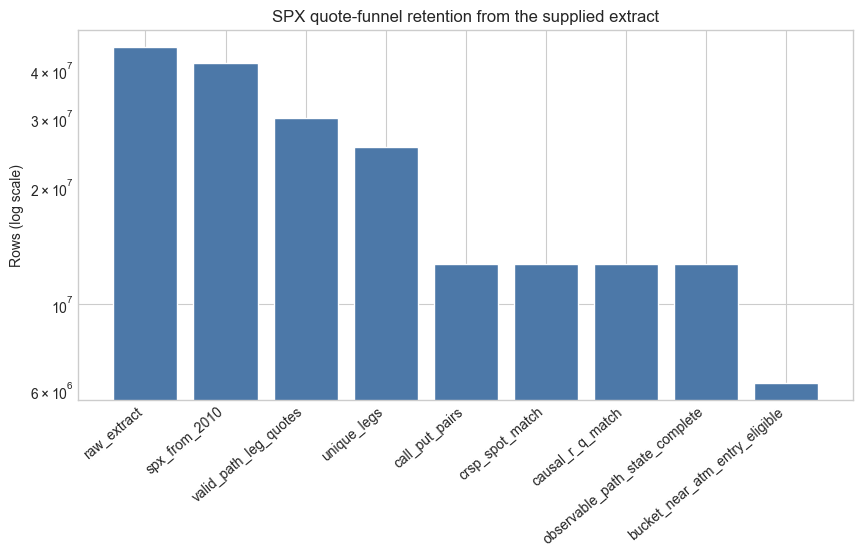

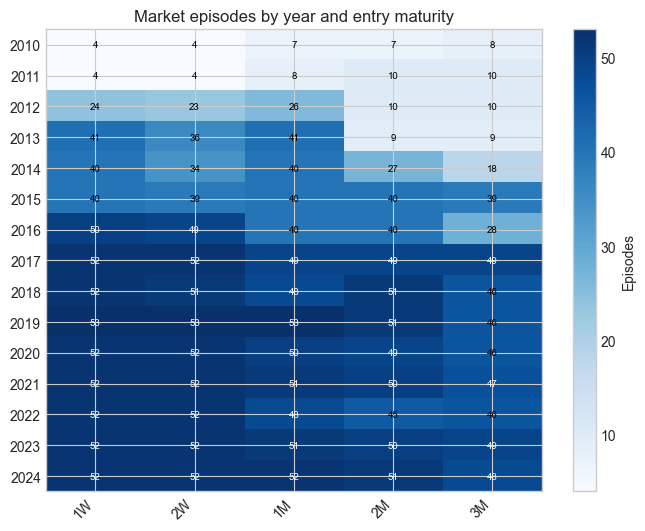

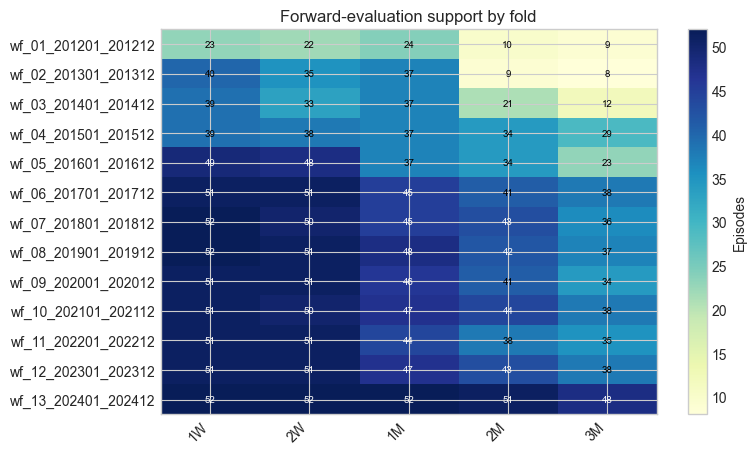

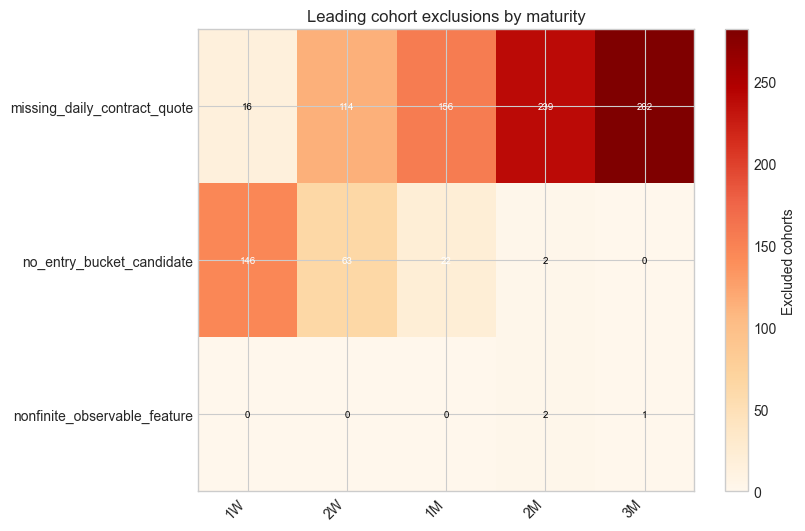

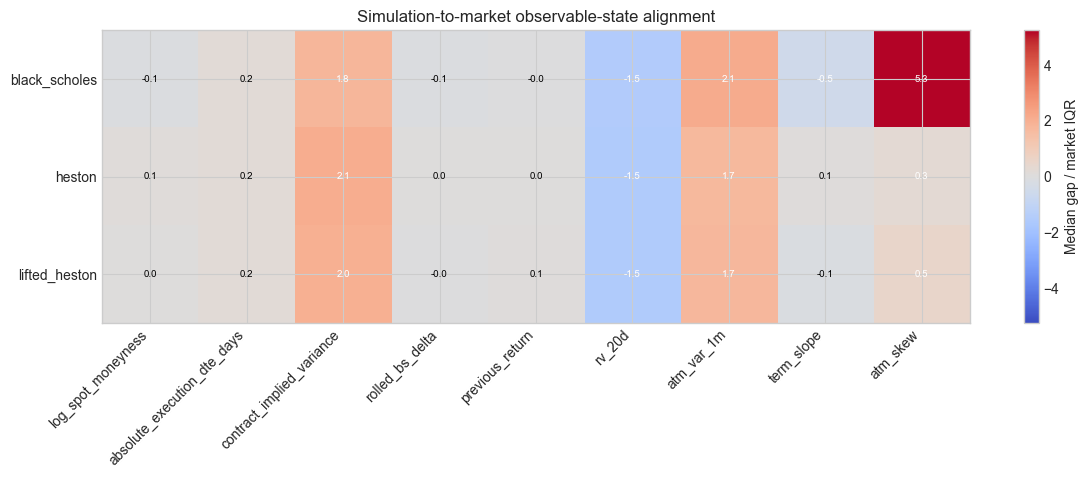

WindowsPath('C:/Users/lhkke/OneDrive - Queen Mary, University of London/Documents/Dissertation/Deep-Hedging-under-Lifted-Heston-MSc-Dissertation-/outputs_final_factorial/full/figures/source_to_market_alignment_heatmap.png')

In [24]:
# Quote funnel waterfall.
funnel_plot=QUOTE_FUNNEL.copy()
fig,ax=plt.subplots(figsize=(10,4.8))
ax.bar(
    np.arange(len(funnel_plot)),funnel_plot.rows,
    color="#4C78A8",edgecolor="white"
)
ax.set_yscale("log")
ax.set_xticks(np.arange(len(funnel_plot)))
ax.set_xticklabels(funnel_plot.stage,rotation=40,ha="right")
ax.set_ylabel("Rows (log scale)")
ax.set_title("SPX quote-funnel retention from the supplied extract")
save_figure(fig,"quote_funnel_waterfall.png","Rows retained at each quote-funnel stage.")

# Market episode coverage by year and entry bucket.
coverage_heatmap=(
    COVERAGE_BY_YEAR_BUCKET.pivot(
        index="entry_year",columns="entry_maturity_bucket",values="episodes"
    ).reindex(columns=BUCKET_NAMES).fillna(0)
)
fig,ax=plt.subplots(figsize=(8,6))
image,label=draw_heatmap(
    ax,coverage_heatmap,"Market episodes by year and entry maturity",
    "Episodes",fmt=".0f",cmap="Blues"
)
fig.colorbar(image,ax=ax,label=label)
save_figure(fig,"market_episode_coverage_heatmap.png","Episode coverage by year and maturity bucket.")

# Evaluation support by fold and bucket.
fig,ax=plt.subplots(figsize=(8,max(5,.25*len(FOLD_EVALUATION_SUPPORT))))
image,label=draw_heatmap(
    ax,FOLD_EVALUATION_SUPPORT,"Forward-evaluation support by fold",
    "Episodes",fmt=".0f",cmap="YlGnBu"
)
fig.colorbar(image,ax=ax,label=label)
save_figure(fig,"fold_evaluation_support_heatmap.png","Chronological evaluation support for every fold and bucket.")

if len(EXCLUSION_SUMMARY):
    top_reasons=(
        EXCLUSION_SUMMARY.groupby("reason").excluded_cohorts.sum()
        .nlargest(10).index
    )
    exclusion_heatmap=(
        EXCLUSION_SUMMARY.loc[EXCLUSION_SUMMARY.reason.isin(top_reasons)]
        .pivot(index="reason",columns="bucket",values="excluded_cohorts")
        .reindex(columns=BUCKET_NAMES).fillna(0)
    )
    fig,ax=plt.subplots(figsize=(8,6))
    image,label=draw_heatmap(
        ax,exclusion_heatmap,"Leading cohort exclusions by maturity",
        "Excluded cohorts",fmt=".0f",cmap="OrRd"
    )
    fig.colorbar(image,ax=ax,label=label)
    save_figure(fig,"cohort_exclusion_heatmap.png","Top cohort-exclusion reasons by entry maturity.")

alignment_heatmap=(
    SOURCE_ALIGNMENT.pivot(
        index="simulation_source",columns="feature",
        values="standardised_median_gap"
    ).reindex(index=SIMULATION_SOURCES,columns=alignment_features)
)
fig,ax=plt.subplots(figsize=(14,3.8))
image,label=draw_heatmap(
    ax,alignment_heatmap,"Simulation-to-market observable-state alignment",
    "Median gap / market IQR",fmt=".1f",cmap="coolwarm",center=0
)
fig.colorbar(image,ax=ax,label=label)
save_figure(fig,"source_to_market_alignment_heatmap.png","Pre-evaluation observable-state median gaps scaled by market IQR.")


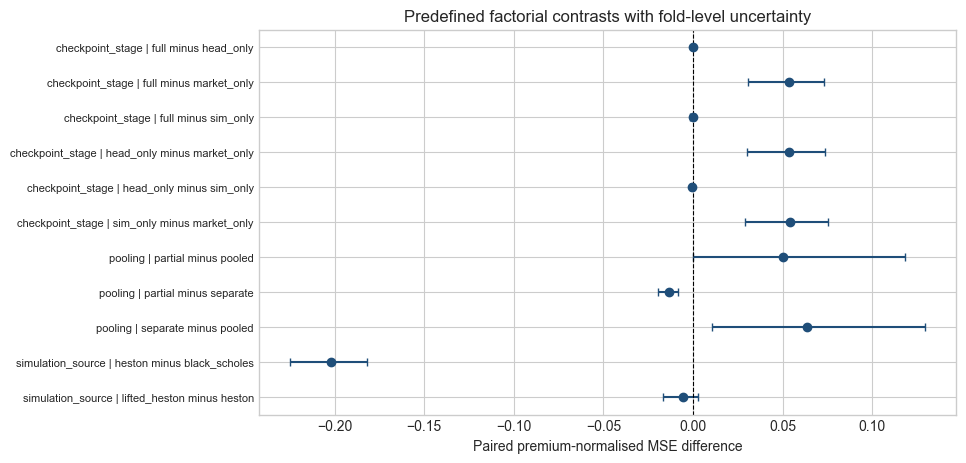

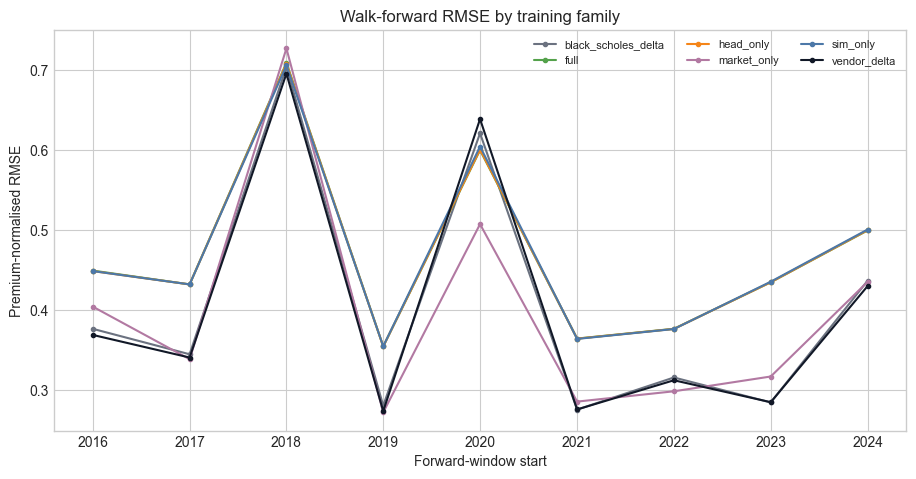

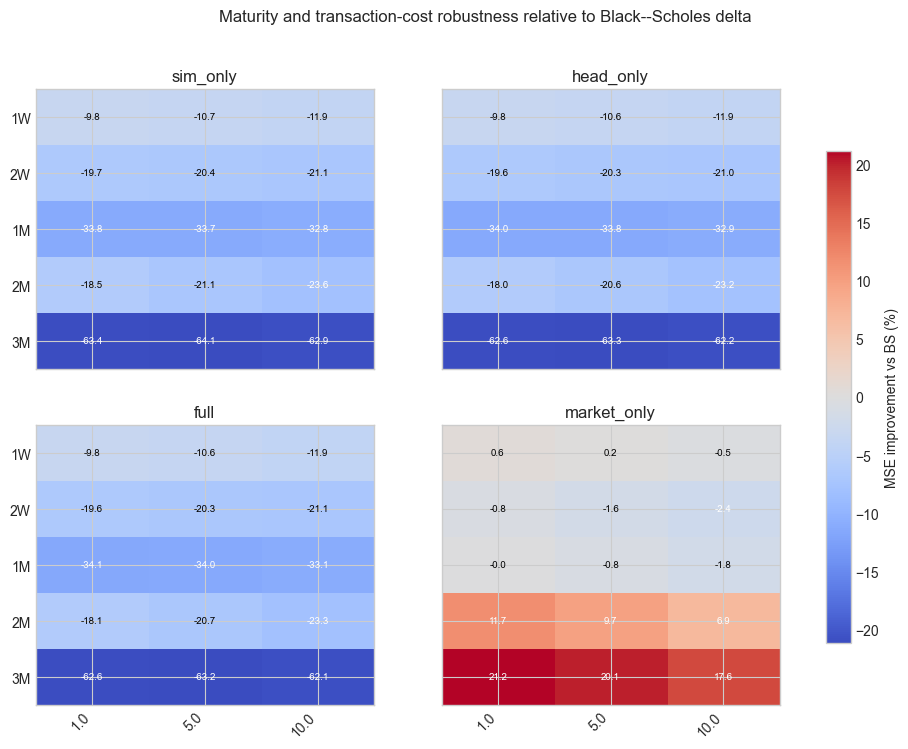

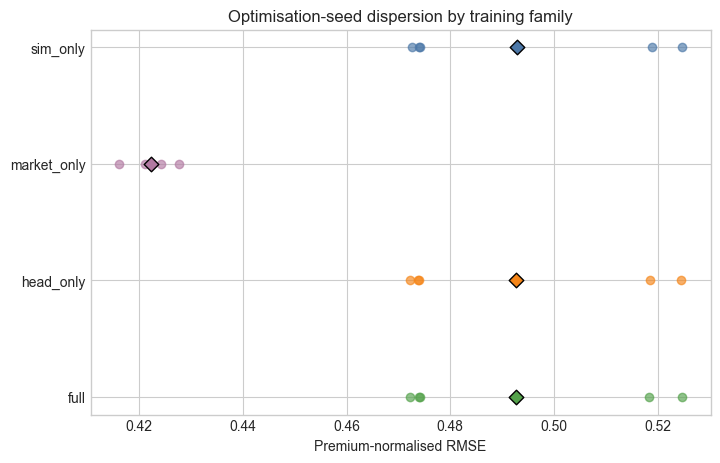

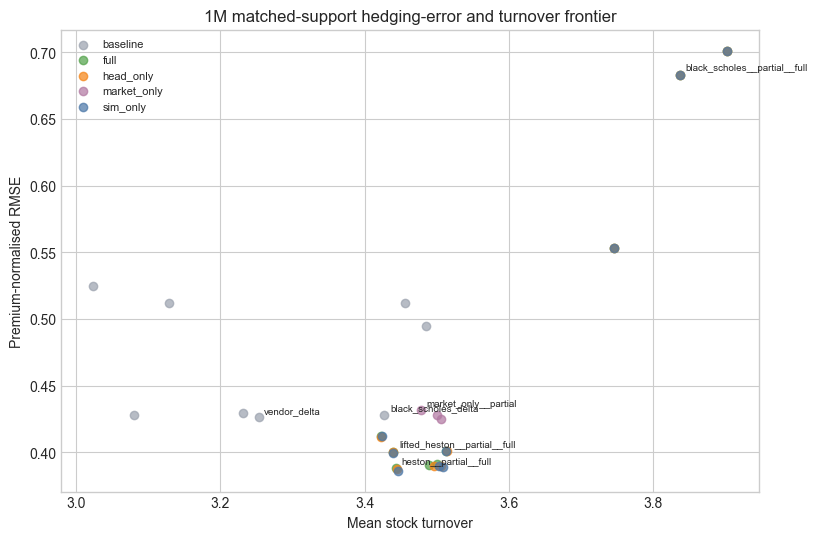

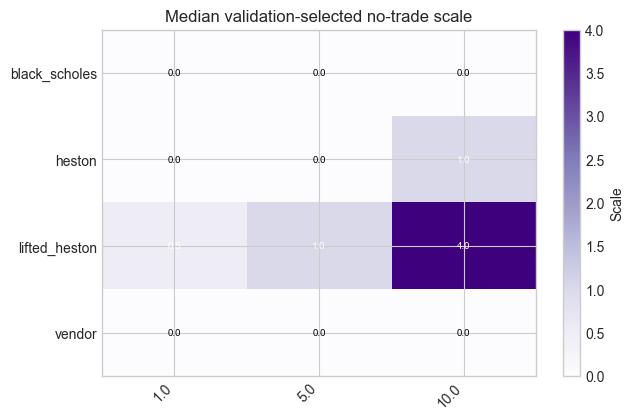

WindowsPath('C:/Users/lhkke/OneDrive - Queen Mary, University of London/Documents/Dissertation/Deep-Hedging-under-Lifted-Heston-MSc-Dissertation-/outputs_final_factorial/full/figures/no_trade_scale_selection.png')

In [25]:
# Predefined contrast forest plot.
forest=CONTRASTS.copy().sort_values(["dimension","contrast"])
fig,ax=plt.subplots(figsize=(9,max(5,.38*len(forest))))
y=np.arange(len(forest))
points=forest.mse_difference.to_numpy(float)
lower=forest.ci_2_5pct.to_numpy(float)
upper=forest.ci_97_5pct.to_numpy(float)
finite=np.isfinite(lower)&np.isfinite(upper)
ax.scatter(points,y,color="#1F4E79",zorder=3)
if finite.any():
    ax.errorbar(
        points[finite],y[finite],
        xerr=np.vstack([
            np.maximum(points[finite]-lower[finite],0),
            np.maximum(upper[finite]-points[finite],0),
        ]),
        fmt="none",ecolor="#1F4E79",capsize=3,
    )
ax.axvline(0,color="black",linewidth=.8,linestyle="--")
ax.set_yticks(y)
ax.set_yticklabels(forest.dimension+" | "+forest.contrast,fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Paired premium-normalised MSE difference")
ax.set_title("Predefined factorial contrasts with fold-level uncertainty")
save_figure(fig,"factorial_contrast_forest_plot.png","Paired predefined contrasts; negative values favour the first named level.")

# Walk-forward family performance.
fig,ax=plt.subplots(figsize=(11,5.2))
for family,group in WALK_FORWARD_FAMILY.groupby("policy_family"):
    ordered=group.sort_values("evaluation_start")
    ax.plot(
        ordered.evaluation_start,ordered.premium_normalised_rmse,
        marker="o",markersize=3,label=family,
        color=POLICY_COLORS.get(family),
    )
ax.set_xlabel("Forward-window start")
ax.set_ylabel("Premium-normalised RMSE")
ax.set_title("Walk-forward RMSE by training family")
ax.legend(ncol=3,frameon=False,fontsize=8)
save_figure(fig,"walk_forward_family_rmse.png","Fold-level RMSE for adaptation families and principal delta baselines.")

# Maturity-cost robustness relative to Black-Scholes delta.
stages=["sim_only","head_only","full","market_only"]
fig,axes=plt.subplots(2,2,figsize=(12,8),sharex=True,sharey=True)
for axis,stage in zip(axes.flat,stages):
    table=(
        MATURITY_COST_ROBUSTNESS.loc[
            MATURITY_COST_ROBUSTNESS.checkpoint_stage.eq(stage)
        ].pivot(
            index="entry_maturity_bucket",columns="underlying_cost_bps",
            values="mse_improvement_vs_bs_pct"
        ).reindex(index=BUCKET_NAMES,columns=COST_LEVELS_BPS)
    )
    image,label=draw_heatmap(
        axis,table,stage,"MSE improvement vs BS (%)",
        fmt=".1f",cmap="coolwarm",center=0
    )
fig.colorbar(image,ax=axes.ravel().tolist(),label=label,shrink=.8)
fig.suptitle("Maturity and transaction-cost robustness relative to Black--Scholes delta")
save_figure(fig,"maturity_cost_robustness_heatmap.png","Main-effect MSE improvement by checkpoint family, maturity and stock cost.")

# Seed stability by adaptation family.
seed_plot=SEED_FAMILY_RESULTS.loc[
    SEED_FAMILY_RESULTS.underlying_cost_bps.eq(CONFIG.primary_cost_bps)
]
fig,ax=plt.subplots(figsize=(8,5))
for position,(family,group) in enumerate(seed_plot.groupby("checkpoint_stage")):
    ax.scatter(
        group.premium_normalised_rmse,
        np.full(len(group),position),alpha=.65,
        color=POLICY_COLORS.get(family),
    )
    ax.scatter(
        [group.premium_normalised_rmse.mean()],[position],
        marker="D",s=55,color=POLICY_COLORS.get(family),edgecolor="black",
    )
ax.set_yticks(range(seed_plot.checkpoint_stage.nunique()))
ax.set_yticklabels([name for name,_ in seed_plot.groupby("checkpoint_stage")])
ax.set_xlabel("Premium-normalised RMSE")
ax.set_title("Optimisation-seed dispersion by training family")
save_figure(fig,"seed_stability_dot_plot.png","Each point is one optimisation seed after averaging folds, maturities and cells within a family.")

# Risk-turnover frontier.
frontier=HEADLINE_1M_COMPARABLE.loc[
    HEADLINE.underlying_cost_bps.eq(CONFIG.primary_cost_bps)
].copy()
fig,ax=plt.subplots(figsize=(9,6))
for stage,group in frontier.groupby("checkpoint_stage"):
    ax.scatter(
        group.turnover,group.premium_normalised_rmse,
        label=stage,alpha=.72,color=POLICY_COLORS.get(stage,"#9CA3AF")
    )
for row in frontier.loc[
    frontier.model_cell.isin(REPORTING_POLICY_CELLS)
].itertuples():
    ax.annotate(
        row.model_cell,(row.turnover,row.premium_normalised_rmse),
        xytext=(4,3),textcoords="offset points",fontsize=7,
    )
ax.set_xlabel("Mean stock turnover")
ax.set_ylabel("Premium-normalised RMSE")
ax.set_title("1M matched-support hedging-error and turnover frontier")
ax.legend(frameon=False,fontsize=8)
save_figure(fig,"risk_turnover_frontier.png","All policies on matched 1M fold-maturity observations at the primary stock-cost level; lower-left is preferable.")

# Selected structural no-trade scales.
no_trade_plot=(
    NO_TRADE_SELECTED.groupby(["baseline","cost_bps"],as_index=False)
    .selected_scale.median()
    .pivot(index="baseline",columns="cost_bps",values="selected_scale")
)
fig,ax=plt.subplots(figsize=(7,4.5))
image,label=draw_heatmap(
    ax,no_trade_plot,"Median validation-selected no-trade scale",
    "Scale",fmt=".1f",cmap="Purples"
)
fig.colorbar(image,ax=ax,label=label)
save_figure(fig,"no_trade_scale_selection.png","Median structural no-trade scale by baseline and stock cost.")


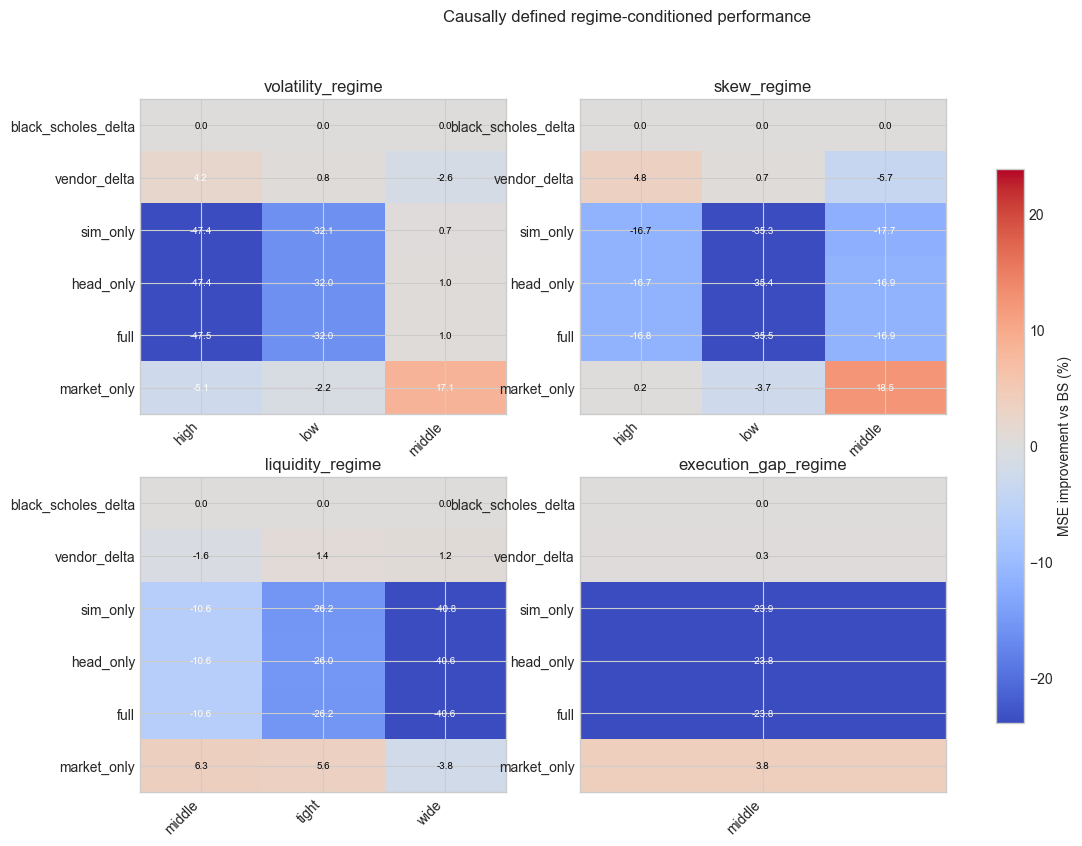

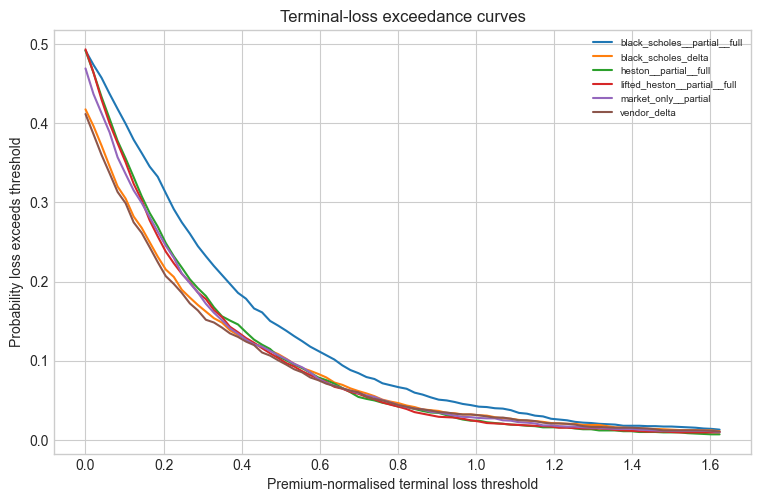

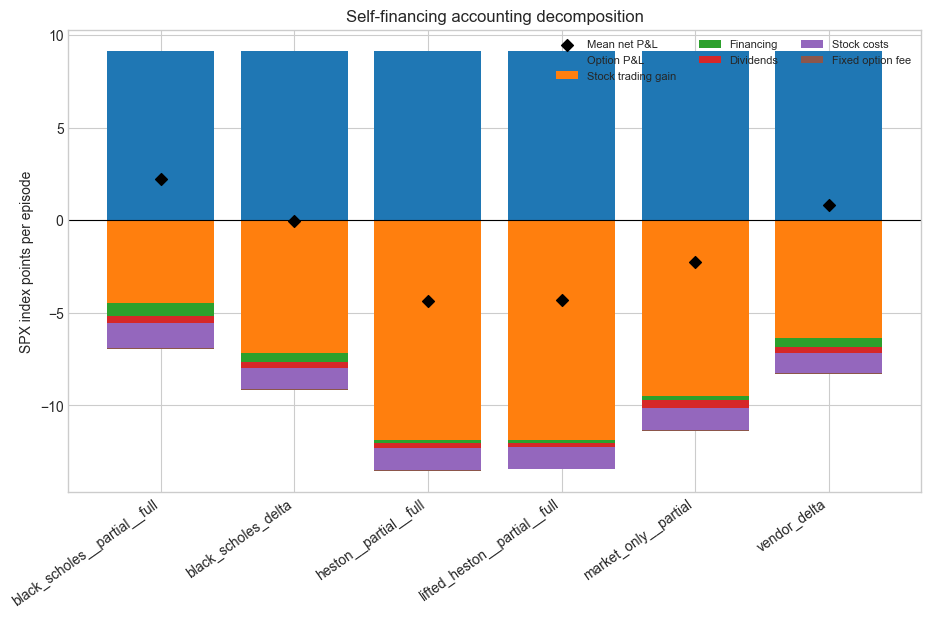

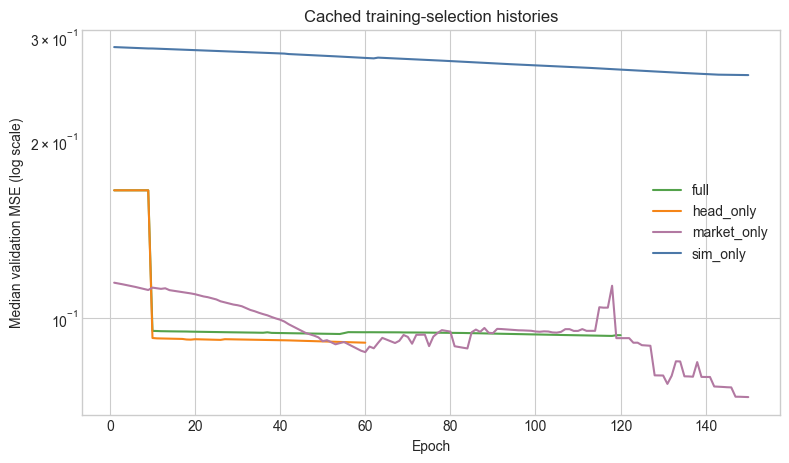

,figure,path,description
0,quote_funnel_waterfall.png,"C:\Users\lhkke\OneDrive - Queen Mary, Universi...",Rows retained at each quote-funnel stage.
1,market_episode_coverage_heatmap.png,"C:\Users\lhkke\OneDrive - Queen Mary, Universi...",Episode coverage by year and maturity bucket.
2,fold_evaluation_support_heatmap.png,"C:\Users\lhkke\OneDrive - Queen Mary, Universi...",Chronological evaluation support for every fol...
3,cohort_exclusion_heatmap.png,"C:\Users\lhkke\OneDrive - Queen Mary, Universi...",Top cohort-exclusion reasons by entry maturity.
4,source_to_market_alignment_heatmap.png,"C:\Users\lhkke\OneDrive - Queen Mary, Universi...",Pre-evaluation observable-state median gaps sc...
5,factorial_contrast_forest_plot.png,"C:\Users\lhkke\OneDrive - Queen Mary, Universi...",Paired predefined contrasts; negative values f...
6,walk_forward_family_rmse.png,"C:\Users\lhkke\OneDrive - Queen Mary, Universi...",Fold-level RMSE for adaptation families and pr...
7,maturity_cost_robustness_heatmap.png,"C:\Users\lhkke\OneDrive - Queen Mary, Universi...",Main-effect MSE improvement by checkpoint fami...
8,seed_stability_dot_plot.png,"C:\Users\lhkke\OneDrive - Queen Mary, Universi...",Each point is one optimisation seed after aver...
9,risk_turnover_frontier.png,"C:\Users\lhkke\OneDrive - Queen Mary, Universi...",All policies on matched 1M fold-maturity obser...


In [26]:
# Causal regime performance relative to Black-Scholes delta.
regime_dimensions=list(regime_definitions)
fig,axes=plt.subplots(2,2,figsize=(13,9))
for axis,dimension in zip(axes.flat,regime_dimensions):
    rows=REGIME_RELATIVE_TO_BS.loc[
        REGIME_RELATIVE_TO_BS.regime_dimension.eq(dimension)
    ]
    table=rows.pivot(
        index="policy_family",columns="regime",
        values="mse_improvement_vs_bs_pct"
    )
    ordered_rows=[
        item for item in [
            "black_scholes_delta","vendor_delta","sim_only",
            "head_only","full","market_only"
        ] if item in table.index
    ]
    table=table.reindex(ordered_rows)
    image,label=draw_heatmap(
        axis,table,dimension,"MSE improvement vs BS (%)",
        fmt=".1f",cmap="coolwarm",center=0
    )
fig.colorbar(image,ax=axes.ravel().tolist(),label=label,shrink=.8)
fig.suptitle("Causally defined regime-conditioned performance")
save_figure(fig,"regime_conditioned_performance.png","Regime thresholds are estimated only from each fold's preceding training window.")

# Terminal loss exceedance.
fig,ax=plt.subplots(figsize=(9,5.5))
for model_cell,group in LOSS_EXCEEDANCE.groupby("model_cell"):
    ax.plot(
        group.loss_threshold,group.exceedance_probability,
        label=model_cell,
    )
ax.set_xlabel("Premium-normalised terminal loss threshold")
ax.set_ylabel("Probability loss exceeds threshold")
ax.set_title("Terminal-loss exceedance curves")
ax.legend(frameon=False,fontsize=7)
save_figure(fig,"terminal_loss_exceedance_curves.png","Seed-averaged episode loss exceedance for prespecified representative policies.")

# Self-financing accounting decomposition.
components=[
    ("option_pnl_points","Option P&L",1),
    ("stock_gain_points","Stock trading gain",1),
    ("financing_pnl","Financing",1),
    ("dividend_carry","Dividends",1),
    ("underlying_cost_points","Stock costs",-1),
    ("fixed_option_fee_points","Fixed option fee",-1),
]
fig,ax=plt.subplots(figsize=(11,6))
x=np.arange(len(ACCOUNTING_DECOMPOSITION))
positive=np.zeros(len(x))
negative=np.zeros(len(x))
for column,label,sign in components:
    values=sign*ACCOUNTING_DECOMPOSITION[column].to_numpy(float)
    bottom=np.where(values>=0,positive,negative)
    ax.bar(x,values,bottom=bottom,label=label)
    positive+=np.where(values>=0,values,0)
    negative+=np.where(values<0,values,0)
ax.scatter(
    x,ACCOUNTING_DECOMPOSITION.net_pnl_points,
    marker="D",color="black",label="Mean net P&L",zorder=4,
)
ax.axhline(0,color="black",linewidth=.8)
ax.set_xticks(x)
ax.set_xticklabels(
    ACCOUNTING_DECOMPOSITION.model_cell,rotation=35,ha="right"
)
ax.set_ylabel("SPX index points per episode")
ax.set_title("Self-financing accounting decomposition")
ax.legend(ncol=3,frameon=False,fontsize=8)
save_figure(fig,"accounting_decomposition.png","Mean accounting components for prespecified representative policies.")

# Validation curves from cached histories.
if len(TRAINING_HISTORY_SUMMARY):
    validation_history=TRAINING_HISTORY_SUMMARY.loc[
        TRAINING_HISTORY_SUMMARY.fit_scope.isin([
            "simulation_selection","inner_selection"
        ])
    ]
    fig,ax=plt.subplots(figsize=(9,5))
    for stage,group in validation_history.groupby("checkpoint_stage"):
        curve=(
            group.groupby("epoch",as_index=False)
            .agg(median_validation_loss=("median_validation_loss","median"))
        )
        ax.plot(
            curve.epoch,curve.median_validation_loss,
            label=stage,color=POLICY_COLORS.get(stage),
        )
    ax.set_yscale("log")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Median validation MSE (log scale)")
    ax.set_title("Cached training-selection histories")
    ax.legend(frameon=False)
    save_figure(fig,"training_validation_curves.png","Median validation histories recovered from checkpoint payloads.")

display(pd.DataFrame(FIGURE_REGISTRY))


In [27]:
expected_simulation_neural={
    f"{source}__{pooling}__{checkpoint}"
    for source in SIMULATION_SOURCES
    for pooling in POOLING_DESIGNS
    for checkpoint in CHECKPOINTS
}
expected_market_only={
    f"market_only__{pooling}"
    for pooling in POOLING_DESIGNS
}
expected_neural=expected_simulation_neural|expected_market_only
observed_neural=set(
    EPISODE_RESULTS.loc[
        EPISODE_RESULTS.model_type.eq("neural"),"model_cell"
    ]
)
observed_market_only=set(
    EPISODE_RESULTS.loc[
        EPISODE_RESULTS.checkpoint_stage.eq(MARKET_ONLY_CHECKPOINT),
        "model_cell",
    ]
)
expected_baselines={
    f"{name}_{suffix}"
    for name in ("black_scholes","heston","lifted_heston","vendor")
    for suffix in ("delta","structural_no_trade")
}
observed_baselines=set(
    EPISODE_RESULTS.loc[
        EPISODE_RESULTS.model_type.eq("baseline"),"model_cell"
    ]
)
separate_row=PARAMETER_TABLE.set_index("pooling").loc["separate"]
first_fold=min(FOLDS,key=lambda fold:fold.evaluation_start)

eligible_fold_count=int(

    FOLD_EXECUTION_STATUS.fold_status.eq("ELIGIBLE_ALL_BUCKETS").sum()

)

skipped_fold_count=int(

    FOLD_EXECUTION_STATUS.fold_status.ne("ELIGIBLE_ALL_BUCKETS").sum()

)

expected_checkpoint_tasks=(

    len(SIMULATION_SOURCES)*len(POOLING_DESIGNS)*len(CONFIG.seeds)

    +eligible_fold_count*(

        len(SIMULATION_SOURCES)*len(POOLING_DESIGNS)*len(CONFIG.seeds)
        +len(POOLING_DESIGNS)*len(CONFIG.seeds)
    )
)
checkpoint_stage_contract=all(
    (row.phase=="fixed_pretraining" and row.saved_stages=="sim_only")
    or (row.phase=="market_adaptation" and set(str(row.saved_stages).split("|"))==set(CHECKPOINTS))
    or (row.phase=="market_only" and row.saved_stages==MARKET_ONLY_CHECKPOINT)
    for row in CHECKPOINT_MANIFEST.itertuples()
)
checkpoint_persistence=(
    CONFIG.profile=="audit"
    or CHECKPOINT_CACHE_AUDIT.checkpoint_file_exists_now.all()
)
expected_state_rows=(
    len(SIMULATION_SOURCES)*len(POOLING_DESIGNS)*len(CONFIG.seeds)
    +eligible_fold_count*(

        len(SIMULATION_SOURCES)*len(POOLING_DESIGNS)*len(CONFIG.seeds)*3

        +len(POOLING_DESIGNS)*len(CONFIG.seeds)
    )
)
expected_comparison_rows=(
    eligible_fold_count*len(SIMULATION_SOURCES)*len(POOLING_DESIGNS)
    *len(CONFIG.seeds)*3
)
trainable_state_rows=CHECKPOINT_STATE_AUDIT.loc[
    ~(
        CHECKPOINT_STATE_AUDIT.phase.eq("market_adaptation")
        & CHECKPOINT_STATE_AUDIT.checkpoint_stage.eq("sim_only")
    )
]
state_identity_complete=(
    len(CHECKPOINT_STATE_AUDIT)==expected_state_rows
    and CHECKPOINT_STATE_AUDIT[[
        "task_signature","checkpoint_stage","state_sha256",
        "parameter_sha256",
    ]].notna().all().all()
)
trainable_states_unique=(
    trainable_state_rows.state_sha256.nunique()==len(trainable_state_rows)
)
task_cache_identity_unique=(
    CHECKPOINT_MANIFEST.signature.nunique()==len(CHECKPOINT_MANIFEST)
    and CHECKPOINT_MANIFEST.checkpoint_path.nunique()==len(CHECKPOINT_MANIFEST)
)
persisted_file_hashes_unique=(
    CONFIG.profile=="audit"
    or CHECKPOINT_MANIFEST.checkpoint_sha256.nunique()==len(CHECKPOINT_MANIFEST)
)
checkpoint_movement_complete=(
    len(CHECKPOINT_COMPARISON_AUDIT)==expected_comparison_rows
    and (CHECKPOINT_COMPARISON_AUDIT.parameter_l2_distance>0).all()
    and (CHECKPOINT_COMPARISON_AUDIT.maximum_abs_prediction_difference>0).all()
)
optimisation_audit_pass=(
    len(TRAINING_HISTORY)>0
    and (TRAINING_HISTORY.optimizer_steps>=1).all()
    and np.isfinite(TRAINING_HISTORY.gradient_norm_pre_clip_mean).all()
    and (TRAINING_HISTORY.gradient_norm_pre_clip_max>0).all()
)
policy_diagnostic_pass=(
    len(POLICY_DIAGNOSTICS)>0
    and np.isfinite(POLICY_DIAGNOSTICS.select_dtypes(include=[np.number])).all().all()
    and POLICY_DIAGNOSTICS.tanh_saturated_fraction.between(0,1).all()
    and POLICY_DIAGNOSTICS.hedge_at_clip_fraction.between(0,1).all()
    and POLICY_DIAGNOSTICS.tanh_saturated_fraction.max()<0.999
    and POLICY_DIAGNOSTICS.hedge_at_clip_fraction.max()<0.999
)
executed_fold_contract=(
    FOLD_EXECUTION_STATUS.loc[
        FOLD_EXECUTION_STATUS.fold_status.eq("ELIGIBLE_ALL_BUCKETS")
    ].eligible_bucket_count.eq(len(BUCKET_NAMES)).all()
    and FOLD_EXECUTION_STATUS.loc[
        FOLD_EXECUTION_STATUS.fold_status.ne("ELIGIBLE_ALL_BUCKETS")
    ].eligible_bucket_count.eq(0).all()
)
separate_result_buckets=set(
    EPISODE_RESULTS.loc[
        EPISODE_RESULTS.pooling.eq("separate"),
        "entry_maturity_bucket",
    ].astype(str)
)
separate_scope_pass=(
    separate_result_buckets==set(SEPARATE_POLICY_BUCKETS)
)


strict_accounting_pass=(
    int(STRICT_ACCOUNTING_AUDIT.authoritative_dtype_rows.iloc[0])==
    int(STRICT_ACCOUNTING_AUDIT.result_rows.iloc[0])
    and STRICT_ACCOUNTING_AUDIT.maximum_identity_ratio.iloc[0]<=1.0
    and STRICT_ACCOUNTING_AUDIT.maximum_squared_error_reconciliation.iloc[0]<=1e-12
    and STRICT_ACCOUNTING_AUDIT.maximum_absolute_error_reconciliation.iloc[0]<=1e-12
    and STRICT_ACCOUNTING_AUDIT.maximum_total_cost_reconciliation.iloc[0]<=1e-12
)


RESULT_AUDIT=pd.DataFrame([
    {
        "gate":"all fitted tasks represented in checkpoint manifest",
        "expected":expected_checkpoint_tasks,
        "observed":len(CHECKPOINT_MANIFEST),
        "status":"PASS" if len(CHECKPOINT_MANIFEST)==expected_checkpoint_tasks else "FAIL",
    },
    {
        "gate":"every production checkpoint persisted",
        "expected":1,"observed":int(checkpoint_persistence),
        "status":"PASS" if checkpoint_persistence else "FAIL",
    },
    {
        "gate":"checkpoint payloads contain every fitted stage",
        "expected":1,"observed":int(checkpoint_stage_contract),
        "status":"PASS" if checkpoint_stage_contract else "FAIL",
    },
    {
        "gate":"unique cache identity per seed/fold/task",
        "expected":1,"observed":int(task_cache_identity_unique),
        "status":"PASS" if task_cache_identity_unique else "FAIL",
    },
    {
        "gate":"unique persisted cache file hash per task",
        "expected":1,"observed":int(persisted_file_hashes_unique),
        "status":"PASS" if persisted_file_hashes_unique else "FAIL",
    },
    {
        "gate":"state hash recorded for every checkpoint stage",
        "expected":expected_state_rows,"observed":len(CHECKPOINT_STATE_AUDIT),
        "status":"PASS" if state_identity_complete else "FAIL",
    },
    {
        "gate":"all trainable checkpoint states are distinct",
        "expected":len(trainable_state_rows),
        "observed":trainable_state_rows.state_sha256.nunique(),
        "status":"PASS" if trainable_states_unique else "FAIL",
    },
    {
        "gate":"adaptation changes parameters and predictions",
        "expected":expected_comparison_rows,
        "observed":len(CHECKPOINT_COMPARISON_AUDIT),
        "status":"PASS" if checkpoint_movement_complete else "FAIL",
    },
    {
        "gate":"optimizer steps and gradient norms recorded",
        "expected":1,"observed":int(optimisation_audit_pass),
        "status":"PASS" if optimisation_audit_pass else "FAIL",
    },
    {
        "gate":"residual saturation and clipping diagnostics valid",
        "expected":1,"observed":int(policy_diagnostic_pass),
        "status":"PASS" if policy_diagnostic_pass else "FAIL",
    },
    {
        "gate":"zero-initialised residual heads reproduce anchor",
        "expected":1,
        "observed":int(ZERO_INITIALISATION_AUDIT.status.eq("PASS").all()),
        "status":(
            "PASS" if ZERO_INITIALISATION_AUDIT.status.eq("PASS").all()
            else "FAIL"
        ),
    },
    {
        "gate":"strict float64 accounting reconciliation",
        "expected":1,"observed":int(strict_accounting_pass),
        "status":"PASS" if strict_accounting_pass else "FAIL",
    },
    {
        "gate":"task-level parallel scheduling is exactly equivalent",
        "expected":1,
        "observed":int(
            TASK_RUNTIME_EQUIVALENCE_AUDIT.status.str.startswith("PASS").all()
        ),
        "status":(
            "PASS"
            if TASK_RUNTIME_EQUIVALENCE_AUDIT.status.str.startswith("PASS").all()
            else "FAIL"
        ),
    },
    {
        "gate":"reported results match the active run context",
        "expected":1,
        "observed":int(RESULT_CONTEXT_AUDIT.status.eq("PASS").all()),
        "status":(
            "PASS" if RESULT_CONTEXT_AUDIT.status.eq("PASS").all()
            else "FAIL"
        ),
    },
    {
        "gate":"diagnostic inventory populated",
        "expected":">=20","observed":len(LEGACY_DIAGNOSTIC_INVENTORY),
        "status":"PASS" if len(LEGACY_DIAGNOSTIC_INVENTORY)>=20 else "FAIL",
    },
    {

        "gate":"unsupported folds explicitly recorded and excluded",

        "expected":len(FOLDS),"observed":len(FOLD_EXECUTION_STATUS),

        "status":(

            "PASS" if len(FOLD_EXECUTION_STATUS)==len(FOLDS)

            and FOLD_EXECUTION_STATUS.fold_status.isin([

                "SKIPPED_NO_BUCKET_SUPPORT",
                "SKIPPED_PARTIAL_BUCKET_SUPPORT",
                "ELIGIBLE_ALL_BUCKETS",

            ]).all() else "FAIL"

        ),

    },

    {
        "gate":"executed folds have complete five-bucket support",
        "expected":1,"observed":int(executed_fold_contract),
        "status":"PASS" if executed_fold_contract else "FAIL",
    },
    {
        "gate":"maturity-specific results are restricted to 1M",
        "expected":"|".join(SEPARATE_POLICY_BUCKETS),
        "observed":"|".join(sorted(separate_result_buckets)),
        "status":"PASS" if separate_scope_pass else "FAIL",
    },
    {

        "gate":"30 unique neural cells","expected":30,

        "observed":len(observed_neural),
        "status":"PASS" if observed_neural==expected_neural else "FAIL",
    },
    {
        "gate":"three unique market-only cells","expected":3,
        "observed":len(observed_market_only),
        "status":(
            "PASS" if observed_market_only==expected_market_only else "FAIL"
        ),
    },
    {
        "gate":"one independent 1M maturity-specific estimator","expected":1,
        "observed":int(separate_row.independent_estimators),
        "status":(
            "PASS" if int(separate_row.independent_estimators)==1 else "FAIL"
        ),
    },
    {
        "gate":"one independent 1M maturity-specific scaler","expected":1,
        "observed":int(separate_row.independent_scalers),
        "status":(
            "PASS" if int(separate_row.independent_scalers)==1 else "FAIL"
        ),
    },
    {
        "gate":"quote funnel reaches January 2010",
        "expected":"on or before 2010-01-31",
        "observed":str(pd.Timestamp(PAIRED_QUOTES.date.min()).date()),
        "status":(
            "PASS" if PAIRED_QUOTES.date.min()<=pd.Timestamp("2010-01-31")
            else "FAIL"
        ),
    },
    {
        "gate":"first production training window starts in 2010",
        "expected":"2010",
        "observed":str(first_fold.train_start.date()),
        "status":(
            "PASS" if CONFIG.profile in {"audit","smoke"} or first_fold.train_start.year==2010
            else "FAIL"
        ),
    },
    {
        "gate":"8 baseline cells","expected":8,
        "observed":len(observed_baselines),
        "status":(
            "PASS" if observed_baselines==expected_baselines else "FAIL"
        ),
    },
    {
        "gate":"five maturity buckets","expected":5,
        "observed":EPISODE_RESULTS.entry_maturity_bucket.nunique(),
        "status":(
            "PASS" if EPISODE_RESULTS.entry_maturity_bucket.nunique()==5
            else "FAIL"
        ),
    },
    {
        "gate":"three cost levels","expected":3,
        "observed":EPISODE_RESULTS.underlying_cost_bps.nunique(),
        "status":(
            "PASS" if set(EPISODE_RESULTS.underlying_cost_bps)==set(COST_LEVELS_BPS)
            else "FAIL"
        ),
    },
    {
        "gate":"accounting identity","expected":0,
        "observed":float(
            EPISODE_RESULTS.accounting_identity_error.abs().max()
        ),
        "status":(
            "PASS" if EPISODE_RESULTS.accounting_identity_error.abs().max()<1e-8
            else "FAIL"
        ),
    },
    {
        "gate":"no future r/q","expected":0,
        "observed":int(
            (PAIRED_QUOTES[["r_age_days","q_age_days"]]<0).sum().sum()
        ),
        "status":(
            "PASS"
            if not (PAIRED_QUOTES[["r_age_days","q_age_days"]]<0).any().any()
            else "FAIL"
        ),
    },
    {
        "gate":"no future analytic calibration","expected":0,
        "observed":int(
            min(HESTON_ANALYTIC.ages+LIFTED_SURFACE_RESET.ages)
            if (HESTON_ANALYTIC.ages or LIFTED_SURFACE_RESET.ages) else 0
        ),
        "status":(
            "PASS"
            if all(
                age>=0
                for age in HESTON_ANALYTIC.ages+LIFTED_SURFACE_RESET.ages
            ) else "FAIL"
        ),
    },
    {
        "gate":"lifted delta finite-difference","expected":0.005,
        "observed":float(
            LIFTED_NUMERICAL_AUDIT.absolute_formula_error.max()
        ),
        "status":(
            "PASS"
            if LIFTED_NUMERICAL_AUDIT.absolute_formula_error.max()<=0.005
            else "FAIL"
        ),
    },
    {
        "gate":"option spread cost reported","expected":1,
        "observed":int("option_spread_cost_points" in EPISODE_RESULTS),
        "status":(
            "PASS" if "option_spread_cost_points" in EPISODE_RESULTS
            else "FAIL"
        ),
    },
])
# Numerical validity failures remain fatal. Learning-behaviour diagnostics are
# equally visible, but they do not suppress reporting of already locked results.
NON_BLOCKING_LEARNING_DIAGNOSTIC_GATES = {
    "all trainable checkpoint states are distinct",
    "adaptation changes parameters and predictions",
    "optimizer steps and gradient norms recorded",
    "residual saturation and clipping diagnostics valid",
}
RESULT_AUDIT["gate_class"] = np.where(
    RESULT_AUDIT.gate.isin(NON_BLOCKING_LEARNING_DIAGNOSTIC_GATES),
    "LEARNING_DIAGNOSTIC",
    "VALIDITY_CRITICAL",
)
RESULT_AUDIT["blocks_reporting"] = (
    RESULT_AUDIT.status.ne("PASS")
    & RESULT_AUDIT.gate_class.eq("VALIDITY_CRITICAL")
)
display(RESULT_AUDIT)

blocking_failures = RESULT_AUDIT.loc[RESULT_AUDIT.blocks_reporting]
if len(blocking_failures):
    raise AssertionError(
        "A validity-critical final result audit failed:\n"
        + blocking_failures[["gate", "observed"]].to_string(index=False)
    )

learning_diagnostic_failures = RESULT_AUDIT.loc[
    RESULT_AUDIT.status.ne("PASS")
    & RESULT_AUDIT.gate_class.eq("LEARNING_DIAGNOSTIC")
]
if len(learning_diagnostic_failures):
    warnings.warn(
        "Locked learning diagnostics failed and remain reportable limitations; "
        "chronology, accounting and result-integrity gates passed.\n"
        + learning_diagnostic_failures[["gate", "observed"]].to_string(
            index=False
        ),
        RuntimeWarning,
    )


,gate,expected,observed,status,gate_class,blocks_reporting
0,all fitted tasks represented in checkpoint man...,585,585,PASS,VALIDITY_CRITICAL,False
1,every production checkpoint persisted,1,1,PASS,VALIDITY_CRITICAL,False
2,checkpoint payloads contain every fitted stage,1,1,PASS,VALIDITY_CRITICAL,False
3,unique cache identity per seed/fold/task,1,1,PASS,VALIDITY_CRITICAL,False
4,unique persisted cache file hash per task,1,1,PASS,VALIDITY_CRITICAL,False
5,state hash recorded for every checkpoint stage,1395,1395,PASS,VALIDITY_CRITICAL,False
6,all trainable checkpoint states are distinct,990,756,FAIL,LEARNING_DIAGNOSTIC,False
7,adaptation changes parameters and predictions,1215,1215,FAIL,LEARNING_DIAGNOSTIC,False
8,optimizer steps and gradient norms recorded,1,0,FAIL,LEARNING_DIAGNOSTIC,False
9,residual saturation and clipping diagnostics v...,1,0,FAIL,LEARNING_DIAGNOSTIC,False


C:\Users\lhkke\AppData\Local\Temp\ipykernel_23832\1534949245.py:435: RuntimeWarning: Locked learning diagnostics failed and remain reportable limitations; chronology, accounting and result-integrity gates passed.
                                              gate observed
      all trainable checkpoint states are distinct      756
     adaptation changes parameters and predictions     1215
       optimizer steps and gradient norms recorded        0
residual saturation and clipping diagnostics valid        0
  warnings.warn(


### 13. Dollar-scale and influence diagnostics

These analyses are **post-specified reporting diagnostics**. They reuse locked
episode results and never refit, retune or reselect a policy.

- One standard SPX contract converts index points to dollars using the frozen
  contract multiplier. Dollar differences are paired on the same liability,
  fold, cost level and episode.
- The account illustration uses one non-overlapping 1M straddle at a time and
  books terminal P&L only when the episode exits. It is therefore a realised
  collateral illustration, not a daily marked-to-market brokerage account.
- Starting collateral is an explicit scenario, not an estimate of Cboe or
  broker margin. The option premium is never treated as available capital.
- Five optimisation seeds are five alternative fitted policies, not five
  simultaneous investments. Neural paths are reported separately and then
  summarised.
- The focused curve uses the locked leading all-bucket point-estimate model.
  That focus is post-specified and must not be presented as a selection-free
  confirmatory comparison.
- Row-level dollar and account outputs are produced only when every executed
  fold and reporting policy has the complete expected episode set. Aggregate
  fold diagnostics remain available if an episode export is incomplete. In
  that case run with `HEDGE_RUN_MODE=train` and `HEDGE_FORCE_RETRAIN=0`: the
  notebook rebuilds evaluation tables from saved checkpoints without fitting
  new weights.

In [28]:
# Frozen, interpretable reporting set for post-specified economic diagnostics.
# The focused model is the locked leading all-bucket point estimate; this does
# not convert it into a selection-free confirmatory model.
ECONOMIC_BASELINE_CELLS = (
    "black_scholes_delta",
    "vendor_delta",
)
ECONOMIC_MODEL_CELLS = (
    "lifted_heston__pooled__sim_only",
    "lifted_heston__pooled__head_only",
    "lifted_heston__pooled__full",
    "market_only__pooled",
)
ECONOMIC_PRIMARY_MODEL_CELL = "lifted_heston__pooled__sim_only"
ECONOMIC_DISPLAY_NAMES = {
    "black_scholes_delta": "Black--Scholes delta",
    "vendor_delta": "Vendor delta",
    "lifted_heston__pooled__sim_only": "Lifted Heston, simulation only",
    "lifted_heston__pooled__head_only": "Lifted Heston, head adapted",
    "lifted_heston__pooled__full": "Lifted Heston, fully adapted",
    "market_only__pooled": "Market-only pooled MLP",
}
ACCOUNT_MATURITY_BUCKET = "1M"
ACCOUNT_STARTING_COLLATERAL_USD = 500_000.0
ACCOUNT_COLLATERAL_SCENARIOS_USD = (250_000.0, 500_000.0, 1_000_000.0)
ECONOMIC_BOOTSTRAP_REPETITIONS = 5_000

required_economic_cells = set(
    ECONOMIC_BASELINE_CELLS + ECONOMIC_MODEL_CELLS
)
missing_economic_cells = required_economic_cells.difference(
    EPISODE_RESULTS.model_cell.dropna().astype(str)
)
if missing_economic_cells:
    raise KeyError(
        "Economic reporting cells are absent: "
        f"{sorted(missing_economic_cells)}"
    )


def fold_block_interval(values, token):
    """Deterministic percentile interval from fold-level observations."""
    values = np.asarray(values, dtype=np.float64)
    values = values[np.isfinite(values)]
    if len(values) < 4:
        return np.nan, np.nan
    seed = int(hashlib.sha256(str(token).encode()).hexdigest()[:8], 16)
    rng = np.random.default_rng(seed)
    draws = rng.choice(
        values,
        size=(ECONOMIC_BOOTSTRAP_REPETITIONS, len(values)),
        replace=True,
    ).mean(axis=1)
    return tuple(np.quantile(draws, [0.025, 0.975]))


# Reconcile the row-level export against the locked fold-maturity summaries.
executed_economic_folds = tuple(
    FOLD_EXECUTION_STATUS.loc[
        FOLD_EXECUTION_STATUS.fold_status.eq("ELIGIBLE_ALL_BUCKETS"),
        "fold",
    ].astype(str)
)

expected_episode_counts = (
    FOLD_MATURITY_SUMMARY.loc[
        FOLD_MATURITY_SUMMARY.model_cell.eq("black_scholes_delta")
        & FOLD_MATURITY_SUMMARY.underlying_cost_bps.eq(
            CONFIG.primary_cost_bps
        )
    ]
    .groupby("fold", as_index=False)
    .episodes.sum()
    .rename(columns={"episodes": "expected_episodes"})
)

reference_rows = EPISODE_RESULTS.loc[
    EPISODE_RESULTS.model_cell.eq("black_scholes_delta")
    & EPISODE_RESULTS.fold.notna()
].copy()

coverage_rows = []
for fold in executed_economic_folds:
    expected = int(
        expected_episode_counts.loc[
            expected_episode_counts.fold.eq(fold), "expected_episodes"
        ].sum()
    )
    for cost_bps in COST_LEVELS_BPS:
        reference_ids = set(
            reference_rows.loc[
                reference_rows.fold.eq(fold)
                & reference_rows.underlying_cost_bps.eq(cost_bps),
                "episode_id",
            ].astype(str)
        )

        for baseline_cell in ECONOMIC_BASELINE_CELLS:
            baseline_ids = set(
                EPISODE_RESULTS.loc[
                    EPISODE_RESULTS.model_cell.eq(baseline_cell)
                    & EPISODE_RESULTS.underlying_cost_bps.eq(cost_bps)
                    & EPISODE_RESULTS.fold.eq(fold),
                    "episode_id",
                ].astype(str)
            )
            passed = (
                len(reference_ids) == expected
                and baseline_ids == reference_ids
            )
            coverage_rows.append({
                "fold": fold,
                "underlying_cost_bps": float(cost_bps),
                "model_cell": baseline_cell,
                "training_seed": 0,
                "expected_episodes": expected,
                "observed_episodes": len(baseline_ids),
                "episode_set_matches_reference": (
                    baseline_ids == reference_ids
                ),
                "status": "PASS" if passed else "FAIL",
            })

        for model_cell in ECONOMIC_MODEL_CELLS:
            model_rows = EPISODE_RESULTS.loc[
                EPISODE_RESULTS.model_cell.eq(model_cell)
                & EPISODE_RESULTS.underlying_cost_bps.eq(cost_bps)
                & EPISODE_RESULTS.fold.eq(fold)
            ]
            observed_seeds = sorted(
                pd.to_numeric(
                    model_rows.training_seed, errors="coerce"
                ).dropna().astype(int).unique()
            )
            for training_seed in CONFIG.seeds:
                model_ids = set(
                    model_rows.loc[
                        pd.to_numeric(
                            model_rows.training_seed, errors="coerce"
                        ).eq(int(training_seed)),
                        "episode_id",
                    ].astype(str)
                )
                passed = (
                    int(training_seed) in observed_seeds
                    and len(reference_ids) == expected
                    and model_ids == reference_ids
                )
                coverage_rows.append({
                    "fold": fold,
                    "underlying_cost_bps": float(cost_bps),
                    "model_cell": model_cell,
                    "training_seed": int(training_seed),
                    "expected_episodes": expected,
                    "observed_episodes": len(model_ids),
                    "episode_set_matches_reference": (
                        model_ids == reference_ids
                    ),
                    "status": "PASS" if passed else "FAIL",
                })

ECONOMIC_ROW_COVERAGE_AUDIT = pd.DataFrame(coverage_rows)
ECONOMIC_ROW_DIAGNOSTICS_READY = bool(
    len(ECONOMIC_ROW_COVERAGE_AUDIT)
    and ECONOMIC_ROW_COVERAGE_AUDIT.status.eq("PASS").all()
)
display(ECONOMIC_ROW_COVERAGE_AUDIT)

if not ECONOMIC_ROW_DIAGNOSTICS_READY:
    warnings.warn(
        "The row-level result export does not cover every locked evaluation "
        "fold/policy/seed. Dollar, account and capital-load outputs are not "
        "constructed from a partial export. Set HEDGE_RUN_MODE=train and "
        "HEDGE_FORCE_RETRAIN=0 to rebuild evaluation results from saved "
        "checkpoints without refitting model weights.",
        RuntimeWarning,
    )


# Leave-one-fold-out influence uses the complete locked fold summaries and is
# therefore available even when a row-level CSV export is incomplete.
influence_rows = []
primary_fold_summary = FOLD_MATURITY_SUMMARY.loc[
    FOLD_MATURITY_SUMMARY.underlying_cost_bps.eq(CONFIG.primary_cost_bps)
].copy()

for model_cell in ECONOMIC_MODEL_CELLS:
    model_fold = (
        primary_fold_summary.loc[
            primary_fold_summary.model_cell.eq(model_cell)
        ]
        .groupby("fold", as_index=False)
        .premium_normalised_mse.mean()
        .rename(columns={"premium_normalised_mse": "model_mse"})
    )
    for baseline_cell in ECONOMIC_BASELINE_CELLS:
        baseline_fold = (
            primary_fold_summary.loc[
                primary_fold_summary.model_cell.eq(baseline_cell)
            ]
            .groupby("fold", as_index=False)
            .premium_normalised_mse.mean()
            .rename(columns={"premium_normalised_mse": "baseline_mse"})
        )
        matched = model_fold.merge(
            baseline_fold, on="fold", validate="one_to_one"
        )
        matched["mse_difference"] = (
            matched.model_mse - matched.baseline_mse
        )
        omitted_levels = ["NONE_FULL_SAMPLE", *matched.fold.tolist()]
        for omitted_fold in omitted_levels:
            retained = matched if omitted_fold == "NONE_FULL_SAMPLE" else (
                matched.loc[matched.fold.ne(omitted_fold)]
            )
            influence_rows.append({
                "model_cell": model_cell,
                "baseline_cell": baseline_cell,
                "omitted_fold": omitted_fold,
                "retained_folds": retained.fold.nunique(),
                "mse_difference_model_minus_baseline": float(
                    retained.mse_difference.mean()
                ),
                "negative_favours_model": True,
            })

LEAVE_ONE_FOLD_OUT_INFLUENCE = pd.DataFrame(influence_rows)
display(
    LEAVE_ONE_FOLD_OUT_INFLUENCE.loc[
        LEAVE_ONE_FOLD_OUT_INFLUENCE.model_cell.eq(
            ECONOMIC_PRIMARY_MODEL_CELL
        )
    ]
)

,fold,underlying_cost_bps,model_cell,training_seed,expected_episodes,observed_episodes,episode_set_matches_reference,status
0,wf_05_201601_201612,1.0,black_scholes_delta,0,191,191,True,PASS
1,wf_05_201601_201612,1.0,vendor_delta,0,191,191,True,PASS
2,wf_05_201601_201612,1.0,lifted_heston__pooled__sim_only,20260710,191,191,True,PASS
3,wf_05_201601_201612,1.0,lifted_heston__pooled__sim_only,20260711,191,191,True,PASS
4,wf_05_201601_201612,1.0,lifted_heston__pooled__sim_only,20260712,191,191,True,PASS
...,...,...,...,...,...,...,...,...
589,wf_13_202401_202412,10.0,market_only__pooled,20260710,255,255,True,PASS
590,wf_13_202401_202412,10.0,market_only__pooled,20260711,255,255,True,PASS
591,wf_13_202401_202412,10.0,market_only__pooled,20260712,255,255,True,PASS
592,wf_13_202401_202412,10.0,market_only__pooled,20260713,255,255,True,PASS


,model_cell,baseline_cell,omitted_fold,retained_folds,mse_difference_model_minus_baseline,negative_favours_model
0,lifted_heston__pooled__sim_only,black_scholes_delta,NONE_FULL_SAMPLE,9,-0.030228,True
1,lifted_heston__pooled__sim_only,black_scholes_delta,wf_05_201601_201612,8,-0.033827,True
2,lifted_heston__pooled__sim_only,black_scholes_delta,wf_06_201701_201712,8,-0.034229,True
3,lifted_heston__pooled__sim_only,black_scholes_delta,wf_07_201801_201812,8,-0.021940,True
4,lifted_heston__pooled__sim_only,black_scholes_delta,wf_08_201901_201912,8,-0.032406,True
5,lifted_heston__pooled__sim_only,black_scholes_delta,wf_09_202001_202012,8,-0.014892,True
6,lifted_heston__pooled__sim_only,black_scholes_delta,wf_10_202101_202112,8,-0.034507,True
7,lifted_heston__pooled__sim_only,black_scholes_delta,wf_11_202201_202212,8,-0.030929,True
8,lifted_heston__pooled__sim_only,black_scholes_delta,wf_12_202301_202312,8,-0.036444,True
9,lifted_heston__pooled__sim_only,black_scholes_delta,wf_13_202401_202412,8,-0.032876,True


In [29]:
# Initialise explicit empty outputs so reporting remains deterministic when a
# row export is incomplete. No partial dollar result is silently substituted.
PAIRED_DOLLAR_ROWS = pd.DataFrame()
PAIRED_DOLLAR_SEED_SUMMARY = pd.DataFrame()
PAIRED_DOLLAR_SUMMARY = pd.DataFrame()
MSE_GAIN_DECOMPOSITION_BY_SEED = pd.DataFrame()
MSE_GAIN_DECOMPOSITION = pd.DataFrame()
PAIRED_WIN_RATE_BY_MATURITY_COST = pd.DataFrame()
PAIRED_WIN_RATE_BY_REGIME = pd.DataFrame()
COST_SENSITIVITY = pd.DataFrame()
COST_BREAK_EVEN_DIAGNOSTIC = pd.DataFrame()
CUMULATIVE_PAIRED_DOLLAR_PATHS = pd.DataFrame()

if ECONOMIC_ROW_DIAGNOSTICS_READY:
    economic_results = EPISODE_RESULTS.loc[
        EPISODE_RESULTS.model_cell.isin(required_economic_cells)
        & EPISODE_RESULTS.fold.isin(executed_economic_folds)
    ].copy()
    economic_results["training_seed"] = pd.to_numeric(
        economic_results.training_seed, errors="coerce"
    ).fillna(0).astype(int)
    economic_results["entry_date"] = pd.to_datetime(
        economic_results.entry_date
    )
    economic_results["exit_date"] = pd.to_datetime(
        economic_results.exit_date
    )

    dollar_reconciliation_error = np.max(np.abs(
        economic_results.net_pnl_usd.to_numpy(dtype=np.float64)
        - economic_results.net_pnl_points.to_numpy(dtype=np.float64)
        * float(CONFIG.contract_multiplier)
    ))
    if dollar_reconciliation_error > 1e-6:
        raise AssertionError(
            "SPX point-to-dollar reconciliation failed: "
            f"{dollar_reconciliation_error:.3e}"
        )

    paired_parts = []
    join_columns = [
        "episode_id", "fold", "entry_date", "exit_date",
        "entry_maturity_bucket", "underlying_cost_bps",
    ]
    model_value_columns = [
        "net_pnl_usd", "normalised_pnl", "squared_error",
        "absolute_error", "total_realised_cost_points", "turnover",
        "entry_premium_usd", "entry_index_notional_usd",
    ]
    baseline_value_columns = [
        "net_pnl_usd", "normalised_pnl", "squared_error",
        "absolute_error", "total_realised_cost_points", "turnover",
    ]

    for model_cell in ECONOMIC_MODEL_CELLS:
        model_all = economic_results.loc[
            economic_results.model_cell.eq(model_cell)
        ]
        for training_seed in CONFIG.seeds:
            model_seed = model_all.loc[
                model_all.training_seed.eq(int(training_seed)),
                join_columns + model_value_columns,
            ].copy()
            if model_seed.duplicated(join_columns).any():
                raise AssertionError(
                    f"Duplicate model episode rows for {model_cell}, "
                    f"seed {training_seed}."
                )
            model_seed = model_seed.rename(columns={
                column: f"model_{column}" for column in model_value_columns
            })

            for baseline_cell in ECONOMIC_BASELINE_CELLS:
                baseline = economic_results.loc[
                    economic_results.model_cell.eq(baseline_cell),
                    join_columns + baseline_value_columns,
                ].copy()
                if baseline.duplicated(join_columns).any():
                    raise AssertionError(
                        f"Duplicate baseline rows for {baseline_cell}."
                    )
                baseline = baseline.rename(columns={
                    column: f"baseline_{column}"
                    for column in baseline_value_columns
                })
                paired = model_seed.merge(
                    baseline,
                    on=join_columns,
                    validate="one_to_one",
                )
                paired["model_cell"] = model_cell
                paired["baseline_cell"] = baseline_cell
                paired["training_seed"] = int(training_seed)
                paired["dollar_difference_model_minus_baseline"] = (
                    paired.model_net_pnl_usd
                    - paired.baseline_net_pnl_usd
                )
                paired["mse_difference_model_minus_baseline"] = (
                    paired.model_squared_error
                    - paired.baseline_squared_error
                )
                paired["absolute_error_difference"] = (
                    paired.model_absolute_error
                    - paired.baseline_absolute_error
                )
                paired["realised_cost_difference_usd"] = (
                    paired.model_total_realised_cost_points
                    - paired.baseline_total_realised_cost_points
                ) * float(CONFIG.contract_multiplier)
                paired["model_has_lower_squared_error"] = (
                    paired.model_squared_error
                    < paired.baseline_squared_error
                )
                paired["model_has_higher_dollar_pnl"] = (
                    paired.dollar_difference_model_minus_baseline > 0
                )
                paired_parts.append(paired)

    PAIRED_DOLLAR_ROWS = pd.concat(paired_parts, ignore_index=True)

    primary_pairs = PAIRED_DOLLAR_ROWS.loc[
        PAIRED_DOLLAR_ROWS.underlying_cost_bps.eq(
            CONFIG.primary_cost_bps
        )
    ].copy()

    # Seed-level results preserve optimisation uncertainty.
    seed_summary_rows = []
    for keys, group in primary_pairs.groupby([
        "model_cell", "baseline_cell", "training_seed"
    ]):
        model_cell, baseline_cell, training_seed = keys
        fold_means = group.groupby(
            "fold"
        ).dollar_difference_model_minus_baseline.mean()
        ci_low, ci_high = fold_block_interval(
            fold_means,
            f"dollar|{model_cell}|{baseline_cell}|{training_seed}",
        )
        differences = group.dollar_difference_model_minus_baseline.to_numpy(
            dtype=np.float64
        )
        tail_count = max(1, int(np.ceil(0.05 * len(differences))))
        seed_summary_rows.append({
            "model_cell": model_cell,
            "baseline_cell": baseline_cell,
            "training_seed": int(training_seed),
            "fold_equal_mean_dollar_difference": float(fold_means.mean()),
            "fold_block_ci_2_5pct": ci_low,
            "fold_block_ci_97_5pct": ci_high,
            "pooled_episode_mean_dollar_difference": float(
                np.mean(differences)
            ),
            "median_dollar_difference": float(np.median(differences)),
            "p05_dollar_difference": float(np.quantile(differences, 0.05)),
            "p95_dollar_difference": float(np.quantile(differences, 0.95)),
            "worst_5pct_mean_dollar_difference": float(
                np.mean(np.sort(differences)[:tail_count])
            ),
            "probability_higher_dollar_pnl": float(
                np.mean(differences > 0)
            ),
            "mean_mse_difference": float(
                group.mse_difference_model_minus_baseline.mean()
            ),
            "mean_realised_cost_difference_usd": float(
                group.realised_cost_difference_usd.mean()
            ),
            "matched_episodes": group.episode_id.nunique(),
            "folds": group.fold.nunique(),
        })
    PAIRED_DOLLAR_SEED_SUMMARY = pd.DataFrame(seed_summary_rows)

    # Main dollar summary averages each episode across seeds and weights folds
    # equally for the headline estimate.
    episode_seed_average = (
        primary_pairs.groupby([
            "model_cell", "baseline_cell", "fold", "episode_id"
        ], as_index=False)
        .agg(
            dollar_difference_model_minus_baseline=(
                "dollar_difference_model_minus_baseline", "mean"
            ),
            realised_cost_difference_usd=(
                "realised_cost_difference_usd", "mean"
            ),
            mse_difference_model_minus_baseline=(
                "mse_difference_model_minus_baseline", "mean"
            ),
        )
    )
    summary_rows = []
    for keys, group in episode_seed_average.groupby([
        "model_cell", "baseline_cell"
    ]):
        model_cell, baseline_cell = keys
        fold_means = group.groupby(
            "fold"
        ).dollar_difference_model_minus_baseline.mean()
        ci_low, ci_high = fold_block_interval(
            fold_means, f"dollar_model|{model_cell}|{baseline_cell}"
        )
        differences = group.dollar_difference_model_minus_baseline.to_numpy(
            dtype=np.float64
        )
        seed_rows = PAIRED_DOLLAR_SEED_SUMMARY.loc[
            PAIRED_DOLLAR_SEED_SUMMARY.model_cell.eq(model_cell)
            & PAIRED_DOLLAR_SEED_SUMMARY.baseline_cell.eq(baseline_cell)
        ]
        summary_rows.append({
            "model_cell": model_cell,
            "baseline_cell": baseline_cell,
            "fold_equal_mean_dollar_difference": float(fold_means.mean()),
            "fold_block_ci_2_5pct": ci_low,
            "fold_block_ci_97_5pct": ci_high,
            "minimum_seed_mean_dollar_difference": float(
                seed_rows.fold_equal_mean_dollar_difference.min()
            ),
            "maximum_seed_mean_dollar_difference": float(
                seed_rows.fold_equal_mean_dollar_difference.max()
            ),
            "pooled_episode_mean_dollar_difference": float(
                np.mean(differences)
            ),
            "median_dollar_difference": float(np.median(differences)),
            "p05_dollar_difference": float(np.quantile(differences, 0.05)),
            "p95_dollar_difference": float(np.quantile(differences, 0.95)),
            "probability_higher_dollar_pnl": float(
                np.mean(differences > 0)
            ),
            "mean_realised_cost_difference_usd": float(
                group.realised_cost_difference_usd.mean()
            ),
            "mean_mse_difference": float(
                group.mse_difference_model_minus_baseline.mean()
            ),
            "matched_episodes": group.episode_id.nunique(),
            "folds": group.fold.nunique(),
            "seeds": seed_rows.training_seed.nunique(),
        })
    PAIRED_DOLLAR_SUMMARY = pd.DataFrame(summary_rows)

    # MSE = variance + squared bias, with a separate baseline-defined tail
    # contribution. Both identities are reconciled explicitly.
    decomposition_rows = []
    for keys, group in primary_pairs.groupby([
        "model_cell", "baseline_cell", "training_seed"
    ]):
        model_cell, baseline_cell, training_seed = keys
        model_pnl = group.model_normalised_pnl.to_numpy(dtype=np.float64)
        baseline_pnl = group.baseline_normalised_pnl.to_numpy(
            dtype=np.float64
        )
        row_delta = model_pnl ** 2 - baseline_pnl ** 2
        delta_mse = float(np.mean(row_delta))
        delta_bias_squared = float(
            np.mean(model_pnl) ** 2 - np.mean(baseline_pnl) ** 2
        )
        delta_variance = float(
            np.var(model_pnl) - np.var(baseline_pnl)
        )
        baseline_tail_threshold = float(
            np.quantile(baseline_pnl ** 2, 0.95)
        )
        tail = baseline_pnl ** 2 >= baseline_tail_threshold
        tail_contribution = float(np.mean(row_delta * tail))
        central_contribution = float(np.mean(row_delta * ~tail))
        decomposition_rows.append({
            "model_cell": model_cell,
            "baseline_cell": baseline_cell,
            "training_seed": int(training_seed),
            "delta_mse": delta_mse,
            "delta_bias_squared": delta_bias_squared,
            "delta_variance": delta_variance,
            "bias_variance_reconciliation_error": (
                delta_mse - delta_bias_squared - delta_variance
            ),
            "baseline_worst_5pct_contribution": tail_contribution,
            "remaining_95pct_contribution": central_contribution,
            "tail_reconciliation_error": (
                delta_mse - tail_contribution - central_contribution
            ),
        })
    MSE_GAIN_DECOMPOSITION_BY_SEED = pd.DataFrame(decomposition_rows)
    if (
        MSE_GAIN_DECOMPOSITION_BY_SEED[
            [
                "bias_variance_reconciliation_error",
                "tail_reconciliation_error",
            ]
        ].abs().to_numpy(dtype=np.float64).max()
        > 1e-12
    ):
        raise AssertionError("MSE diagnostic decomposition failed to reconcile.")
    MSE_GAIN_DECOMPOSITION = (
        MSE_GAIN_DECOMPOSITION_BY_SEED.groupby([
            "model_cell", "baseline_cell"
        ], as_index=False)
        .agg(
            delta_mse=("delta_mse", "mean"),
            delta_bias_squared=("delta_bias_squared", "mean"),
            delta_variance=("delta_variance", "mean"),
            baseline_worst_5pct_contribution=(
                "baseline_worst_5pct_contribution", "mean"
            ),
            remaining_95pct_contribution=(
                "remaining_95pct_contribution", "mean"
            ),
            seeds=("training_seed", "nunique"),
        )
    )

    PAIRED_WIN_RATE_BY_MATURITY_COST = (
        PAIRED_DOLLAR_ROWS.groupby([
            "model_cell", "baseline_cell", "training_seed",
            "underlying_cost_bps", "entry_maturity_bucket",
        ], as_index=False)
        .agg(
            matched_episodes=("episode_id", "nunique"),
            probability_lower_squared_error=(
                "model_has_lower_squared_error", "mean"
            ),
            probability_higher_dollar_pnl=(
                "model_has_higher_dollar_pnl", "mean"
            ),
            mean_dollar_difference=(
                "dollar_difference_model_minus_baseline", "mean"
            ),
            mean_mse_difference=(
                "mse_difference_model_minus_baseline", "mean"
            ),
        )
    )

    regime_pairs = primary_pairs.merge(
        REGIME_LABELS,
        on=["fold", "episode_id"],
        how="left",
        validate="many_to_one",
    )
    regime_pairs = regime_pairs.melt(
        id_vars=[
            "model_cell", "baseline_cell", "training_seed", "fold",
            "episode_id", "model_has_lower_squared_error",
            "model_has_higher_dollar_pnl",
            "dollar_difference_model_minus_baseline",
            "mse_difference_model_minus_baseline",
        ],
        value_vars=list(regime_definitions),
        var_name="regime_dimension",
        value_name="regime",
    )
    PAIRED_WIN_RATE_BY_REGIME = (
        regime_pairs.groupby([
            "model_cell", "baseline_cell", "training_seed",
            "regime_dimension", "regime",
        ], as_index=False)
        .agg(
            matched_episodes=("episode_id", "nunique"),
            probability_lower_squared_error=(
                "model_has_lower_squared_error", "mean"
            ),
            probability_higher_dollar_pnl=(
                "model_has_higher_dollar_pnl", "mean"
            ),
            mean_dollar_difference=(
                "dollar_difference_model_minus_baseline", "mean"
            ),
            mean_mse_difference=(
                "mse_difference_model_minus_baseline", "mean"
            ),
        )
    )

    COST_SENSITIVITY = (
        PAIRED_DOLLAR_ROWS.groupby([
            "model_cell", "baseline_cell", "training_seed",
            "underlying_cost_bps", "fold",
        ], as_index=False)
        .agg(
            mean_dollar_difference=(
                "dollar_difference_model_minus_baseline", "mean"
            ),
            mean_mse_difference=(
                "mse_difference_model_minus_baseline", "mean"
            ),
            matched_episodes=("episode_id", "nunique"),
        )
    )

    break_even_rows = []
    cost_curve = (
        COST_SENSITIVITY.groupby([
            "model_cell", "baseline_cell", "underlying_cost_bps"
        ], as_index=False)
        .mean_dollar_difference.mean()
    )
    for keys, group in cost_curve.groupby([
        "model_cell", "baseline_cell"
    ]):
        model_cell, baseline_cell = keys
        ordered = group.sort_values("underlying_cost_bps")
        costs = ordered.underlying_cost_bps.to_numpy(dtype=np.float64)
        values = ordered.mean_dollar_difference.to_numpy(dtype=np.float64)
        crossing = None
        for index in range(len(costs) - 1):
            left_value, right_value = values[index:index + 2]
            if left_value == 0:
                crossing = costs[index]
                break
            if left_value * right_value < 0:
                weight = -left_value / (right_value - left_value)
                crossing = costs[index] + weight * (
                    costs[index + 1] - costs[index]
                )
                break
        if crossing is not None:
            status = "BRACKETED_LINEAR_INTERPOLATION"
        elif np.all(values > 0):
            status = "POSITIVE_AT_ALL_TESTED_COSTS"
        elif np.all(values < 0):
            status = "NEGATIVE_AT_ALL_TESTED_COSTS"
        else:
            status = "NO_SINGLE_BRACKETED_CROSSING"
        break_even_rows.append({
            "model_cell": model_cell,
            "baseline_cell": baseline_cell,
            "estimated_break_even_cost_bps": crossing,
            "status": status,
            "minimum_tested_cost_bps": float(costs.min()),
            "maximum_tested_cost_bps": float(costs.max()),
            "interpretation": (
                "Interpolation only within tested cost levels; no extrapolation."
            ),
        })
    COST_BREAK_EVEN_DIAGNOSTIC = pd.DataFrame(break_even_rows)

    cumulative_parts = []
    cumulative_source = primary_pairs.loc[
        primary_pairs.model_cell.eq(ECONOMIC_PRIMARY_MODEL_CELL)
    ]
    for keys, group in cumulative_source.groupby([
        "baseline_cell", "training_seed"
    ]):
        baseline_cell, training_seed = keys
        path = (
            group.groupby("exit_date", as_index=False)
            .dollar_difference_model_minus_baseline.sum()
            .sort_values("exit_date")
        )
        path["cumulative_dollar_difference"] = (
            path.dollar_difference_model_minus_baseline.cumsum()
        )
        path["model_cell"] = ECONOMIC_PRIMARY_MODEL_CELL
        path["baseline_cell"] = baseline_cell
        path["training_seed"] = int(training_seed)
        cumulative_parts.append(path)
    CUMULATIVE_PAIRED_DOLLAR_PATHS = pd.concat(
        cumulative_parts, ignore_index=True
    )

    display(PAIRED_DOLLAR_SUMMARY)
    display(MSE_GAIN_DECOMPOSITION)

,model_cell,baseline_cell,fold_equal_mean_dollar_difference,fold_block_ci_2_5pct,fold_block_ci_97_5pct,minimum_seed_mean_dollar_difference,maximum_seed_mean_dollar_difference,pooled_episode_mean_dollar_difference,median_dollar_difference,p05_dollar_difference,p95_dollar_difference,probability_higher_dollar_pnl,mean_realised_cost_difference_usd,mean_mse_difference,matched_episodes,folds,seeds
0,lifted_heston__pooled__full,black_scholes_delta,-483.272977,-884.024020,-27.656753,-687.932926,-295.952877,-493.975595,-328.556658,-4630.447670,2568.601101,0.351724,4.115056,-0.027687,2030,9,5
1,lifted_heston__pooled__full,vendor_delta,-567.055002,-970.223206,-148.454632,-771.714951,-379.734902,-580.649350,-482.101173,-4576.034905,2687.320461,0.277833,10.244467,-0.027045,2030,9,5
2,lifted_heston__pooled__head_only,black_scholes_delta,-479.853375,-892.811253,-21.811762,-695.883151,-272.373708,-491.442234,-337.613704,-4639.819370,2664.815166,0.351232,4.339698,-0.028264,2030,9,5
3,lifted_heston__pooled__head_only,vendor_delta,-563.635401,-968.137009,-111.917260,-779.665176,-356.155733,-578.115989,-487.380863,-4693.669432,2770.723340,0.277833,10.469109,-0.027622,2030,9,5
4,lifted_heston__pooled__sim_only,black_scholes_delta,-463.783056,-865.352573,-6.610495,-683.169217,-256.431474,-476.487701,-341.035440,-4671.328755,2824.933193,0.351232,4.469887,-0.028428,2030,9,5
5,lifted_heston__pooled__sim_only,vendor_delta,-547.565081,-959.519973,-116.589928,-766.951242,-340.213499,-563.161455,-486.153085,-4644.841278,2931.003024,0.278818,10.599298,-0.027786,2030,9,5
6,market_only__pooled,black_scholes_delta,-142.045125,-643.341213,391.158765,-221.006601,111.991250,-152.213124,-23.554551,-2996.513931,1588.667089,0.366502,3.196930,-0.007917,2030,9,5
7,market_only__pooled,vendor_delta,-225.827150,-753.790772,347.839252,-304.788626,28.209225,-238.886878,-171.051434,-2941.116685,1727.478739,0.346305,9.326341,-0.007275,2030,9,5


,model_cell,baseline_cell,delta_mse,delta_bias_squared,delta_variance,baseline_worst_5pct_contribution,remaining_95pct_contribution,seeds
0,lifted_heston__pooled__full,black_scholes_delta,-0.027687,0.002128,-0.029815,-0.029833,0.002146,5
1,lifted_heston__pooled__full,vendor_delta,-0.027045,0.002321,-0.029366,-0.031886,0.004841,5
2,lifted_heston__pooled__head_only,black_scholes_delta,-0.028264,0.002090,-0.030354,-0.030350,0.002087,5
3,lifted_heston__pooled__head_only,vendor_delta,-0.027622,0.002283,-0.029904,-0.032412,0.004791,5
4,lifted_heston__pooled__sim_only,black_scholes_delta,-0.028428,0.002023,-0.030451,-0.030599,0.002172,5
5,lifted_heston__pooled__sim_only,vendor_delta,-0.027786,0.002216,-0.030001,-0.032678,0.004893,5
6,market_only__pooled,black_scholes_delta,-0.007917,0.000628,-0.008545,-0.016594,0.008677,5
7,market_only__pooled,vendor_delta,-0.007275,0.000821,-0.008096,-0.018545,0.011270,5


In [30]:
ACCOUNT_TRADE_SCHEDULE = pd.DataFrame()
ACCOUNT_PATHS = pd.DataFrame()
ACCOUNT_SUMMARY = pd.DataFrame()
ACCOUNT_POLICY_SUMMARY = pd.DataFrame()
ACCOUNT_COLLATERAL_SENSITIVITY = pd.DataFrame()
CONCURRENT_CAPITAL_LOAD = pd.DataFrame()
CAPITAL_LOAD_SUMMARY = pd.DataFrame()

ECONOMIC_DIAGNOSTIC_METADATA = pd.DataFrame([{
    "row_level_status": (
        "PASS" if ECONOMIC_ROW_DIAGNOSTICS_READY
        else "NOT_RUN_INCOMPLETE_ROW_LEVEL_EXPORT"
    ),
    "primary_cost_bps": CONFIG.primary_cost_bps,
    "contract_multiplier": CONFIG.contract_multiplier,
    "account_maturity_bucket": ACCOUNT_MATURITY_BUCKET,
    "account_starting_collateral_usd": ACCOUNT_STARTING_COLLATERAL_USD,
    "account_rule": (
        "one non-overlapping 1M straddle at a time; realised P&L booked at exit"
    ),
    "margin_interpretation": (
        "Illustrative fixed collateral only; actual broker/Cboe margin unavailable"
    ),
    "post_specified": True,
    "focused_model_choice_basis": (
        "locked leading all-bucket point estimate; post-specified illustration"
    ),
    "retraining_performed": False,
}])

if ECONOMIC_ROW_DIAGNOSTICS_READY:
    # Deterministic, non-overlapping 1M schedule. The same liabilities are used
    # for every policy and seed.
    reference_1m = (
        economic_results.loc[
            economic_results.model_cell.eq("black_scholes_delta")
            & economic_results.underlying_cost_bps.eq(
                CONFIG.primary_cost_bps
            )
            & economic_results.entry_maturity_bucket.eq(
                ACCOUNT_MATURITY_BUCKET
            ),
            [
                "episode_id", "fold", "entry_date", "exit_date",
                "entry_premium_usd", "entry_index_notional_usd",
            ],
        ]
        .drop_duplicates("episode_id")
        .sort_values(["entry_date", "exit_date", "episode_id"])
        .reset_index(drop=True)
    )
    selected_rows = []
    previous_exit = None
    for row in reference_1m.itertuples(index=False):
        if previous_exit is None or row.entry_date >= previous_exit:
            selected_rows.append(row._asdict())
            previous_exit = row.exit_date
    ACCOUNT_TRADE_SCHEDULE = pd.DataFrame(selected_rows)
    if ACCOUNT_TRADE_SCHEDULE.empty:
        raise AssertionError("The non-overlapping 1M account schedule is empty.")

    account_parts = []
    account_policy_cells = (
        *ECONOMIC_BASELINE_CELLS,
        *ECONOMIC_MODEL_CELLS,
    )
    selected_ids = set(ACCOUNT_TRADE_SCHEDULE.episode_id.astype(str))
    for model_cell in account_policy_cells:
        policy_rows = economic_results.loc[
            economic_results.model_cell.eq(model_cell)
            & economic_results.underlying_cost_bps.eq(
                CONFIG.primary_cost_bps
            )
            & economic_results.episode_id.astype(str).isin(selected_ids)
        ].copy()
        policy_seeds = (
            [0] if model_cell in ECONOMIC_BASELINE_CELLS
            else [int(seed) for seed in CONFIG.seeds]
        )
        for training_seed in policy_seeds:
            seed_rows = policy_rows.loc[
                policy_rows.training_seed.eq(training_seed)
            ].sort_values(["exit_date", "episode_id"]).copy()
            if set(seed_rows.episode_id.astype(str)) != selected_ids:
                raise AssertionError(
                    f"Account schedule coverage failed for {model_cell}, "
                    f"seed {training_seed}."
                )
            seed_rows["cumulative_realised_pnl_usd"] = (
                seed_rows.net_pnl_usd.cumsum()
            )
            seed_rows["illustrative_equity_usd"] = (
                ACCOUNT_STARTING_COLLATERAL_USD
                + seed_rows.cumulative_realised_pnl_usd
            )
            seed_rows["running_peak_equity_usd"] = (
                seed_rows.illustrative_equity_usd.cummax()
            )
            seed_rows["drawdown_usd"] = (
                seed_rows.illustrative_equity_usd
                - seed_rows.running_peak_equity_usd
            )
            account_parts.append(seed_rows.assign(
                account_policy=model_cell,
                account_training_seed=training_seed,
            ))
    ACCOUNT_PATHS = pd.concat(account_parts, ignore_index=True)

    account_summary_rows = []
    for keys, group in ACCOUNT_PATHS.groupby([
        "account_policy", "account_training_seed"
    ]):
        account_policy, training_seed = keys
        trade_pnl = group.net_pnl_usd.to_numpy(dtype=np.float64)
        worst_count = max(1, int(np.ceil(0.05 * len(trade_pnl))))
        account_summary_rows.append({
            "model_cell": account_policy,
            "training_seed": int(training_seed),
            "trades": len(group),
            "starting_collateral_usd": ACCOUNT_STARTING_COLLATERAL_USD,
            "final_realised_equity_usd": float(
                group.illustrative_equity_usd.iloc[-1]
            ),
            "total_realised_pnl_usd": float(trade_pnl.sum()),
            "return_on_illustrative_collateral_pct": float(
                100 * trade_pnl.sum() / ACCOUNT_STARTING_COLLATERAL_USD
            ),
            "maximum_realised_drawdown_usd": float(
                -group.drawdown_usd.min()
            ),
            "maximum_realised_drawdown_pct": float(
                -100 * group.drawdown_usd.min()
                / ACCOUNT_STARTING_COLLATERAL_USD
            ),
            "mean_trade_pnl_usd": float(np.mean(trade_pnl)),
            "median_trade_pnl_usd": float(np.median(trade_pnl)),
            "worst_trade_pnl_usd": float(np.min(trade_pnl)),
            "worst_5pct_mean_trade_pnl_usd": float(
                np.mean(np.sort(trade_pnl)[:worst_count])
            ),
            "profitable_trade_fraction": float(np.mean(trade_pnl > 0)),
            "total_realised_cost_usd": float(
                group.total_realised_cost_points.sum()
                * CONFIG.contract_multiplier
            ),
            "total_stock_turnover": float(group.turnover.sum()),
        })
    ACCOUNT_SUMMARY = pd.DataFrame(account_summary_rows)
    ACCOUNT_POLICY_SUMMARY = (
        ACCOUNT_SUMMARY.groupby("model_cell", as_index=False)
        .agg(
            seeds=("training_seed", "nunique"),
            trades=("trades", "max"),
            starting_collateral_usd=("starting_collateral_usd", "first"),
            median_final_realised_equity_usd=(
                "final_realised_equity_usd", "median"
            ),
            minimum_seed_final_equity_usd=(
                "final_realised_equity_usd", "min"
            ),
            maximum_seed_final_equity_usd=(
                "final_realised_equity_usd", "max"
            ),
            median_total_realised_pnl_usd=(
                "total_realised_pnl_usd", "median"
            ),
            median_maximum_realised_drawdown_usd=(
                "maximum_realised_drawdown_usd", "median"
            ),
            median_worst_5pct_trade_pnl_usd=(
                "worst_5pct_mean_trade_pnl_usd", "median"
            ),
            median_total_realised_cost_usd=(
                "total_realised_cost_usd", "median"
            ),
        )
    )

    sensitivity_rows = []
    for row in ACCOUNT_SUMMARY.itertuples(index=False):
        for collateral in ACCOUNT_COLLATERAL_SCENARIOS_USD:
            sensitivity_rows.append({
                "model_cell": row.model_cell,
                "training_seed": row.training_seed,
                "starting_collateral_usd": collateral,
                "total_realised_pnl_usd": row.total_realised_pnl_usd,
                "return_on_illustrative_collateral_pct": (
                    100 * row.total_realised_pnl_usd / collateral
                ),
                "maximum_realised_drawdown_usd": (
                    row.maximum_realised_drawdown_usd
                ),
                "maximum_realised_drawdown_pct": (
                    100 * row.maximum_realised_drawdown_usd / collateral
                ),
            })
    ACCOUNT_COLLATERAL_SENSITIVITY = pd.DataFrame(sensitivity_rows)

    # Capital load for the full evaluated liability book. This is exposure
    # scale, not a margin calculation.
    full_book = (
        economic_results.loc[
            economic_results.model_cell.eq("black_scholes_delta")
            & economic_results.underlying_cost_bps.eq(
                CONFIG.primary_cost_bps
            ),
            [
                "episode_id", "entry_date", "exit_date",
                "entry_premium_usd", "entry_index_notional_usd",
            ],
        ]
        .drop_duplicates("episode_id")
        .sort_values("entry_date")
    )
    event_dates = pd.DatetimeIndex(sorted(set(
        full_book.entry_date.tolist() + full_book.exit_date.tolist()
    )))
    load_rows = []
    for event_date in event_dates:
        active = full_book.loc[
            full_book.entry_date.le(event_date)
            & full_book.exit_date.ge(event_date)
        ]
        load_rows.append({
            "date": event_date,
            "open_straddles": len(active),
            "aggregate_index_notional_usd": float(
                active.entry_index_notional_usd.sum()
            ),
            "aggregate_entry_premium_usd": float(
                active.entry_premium_usd.sum()
            ),
        })
    CONCURRENT_CAPITAL_LOAD = pd.DataFrame(load_rows)
    CAPITAL_LOAD_SUMMARY = pd.DataFrame([{
        "evaluated_liabilities": full_book.episode_id.nunique(),
        "maximum_concurrent_straddles": int(
            CONCURRENT_CAPITAL_LOAD.open_straddles.max()
        ),
        "maximum_aggregate_index_notional_usd": float(
            CONCURRENT_CAPITAL_LOAD.aggregate_index_notional_usd.max()
        ),
        "maximum_aggregate_entry_premium_usd": float(
            CONCURRENT_CAPITAL_LOAD.aggregate_entry_premium_usd.max()
        ),
        "interpretation": (
            "Exposure-scale diagnostic only; actual portfolio margin is unavailable."
        ),
    }])

    display(ACCOUNT_POLICY_SUMMARY)
    display(CAPITAL_LOAD_SUMMARY)

,model_cell,seeds,trades,starting_collateral_usd,median_final_realised_equity_usd,minimum_seed_final_equity_usd,maximum_seed_final_equity_usd,median_total_realised_pnl_usd,median_maximum_realised_drawdown_usd,median_worst_5pct_trade_pnl_usd,median_total_realised_cost_usd
0,black_scholes_delta,1,94,500000.0,470937.864040,470937.864040,470937.864040,-29062.135960,60064.308583,-13441.654038,37116.041755
1,lifted_heston__pooled__full,5,94,500000.0,429425.689170,416579.462987,439604.940203,-70574.310830,75272.940219,-10200.212626,37359.143725
2,lifted_heston__pooled__head_only,5,94,500000.0,429355.178996,416484.585152,441425.588604,-70644.821004,75289.983359,-10167.930379,37378.103893
3,lifted_heston__pooled__sim_only,5,94,500000.0,429940.460410,417079.505686,442157.761698,-70059.539590,75519.695844,-10115.277420,37390.078563
4,market_only__pooled,5,94,500000.0,444314.412277,438103.134205,467508.965316,-55685.587723,74116.401646,-11798.428549,37295.146931
5,vendor_delta,1,94,500000.0,469479.785718,469479.785718,469479.785718,-30520.214282,61854.487337,-13803.950501,36616.876800


,evaluated_liabilities,maximum_concurrent_straddles,maximum_aggregate_index_notional_usd,maximum_aggregate_entry_premium_usd,interpretation
0,2030,34,1.897178e+07,923740.001678,Exposure-scale diagnostic only; actual portfol...


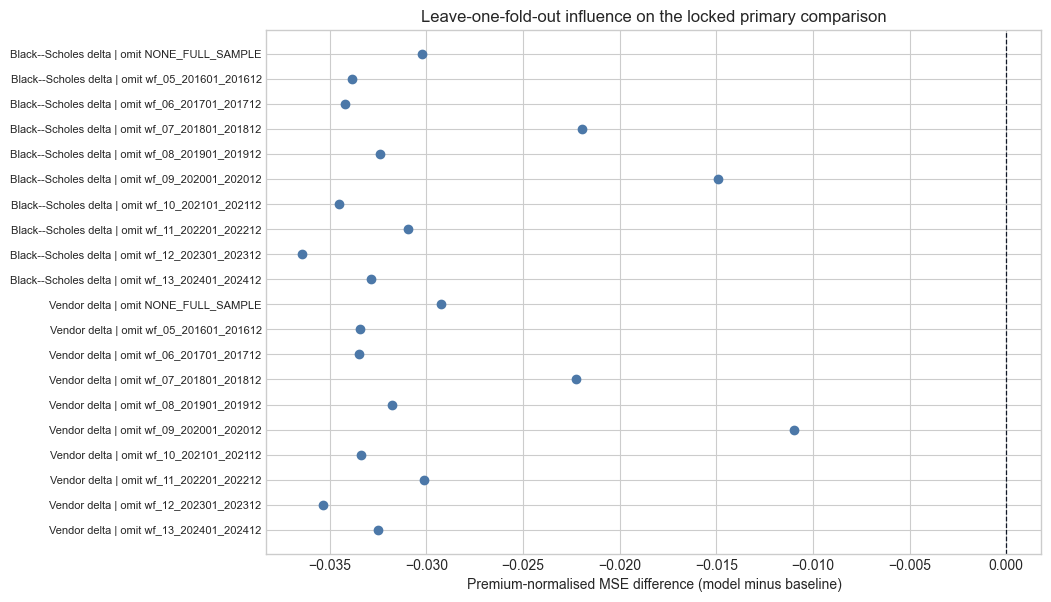

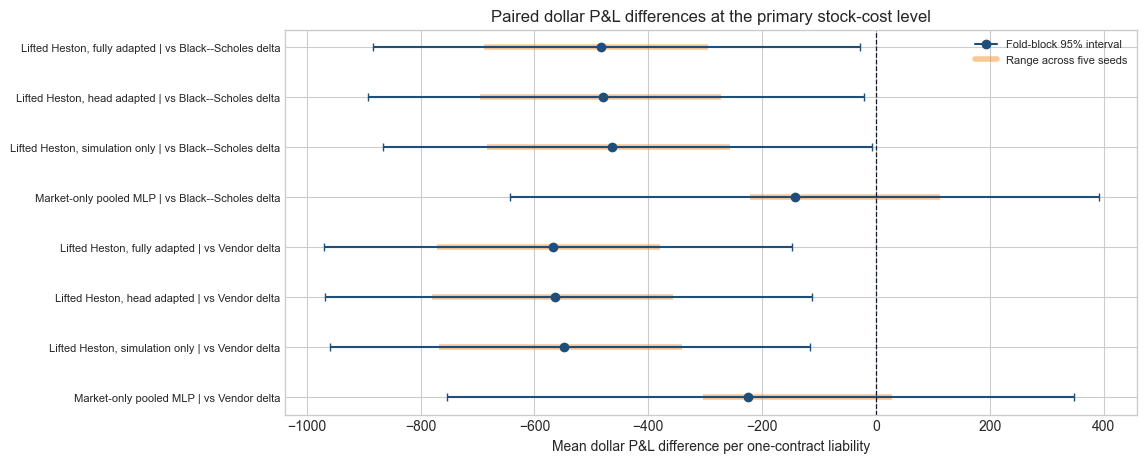

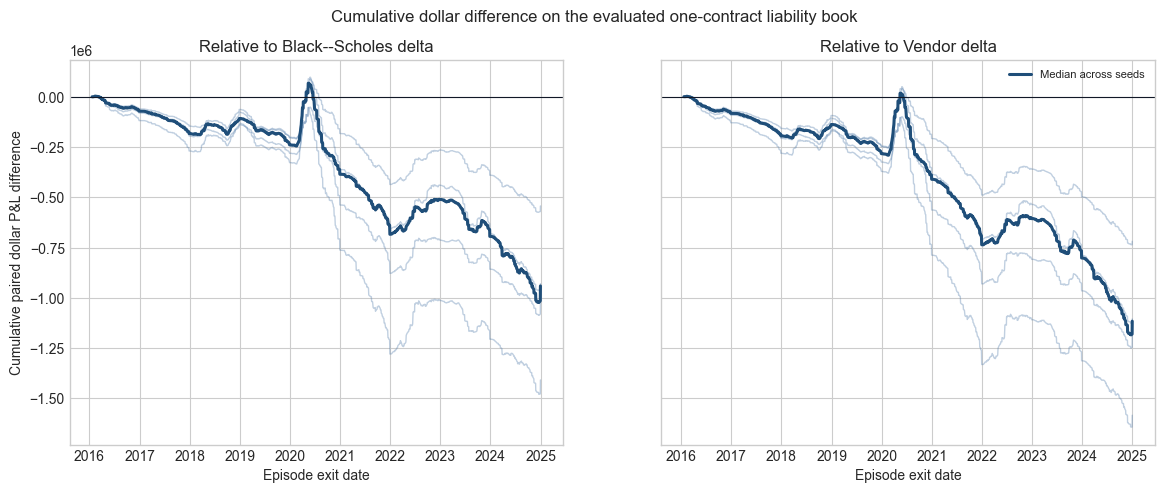

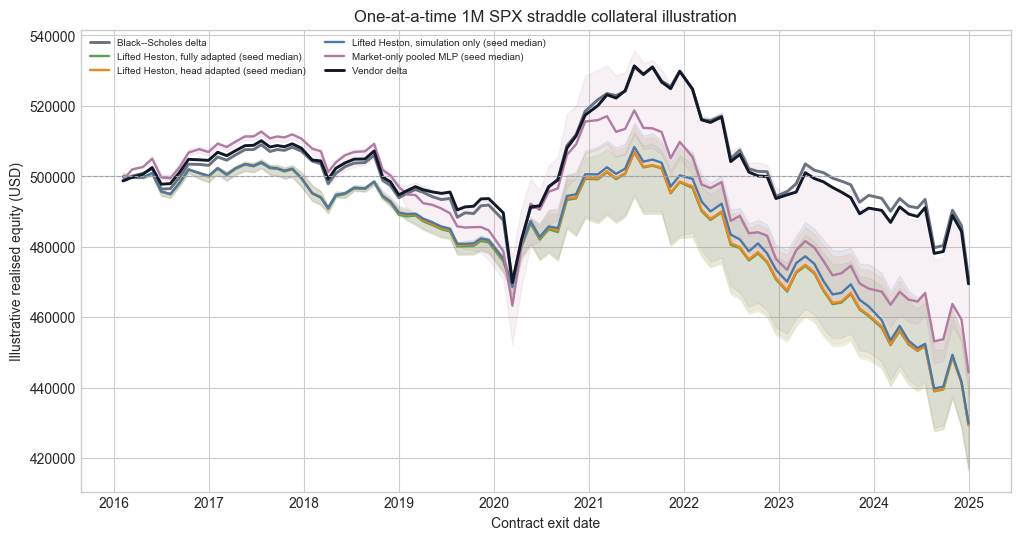

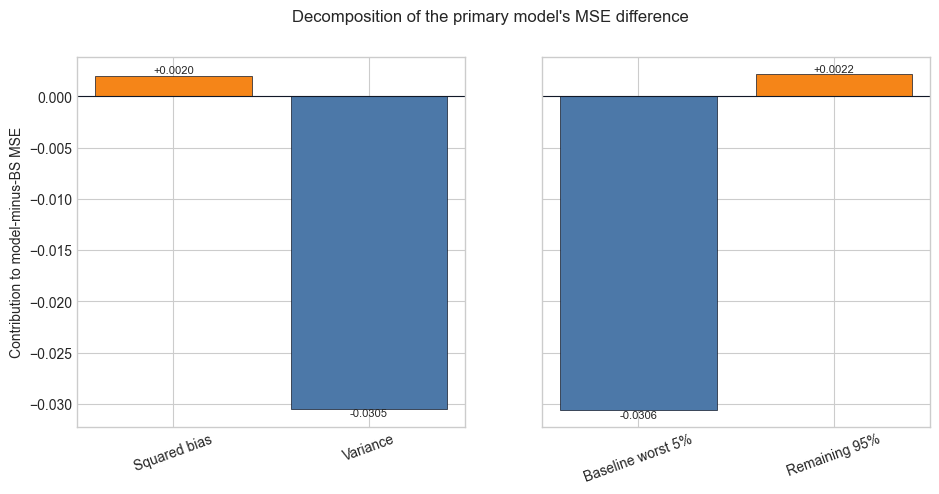

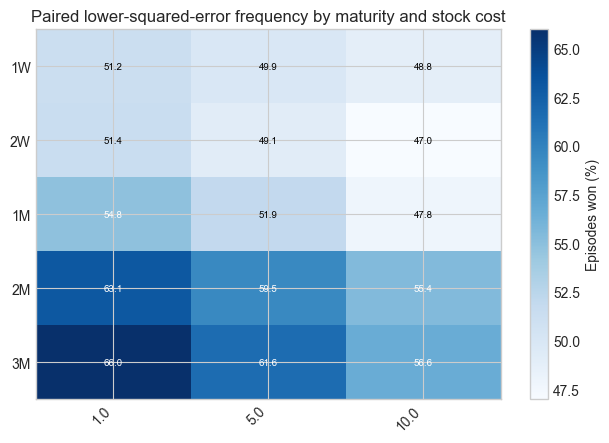

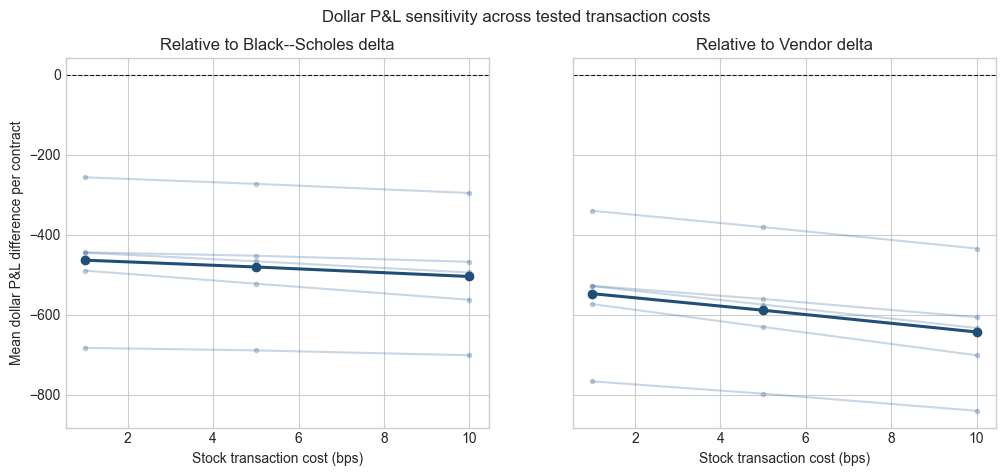

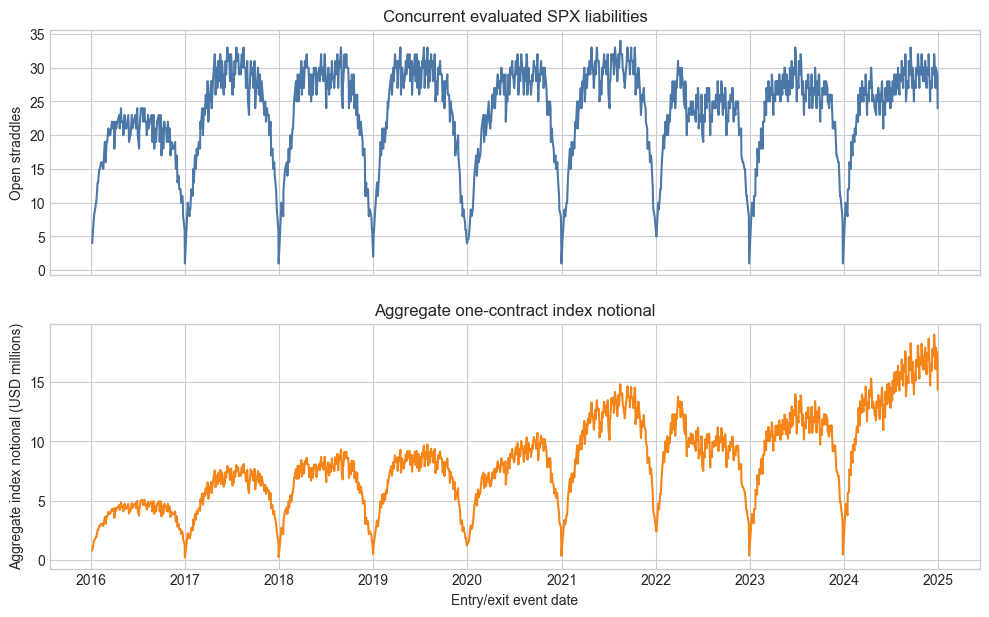

,row_level_status,primary_cost_bps,contract_multiplier,account_maturity_bucket,account_starting_collateral_usd,account_rule,margin_interpretation,post_specified,focused_model_choice_basis,retraining_performed
0,PASS,1.0,100.0,1M,500000.0,one non-overlapping 1M straddle at a time; rea...,Illustrative fixed collateral only; actual bro...,True,locked leading all-bucket point estimate; post...,False


In [31]:
# Leave-one-fold-out influence is always available from locked summaries.
influence_plot = LEAVE_ONE_FOLD_OUT_INFLUENCE.loc[
    LEAVE_ONE_FOLD_OUT_INFLUENCE.model_cell.eq(
        ECONOMIC_PRIMARY_MODEL_CELL
    )
].copy()
influence_plot["label"] = (
    influence_plot.baseline_cell.map(ECONOMIC_DISPLAY_NAMES)
    + " | omit "
    + influence_plot.omitted_fold
)
fig, ax = plt.subplots(figsize=(10, max(5, 0.34 * len(influence_plot))))
y = np.arange(len(influence_plot))
ax.scatter(
    influence_plot.mse_difference_model_minus_baseline,
    y,
    color="#4C78A8",
)
ax.axvline(0, color="#111827", linestyle="--", linewidth=0.9)
ax.set_yticks(y)
ax.set_yticklabels(influence_plot.label, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Premium-normalised MSE difference (model minus baseline)")
ax.set_title("Leave-one-fold-out influence on the locked primary comparison")
save_figure(
    fig,
    "leave_one_fold_out_influence.png",
    "Full-sample and leave-one-forward-fold-out MSE differences; negative values favour the model.",
)

if ECONOMIC_ROW_DIAGNOSTICS_READY:
    # Paired dollar effect with fold-block uncertainty and seed range.
    dollar_plot = PAIRED_DOLLAR_SUMMARY.sort_values([
        "baseline_cell", "fold_equal_mean_dollar_difference"
    ]).reset_index(drop=True)
    labels = (
        dollar_plot.model_cell.map(ECONOMIC_DISPLAY_NAMES)
        + " | vs "
        + dollar_plot.baseline_cell.map(ECONOMIC_DISPLAY_NAMES)
    )
    points = dollar_plot.fold_equal_mean_dollar_difference.to_numpy(float)
    low = dollar_plot.fold_block_ci_2_5pct.to_numpy(float)
    high = dollar_plot.fold_block_ci_97_5pct.to_numpy(float)
    seed_low = dollar_plot.minimum_seed_mean_dollar_difference.to_numpy(float)
    seed_high = dollar_plot.maximum_seed_mean_dollar_difference.to_numpy(float)
    y = np.arange(len(dollar_plot))
    fig, ax = plt.subplots(figsize=(11, max(5, 0.52 * len(dollar_plot))))
    ax.hlines(y, seed_low, seed_high, color="#F58518", linewidth=4, alpha=0.45)
    ax.errorbar(
        points,
        y,
        xerr=np.vstack([points - low, high - points]),
        fmt="o",
        color="#1F4E79",
        ecolor="#1F4E79",
        capsize=3,
        label="Fold-block 95% interval",
    )
    ax.axvline(0, color="#111827", linestyle="--", linewidth=0.9)
    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("Mean dollar P&L difference per one-contract liability")
    ax.set_title("Paired dollar P&L differences at the primary stock-cost level")
    ax.legend(
        handles=[
            plt.Line2D([], [], color="#1F4E79", marker="o", label="Fold-block 95% interval"),
            plt.Line2D([], [], color="#F58518", linewidth=4, alpha=0.45, label="Range across five seeds"),
        ],
        frameon=False,
        fontsize=8,
    )
    save_figure(
        fig,
        "paired_dollar_pnl_difference.png",
        "Paired one-contract dollar P&L difference; positive values favour the model. Intervals resample forward folds.",
    )

    # Cumulative difference for the same evaluated one-contract liability book.
    fig, axes = plt.subplots(
        1, len(ECONOMIC_BASELINE_CELLS), figsize=(14, 5), sharey=True
    )
    axes = np.atleast_1d(axes)
    for axis, baseline_cell in zip(axes, ECONOMIC_BASELINE_CELLS):
        rows = CUMULATIVE_PAIRED_DOLLAR_PATHS.loc[
            CUMULATIVE_PAIRED_DOLLAR_PATHS.baseline_cell.eq(baseline_cell)
        ]
        for training_seed, group in rows.groupby("training_seed"):
            ordered = group.sort_values("exit_date")
            axis.plot(
                ordered.exit_date,
                ordered.cumulative_dollar_difference,
                color="#4C78A8",
                alpha=0.35,
                linewidth=1,
            )
        median_path = (
            rows.groupby("exit_date", as_index=False)
            .cumulative_dollar_difference.median()
            .sort_values("exit_date")
        )
        axis.plot(
            median_path.exit_date,
            median_path.cumulative_dollar_difference,
            color="#1F4E79",
            linewidth=2.2,
            label="Median across seeds",
        )
        axis.axhline(0, color="#111827", linewidth=0.8)
        axis.set_title(
            f"Relative to {ECONOMIC_DISPLAY_NAMES[baseline_cell]}"
        )
        axis.set_xlabel("Episode exit date")
    axes[0].set_ylabel("Cumulative paired dollar P&L difference")
    axes[-1].legend(frameon=False, fontsize=8)
    fig.suptitle(
        "Cumulative dollar difference on the evaluated one-contract liability book"
    )
    save_figure(
        fig,
        "cumulative_paired_dollar_difference.png",
        "Each thin line is one fitted seed. This is a liability-book difference, not funded account equity.",
    )

    # Realised-at-exit collateral illustration.
    fig, ax = plt.subplots(figsize=(12, 6))
    account_colors = {
        "black_scholes_delta": "#6B7280",
        "vendor_delta": "#111827",
        "lifted_heston__pooled__sim_only": "#4C78A8",
        "lifted_heston__pooled__head_only": "#F58518",
        "lifted_heston__pooled__full": "#54A24B",
        "market_only__pooled": "#B279A2",
    }
    for model_cell, group in ACCOUNT_PATHS.groupby("account_policy"):
        pivot = group.pivot_table(
            index="exit_date",
            columns="account_training_seed",
            values="illustrative_equity_usd",
            aggfunc="last",
        ).sort_index()
        color = account_colors[model_cell]
        if model_cell in ECONOMIC_BASELINE_CELLS:
            ax.plot(
                pivot.index,
                pivot.iloc[:, 0],
                color=color,
                linewidth=2.1,
                label=ECONOMIC_DISPLAY_NAMES[model_cell],
            )
        else:
            ax.fill_between(
                pivot.index,
                pivot.min(axis=1),
                pivot.max(axis=1),
                color=color,
                alpha=0.10,
            )
            ax.plot(
                pivot.index,
                pivot.median(axis=1),
                color=color,
                linewidth=1.7,
                label=f"{ECONOMIC_DISPLAY_NAMES[model_cell]} (seed median)",
            )
    ax.axhline(
        ACCOUNT_STARTING_COLLATERAL_USD,
        color="#9CA3AF",
        linestyle="--",
        linewidth=0.8,
    )
    ax.set_xlabel("Contract exit date")
    ax.set_ylabel("Illustrative realised equity (USD)")
    ax.set_title(
        "One-at-a-time 1M SPX straddle collateral illustration"
    )
    ax.legend(frameon=False, fontsize=7, ncol=2)
    save_figure(
        fig,
        "one_contract_1m_collateral_illustration.png",
        "One non-overlapping 1M straddle at a time, fixed illustrative collateral, terminal P&L booked at exit; not broker margin or daily marked-to-market equity.",
    )

    # Why MSE changed: bias/variance and tail/central decompositions.
    decomposition_plot = MSE_GAIN_DECOMPOSITION.loc[
        MSE_GAIN_DECOMPOSITION.model_cell.eq(ECONOMIC_PRIMARY_MODEL_CELL)
        & MSE_GAIN_DECOMPOSITION.baseline_cell.eq("black_scholes_delta")
    ].iloc[0]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
    decomposition_sets = [
        (
            ["Squared bias", "Variance"],
            [
                decomposition_plot.delta_bias_squared,
                decomposition_plot.delta_variance,
            ],
        ),
        (
            ["Baseline worst 5%", "Remaining 95%"],
            [
                decomposition_plot.baseline_worst_5pct_contribution,
                decomposition_plot.remaining_95pct_contribution,
            ],
        ),
    ]
    for axis, (labels, values) in zip(axes, decomposition_sets):
        colors = ["#4C78A8" if value < 0 else "#F58518" for value in values]
        axis.bar(labels, values, color=colors, edgecolor="#111827", linewidth=0.5)
        axis.axhline(0, color="#111827", linewidth=0.8)
        axis.tick_params(axis="x", rotation=20)
        for position, value in enumerate(values):
            axis.text(
                position,
                value,
                f"{value:+.4f}",
                ha="center",
                va="bottom" if value >= 0 else "top",
                fontsize=8,
            )
    axes[0].set_ylabel("Contribution to model-minus-BS MSE")
    fig.suptitle("Decomposition of the primary model's MSE difference")
    save_figure(
        fig,
        "mse_difference_decomposition.png",
        "Negative components reduce MSE relative to Black-Scholes delta. Both panels reconcile to the same total difference.",
    )

    # Paired win rates show frequency rather than only average magnitude.
    win_plot = (
        PAIRED_WIN_RATE_BY_MATURITY_COST.loc[
            PAIRED_WIN_RATE_BY_MATURITY_COST.model_cell.eq(
                ECONOMIC_PRIMARY_MODEL_CELL
            )
            & PAIRED_WIN_RATE_BY_MATURITY_COST.baseline_cell.eq(
                "black_scholes_delta"
            )
        ]
        .groupby([
            "entry_maturity_bucket", "underlying_cost_bps"
        ], as_index=False)
        .agg(
            probability_lower_squared_error=(
                "probability_lower_squared_error", "mean"
            )
        )
        .pivot(
            index="entry_maturity_bucket",
            columns="underlying_cost_bps",
            values="probability_lower_squared_error",
        )
        .reindex(index=BUCKET_NAMES, columns=COST_LEVELS_BPS)
        * 100
    )
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    image, label = draw_heatmap(
        ax,
        win_plot,
        "Paired lower-squared-error frequency by maturity and stock cost",
        "Episodes won (%)",
        fmt=".1f",
        cmap="Blues",
    )
    fig.colorbar(image, ax=ax, label=label)
    save_figure(
        fig,
        "paired_win_rate_maturity_cost.png",
        "Share of matched episodes on which the locked primary model has lower squared error than Black-Scholes delta, averaged across seeds.",
    )

    # Cost sensitivity and bracketed break-even diagnostic.
    cost_plot = COST_SENSITIVITY.loc[
        COST_SENSITIVITY.model_cell.eq(ECONOMIC_PRIMARY_MODEL_CELL)
    ]
    fig, axes = plt.subplots(
        1, len(ECONOMIC_BASELINE_CELLS), figsize=(12, 4.8), sharey=True
    )
    axes = np.atleast_1d(axes)
    for axis, baseline_cell in zip(axes, ECONOMIC_BASELINE_CELLS):
        rows = cost_plot.loc[cost_plot.baseline_cell.eq(baseline_cell)]
        seed_cost = (
            rows.groupby([
                "training_seed", "underlying_cost_bps"
            ], as_index=False)
            .mean_dollar_difference.mean()
        )
        for training_seed, group in seed_cost.groupby("training_seed"):
            ordered = group.sort_values("underlying_cost_bps")
            axis.plot(
                ordered.underlying_cost_bps,
                ordered.mean_dollar_difference,
                color="#4C78A8",
                alpha=0.30,
                marker="o",
                markersize=3,
            )
        mean_cost = (
            seed_cost.groupby("underlying_cost_bps", as_index=False)
            .mean_dollar_difference.mean()
            .sort_values("underlying_cost_bps")
        )
        axis.plot(
            mean_cost.underlying_cost_bps,
            mean_cost.mean_dollar_difference,
            color="#1F4E79",
            linewidth=2.2,
            marker="o",
        )
        axis.axhline(0, color="#111827", linestyle="--", linewidth=0.8)
        axis.set_title(
            f"Relative to {ECONOMIC_DISPLAY_NAMES[baseline_cell]}"
        )
        axis.set_xlabel("Stock transaction cost (bps)")
    axes[0].set_ylabel("Mean dollar P&L difference per contract")
    fig.suptitle("Dollar P&L sensitivity across tested transaction costs")
    save_figure(
        fig,
        "dollar_cost_sensitivity.png",
        "Thin lines are fitted seeds; the heavy line is their mean. Break-even values are interpolated only when bracketed by tested costs.",
    )

    # Exposure scale of the full overlapping liability book.
    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    axes[0].plot(
        CONCURRENT_CAPITAL_LOAD.date,
        CONCURRENT_CAPITAL_LOAD.open_straddles,
        color="#4C78A8",
    )
    axes[0].set_ylabel("Open straddles")
    axes[0].set_title("Concurrent evaluated SPX liabilities")
    axes[1].plot(
        CONCURRENT_CAPITAL_LOAD.date,
        CONCURRENT_CAPITAL_LOAD.aggregate_index_notional_usd / 1_000_000,
        color="#F58518",
    )
    axes[1].set_ylabel("Aggregate index notional (USD millions)")
    axes[1].set_xlabel("Entry/exit event date")
    axes[1].set_title("Aggregate one-contract index notional")
    save_figure(
        fig,
        "concurrent_liability_capital_load.png",
        "Full-book exposure scale from one contract per evaluated liability; this is not a broker-margin estimate.",
    )

display(ECONOMIC_DIAGNOSTIC_METADATA)

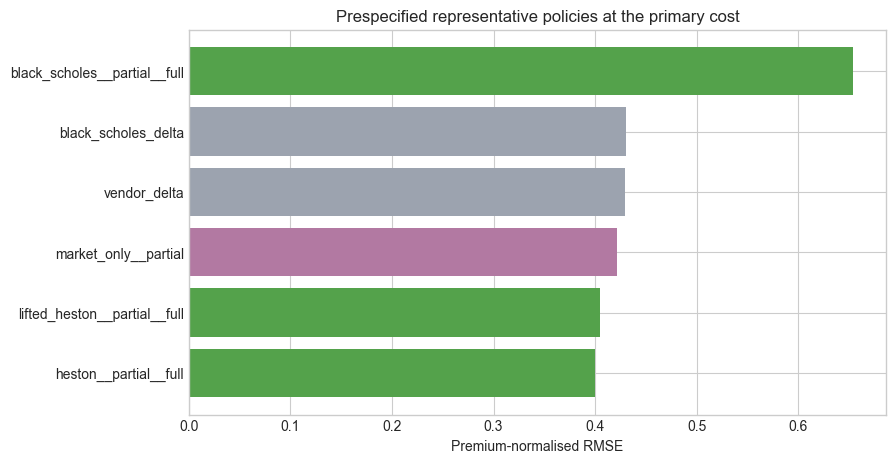

,figure,path,description
0,quote_funnel_waterfall.png,"C:\Users\lhkke\OneDrive - Queen Mary, Universi...",Rows retained at each quote-funnel stage.
1,market_episode_coverage_heatmap.png,"C:\Users\lhkke\OneDrive - Queen Mary, Universi...",Episode coverage by year and maturity bucket.
2,fold_evaluation_support_heatmap.png,"C:\Users\lhkke\OneDrive - Queen Mary, Universi...",Chronological evaluation support for every fol...
3,cohort_exclusion_heatmap.png,"C:\Users\lhkke\OneDrive - Queen Mary, Universi...",Top cohort-exclusion reasons by entry maturity.
4,source_to_market_alignment_heatmap.png,"C:\Users\lhkke\OneDrive - Queen Mary, Universi...",Pre-evaluation observable-state median gaps sc...
5,factorial_contrast_forest_plot.png,"C:\Users\lhkke\OneDrive - Queen Mary, Universi...",Paired predefined contrasts; negative values f...
6,walk_forward_family_rmse.png,"C:\Users\lhkke\OneDrive - Queen Mary, Universi...",Fold-level RMSE for adaptation families and pr...
7,maturity_cost_robustness_heatmap.png,"C:\Users\lhkke\OneDrive - Queen Mary, Universi...",Main-effect MSE improvement by checkpoint fami...
8,seed_stability_dot_plot.png,"C:\Users\lhkke\OneDrive - Queen Mary, Universi...",Each point is one optimisation seed after aver...
9,risk_turnover_frontier.png,"C:\Users\lhkke\OneDrive - Queen Mary, Universi...",All policies on matched 1M fold-maturity obser...


In [32]:
representative_headline=HEADLINE.loc[
    HEADLINE.underlying_cost_bps.eq(CONFIG.primary_cost_bps)
    & HEADLINE.model_cell.isin(REPORTING_POLICY_CELLS)
].sort_values("premium_normalised_rmse",ascending=True)
fig,ax=plt.subplots(figsize=(9,5))
colors=[
    POLICY_COLORS.get(stage,"#9CA3AF")
    for stage in representative_headline.checkpoint_stage
]
ax.barh(
    representative_headline.model_cell,
    representative_headline.premium_normalised_rmse,
    color=colors,
)
ax.set_xlabel("Premium-normalised RMSE")
ax.set_title("Prespecified representative policies at the primary cost")
save_figure(
    fig,"representative_policy_rmse.png",
    "Representative policies are specified by design, not selected by realised rank."
)

# Freeze the complete registry only after the last figure has been saved.
FIGURE_REGISTRY=pd.DataFrame(FIGURE_REGISTRY)
display(FIGURE_REGISTRY)


## Takeaways

- `auto` mode reuses matching result tables; if they are absent, every simulation, adaptation and market-only fitted state is loaded from the stable checkpoint directory before any training is attempted.
- Checkpoint signatures depend on training inputs and training code, not on charts. Reporting edits therefore do not invalidate model weights.
- The diagnostic layer prioritises chronology, sample support, optimisation uncertainty, paired inference, regime/maturity/cost robustness, tails, turnover and self-financing accounting.
- Calibration surfaces remain in the upstream calibration notebooks. The final experiment consumes their dated artefacts and audits the observable sim-to-market gap.
- The former $10,000 equity curve is not reported as a trading backtest. SPX integer-contract scale is shown explicitly, and fractional-notional results are labelled non-executable.
- In `audit` mode, rankings remain non-empirical; the relevant outcome is whether all 30 neural estimands, eight baselines, checkpoint contracts and reporting gates pass.


- The run is invalid if checkpoint identities collide, adaptation leaves the
  policy unchanged, gradients are non-finite, a policy is wholly saturated or
  clipped, zero-initialisation does not reproduce the anchor, or strict float64
  accounting fails to reconcile.
- Early maturity availability is an explicit unbalanced-panel fact. Comparisons
  remain paired within the same eligible fold and entry-maturity bucket.


- Dollar and account figures are post-specified economic-interpretation
  diagnostics. They use one standard SPX contract, preserve seeds separately,
  and never interpret a $10,000 balance or entry premium as sufficient margin.
- The non-overlapping 1M account path books terminal P&L at exit and is not a
  daily marked-to-market return series. Full-book cumulative differences are
  paired liability-book comparisons, not claims of alpha.
- Leave-one-fold-out estimates make year dependence visible; any result that
  changes materially after removing one forward fold should be described as
  fragile rather than broadly superior.

In [33]:
REPORTING_TABLES={
    "result_context_audit.csv":RESULT_CONTEXT_AUDIT,
    "economic_row_coverage_audit.csv":ECONOMIC_ROW_COVERAGE_AUDIT,
    "leave_one_fold_out_influence.csv":LEAVE_ONE_FOLD_OUT_INFLUENCE,
    "paired_dollar_seed_summary.csv":PAIRED_DOLLAR_SEED_SUMMARY,
    "paired_dollar_summary.csv":PAIRED_DOLLAR_SUMMARY,
    "mse_gain_decomposition_by_seed.csv":MSE_GAIN_DECOMPOSITION_BY_SEED,
    "mse_gain_decomposition.csv":MSE_GAIN_DECOMPOSITION,
    "paired_win_rate_by_maturity_cost.csv":PAIRED_WIN_RATE_BY_MATURITY_COST,
    "paired_win_rate_by_regime.csv":PAIRED_WIN_RATE_BY_REGIME,
    "cost_sensitivity.csv":COST_SENSITIVITY,
    "cost_break_even_diagnostic.csv":COST_BREAK_EVEN_DIAGNOSTIC,
    "cumulative_paired_dollar_paths.csv":CUMULATIVE_PAIRED_DOLLAR_PATHS,
    "account_trade_schedule.csv":ACCOUNT_TRADE_SCHEDULE,
    "account_paths.csv":ACCOUNT_PATHS,
    "account_summary.csv":ACCOUNT_SUMMARY,
    "account_policy_summary.csv":ACCOUNT_POLICY_SUMMARY,
    "account_collateral_sensitivity.csv":ACCOUNT_COLLATERAL_SENSITIVITY,
    "concurrent_capital_load.csv":CONCURRENT_CAPITAL_LOAD,
    "capital_load_summary.csv":CAPITAL_LOAD_SUMMARY,
    "economic_diagnostic_metadata.csv":ECONOMIC_DIAGNOSTIC_METADATA,
    "diagnostic_inventory.csv":LEGACY_DIAGNOSTIC_INVENTORY,
    "episode_characteristics.csv":EPISODE_CHARACTERISTICS,
    "coverage_by_year_bucket.csv":COVERAGE_BY_YEAR_BUCKET,
    "exclusion_summary.csv":EXCLUSION_SUMMARY,
    "rate_age_summary.csv":RATE_AGE_SUMMARY,
    "source_alignment.csv":SOURCE_ALIGNMENT,
    "checkpoint_cache_audit.csv":CHECKPOINT_CACHE_AUDIT,
    "checkpoint_state_audit.csv":CHECKPOINT_STATE_AUDIT,
    "checkpoint_comparison_audit.csv":CHECKPOINT_COMPARISON_AUDIT,
    "policy_diagnostics.csv":POLICY_DIAGNOSTICS,
    "zero_initialisation_audit.csv":ZERO_INITIALISATION_AUDIT,
    "strict_accounting_audit.csv":STRICT_ACCOUNTING_AUDIT,
    "training_history_summary.csv":TRAINING_HISTORY_SUMMARY,
    "training_history_coverage.csv":TRAINING_HISTORY_COVERAGE,
    "training_resource_summary.csv":TRAINING_RESOURCE_SUMMARY,
    "runtime_audit.csv":RUNTIME_AUDIT,

    "runtime_equivalence_audit.csv":RUNTIME_EQUIVALENCE_AUDIT,
    "task_runtime_equivalence_audit.csv":TASK_RUNTIME_EQUIVALENCE_AUDIT,
    "runtime_data_cache_audit.csv":RUNTIME_DATA_CACHE_AUDIT,

    "fold_execution_status.csv":FOLD_EXECUTION_STATUS,

    "analytic_cache_events.csv":pd.DataFrame(ANALYTIC_CACHE_EVENTS),
    "regime_thresholds.csv":REGIME_THRESHOLDS,
    "regime_results.csv":REGIME_RESULTS,
    "regime_family_results.csv":REGIME_FAMILY_RESULTS,
    "regime_relative_to_bs.csv":REGIME_RELATIVE_TO_BS,
    "walk_forward_family.csv":WALK_FORWARD_FAMILY,
    "maturity_cost_robustness.csv":MATURITY_COST_ROBUSTNESS,
    "seed_family_results.csv":SEED_FAMILY_RESULTS,
    "accounting_decomposition.csv":ACCOUNTING_DECOMPOSITION,
    "capital_scale_diagnostic.csv":CAPITAL_SCALE_DIAGNOSTIC,
    "loss_exceedance.csv":LOSS_EXCEEDANCE,
    "no_trade_boundary_audit.csv":NO_TRADE_BOUNDARY_AUDIT,
    "figure_registry.csv":FIGURE_REGISTRY,
}
for filename,table in REPORTING_TABLES.items():
    table.to_csv(CONFIG.paths.output/filename,index=False)

QUOTE_FUNNEL.to_csv(
    CONFIG.paths.output/"quote_funnel.csv",index=False
)
COHORT_EXCLUSIONS.to_csv(
    CONFIG.paths.output/"cohort_exclusions.csv",index=False
)
EPISODE_AUDIT.to_csv(
    CONFIG.paths.output/"episode_audit.csv",index=False
)
SIMULATION_INVENTORY.to_csv(
    CONFIG.paths.output/"simulation_inventory.csv",index=False
)
LIFTED_NUMERICAL_AUDIT.to_csv(
    CONFIG.paths.output/"lifted_delta_numerical_audit.csv",index=False
)
RESULT_AUDIT.to_csv(
    CONFIG.paths.output/"result_audit.csv",index=False
)

run_manifest={
    "protocol":PROTOCOL_VERSION,
    "training_protocol":TRAINING_PROTOCOL_VERSION,
    "evaluation_protocol":EVALUATION_PROTOCOL_VERSION,
    "reporting_version":REPORTING_VERSION,
    "result_signature":RESULT_SIGNATURE,
    "run_mode":RUN_MODE,
    "results_reused":RESULTS_REUSED,
    "profile":CONFIG.profile,
    "config":asdict(CONFIG),
    "feature_names":FEATURE_NAMES,
    "grid":{
        "simulation_sources":SIMULATION_SOURCES,
        "pooling":POOLING_DESIGNS,
        "simulation_checkpoints":CHECKPOINTS,
        "market_only_checkpoint":MARKET_ONLY_CHECKPOINT,
        "simulation_based_cells":27,
        "market_only_cells":3,
        "total_neural_cells":30,
    },
    "checkpoint_contract":{
        "stable_directory":str(CONFIG.paths.checkpoint_dir),
        "manifest_rows":len(CHECKPOINT_MANIFEST),
        "force_retrain":CONFIG.force_retrain,
        "reporting_changes_invalidate_training":False,
    },
    "performance_contract":{
        "simulation_batch_size":CONFIG.training.simulation_batch_size,
        "market_batch_size":CONFIG.training.market_batch_size,
        "gpu_resident_fit_tensors":DEVICE.type=="cuda",
        "differentiable_accounting_dtype":"float32",
        "authoritative_evaluation_dtype":"float64",
        "validation_roundtrip_to_cpu":False,
        "per_batch_loss_synchronisation":False,
        "minimum_market_optimizer_steps":CONFIG.training.minimum_market_optimizer_steps,

        "zero_initialised_residual_heads":True,

        "separate_fit_workers":SEPARATE_FIT_WORKERS,
        "task_fit_workers":TASK_FIT_WORKERS,
        "task_inner_separate_fit_workers":TASK_INNER_SEPARATE_FIT_WORKERS,
        "task_parallel_equivalence":TASK_RUNTIME_EQUIVALENCE_AUDIT.to_dict("records"),
        "fold_device_tensor_cache":RUNTIME_DATA_CACHE_AUDIT.to_dict("records"),

        "concurrent_separate_fit_equivalence":RUNTIME_EQUIVALENCE_AUDIT.to_dict("records"),

        "cost_stacked_inference":True,

        "persistent_analytic_delta_cache":True,

        "planned_individual_model_fits":int(

            len(SIMULATION_SOURCES)*len(CONFIG.seeds)*

            sum(estimator_branches(pooling,len(BUCKET_NAMES))

                for pooling in POOLING_DESIGNS)

            +FOLD_EXECUTION_STATUS.planned_total_fits.sum()

        ),

    },
    "diagnostics":{
        "inventory_rows":len(LEGACY_DIAGNOSTIC_INVENTORY),
        "checkpoint_state_rows":len(CHECKPOINT_STATE_AUDIT),
        "checkpoint_comparison_rows":len(CHECKPOINT_COMPARISON_AUDIT),
        "policy_diagnostic_rows":len(POLICY_DIAGNOSTICS),
        "strict_float64_accounting":True,
        "figures":FIGURE_REGISTRY.to_dict("records"),
    },
    "audit_gate_summary":{
        "failed_total":int(RESULT_AUDIT.status.ne("PASS").sum()),
        "failed_learning_diagnostics":RESULT_AUDIT.loc[
            RESULT_AUDIT.status.ne("PASS")
            & RESULT_AUDIT.gate_class.eq("LEARNING_DIAGNOSTIC"),"gate"
        ].tolist(),
        "failed_validity_critical":RESULT_AUDIT.loc[
            RESULT_AUDIT.status.ne("PASS")
            & RESULT_AUDIT.gate_class.eq("VALIDITY_CRITICAL"),"gate"
        ].tolist(),
    },
    "economic_diagnostics":{
        "row_level_status":ECONOMIC_DIAGNOSTIC_METADATA.row_level_status.iloc[0],
        "post_specified":True,
        "retraining_performed":False,
        "baseline_cells":ECONOMIC_BASELINE_CELLS,
        "model_cells":ECONOMIC_MODEL_CELLS,
        "primary_model_cell":ECONOMIC_PRIMARY_MODEL_CELL,
        "focused_model_choice_basis":ECONOMIC_DIAGNOSTIC_METADATA.focused_model_choice_basis.iloc[0],
        "account_maturity_bucket":ACCOUNT_MATURITY_BUCKET,
        "account_starting_collateral_usd":ACCOUNT_STARTING_COLLATERAL_USD,
        "account_rule":ECONOMIC_DIAGNOSTIC_METADATA.account_rule.iloc[0],
        "margin_interpretation":ECONOMIC_DIAGNOSTIC_METADATA.margin_interpretation.iloc[0],
    },
    "walk_forward_contract":{
        "training_months":CONFIG.training_months,
        "evaluation_months":CONFIG.evaluation_months,
        "fold_admission_rule":"all five buckets meet every frozen threshold",
        "executed_folds":int(
            FOLD_EXECUTION_STATUS.fold_status.eq("ELIGIBLE_ALL_BUCKETS").sum()
        ),
        "scheduled_folds":len(FOLDS),
    },
    "separate_policy_contract":{
        "buckets":SEPARATE_POLICY_BUCKETS,
        "estimators":1,"scalers":1,"optimisers":1,
        "validation_losses":1,"epoch_budgets":1,
        "pooling_comparison_scope":"matched 1M observations only",
    },
    "interpretation":(
        "NON_EMPIRICAL_AUDIT_FIXTURE"
        if CONFIG.profile=="audit"
        else "EMPIRICAL_FORWARD_CLOSE_TO_CLOSE"
    ),
}
with open(
    CONFIG.paths.output/"run_manifest.json","w"
) as handle:
    json.dump(run_manifest,handle,indent=2,default=str)

print({
    "status":"PASS","profile":CONFIG.profile,
    "output":str(CONFIG.paths.output),
    "neural_cells":len(observed_neural),
    "market_only_cells":len(observed_market_only),
    "baseline_cells":len(observed_baselines),
})


{'status': 'PASS', 'profile': 'full', 'output': 'C:\\Users\\lhkke\\OneDrive - Queen Mary, University of London\\Documents\\Dissertation\\Deep-Hedging-under-Lifted-Heston-MSc-Dissertation-\\outputs_final_factorial\\full', 'neural_cells': 30, 'market_only_cells': 3, 'baseline_cells': 8}
